# ТВД 110 кВт: новая предварительная конструкция на 2000 часов

По сравнению с прежней компоновкой снижена частота и увеличен наружный диаметр. Диапазон ресурсного поиска расширен до 15 000…50 000 об/мин и Dк=0,16…0,45 м; геометрические, газодинамические и прочностные условия приёмки не ослаблены. Предварительная проверка прежней компоновки дала nдл≈0,913<1,2 при 2000 ч; исходный вариант сохранён отдельно в v8.

# ТВД 110 кВт: один ЦБК и одна двухступенчатая осевая турбина, Dк = const

**Редакция v15: локальный выбор целых Z по книжному шагу, реальные проверки кандидатов, неохлаждаемая турбина и ресурсное согласование на 2000 ч. Рисуются только три сечения последней ступени.**

Одновальная схема, два последовательных РК, общая частота и постоянный наружный диаметр сохранены. Расход воздуха решается по заданной **мощности вала после редуктора**, площадь выпуска — по противодавлению. **Предмет подробного расчёта — только турбина. ЦБК учитывается исключительно в цикле через πк, ηк.п, температуру и работу сжатия; проектирование ЦБК и его карта в задание не входят.**

**Источники:** В. Е. Михальцев, В. Д. Моляков, *Теория и проектирование газовой турбины*, ч. 1, 2006; те же авторы, *Расчёт параметров цикла при проектировании газотурбинных двигателей и комбинированных установок*, 2014.

Страницы ниже — печатные. Для книги 2006 года лист PDF = страница + 1; для пособия 2014 года номера совпадают.

### Изменения после аудита

1. Весь расчёт использует опубликованную **истинную** `cp_i(T, α)` из приложения 6 (2014, с. 57). `h` и интеграл `cp/T` получены из неё аналитически, с разделением при 750 К. Производная средней теплоёмкости больше не используется как истинная.
2. Отсчёт энтальпий — 288 К; температура топлива принята равной этой температуре. Приняты табличные `Qн = 43 000 кДж/кг`, `l0 = 14,61` для керосина. Это явное изменение исходных данных; прежние 43 150 кДж/кг лежат в диапазоне с. 8 и сами по себе ошибкой не являлись.
3. Охлаждающие отборы на диски и лопатки и возврат воздуха исключены по требованию пользователя. Сохраняется только невозвратная утечка 0,75%; состав и расход газа между ступенями неизменны. Тг*=1250 K.
4. Кромка РК **2** и сечение после смешения дополнительных потерь **2+** разделены. У каждого своя температура, плотность и площадь при том же Dк. Все проверки энергии и неразрывности относятся к явно названным сечениям.
5. Книжная модель ступени обобщена на переменные свойства: изоэнтропы и перепады определяются интегралами. Это математическое обобщение приближённой методики, а не дословная формула книги и не новый экспериментальный закон потерь.
6. Предел зазора изменён с 0,2 до **0,5 мм** как предварительный выбор нижнего ориентира для малой турбины (2006, с. 63). Реальный горячий зазор не рассчитан; 0,2 и 0,7 мм оставлены сценариями чувствительности.
7. Радиальная диагностика использует единую модель с переменными T и cp; изотермическая экспонента удалена. Разные законы профилирования показываются отдельно.
8. Исправлены единицы напряжений (**МПа**), входное давление ЦБК, устаревшие условия Dвт=const и описания «фиксированной геометрии» при перерасчёте высот.
9. Успешность уравнений отделена от проектных ориентиров и от подтверждения материала, тепловой пригодности неохлаждаемого узла и потерь профилей. Условия не ослаблены для получения «всё прошло».
10. Исторические исполняемые ветки v5/v6 и противоречащие им сводки заменены единой веткой. Старые числа приведены только в явно подписанном сравнении в конце.

Для запуска нужны Python 3.10+, NumPy ≥2, SciPy, pandas, Matplotlib и IPython/Jupyter. Ноутбук автономен: не читает расчётные модули или данные из рабочей папки. Run All рассчитывает стартовые ширины через высоту, сравнивает соседние целые Z и при необходимости пересогласовывает компоновку по ресурсу. Результаты конечного перебора не объявляются глобальным оптимумом.

**Дополнение v10:** плотность, предварительный ориентир напряжений, книжное сужение, зазор и толщины связаны с реестром BOOK_DEFAULTS; фактическая конусность основного пера задаётся отдельно в LOSS_MODEL. Ресурс 2000 ч задан пользователем. Для нового конструктивного варианта выбран литой IN-738C по INCO 497; температура металла ограничивается сверху относительной температурой торможения, а не назначается для прохождения проверки. Значения из книги не объявляются подтверждёнными характеристиками материала. См. начальный реестр и раздел 31.


## План расчёта v15 и границы завершённости

План выполняется последовательно; ниже отражён достигнутый уровень, а не обещание готового двигателя.

| Этап | Что сделано | Что ещё требуется |
|---|---|---|
| 1. Число ступеней | Формула п.54 сверена по скану; рассчитаны диапазон y0 и варианты 1/2/3 ступени | Сравнение полностью оптимизированных разных схем; глобальный оптимум не установлен |
| 2. Подбор двух ступеней | Выполнен локальный SLSQP по геометрии, расходу и двум реактивностям; сохранён протокол; найденная точка повторно рассчитана | Локальный перебор Z и ресурсное согласование выполняются ниже; глобальный оптимум не установлен |
| 3. Цикл и ТВД | ЦБК — только работа и параметры сжатия в цикле; варианты πк=3…8 | Проектирование компрессора не входит в задание |
| 4. Меридиональный канал | Разделены входы/выходы СА и РК, ширины и свободные зазоры; сечения 2+ находятся вне венцов | Реальные переходные потери и прочностное обоснование выбранных ширин |
| 5. Радиальный расчёт | Расходы замкнуты интегралами, построено отображение массовых линий тока; 5 сечений на ступень, оба треугольника | Полностью совместная вязкая модель; приближённая обратная передача потерь уже реализована |
| 6. Профили четырёх венцов | Кубические поверхности по касательным; пять сечений рассчитываются для всех венцов, рисуются только СА/РК последней ступени | Нарушения геометрических ориентиров выводятся явно; потери, технология и прочность требуют подтверждения |
| 7. Потери | Итерационно уточняются φ/ψ по трению, кромочным и концевым потерям | Калибровка приближённой модели трения и вязкости по реальному газу/решёткам |
| 8. Прочность и зазор | Основное перо сужается; пять сечений трапециями, уточнение по трём; изгиб и предварительный Ларсон—Миллер | Температурное поле, аттестованные данные материала/ресурса, диск, замок, усталость и ползучие деформации не подтверждены |
| 9. Воспроизводимость | Все определения внутри ipynb, протокол подбора, проверки и сохранённые результаты | Повторная верификация после назначения недостающих данных |

Две ступени сохранены как требование исходной схемы. Вариантное сравнение не подменяет её трёхступенчатой турбиной. Полноценный расчёт материала и ресурса невозможно получить из имеющихся входных данных; неизвестные значения не заменены вымышленными.


## 0. Исходные параметры и их статус

`Config` — неизменяемый набор исходных данных. Для сценария используется `replace(C, ...)`: состояние базового расчёта не меняется. Семь параметров компоновки и две реактивности подобраны локальным SLSQP с запасом по выбранным условиям. Расход затем независимо решается корневым методом. Протокол и воспроизводимая функция подбора приведены в разделе 29.

По требованию пользователя: **Тг*=1250 K, ресурс 2000 ч, диски и лопатки без охлаждения**. Отбор на продувку дисков и возврат удалены из модели. Только невозвратная утечка 0,75%; газовый расход и состав между ступенями не изменяются. Тепловая пригодность неохлаждаемого узла не считается доказанной одним заданием схемы.

Газовая постоянная 287,4 Дж/(кг·К) принята одинаковой для воздуха и продуктов сгорания — отдельное приближение. Механический КПД применяется к мощности турбины; КПД редуктора — к полезной разности мощностей.

In [1]:
import math
from dataclasses import dataclass, replace, asdict
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq, root, differential_evolution
from scipy.integrate import quad
from IPython.display import display

@dataclass(frozen=True)
class Config:
    target_W: float = 110000.
    pi_k: float = 5.
    Ta: float = 288.
    pa: float = 101300.
    Tg: float = 1250.
    R: float = 287.4  # единая постоянная — явно принятое приближение
    eta_pc: float = .85
    eta_burn: float = .98
    eta_mech: float = .99
    eta_gear: float = .98
    sigma_in: float = .98
    sigma_burn: float = .96
    sigma_exhaust: float = .99
    Q_LHV: float = 43000000.  # Дж/кг, 2014, табл. 2, с. 21
    l0: float = 14.61
    Tref: float = 288.  # температура определения Q; T топлива принято = Tref
    g_leak: float = .0075
    phi: tuple[float, float] = (.97,.97)
    psi: tuple[float, float] = (.96,.96)
    mu: float = .90
    sigma_mix: float = .995
    delta_rel: float = .007
    delta_min: float = .0005  # выбран нижний ориентир для малых турбин; не тепловой расчёт
    epsilon: float = 1.
    Kn: float = 6.8e-6  # МПа / [(об/мин)^2 м²], 2006, с. 55–57
    sigma_project_MPa: float = 200.  # 2006 с.57 / 2014 с.49: верх обычного предварительного интервала
    pback_ratio: float = 1.05
    phi_nozzle: float = .95
    flight_speed: float = 0.
    rho_stage1: float | None = None
    rho_stage2: float | None = None
    @property
    def air_burn(self): return 1-self.g_leak
    def validate(self):
        if not (0<=self.g_leak<1 and self.air_burn>0):
            raise ValueError('Некорректная невозвратная утечка')
        if not (self.Q_LHV>0 and self.l0>0 and self.R>0 and self.target_W>0):
            raise ValueError('Некорректные энергетические исходные данные')
        for rho in (self.rho_stage1,self.rho_stage2):
            if rho is not None and not 0<rho<1:raise ValueError('Реактивность должна лежать между 0 и 1')
        for key in ['eta_pc','eta_burn','eta_mech','eta_gear','sigma_in','sigma_burn','sigma_exhaust','mu','sigma_mix','phi_nozzle','epsilon']:
            if not 0<getattr(self,key)<=1: raise ValueError(key)
        for values in (self.phi,self.psi):
            if len(values)!=2 or not all(0<v<=1 for v in values):raise ValueError('Нужны два коэффициента скорости, по одному на ступень')
        if not (200<self.Tref<400 and self.Tg>self.Ta>200 and self.pa>0 and self.pi_k>1 and self.pback_ratio>1 and self.delta_min>0):
            raise ValueError('Некорректные температуры, давления или зазор')

C=Config(rho_stage1=0.25,rho_stage2=0.25854074709840286,phi=(0.9060660832358686, 0.9302944725368163),psi=(0.9182082876870896, 0.9460101316882826))
# Начальное приближение v15 из согласованного расчёта с действительными контурами.
# Run All заново сравнивает соседние Z, согласует действительные профили/потери и проверяет ресурс.
# Это предварительная расчётная компоновка, не подтверждённая конструкция.
# [n, Dк, α1_1, α1_2, κ1, κ2, q]; расход определяется заново.
GEOMETRY=np.array([33317.88724239408, 0.2079498066299615, 11.2, 16.77948774579417, 1.036671074274523, 1.0627885785567157, 0.5045623768761107])

### Предварительные исходные данные, принятые непосредственно по учебникам

Запрос пользователя: недостающие параметры для продолжения предварительного расчёта взять из двух приложенных книг. Ниже отделены **диапазон в книге**, **наш выбор внутри диапазона** и **подтверждённые свойства конкретного материала**.

Приняты: ρмат=7900 кг/м³, предварительный ориентир растяжения 200 МПа, рабочий зазор малой турбины 0,5 мм, выходная кромка 0,5 мм. Значение 200 МПа — верх обычного диапазона 120…200; оно не является гарантированным допуском сплава при 1250 К газа. Газовая температура не заменяет температуру металла.

Книжный ориентир Aкор/Aкон=3,5…4 сохранён справочно; основное перо согласуется при выбранном отношении около 1,3 без ослабления геометрических условий.

Книга 2006, с.57, прямо говорит: напряжение зависит от температуры, охлаждения, материала и ресурса и «может быть найдено по справочной литературе». На с.4 ресурс относится к техническому заданию. В пособии 2014, с.49, повторена зависимость от материала и ресурса. Поэтому конкретная марка, часы ресурса, таблица длительной прочности и технология изготовления пера из этих книг не назначаются.

В этом дополнении прежний проектный порог 300 МПа заменён обычным книжным ориентиром **200 МПа**; геометрия, φ/ψ, частота и найденная мощность не подбираются заново ради прохождения проверки. Для высокотемпературных турбин книги приводят более низкие ориентиры, показанные отдельно без автоматической классификации по одной только температуре газа.

In [2]:
BOOK_DEFAULTS={
    'density_kg_m3':7900.,'density_range_kg_m3':(7800.,8000.),
    'root_tip_area_ratio':3.5,'root_tip_area_ratio_range':(3.5,4.),
    'sigma_screening_MPa':200.,'sigma_transport_range_MPa':(120.,200.),
    'sigma_high_temperature_2006_MPa':(30.,100.),
    'sigma_high_temperature_2014_MPa':(20.,100.),
    'Kn_general':6.8e-6,
    'working_gap_m':.0005,'small_turbine_gap_range_m':(.0005,.0007),
    'honeycomb_runin_gap_m':.0002,
    'trailing_edge_m':.0005,'trailing_edge_range_m':(.0005,.0016),
    'leading_radius_over_bax':.035,
    'stator_te_over_throat':.055,'rotor_te_over_throat':.07,
    'max_thickness_stator_over_chord':.13,'max_thickness_rotor_over_chord':.11}
BOOK_SELECTION_ROWS=[
    ('Плотность материала пера','7800…8000 кг/м³',7900.,'кг/м³','2006, с.57 / PDF 58; 2014, с.49 / PDF 49','Середина интервала; марка не установлена'),
    ('Отношение площадей Aкор/Aкон','3,5…4,0',None,'—','2006, с.57,78 / PDF 58,79; 2014, с.49','Справочный ориентир; фактическое сужение основного пера около 1,3 задаётся отдельно'),
    ('Ориентир растяжения стационарных/транспортных ГТУ','120…200 МПа',200.,'МПа','2006, с.57; 2014, с.49','Предварительный верхний ориентир, не допуск материала'),
    ('Высокотемпературные турбины, книга 2006','30…100 МПа',None,'МПа','2006, с.57 / PDF 58','Другой класс условий, не назначен вместо допуска'),
    ('Высокотемпературные турбины, книга 2014','20…100 МПа',None,'МПа','2014, с.49','Сохранено различие изданий, границы не усреднены'),
    ('Общий предварительный Kn','≈6,8·10⁻⁶',6.8e-6,'МПа/[(об/мин)²·м²]','2006, с.55–56; 2014, с.48','Прямой книжный ориентир для плавно меняющегося сечения'),
    ('Рабочий зазор малой турбины','0,5…0,7 мм',.5,'мм','2006, с.63 / PDF 64','Нижняя граница; тепловой расчёт не выполнен'),
    ('Зазор после приработки сотовой вставки','0,2 мм и меньше',.2,'мм','2006, с.12 / PDF 13','Отдельная конструктивная альтернатива; не исходный холодный зазор'),
    ('Толщина выходной кромки','0,5…1,6 мм',.5,'мм','2006, с.80 / PDF 81','Нижний ориентир для малой мощности, не гарантия технологии'),
    ('Радиус носка','(0,03…0,04)bax',.035,'доля bax','2006, с.80 / PDF 81','Выбран внутри интервала'),
    ('s2/a неохлаждаемого СА','0,055',.055,'—','2006, с.80 / PDF 81','Геометрический ориентир для принятой неохлаждаемой схемы'),
    ('s2/a неохлаждаемого РК','0,07',.07,'—','2006, с.80 / PDF 81','Геометрический ориентир; не должен скрывать слишком толстую кромку'),
    ('Максимальная относительная толщина СА/РК','0,13 / 0,11',None,'доля хорды','2006, с.82 / PDF 83','Принято в черновом профилировании'),
    ('Конкретная марка сплава','не назначена для нашего пера',None,'—','2006, с.57; 2014, с.49','Отсылают к свойствам материала, не содержат выбора марки для данного проекта'),
    ('Требуемый ресурс','задаётся техническим заданием',None,'ч','2006, с.4–5 / PDF 5–6; с.57','Нет численного значения для нашей установки'),
    ('Технология изготовления пера','не назначена',None,'—','2006, с.78–84','Описание геометрии не определяет технологический процесс'),
    ('Температуры металла и α линейного расширения','не заданы для нашего узла',None,'К, 1/К','2006, с.12–13 / PDF 13–14','Не заменяются температурой газа или плотностью')]
book_selection_df=pd.DataFrame(BOOK_SELECTION_ROWS,columns=['Параметр','В книге','Принято','Ед.','Источник','Применимость'])
# Эти поля действительно читаются далее ядром расчёта / профилированием / проверкой прочности.
C=replace(C,sigma_project_MPa=BOOK_DEFAULTS['sigma_screening_MPa'],
          delta_min=BOOK_DEFAULTS['working_gap_m'],Kn=BOOK_DEFAULTS['Kn_general'])
print('Книжные ориентиры; отдельные назначения материала и ресурса проекта приведены ниже.')
display(book_selection_df)
print('Принят книжный набор для предварительного расчёта. Марка материала и ресурс назначаются отдельно ниже по INCO 497 и требованию пользователя; книжные ориентиры не заменяют их.')

Книжные ориентиры; отдельные назначения материала и ресурса проекта приведены ниже.


,Параметр,В книге,Принято,Ед.,Источник,Применимость
0,Плотность материала пера,7800…8000 кг/м³,7900.000000,кг/м³,"2006, с.57 / PDF 58; 2014, с.49 / PDF 49",Середина интервала; марка не установлена
1,Отношение площадей Aкор/Aкон,"3,5…4,0",NaN,—,"2006, с.57,78 / PDF 58,79; 2014, с.49",Справочный ориентир; фактическое сужение основ...
2,Ориентир растяжения стационарных/транспортных ГТУ,120…200 МПа,200.000000,МПа,"2006, с.57; 2014, с.49","Предварительный верхний ориентир, не допуск ма..."
3,"Высокотемпературные турбины, книга 2006",30…100 МПа,NaN,МПа,"2006, с.57 / PDF 58","Другой класс условий, не назначен вместо допуска"
4,"Высокотемпературные турбины, книга 2014",20…100 МПа,NaN,МПа,"2014, с.49","Сохранено различие изданий, границы не усреднены"
5,Общий предварительный Kn,"≈6,8·10⁻⁶",0.000007,МПа/[(об/мин)²·м²],"2006, с.55–56; 2014, с.48",Прямой книжный ориентир для плавно меняющегося...
6,Рабочий зазор малой турбины,"0,5…0,7 мм",0.500000,мм,"2006, с.63 / PDF 64",Нижняя граница; тепловой расчёт не выполнен
7,Зазор после приработки сотовой вставки,"0,2 мм и меньше",0.200000,мм,"2006, с.12 / PDF 13",Отдельная конструктивная альтернатива; не исхо...
8,Толщина выходной кромки,"0,5…1,6 мм",0.500000,мм,"2006, с.80 / PDF 81","Нижний ориентир для малой мощности, не гаранти..."
9,Радиус носка,"(0,03…0,04)bax",0.035000,доля bax,"2006, с.80 / PDF 81",Выбран внутри интервала


Принят книжный набор для предварительного расчёта. Марка материала и ресурс назначаются отдельно ниже по INCO 497 и требованию пользователя; книжные ориентиры не заменяют их.


## 1. Свойства рабочего тела

Источник: приложение 6 пособия 2014 года, с. 57. Значения полиномов в ккал/(кг·К) умножаются на 4187 для Дж/(кг·К). Средняя теплоёмкость из этого приложения не подставляется в формулу истинной теплоёмкости.

Используются `h(T,α)=∫[288,T] cp_i dT` и `ds(Ta,Tb,α)=∫[Ta,Tb] cp_i/T dT`. Здесь `ds` — только температурная часть изменения энтропии; для идеального газа полное изменение равно `ds − R ln(pb/pa)`. Изоэнтропа находится из равенства этой разности нулю. Небольшой разрыв самих эмпирических полиномов при 750 К сохраняется; интегралы непрерывны.

In [3]:
@lru_cache(maxsize=4096)
def cp_coeff(alpha, upper):
    inv=0. if np.isinf(alpha) else 1/alpha
    if not np.isinf(alpha) and alpha<=.2: raise ValueError('Аппроксимация требует α>0,2')
    if not upper:
        A=.0174*inv+.2407;B=.0093*inv+.0193
        D=.002-(0. if np.isinf(alpha) else .001056/(alpha-.2))
        coeff=(A-.875*B+6.5625*D,.0025*B-.0275*D,.000025*D)
    else:
        A=.0267*inv+.26;B=.0133*inv+.032
        D=.00374+(0. if np.isinf(alpha) else .0094/(alpha*alpha+10))
        coeff=(A-.88235*B-6.67*D,.001176*B+.013056*D,-.0000055556*D)
    return tuple(4187*x for x in coeff)

def cp_true(T,alpha=np.inf):
    a,b,c=cp_coeff(float(alpha),T>=750.)
    return a+b*T+c*T*T

def _primitive(T,coeff,entropy):
    a,b,c=coeff
    return a*math.log(T)+b*T+c*T*T/2 if entropy else a*T+b*T*T/2+c*T*T*T/3

def integral(Ta,Tb,alpha=np.inf,entropy=False):
    if min(Ta,Tb)<=0: raise ValueError('Требуется T>0')
    if Ta>Tb:return -integral(Tb,Ta,alpha,entropy)
    cuts=[Ta]+([750.] if Ta<750<Tb else [])+[Tb]
    return sum(_primitive(hi,cp_coeff(float(alpha),(lo+hi)/2>=750),entropy)-
               _primitive(lo,cp_coeff(float(alpha),(lo+hi)/2>=750),entropy)
               for lo,hi in zip(cuts[:-1],cuts[1:]))

def h(T,alpha=np.inf,cfg=C):return integral(cfg.Tref,T,alpha)
def ds(Ta,Tb,alpha=np.inf):return integral(Ta,Tb,alpha,True)
def inv_h(value,alpha=np.inf,cfg=C):
    return brentq(lambda t:h(t,alpha,cfg)-value,180.,2100.,xtol=1e-9)
def isentropic_T(Ta,pa,pb,alpha=np.inf,cfg=C):
    if min(pa,pb)<=0:raise ValueError('Требуется p>0')
    return brentq(lambda t:ds(Ta,t,alpha)-cfg.R*math.log(pb/pa),180.,2100.,xtol=1e-9)
def pressure_isentropic(Ta,Tb,pa,alpha=np.inf,cfg=C):
    return pa*math.exp(ds(Ta,Tb,alpha)/cfg.R)
def sound(T,alpha,cfg=C):
    cp=cp_true(T,alpha); k=cp/(cp-cfg.R)
    return math.sqrt(k*cfg.R*T)

## 2. Компрессор и камера сгорания

2014, с. 9, 12–13, 19–23. Для компрессора решается `∫cp/T dT = R ln(πк)/ηк.п`. Баланс КС составлен относительно массы воздуха, дошедшего до неё; топливо считается к этому расходу. Температура определения Q и температура топлива приняты 288 К. Параметры перед турбиной не зависят от заранее угаданного числа Маха на выходе.

In [4]:
@lru_cache(maxsize=128)
def upstream(cfg=C):
    cfg.validate()
    Tk=brentq(lambda t:ds(cfg.Ta,t)-cfg.R*math.log(cfg.pi_k)/cfg.eta_pc,cfg.Ta,1000.)
    Lk=integral(cfg.Ta,Tk)
    def balance(f):
        aa=1/(f*cfg.l0)
        return (1+f)*h(cfg.Tg,aa,cfg)-h(Tk,np.inf,cfg)-f*cfg.eta_burn*cfg.Q_LHV
    f=brentq(balance,.002,.08);aa=1/(f*cfg.l0)
    return dict(Tk=Tk,Lk=Lk,f=f,alpha=aa,p_in=cfg.pa*cfg.sigma_in,
                p_k=cfg.pa*cfg.sigma_in*cfg.pi_k,
                p_g=cfg.pa*cfg.sigma_in*cfg.pi_k*cfg.sigma_burn,
                burner_specific_residual=balance(f))

## 3. Ступень: геометрия и переменные свойства

Обозначения: `T0,p0` — полные параметры входа; `p2` — заданное статическое выходное давление; `rho` — предварительная реактивность. Высоты не задаются независимо: `A=π(Dк−l)l`.

Книга 2006, с. 88–92, пп. 70–140, использует средние cp и k. Здесь сохранены её треугольники, коэффициенты φ/ψ и эмпирические потери, но состояния получаются по точным интегралам выбранного полинома:

- `H0=h(T0)−h(T2,ideal)`; `Hc=(1−rho)H0`.
- `c1=φ√(2Hc)`; `h(T1)=h(T0)−c1²/2`.
- `Hl=h(T1)−h(T2ad)`, где T2ad определяется по p1→p2. При постоянной cp это переходит в `Hl=rho·H0·T1/T1ad` из п. 86.
- `w2=ψ√(w1²+2Hl+u2²−u1²)`; `h(T2)` следует из уравнения относительной энергии.
- Работа Эйлера: `Lu=u1·c1u+u2·c2u`. Положительная `c2u` направлена **против** вращения.
- Эффективная потеря СА `hc_eff=h(T2ad)−h(T2,ideal)` обобщает `hc·T2ad/T1`. Проверяется `Lu/H0=1−(hc_eff+hl+hv)/H0`.

Эмпирика зазора относится к необандаженным лопаткам. Формула Стодола выдаёт кВт, перевод в Вт оставлен. Плотность с двух сторон диска оценена по среднелинейным состояниям, что требует конструктивного уточнения.

In [5]:
class Bad(ValueError):pass

def annulus(A,Dk):
    rad=Dk*Dk-4*A/math.pi
    if not (np.isfinite(A) and A>0 and rad>0):raise Bad('Площадь не помещается в корпус')
    l=2*A/(math.pi*(Dk+math.sqrt(rad)))
    return dict(A=A,l=l,Dm=Dk-l,Dhub=Dk-2*l,Dtip=Dk)

In [6]:
def stage_at_diameters(T0,p0,p2,H0,rho,Dc,Dl,n,G,a1,kappa,alpha,cfg=C,*,phi,psi):
    hh=lambda T:h(T,alpha,cfg)
    T2ideal=inv_h(hh(T0)-H0,alpha,cfg)
    Hc=(1-rho)*H0
    T1ad=inv_h(hh(T0)-Hc,alpha,cfg)
    p1=pressure_isentropic(T0,T1ad,p0,alpha,cfg)
    c1=phi*math.sqrt(2*Hc)
    T1=inv_h(hh(T0)-c1*c1/2,alpha,cfg)
    c1a=c1*math.sin(math.radians(a1));c1u=c1*math.cos(math.radians(a1))
    u1=math.pi*Dc*n/60;u2=math.pi*Dl*n/60
    w1=math.hypot(c1a,c1u-u1)
    beta1=math.degrees(math.atan2(c1a,c1u-u1))
    T2ad=isentropic_T(T1,p1,p2,alpha,cfg)
    Hl=hh(T1)-hh(T2ad)
    rad=w1*w1+2*Hl+u2*u2-u1*u1
    if rad<=0:raise Bad('Нет действительной w2')
    w2=psi*math.sqrt(rad);c2a=kappa*c1a
    if not 0<c2a<w2:raise Bad('Невозможно построить выходной треугольник')
    beta2=math.degrees(math.asin(c2a/w2));c2u=math.sqrt(w2*w2-c2a*c2a)-u2
    c2=math.hypot(c2a,c2u);a2=math.degrees(math.atan2(c2a,c2u))
    T2=inv_h(hh(T1)-(w2*w2-w1*w1-u2*u2+u1*u1)/2,alpha,cfg)
    v1=cfg.R*T1/p1;v2=cfg.R*T2/p2
    A1=G*v1/c1a;A2=G*v2/c2a;l1=A1/(math.pi*Dc);l2=A2/(math.pi*Dl)
    Lu=u1*c1u+u2*c2u
    hc=Hc-c1*c1/2
    # Обобщение книжной поправки hc'=hc*T2ad/T1 на переменную cp:
    hc_eff=hh(T2ad)-hh(T2ideal)
    hl=(psi**-2-1)*w2*w2/2;hv=c2*c2/2
    delta=max(cfg.delta_rel*l2,cfg.delta_min);Dm=(Dc+Dl)/2;um=(u1+u2)/2
    hgap=1.37*(1+1.6*rho)*(1+l2/Dm)*delta/l2*Lu
    density=.5*(1/v1+1/v2)
    Ndisc=(1.07*Dm*Dm+61*(1-cfg.epsilon)*Dm*l2)*(um/100)**3*density*1000
    hdisc=Ndisc/G;Lt=Lu-hgap-hdisc
    # Два различных сечения: 2 — кромка РК, 2+ — после смешения дополнительных потерь.
    Tpost=inv_h(hh(T2)+hgap+hdisc,alpha,cfg)
    Tstar=inv_h(hh(Tpost)+hv,alpha,cfg)
    pstar=pressure_isentropic(Tpost,Tstar,p2,alpha,cfg)
    His=hh(T0)-hh(isentropic_T(T0,p0,pstar,alpha,cfg))
    if Lt<=0 or His<=0:raise Bad('Недопустимая работа / полный теплоперепад')
    A_post=G*cfg.R*Tpost/(p2*c2a)
    return dict(T0=T0,p0=p0,p2=p2,G=G,alpha=alpha,phi=phi,psi=psi,H0=H0,rho=rho,Hc=Hc,Hl=Hl,
        Dc=Dc,Dl=Dl,l_c=l1,l_l=l2,A1=A1,A2=A2,v1=v1,v2=v2,T1=T1,T1ad=T1ad,p1=p1,T2=T2,T2ad=T2ad,
        c1=c1,c1a=c1a,c1u=c1u,c2=c2,c2a=c2a,c2u=c2u,w1=w1,w2=w2,
        a1=a1,a2=a2,beta1=beta1,beta2=beta2,u1=u1,u2=u2,
        Lu=Lu,Lt=Lt,hc=hc,hc_eff=hc_eff,hl=hl,hv=hv,hgap=hgap,hdisc=hdisc,Ndisc=Ndisc,
        eta_u=Lu/H0,eta_u_losses=1-(hc_eff+hl+hv)/H0,eta_t=Lt/H0,eta_star=Lt/His,Hstar=His,
        delta=delta,sigma_MPa=cfg.Kn*n*n*A2,Tpost=Tpost,Tstar=Tstar,pstar=pstar,A_post=A_post,
        M_c1=c1/sound(T1,alpha,cfg),M_w2=w2/sound(T2,alpha,cfg),
        M_c2=c2/sound(T2,alpha,cfg),M_post=c2/sound(Tpost,alpha,cfg))

### 3.1. Сечение 2 и сечение 2+

**2** — непосредственно за выходной кромкой РК. Его `T2,v2,A2,l_l,c2a` используются для размеров лопатки и оценки напряжения.

**2+** — модельное сечение после смешения потерь зазора и диска. Принято, как в пп. 125–127 книги: статическое давление p2 сохраняется; полная энтальпия повышается относительно идеализированного выхода РК на hgap+hdisc. При той же скорости плотность меняется, поэтому **площадь A_post пересчитывается отдельно**. Это не пятый лопаточный венец; осевой профиль перехода к этому сечению ещё не спроектирован.

В обоих сечениях проверяется G=Ac_a p/(RT). Полная температура определяется из h(T*)=h(T)+c²/2. Прежняя корректировка температуры при сохранении старой площади исключена.

In [7]:
def stage(T0,p0,p2,G,n,Dk,a1,kappa,alpha,cfg=C,rho_override=None,stage_index=0,phi=None,psi=None):
    if not (G>0 and Dk>0 and n>0 and p0>p2>0 and 0<a1<90 and kappa>0):raise Bad('Входные данные ступени')
    phi=cfg.phi[stage_index] if phi is None else float(phi)
    psi=cfg.psi[stage_index] if psi is None else float(psi)
    H0=integral(isentropic_T(T0,p0,p2,alpha,cfg),T0,alpha)
    Dc=Dl=Dk-.018;rho=.30 if rho_override is None else float(rho_override)
    for _ in range(180):
        s=stage_at_diameters(T0,p0,p2,H0,rho,Dc,Dl,n,G,a1,kappa,alpha,cfg,phi=phi,psi=psi)
        ca=annulus(s['A1'],Dk);ra=annulus(s['A2'],Dk)
        rr=float(np.interp(ra['l']/ra['Dm'],[1/9,1/6,1/4,1/3],[.2,.3,.4,.5])) if rho_override is None else float(rho_override)
        if max(abs(Dc-ca['Dm']),abs(Dl-ra['Dm']),abs(rho-rr))<2e-10:
            Dc,Dl,rho=ca['Dm'],ra['Dm'],rr;break
        Dc,Dl,rho=.5*(Dc+ca['Dm']),.5*(Dl+ra['Dm']),.5*(rho+rr)
    else:raise Bad('Нет сходимости геометрии')
    s=stage_at_diameters(T0,p0,p2,H0,rho,Dc,Dl,n,G,a1,kappa,alpha,cfg,phi=phi,psi=psi)
    s['post_geometry']=annulus(s['A_post'],Dk)
    return s

## 4. Две ступени, состав смеси и баланс мощности

Охлаждающего отбора и возврата нет: Gг₂=Gг₁, α₂=α₁, h*₀₂=h*₂₊₁. В адиабатическом межступенчатом переходе полная энтальпия сохраняется; выбранные μ и σmix описывают перенос скорости и потерю полного давления, не подмешивание холодного воздуха.

Межступенчатое давление использует форму п. 132 книги 2006 года и выбранные μ=0,90, σmix=0,995. Потеря давления не уничтожает полную энтальпию адиабатического потока. Эти коэффициенты не рассчитаны по реальному каналу.

Работа турбины суммируется по **фактическим расходам каждой ступени**. Компрессор сжимает весь входной воздух, включая последующие отборы. Остаточная реактивная тяга не прибавляется к мощности вала.

In [8]:
def two_stage(G,geometry=GEOMETRY,cfg=C,p_back=None):
    up=upstream(cfg)
    n,Dk,a1,a2,k1,k2,q=map(float,geometry)
    if not 0<q<1:raise Bad('Требуется 0<q<1')
    pb=cfg.pa*cfg.pback_ratio if p_back is None else float(p_back)
    if not cfg.pa<pb<up['p_g']:raise Bad('Противодавление вне диапазона')
    ma=G*cfg.air_burn;mf=ma*up['f'];m1=ma+mf;m2=m1
    al1=up['alpha'];al2=al1
    p21=up['p_g']/(up['p_g']/pb)**q
    s1=stage(cfg.Tg,up['p_g'],p21,m1,n,Dk,a1,k1,al1,cfg,rho_override=cfg.rho_stage1)
    # Потери перехода снижают p*, а полная энтальпия адиабатического потока сохраняется.
    Trec=inv_h(h(s1['Tpost'],al1,cfg)+(cfg.mu*s1['c2'])**2/2,al1,cfg)
    p02=pressure_isentropic(s1['Tpost'],Trec,s1['p2'],al1,cfg)*cfg.sigma_mix
    # Неохлаждаемая турбина: отборов на диски/перо и возврата воздуха нет.
    T02=s1['Tstar']
    s2=stage(T02,p02,pb,m2,n,Dk,a2,k2,al2,cfg,rho_override=cfg.rho_stage2,stage_index=1)
    Nt1=m1*s1['Lt'];Nt2=m2*s2['Lt'];Nk=G*up['Lk']
    power=((Nt1+Nt2)*cfg.eta_mech-Nk)*cfg.eta_gear
    return dict(stages=(s1,s2),upstream=up,G=G,m_air_burn=ma,m_fuel=mf,
                N1=Nt1,N2=Nt2,Nk=Nk,power_W=power,p_back=pb,geometry=np.array(geometry),cfg=cfg)

## 5. Численное решение расхода

Решается Nвал(G)=Nзад. Найденные 110 кВт — условие обратной проектной задачи. Они не являются независимой проверкой характеристики двигателя. Недопустимые точки разрывают поисковые интервалы; скобка не строится через пропущенный недопустимый узел.

In [9]:
def root_on_valid_intervals(fun,grid,preferred=None):
    # Недопустимый узел РАЗРЫВАЕТ интервал; через него скобку не строим.
    brackets=[];previous=None
    for x in grid:
        try:
            fx=float(fun(float(x)))
            if not np.isfinite(fx):raise Bad('Неконечная невязка')
        except (ValueError,ArithmeticError,RuntimeError):
            previous=None;continue
        if fx==0:return float(x)
        if previous is not None and fx*previous[1]<0:brackets.append((previous[0],float(x)))
        previous=(float(x),fx)
    if not brackets:raise Bad('Корень не найден на непрерывных допустимых интервалах')
    if preferred is None:lo,hi=brackets[0]
    else:lo,hi=min(brackets,key=lambda b:abs((b[0]+b[1])/2-preferred))
    # Проверка всей скобки, а не только концов; brentq также не скрывает внутренние ошибки.
    for x in np.linspace(lo,hi,9):fun(float(x))
    return brentq(fun,lo,hi,xtol=1e-10)

def solve_flow(geometry=GEOMETRY,cfg=C,p_back=None):
    G=root_on_valid_intervals(lambda g:two_stage(g,geometry,cfg,p_back)['power_W']-cfg.target_W,
                             np.linspace(.25,1.25,45),preferred=.63)
    return two_stage(G,geometry,cfg,p_back)

## 6. Выпускное устройство

2014, с. 7, 24. σвых=0,99 — потери отдельного отводящего участка; φсопла=0,95 — коэффициент последующего сопла. При отсутствии такого разделения реальные потери нужно переопределить.

Критическое состояние вычисляется с переменной cp по `h(T0)−h(Tcrit)=a(Tcrit)²/2`; затем находится критическое давление. При запирании выдаётся диагностическая ошибка: профилирование критического горла не реализовано. Для незапертого сопла принято полное расширение до атмосферы, а `A=GRT/(pc)`.

Наружный диаметр среза равен Dк, диаметр центрального тела рассчитывается по площади. Это не расчёт длины или контура сопла.

In [10]:
def nozzle(s,Gair,Dk,cfg=C):
    al=s['alpha'];T0=s['Tstar'];p0=s['pstar']*cfg.sigma_exhaust;pa=cfg.pa
    if p0<=pa:raise Bad('Нет располагаемого давления сопла')
    # Критическое состояние из h0=h*+a*²/2, без замораживания k.
    Tc=brentq(lambda T:h(T0,al,cfg)-h(T,al,cfg)-sound(T,al,cfg)**2/2,180.,T0)
    pc=pressure_isentropic(T0,Tc,p0,al,cfg)
    if pa<=pc:raise Bad('Запирание сопла: расчёт критического горла не реализован')
    Tis=isentropic_T(T0,p0,pa,al,cfg)
    c=cfg.phi_nozzle*math.sqrt(2*integral(Tis,T0,al))
    Te=inv_h(h(T0,al,cfg)-c*c/2,al,cfg)
    A=s['G']*cfg.R*Te/(pa*c);geom=annulus(A,Dk)
    thrust=s['G']*c-Gair*cfg.flight_speed
    return dict(T0=T0,p0=p0,Te=Te,pe=pa,c=c,M=c/sound(Te,al,cfg),A=A,G=s['G'],alpha=al,
                geometry=geom,pcrit=pc,Tcrit=Tc,net_thrust=thrust,gross_thrust=s['G']*c,
                energy_residual=integral(Te,T0,al)-c*c/2,
                mass_residual=pa/(cfg.R*Te)*A*c-s['G'])

### 6.1. Два способа задания выпуска

`DESIGN_AREA`: задано статическое противодавление за РК₂; находится расход по мощности и требуемая площадь сопла.

`FIXED_AREA`: задана выходная площадь; совместно находятся расход и противодавление. Область поиска конечна и ограничена незапертым режимом. Одновременно задавать p_back и A_exit нельзя.

In [11]:
def evaluate(geometry=GEOMETRY,cfg=C,p_back=None,exit_area=None):
    if exit_area is not None:
        if p_back is not None:raise ValueError('Задайте либо p_back, либо exit_area')
        Dk=float(geometry[1]);annulus(exit_area,Dk)
        def area_res(pb):
            r=solve_flow(geometry,cfg,pb)
            return nozzle(r['stages'][-1],r['G'],Dk,cfg)['A']-exit_area
        pb=root_on_valid_intervals(area_res,np.linspace(cfg.pa*1.003,cfg.pa*1.22,24),cfg.pa*cfg.pback_ratio)
        r=solve_flow(geometry,cfg,pb);mode='FIXED_AREA'
    else:r=solve_flow(geometry,cfg,p_back);mode='DESIGN_AREA'
    r['nozzle']=nozzle(r['stages'][-1],r['G'],float(geometry[1]),cfg)
    r['mode']=mode;r['exit_area_given']=exit_area
    return r

## 7. Радиальное распределение и корневая реактивность

Законы из книги 2006, с. 66–76: постоянная циркуляция или постоянный угол α1. Для обоих здесь используется одна идеализированная модель `h+c²/2=const`, `s=const`, с переменными T, cp и давлением. Экспоненциальная изотермическая модель удалена.

Это обобщение идеализированного радиального равновесия, а не полный трёхмерный расчёт. Одинаковая энтропия по радиусу соответствует принятому одинаковому полному давлению за СА; коэффициент потерь по радиусу отдельно не моделируется. p2 принято постоянным по радиусу. Реактивность вычисляется из локального располагаемого перепада, отнесённого к H0. В критерии используется **только явно выбранный закон**; второй закон выводится для сравнения.

In [12]:
def radial_profile(s,law='alpha_const',points=61,cfg=C):
    if law not in ('alpha_const','circulation'):raise ValueError('Неизвестный закон')
    rm=s['Dc']/2;r=np.linspace(rm-s['l_c']/2,rm+s['l_c']/2,points)
    if law=='circulation':
        cu=s['c1u']*rm/r;ca=np.full_like(r,s['c1a']);vel=np.hypot(cu,ca)
    else:
        vel=s['c1']*(rm/r)**math.cos(math.radians(s['a1']))**2
        cu=vel*math.cos(math.radians(s['a1']));ca=vel*math.sin(math.radians(s['a1']))
    al=s['alpha'];rows=[]
    Toutis=isentropic_T(s['T0'],s['p0'],s['p2'],al,cfg)
    for ri,ci,cui,cai in zip(r,vel,cu,ca):
        # Единая идеализированная радиальная модель: h+c²/2=const, s=const.
        Ti=inv_h(h(s['T0'],al,cfg)-ci*ci/2,al,cfg)
        pi=pressure_isentropic(s['T1'],Ti,s['p1'],al,cfg)
        Tad=isentropic_T(s['T0'],s['p0'],pi,al,cfg)
        rhoi=integral(Toutis,Tad,al)/s['H0']
        rows.append(dict(r_m=ri,T_K=Ti,p_Pa=pi,cu=cui,ca=cai,c=ci,
                         alpha_deg=math.degrees(math.atan2(cai,cui)),rho=rhoi))
    return pd.DataFrame(rows)

## 8. Проверки уравнений и проектные ориентиры

Таблица балансов содержит численные невязки и выбранные вычислительные допуски. Они не являются нормами из книги. Включены обе выходные площади, все энергетические соотношения, состав смеси, работа Эйлера и баланс вала.

Отдельная таблица показывает выбранные условия компоновки. 200 МПа — предварительный ориентир из книги, не допуск конкретного материала. Итог по построенному перу приведён в разделах 27 и 31 и не подменяется оценкой Kn. Периферийная скорость выводится отдельно от скорости на среднем диаметре.

In [13]:
def balances(r):
    cfg=r['cfg'];up=r['upstream'];s1,s2=r['stages'];noz=r['nozzle'];rows=[]
    def add(key,value,unit,tol,source):
        rows.append(dict(check=key,residual=float(value),unit=unit,tolerance=tol,
                         passed=bool(np.isfinite(value) and abs(value)<=tol),source=source))
    add('КС: массовый баланс',r['m_air_burn']+r['m_fuel']-s1['G'],'кг/с',1e-9,'2014, с. 22–23')
    add('КС: энергия',s1['G']*h(cfg.Tg,s1['alpha'],cfg)-r['m_air_burn']*h(up['Tk'],np.inf,cfg)-r['m_fuel']*cfg.eta_burn*cfg.Q_LHV,'Вт',1e-4,'2014, с. 19–20')
    add('Переход: масса без отбора/возврата',s1['G']-s2['G'],'кг/с',1e-9,'2014, с. 23')
    add('Переход: неизменный состав α',s2['alpha']-s1['alpha'],'—',1e-10,'2014, с. 20, 23')
    add('Переход: полная энергия',s1['G']*h(s1['Tstar'],s1['alpha'],cfg)-s2['G']*h(s2['T0'],s2['alpha'],cfg),'Вт',1e-4,'Обобщение баланса энтальпии')
    for i,s in enumerate(r['stages'],1):
        al=s['alpha'];tag=f'Ступень {i}'
        add(tag+': Эйлер / энергия',integral(s['T2'],s['T0'],al)-s['c2']**2/2-s['Lu'],'Дж/кг',1e-5,'2006, пп. 91, 101; переменная cp')
        add(tag+': Эйлер / потери',s['eta_u']-s['eta_u_losses'],'—',1e-9,'2006, пп. 102, 111; переменная cp')
        add(tag+': дополнительные потери',integral(s['T2'],s['Tpost'],al)-s['hgap']-s['hdisc'],'Дж/кг',1e-5,'2006, п. 125; переменная cp')
        add(tag+': полная энергия',integral(s['Tstar'],s['T0'],al)-s['Lt'],'Дж/кг',1e-5,'2006, пп. 124–126; переменная cp')
        for station,A,ca,T,p in [('СА',s['A1'],s['c1a'],s['T1'],s['p1']),
                                  ('РК, кромка',s['A2'],s['c2a'],s['T2'],s['p2']),
                                  ('2+, после потерь',s['A_post'],s['c2a'],s['Tpost'],s['p2'])]:
            add(tag+': неразрывность '+station,A*ca*p/(cfg.R*T)-s['G'],'кг/с',1e-9,'2006, пп. 80–96; сечение 2+ выделено отдельно')
        for name,D,l,A in [('СА',s['Dc'],s['l_c'],s['A1']),('РК',s['Dl'],s['l_l'],s['A2'])]:
            add(tag+': Dк '+name,D+l-r['geometry'][1],'м',3e-8,'2006, с. 62')
            add(tag+': кольцевая площадь '+name,math.pi/4*((D+l)**2-(D-l)**2)-A,'м²',1e-10,'Геометрия кольца')
        add(tag+': H0 по давлению',s['H0']-integral(isentropic_T(s['T0'],s['p0'],s['p2'],al,cfg),s['T0'],al),'Дж/кг',1e-5,'2006, п. 140; переменная cp')
    m_discard=r['G']*cfg.g_leak
    add('Глобальный массовый баланс',r['G']+r['m_fuel']-s2['G']-m_discard,'кг/с',1e-9,'Глобальный баланс с невозвратными отборами')
    Nt=r['N1']+r['N2'];Nmech=(1-cfg.eta_mech)*Nt
    Ngear=(1-cfg.eta_gear)*(cfg.eta_mech*Nt-r['Nk'])
    global_energy=(r['G']*h(cfg.Ta,np.inf,cfg)+r['m_fuel']*cfg.eta_burn*cfg.Q_LHV
        -noz['G']*(h(noz['Te'],noz['alpha'],cfg)+noz['c']**2/2)
        -m_discard*h(up['Tk'],np.inf,cfg)-r['power_W']-Nmech-Ngear)
    add('Глобальная энергия установки',global_energy,'Вт',1e-4,'Вход/топливо, выпуск, отборы, вал, механические потери и редуктор')
    add('Мощность вала',((r['N1']+r['N2'])*cfg.eta_mech-r['Nk'])*cfg.eta_gear-cfg.target_W,'Вт',1e-3,'2014, с. 22–25')
    add('Сопло: энергия',noz['energy_residual'],'Дж/кг',1e-5,'2014, с. 24; переменная cp')
    add('Сопло: масса',noz['mass_residual'],'кг/с',1e-9,'Неразрывность')
    add('Сопло: площадь кольца',math.pi/4*(noz['geometry']['Dtip']**2-noz['geometry']['Dhub']**2)-noz['A'],'м²',1e-10,'Геометрия кольца')
    add('Выходное противодавление',s2['p2']-r['p_back'],'Па',1e-5,'2006, п. 140')
    if r['exit_area_given'] is not None:add('Заданная площадь сопла',noz['A']-r['exit_area_given'],'м²',1e-9,'Проектный баланс')
    return pd.DataFrame(rows)

In [14]:
def design_checks(r,radial_law='alpha_const'):
    a,b=r['stages'];cfg=r['cfg'];n,Dk,*_=r['geometry']
    hh=np.array([a['l_c'],a['l_l'],b['l_c'],b['l_l']]);inc=np.diff(hh)
    roots=[radial_profile(s,radial_law,cfg=cfg).iloc[0]['rho'] for s in (a,b)]
    entries=[
        ('СА1 ≥ 14 мм',a['l_c']*1000,'≥14',a['l_c']>=.014,'Проектный выбор'),
        ('α1 обеих ступеней 11…20°',f"{a['a1']:.3f}; {b['a1']:.3f}",'11…20',all(11<=s['a1']<=20 for s in (a,b)),'Проектный выбор; малые углы требуют проверки'),
        ('α2 первой ступени',a['a2'],'70…90',70<=a['a2']<=90,'Проектный выбор'),
        ('α2 второй ступени',b['a2'],'80…90',80<=b['a2']<=90,'Проектный выбор'),
        ('Полные степени расширения',f"{a['p0']/a['pstar']:.4f}; {b['p0']/b['pstar']:.4f}",'1,8…2,4',all(1.8<=s['p0']/s['pstar']<=2.4 for s in (a,b)),'Проектный выбор'),
        ('Монотонный рост высот',str(np.round(inc*1000,4)),'все Δl>0',bool(np.all(inc>0)),'Требование компоновки, не норма книги'),
        ('Разброс приростов высот, мм',np.ptp(inc)*1000,'≤0,25',np.ptp(inc)<=.00025,'Требование компоновки, не норма книги'),
        ('Оценка σ по проектному порогу, МПа',max(s['sigma_MPa'] for s in (a,b)),f'≤{cfg.sigma_project_MPa:g}',max(s['sigma_MPa'] for s in (a,b))<=cfg.sigma_project_MPa,'2006, с.57; 2014, с.49: выбран верх диапазона 120…200; материал НЕ подтверждён'),
        ('Оценка σ относительно обычного ориентира, МПа',max(s['sigma_MPa'] for s in (a,b)),'≤200',max(s['sigma_MPa'] for s in (a,b))<=200,'2006, с. 57: ориентир 120…200, не допуск материала'),
        ('Максимальная средняя скорость, м/с',max(a['u1'],a['u2'],b['u1'],b['u2']),'≤400',max(a['u1'],a['u2'],b['u1'],b['u2'])<=400,'2006, с. 59; предварительный ориентир'),
        ('Минимальная корневая реактивность',min(roots),'≥0,05',min(roots)>=.05,'2006, с. 58, 71–76; выбранный радиальный закон'),
        ('Максимальное M_c1',max(a['M_c1'],b['M_c1']),'≤1',max(a['M_c1'],b['M_c1'])<=1,'Предварительная дозвуковая модель'),
        ('Максимальное M_w2',max(a['M_w2'],b['M_w2']),'≤1',max(a['M_w2'],b['M_w2'])<=1,'Предварительная дозвуковая модель'),
        ('Минимальный мощностной КПД',min(a['eta_t'],b['eta_t']),'>0,7',min(a['eta_t'],b['eta_t'])>.7,'Проектный ориентир')]
    return pd.DataFrame(entries,columns=['Условие','Значение','Ориентир','Выполнено','Основание'])

## 9. Функции отчётных таблиц

В таблице сечений давление на входе ЦБК уже учитывает σвх. Размеры четырёх венцов относятся к их выходным кромкам, площади 2+ выводятся отдельно. Полные давления и температуры не смешиваются со статическими.

In [15]:
def summary_table(r):
    cfg=r['cfg'];a,b=r['stages'];noz=r['nozzle'];up=r['upstream']
    vals=[('N после редуктора',r['power_W']/1000,'кВт'),('G воздуха',r['G'],'кг/с'),
        ('G топлива',r['m_fuel']*3600,'кг/ч'),('ce по мощности вала',r['m_fuel']*3600/(r['power_W']/1000),'кг/(кВт·ч)'),
        ('n',r['geometry'][0],'об/мин'),('Dк',r['geometry'][1]*1000,'мм'),
        ('p* входа ЦБК',up['p_in']/1000,'кПа'),('p* после ЦБК',up['p_k']/1000,'кПа'),
        ('T* после ЦБК',up['Tk'],'К'),('Lк',up['Lk']/1000,'кДж/кг'),
        ('G воздуха КС',r['m_air_burn'],'кг/с'),('G газа ступени 1',a['G'],'кг/с'),
        ('G газа ступени 2',b['G'],'кг/с'),
        ('α перед ступенью 1',a['alpha'],'—'),('α перед ступенью 2',b['alpha'],'—'),
        ('N ступени 1',r['N1']/1000,'кВт'),('N ступени 2',r['N2']/1000,'кВт'),('N компрессора',r['Nk']/1000,'кВт'),
        ('T* после турбины',b['Tstar'],'К'),('p* после турбины',b['pstar']/1000,'кПа'),
        ('p статическое за РК2',b['p2']/1000,'кПа'),('M непосредственно за РК2',b['M_c2'],'—'),
        ('M в сечении 2+ второй ступени',b['M_post'],'—'),('A сопла',noz['A']*1e4,'см²'),
        ('Dвт сопла',noz['geometry']['Dhub']*1000,'мм'),('c сопла',noz['c'],'м/с'),('M сопла',noz['M'],'—'),
        ('Реактивная тяга на стенде',noz['gross_thrust'],'Н'),
        ('Периферийная скорость РК',math.pi*r['geometry'][1]*r['geometry'][0]/60,'м/с')]
    return pd.DataFrame(vals,columns=['Параметр','Значение','Ед.'])

In [16]:
def geometry_table(r):
    rows=[];Dk=r['geometry'][1]
    for i,s in enumerate(r['stages'],1):
        for label,D,l,A in [('СА',s['Dc'],s['l_c'],s['A1']),('РК',s['Dl'],s['l_l'],s['A2'])]:
            rows.append({'Венец':f'{label}{i}','Dк, мм':Dk*1000,'Dвт, мм':(D-l)*1000,
                         'Dср, мм':D*1000,'l, мм':l*1000,'A, см²':A*1e4})
    return pd.DataFrame(rows).set_index('Венец')

In [17]:
def station_table(r):
    cfg=r['cfg'];up=r['upstream'];rows=[]
    def add(name,G,al,Tstar=None,pstar=None,T=None,p=None,c=None,ca=None,A=None):
        rows.append({'Сечение':name,'G, кг/с':G,'α':al,'T*, K':Tstar,'p*, кПа':None if pstar is None else pstar/1000,
                     'T, K':T,'p, кПа':None if p is None else p/1000,'c, м/с':c,'ca, м/с':ca,'A, см²':None if A is None else A*1e4})
    add('После входного устройства / вход ЦБК',r['G'],np.inf,cfg.Ta,up['p_in'])
    add('После ЦБК',r['G'],np.inf,up['Tk'],up['p_k'])
    for i,s in enumerate(r['stages'],1):
        add(f'Вход СА{i}',s['G'],s['alpha'],s['T0'],s['p0'])
        add(f'СА{i}, выход',s['G'],s['alpha'],T=s['T1'],p=s['p1'],c=s['c1'],ca=s['c1a'],A=s['A1'])
        Tstar_raw=inv_h(h(s['T2'],s['alpha'],cfg)+s['c2']**2/2,s['alpha'],cfg)
        pstar_raw=pressure_isentropic(s['T2'],Tstar_raw,s['p2'],s['alpha'],cfg)
        add(f'РК{i}, кромка (2)',s['G'],s['alpha'],Tstar_raw,pstar_raw,s['T2'],s['p2'],s['c2'],s['c2a'],s['A2'])
        add(f'РК{i}, после потерь (2+)',s['G'],s['alpha'],s['Tstar'],s['pstar'],s['Tpost'],s['p2'],s['c2'],s['c2a'],s['A_post'])
    z=r['nozzle'];add('Перед соплом',z['G'],z['alpha'],z['T0'],z['p0'])
    add('Срез сопла',z['G'],z['alpha'],T=z['Te'],p=z['pe'],c=z['c'],ca=z['c'],A=z['A'])
    return pd.DataFrame(rows).set_index('Сечение')

### Определения согласованного расчёта — до первого использования

Функции вариантного расчёта, радиального уточнения, канала, построения реальных суженных профилей, потерь и прочности определяются до основного расчёта. Коэффициенты скорости задаются отдельно для каждого СА и РК; замыкание выполняет `coupled_turbine_design`. Все определения автономны внутри ноутбука.

In [18]:
from scipy.integrate import cumulative_trapezoid
from scipy.optimize import minimize


def stage_count_estimate(r,y0=.575,mu=None):
    cfg=r['cfg'];a,b=r['stages'];mu=cfg.mu if mu is None else mu
    Tis=isentropic_T(a['T0'],a['p0'],b['p2'],a['alpha'],cfg)
    c0sq=2*integral(Tis,a['T0'],a['alpha'])
    us=np.mean([s[k] for s in r['stages'] for k in ['u1','u2']])
    c2sq=np.mean([s['c2']**2 for s in r['stages']])
    den=us**2/y0**2-mu**2*c2sq
    z=(c0sq-mu**2*c2sq)/den if den>0 else float('nan')
    return dict(y0=y0,mu=mu,z_continuous=z,z_ceil=math.ceil(z) if np.isfinite(z) else None,
                u_mean=us,c0_overall=math.sqrt(c0sq))


def propeller_equivalent(r,beta_N_per_kW=15.):
    if r['cfg'].flight_speed!=0:raise ValueError('Эта эквивалентная мощность относится к стенду')
    if beta_N_per_kW<=0:raise ValueError('Нужен положительный тяговый коэффициент')
    shaft=r['power_W']/1000;fuel_h=r['m_fuel']*3600;thrust=r['nozzle']['net_thrust']
    eq=shaft+thrust/beta_N_per_kW
    return dict(N_shaft_kW=shaft,thrust_N=thrust,beta_N_per_kW=beta_N_per_kW,N_equivalent_kW=eq,
                ce_shaft_kg_kWh=fuel_h/shaft,ce_equiv_kg_kWh=fuel_h/eq,
                eta_shaft=r['power_W']/(r['m_fuel']*r['cfg'].Q_LHV))


def cycle_variants(geometry,cfg=C,pis=(3.,4.,5.,6.,7.,8.)):
    rows=[]
    for pi in pis:
        cc=replace(cfg,pi_k=float(pi))
        try:
            rr=evaluate(geometry,cc);dd=design_checks(rr);eq=propeller_equivalent(rr)
            rows.append({'pi_k':pi,'G_kg_s':rr['G'],'Tk_K':rr['upstream']['Tk'],'fuel_kg_h':rr['m_fuel']*3600,
                **eq,'balances_ok':bool(balances(rr).passed.all()),
                'design_violations':'; '.join(dd.loc[~dd['Выполнено'],'Условие']),
                'status':'рассчитано; высоты перепроектированы'})
        except (ValueError,ArithmeticError,RuntimeError) as exc:
            rows.append({'pi_k':pi,'status':'нет допустимого решения: '+str(exc)})
    return pd.DataFrame(rows)


def count_variant(z,G,geometry,cfg=C):
    # Сравнение разных z при одинаковых n,Dк, но НЕ независимо оптимизированные двигатели.
    if z not in (1,2,3):raise ValueError('Рассматриваются 1, 2, 3 ступени')
    if z==2:return two_stage(G,geometry,cfg)
    up=upstream(cfg);n,Dk,a1,a2,k1,k2,q=geometry
    al=up['alpha'];T0=cfg.Tg;p0=up['p_g'];pb=cfg.pa*cfg.pback_ratio
    ma=G*cfg.air_burn;mf=ma*up['f'];m=ma+mf
    stages=[]
    for i in range(z):
        a=float(np.interp(i,[0,max(z-1,1)],[a1,a2]));k=float(np.interp(i,[0,max(z-1,1)],[k1,k2]))
        p2=p0/(p0/pb)**(1/(z-i))
        rho_override=None if cfg.rho_stage1 is None else float(np.interp(i,[0,max(z-1,1)],[cfg.rho_stage1,cfg.rho_stage2]))
        s=stage(T0,p0,p2,m,n,Dk,a,k,al,cfg,rho_override=rho_override,
                phi=float(np.interp(i,[0,max(z-1,1)],cfg.phi)),
                psi=float(np.interp(i,[0,max(z-1,1)],cfg.psi)));stages.append(s)
        if i<z-1:
            Tr=inv_h(h(s['Tpost'],al,cfg)+(cfg.mu*s['c2'])**2/2,al,cfg)
            p0=pressure_isentropic(s['Tpost'],Tr,p2,al,cfg)*cfg.sigma_mix;T0=s['Tstar']
    nozzle_stage=stages[-1]
    Nt=sum(s['G']*s['Lt'] for s in stages);Nk=G*up['Lk'];power=(Nt*cfg.eta_mech-Nk)*cfg.eta_gear
    return dict(stages=tuple(stages),G=G,m_fuel=mf,power_W=power,Nt=Nt,Nk=Nk,
                nozzle_stage=nozzle_stage,geometry=np.array(geometry),cfg=cfg)


def compare_stage_counts(geometry,cfg=C):
    rows=[]
    for z in (1,2,3):
        try:
            if z==2:
                rr=evaluate(geometry,cfg);st=rr['stages'];noz=rr['nozzle']
            else:
                gg=root_on_valid_intervals(lambda g:count_variant(z,g,geometry,cfg)['power_W']-cfg.target_W,
                                          np.linspace(.25,1.25,35),.64)
                rr=count_variant(z,gg,geometry,cfg);st=rr['stages'];noz=nozzle(rr['nozzle_stage'],gg,geometry[1],cfg)
            ee=[abs(integral(s['Tstar'],s['T0'],s['alpha'])-s['Lt']) for s in st]
            rows.append({'z':z,'G_kg_s':rr['G'],'N_kW':rr['power_W']/1000,
                'ce_kg_kWh':rr['m_fuel']*3600/(rr['power_W']/1000),
                'eta_t_min':min(s['eta_t'] for s in st),'M_c1_max':max(s['M_c1'] for s in st),
                'M_w2_max':max(s['M_w2'] for s in st),'sigma_max_MPa':max(s['sigma_MPa'] for s in st),
                'alpha2_all_deg':'; '.join(f"{s['a2']:.2f}" for s in st),'stage_energy_max_J_kg':max(ee),
                'status':'сравнение при одинаковых n,Dк; перепроектированы венцы'})
        except (ValueError,ArithmeticError,RuntimeError) as exc:rows.append({'z':z,'status':'решение отклонено: '+str(exc)})
    return pd.DataFrame(rows)

In [19]:
def _radial_stator_state(s,law,scale,points,cfg):
    rm=s['Dc']/2;radius=np.linspace(rm-s['l_c']/2,rm+s['l_c']/2,points);al=s['alpha']
    if law=='alpha_const':
        c=scale*s['c1']*(rm/radius)**math.cos(math.radians(s['a1']))**2
        cu=c*math.cos(math.radians(s['a1']));ca=c*math.sin(math.radians(s['a1']))
    elif law=='circulation':
        cu=scale*s['c1u']*rm/radius;ca=np.full_like(radius,scale*s['c1a']);c=np.hypot(cu,ca)
    else:raise ValueError(law)
    T=np.array([inv_h(h(s['T0'],al,cfg)-v*v/2,al,cfg) for v in c])
    # Удержано полное давление за СА исходного meanline-решения, а не p0 перед СА.
    pstar_sa=pressure_isentropic(s['T1'],s['T0'],s['p1'],al,cfg)
    p=np.array([pressure_isentropic(s['T0'],t,pstar_sa,al,cfg) for t in T])
    mass_density=2*math.pi*radius*p/(cfg.R*T)*ca
    mass=cumulative_trapezoid(mass_density,radius,initial=0.)
    return pd.DataFrame(dict(r=radius,T=T,p=p,ca=ca,cu=cu,c=c,mass=mass))


def radial_stage(s,geometry,cfg=C,law='alpha_const',points=101):
    # Расходы замыкаются интегралами при неизменных кольцевых границах.
    # Это отдельное axisymmetric-уточнение; meanline-поля не подменяются молча.
    f=lambda scale:_radial_stator_state(s,law,scale,points,cfg).mass.iloc[-1]-s['G']
    scale=root_on_valid_intervals(f,np.linspace(.85,1.15,13),1.)
    inlet=_radial_stator_state(s,law,scale,points,cfg)
    F1=inlet.mass.to_numpy()/s['G'];r1=inlet.r.to_numpy();cu1=inlet.cu.to_numpy()
    omega=2*math.pi*geometry[0]/60;al=s['alpha'];rm2=s['Dl']/2
    r2=np.linspace(rm2-s['l_l']/2,rm2+s['l_l']/2,points)
    Fout=(r2*r2-r2[0]**2)/(r2[-1]**2-r2[0]**2)
    hstar= h(s['T0'],al,cfg)-s['Lu']
    for iteration in range(160):
        mapped_r1=np.interp(Fout,F1,r1);mapped_cu1=np.interp(Fout,F1,cu1)
        # Книжный c2u положителен против вращения. Lu сохраняется вдоль линии тока.
        cu2=(s['Lu']-omega*mapped_r1*mapped_cu1)/(omega*r2)
        offset=cumulative_trapezoid(cu2*cu2/r2,r2,initial=0.)
        offset-=np.interp(rm2,r2,offset)
        h_upper=np.min(hstar-cu2*cu2/2-offset)-1e-7
        def state(hmid):
            hv=hmid+offset;T=np.array([inv_h(hi,al,cfg) for hi in hv]);Tmid=inv_h(hmid,al,cfg)
            ca2sq=2*(hstar-hv)-cu2*cu2
            if np.min(ca2sq)<=0:raise Bad('Радиальная модель: нет действительной ca2')
            ca2=np.sqrt(ca2sq)
            p=np.array([pressure_isentropic(Tmid,t,s['p2'],al,cfg) for t in T])
            flow=cumulative_trapezoid(2*math.pi*r2*p/(cfg.R*T)*ca2,r2,initial=0.)
            return T,ca2,p,flow
        delta_lo=max(3e4,s['c2a']**2*2)
        hmid=brentq(lambda hm:state(hm)[3][-1]-s['G'],h_upper-delta_lo,h_upper,xtol=1e-7)
        T,ca2,p,flow=state(hmid);Fn=flow/flow[-1]
        if np.max(np.abs(Fn-Fout))<2e-8:
            Fout=Fn;break
        Fout=.5*Fout+.5*Fn
    else:raise Bad('Не сошлось отображение массовых линий тока')
    # Распределения входа / выхода РК, пять экспортируемых массовых сечений.
    inlet['u']=omega*inlet.r;inlet['w']=np.hypot(inlet.ca,inlet.cu-inlet.u)
    inlet['beta']=np.degrees(np.arctan2(inlet.ca,inlet.cu-inlet.u))
    inlet['alpha']=np.degrees(np.arctan2(inlet.ca,inlet.cu))
    inlet['M_c']=[v/sound(t,al,cfg) for v,t in zip(inlet.c,inlet['T'])]
    inlet['M_w']=[v/sound(t,al,cfg) for v,t in zip(inlet.w,inlet['T'])]
    outlet=pd.DataFrame(dict(r=r2,T=T,p=p,ca=ca2,cu=cu2,mass=flow,u=omega*r2))
    outlet['c']=np.hypot(outlet.ca,outlet.cu);outlet['w']=np.hypot(outlet.ca,outlet.cu+outlet.u)
    outlet['beta']=np.degrees(np.arctan2(outlet.ca,outlet.cu+outlet.u))
    outlet['alpha']=np.degrees(np.arctan2(outlet.ca,outlet.cu))
    outlet['M_c']=[v/sound(t,al,cfg) for v,t in zip(outlet.c,outlet['T'])]
    outlet['M_w']=[v/sound(t,al,cfg) for v,t in zip(outlet.w,outlet['T'])]
    mapped_r1=np.interp(Fout,F1,r1);mapped_cu1=np.interp(Fout,F1,cu1)
    euler=omega*mapped_r1*mapped_cu1+omega*r2*cu2
    h2=np.array([h(t,al,cfg) for t in T]);radial_eq=np.gradient(h2,r2)-cu2*cu2/r2
    psi_rows=[]
    for j in range(points):
        fmass=Fout[j]
        t1=float(np.interp(fmass,F1,inlet['T']));p1=float(np.interp(fmass,F1,inlet.p))
        w1=float(np.interp(fmass,F1,inlet.w));u1=omega*mapped_r1[j]
        t2ad=isentropic_T(t1,p1,p[j],al,cfg);Hl=integral(t2ad,t1,al)
        ideal=w1*w1+2*Hl+outlet.u.iloc[j]**2-u1*u1
        psi_rows.append(outlet.w.iloc[j]/math.sqrt(ideal) if ideal>0 else float('nan'))
    outlet['psi_required']=psi_rows
    sections=[]
    for fmass in np.linspace(0,1,5):
        a={k:float(np.interp(fmass,F1,inlet[k])) for k in ['r','T','p','ca','cu','c','w','beta','alpha','M_c','M_w']}
        b={k:float(np.interp(fmass,Fout,outlet[k])) for k in ['r','T','p','ca','cu','c','w','beta','alpha','M_c','M_w','psi_required']}
        sections.append({'mass_fraction':fmass,**{'in_'+k:v for k,v in a.items()},**{'out_'+k:v for k,v in b.items()}})
    return dict(inlet=inlet,outlet=outlet,sections=pd.DataFrame(sections),scale=scale,iterations=iteration+1,
        mass_in_residual=inlet.mass.iloc[-1]-s['G'],mass_out_residual=flow[-1]-s['G'],
        euler_max_residual=float(np.max(np.abs(euler-s['Lu']))),
        radial_eq_relative=float(np.max(np.abs(radial_eq[1:-1]))/max(np.max(cu2*cu2/r2),1.)),
        inlet_mean_velocity_change_pct=(scale-1)*100,
        psi_required_min=float(np.nanmin(psi_rows)),psi_required_max=float(np.nanmax(psi_rows)))

In [20]:
def meridional_channel(r,radials,max_wall_angle_deg=15.,relaxation_length=.006,row_widths=None):
    """Ширины венцов и свободные осевые зазоры — разные геометрические величины."""
    Dk=r['geometry'][1];rt=Dk/2;rows=[];blade_rows=[];stages=r['stages'];cfg=r['cfg']
    row_widths={} if row_widths is None else row_widths
    def add(name,x,A,G,T,p,ca,source):
        g=annulus(A,Dk)
        rows.append(dict(station=name,x=x,rhub=g['Dhub']/2,rtip=rt,A=A,G=G,T=T,p=p,ca=ca,source=source))
    def wall_length(A,B,spline=False):
        return (1.5 if spline else 1.)*abs(annulus(A,Dk)['Dhub']/2-annulus(B,Dk)['Dhub']/2)/math.tan(math.radians(max_wall_angle_deg))
    a=stages[0]
    c_in=.75*a['c1a'];T=inv_h(h(a['T0'],a['alpha'],cfg)-c_in*c_in/2,a['alpha'],cfg)
    p=pressure_isentropic(a['T0'],T,a['p0'],a['alpha'],cfg);A=a['G']*cfg.R*T/(p*c_in)
    add('Вход СА1',0.,A,a['G'],T,p,c_in,'Выбрана ca0=0,75·ca1')
    for i,s in enumerate(stages,1):
        if i==2:
            prev=stages[0];c_in=cfg.mu*prev['c2']*prev['G']/s['G']
            ca_in=cfg.mu*prev['c2a']*prev['G']/s['G']
            T=inv_h(h(s['T0'],s['alpha'],cfg)-c_in*c_in/2,s['alpha'],cfg)
            p=pressure_isentropic(s['T0'],T,s['p0'],s['alpha'],cfg)
            A=s['G']*cfg.R*T/(p*ca_in)
            dx=max(.014,wall_length(rows[-1]['A'],A))
            add('Вход СА2',rows[-1]['x']+dx,A,s['G'],T,p,ca_in,'Адиабатический переход без охлаждающего воздуха; импульс не решён')
        for kind,A,G,T,p,ca,l,slender in [
            ('СА',s['A1'],s['G'],s['T1'],s['p1'],s['c1a'],s['l_c'],2.25),
            ('РК',s['A2'],s['G'],s['T2'],s['p2'],s['c2a'],s['l_l'],2.75)]:
            name=f'{kind}{i}'
            if kind=='РК':
                # В свободном зазоре приняты те же состояние и кольцо, что на выходе СА.
                gap=.23*blade_rows[-1]['bax']
                add(f'Вход РК{i}',rows[-1]['x']+gap,s['A1'],s['G'],s['T1'],s['p1'],s['c1a'],
                    'Отдельная входная кромка РК после свободного осевого зазора')
            inlet=rows[-1];required=wall_length(inlet['A'],A)
            bax=float(row_widths.get(name,max(l/slender,required)))
            if bax<=0 or bax+1e-12<required:raise Bad(f'{name}: ширина не обеспечивает выбранный угол стенки')
            outlet_name=f'Выход СА{i}' if kind=='СА' else f'Кромка РК{i}'
            add(outlet_name,inlet['x']+bax,A,G,T,p,ca,'Выходная кромка венца; ширина НЕ содержит зазор')
            blade_rows.append(dict(name=name,kind=kind,stage=i,x_le=inlet['x'],x_te=rows[-1]['x'],
                                   bax=bax,l_in=rt-inlet['rhub'],l_out=l,rhub=rows[-1]['rhub'],rtip=rt))
        g=s['post_geometry'];dx=max(relaxation_length,wall_length(s['A2'],s['A_post']))
        add(f'После потерь РК{i}, 2+',rows[-1]['x']+dx,s['A_post'],s['G'],s['Tpost'],s['p2'],s['c2a'],
            'Сечение смешения потерь вне ширины РК')
    noz=r['nozzle'];dx=max(.025,wall_length(rows[-1]['A'],noz['A'],spline=True))
    add('Срез сопла',rows[-1]['x']+dx,noz['A'],noz['G'],noz['Te'],noz['pe'],noz['c'],'Срез сопла')
    gaps=[]
    for j,blade in enumerate(blade_rows):
        blade['gap_after']=blade_rows[j+1]['x_le']-blade['x_te'] if j+1<len(blade_rows) else None
        if j+1<len(blade_rows):
            gaps.append(dict(upstream=blade['name'],downstream=blade_rows[j+1]['name'],
                             x_start=blade['x_te'],x_end=blade_rows[j+1]['x_le'],delta_ax=blade['gap_after']))
    stations=pd.DataFrame(rows);samples=[]
    for a,b in zip(rows[:-1],rows[1:]):
        xx=np.linspace(a['x'],b['x'],41);t=(xx-a['x'])/(b['x']-a['x'])
        if b['station']=='Срез сопла':
            from scipy.interpolate import CubicSpline
            nozzle_spline=CubicSpline([a['x'],b['x']],[a['rhub'],b['rhub']],
                                      bc_type=((1,0.),(1,0.)))
            rh=nozzle_spline(xx);slope=nozzle_spline(xx,1)
            segment_kind='Сопло: кубический сплайн'
        else:
            rh=a['rhub']+(b['rhub']-a['rhub'])*t
            slope=np.full_like(xx,(b['rhub']-a['rhub'])/(b['x']-a['x']))
            segment_kind='Проточная часть: отрезок'
        for x,y,sl in zip(xx,rh,slope):
            samples.append(dict(x=x,rhub=y,rtip=rt,wall_angle_deg=math.degrees(math.atan(sl)),segment=a['station']+' → '+b['station'],kind=segment_kind))
    contour=pd.DataFrame(samples)
    stations['continuity_residual']=stations.A*stations.ca*stations.p/(cfg.R*stations['T'])-stations.G
    return dict(stations=stations,contour=contour,blade_rows=pd.DataFrame(blade_rows),gaps=pd.DataFrame(gaps),
                max_angle_deg=float(np.max(np.abs(contour.wall_angle_deg))))


# Геометрическое согласование по разделу 8; это не подбор КПД или цикла.
PROFILE_ROW_DESIGN={'СА1': {'bax_m': 0.023456183585138953,
         'Z': 13,
         'reference_beta_in_deg': [90.0, 90.0, 90.0, 90.0, 90.0],
         'reference_beta_out_deg': [11.2, 11.199999999999998, 11.199999999999998, 11.2, 11.2],
         'sections': [{'m_fraction': 0.5689419733250443,
                       'gamma1_deg': 26.38113382897883,
                       'gamma2_deg': 3.0,
                       'inlet_pressure_share': 0.25,
                       'outlet_pressure_share': 0.25,
                       'suction_shape': 0.8040619040460134,
                       'pressure_shape': 0.3660611506167189,
                       'leading_radius_ratio': 0.035,
                       'bax_m': 0.021510634476934156},
                      {'m_fraction': 0.5720987012864104,
                       'gamma1_deg': 26.394066498058383,
                       'gamma2_deg': 3.0,
                       'inlet_pressure_share': 0.25,
                       'outlet_pressure_share': 0.25,
                       'suction_shape': 0.8081373435506708,
                       'pressure_shape': 0.381731215131571,
                       'leading_radius_ratio': 0.035,
                       'bax_m': 0.02255775337049469},
                      {'m_fraction': 0.5727836328632633,
                       'gamma1_deg': 26.446063680135378,
                       'gamma2_deg': 3.0,
                       'inlet_pressure_share': 0.25,
                       'outlet_pressure_share': 0.25,
                       'suction_shape': 0.8058668807548055,
                       'pressure_shape': 0.3782920421015461,
                       'leading_radius_ratio': 0.035,
                       'bax_m': 0.023456183585138953},
                      {'m_fraction': 0.5463218307642769,
                       'gamma1_deg': 26.717148384088652,
                       'gamma2_deg': 3.0,
                       'inlet_pressure_share': 0.25,
                       'outlet_pressure_share': 0.25,
                       'suction_shape': 0.835125770305811,
                       'pressure_shape': 0.3519184397606685,
                       'leading_radius_ratio': 0.035,
                       'bax_m': 0.023127141221636935},
                      {'m_fraction': 0.533736085496127,
                       'gamma1_deg': 26.55145462403347,
                       'gamma2_deg': 3.0,
                       'inlet_pressure_share': 0.25,
                       'outlet_pressure_share': 0.25,
                       'suction_shape': 0.8606521637263979,
                       'pressure_shape': 0.3576413258624193,
                       'leading_radius_ratio': 0.035,
                       'bax_m': 0.023377297871693736}],
         'reference_radii_m': [0.08947492736301874,
                               0.09326068224894264,
                               0.09692708833135927,
                               0.10049355663727429,
                               0.10397490331498069],
         'area_scale_adjustments': []},
 'РК1': {'bax_m': 0.028253624032938948,
         'Z': 14,
         'reference_beta_in_deg': [22.852574779099186,
                                   24.984966693097505,
                                   27.540409368971257,
                                   30.650696090373454,
                                   34.4985366217112],
         'reference_beta_out_deg': [17.831555224144083,
                                    17.281715021308102,
                                    16.774197932071342,
                                    16.30510079144279,
                                    15.87049228036873],
         'sections': [{'m_fraction': 0.3306097587467292,
                       'gamma1_deg': 23.585844814708935,
                       'gamma2_deg': 3.0,
                       'inlet_pressure_share': 0.25,
                       'outlet_pressure_share': 0.25,
                       'suction_shape': 0.4302967115483387,
                       'pressure_shape': 0.717992808397079,
                       'leading_radius_ratio': 0.035,
                       'bax_m': 0.02759719587887944},
                      {'m_fraction': 0.3335974842272922,
                       'gamma1_deg': 24.430949904243477,
                       'gamma2_deg': 3.0,
                       'inlet_pressure_share': 0.25,
                       'outlet_pressure_share': 0.25,
                       'suction_shape': 0.4020013289750153,
                       'pressure_shape': 0.6342846377199023,
                       'leading_radius_ratio': 0.035,
                       'bax_m': 0.02748176848518647},
                      {'m_fraction': 0.3436283107079786,
                       'gamma1_deg': 30.455589651964136,
                       'gamma2_deg': 3.0,
                       'inlet_pressure_share': 0.25,
                       'outlet_pressure_share': 0.25,
                       'suction_shape': 0.38609694052109433,
                       'pressure_shape': 0.7227650831490381,
                       'leading_radius_ratio': 0.035,
                       'bax_m': 0.028253624032938948},
                      {'m_fraction': 0.3296267007758806,
                       'gamma1_deg': 34.035604306903636,
                       'gamma2_deg': 3.0,
                       'inlet_pressure_share': 0.25,
                       'outlet_pressure_share': 0.25,
                       'suction_shape': 0.4517437831891057,
                       'pressure_shape': 0.8970481605410194,
                       'leading_radius_ratio': 0.035,
                       'bax_m': 0.025858514840349858},
                      {'m_fraction': 0.3725815474189193,
                       'gamma1_deg': 37.07575008984635,
                       'gamma2_deg': 3.0,
                       'inlet_pressure_share': 0.25,
                       'outlet_pressure_share': 0.25,
                       'suction_shape': 0.42710564041246446,
                       'pressure_shape': 0.8766989615287918,
                       'leading_radius_ratio': 0.035,
                       'bax_m': 0.027694698762941033}],
         'root_area_m2': 9.55065780854834e-05,
         'reference_radii_m': [0.08729347312015755,
                               0.09176486552378864,
                               0.09601666156516285,
                               0.10007877932769042,
                               0.10397490331490654],
         'root_tip_area_ratio': 1.3,
         'book_root_tip_area_ratio': 3.5,
         'area_scale_adjustments': []},
 'СА2': {'bax_m': 0.03391191211172625,
         'Z': 15,
         'reference_beta_in_deg': [69.51659080191037,
                                   71.07132318700427,
                                   72.39562255144773,
                                   73.54034749095881,
                                   74.54155681118033],
         'reference_beta_out_deg': [16.779487745794174,
                                    16.779487745794174,
                                    16.779487745794174,
                                    16.77948774579417,
                                    16.779487745794174],
         'sections': [{'m_fraction': 0.502737267783317,
                       'gamma1_deg': 22.12562155143875,
                       'gamma2_deg': 3.0,
                       'inlet_pressure_share': 0.25,
                       'outlet_pressure_share': 0.25,
                       'suction_shape': 0.6737995829443694,
                       'pressure_shape': 0.3786905236616374,
                       'leading_radius_ratio': 0.035,
                       'bax_m': 0.0259363847981355},
                      {'m_fraction': 0.5429217671335491,
                       'gamma1_deg': 31.866627993640897,
                       'gamma2_deg': 3.0,
                       'inlet_pressure_share': 0.25,
                       'outlet_pressure_share': 0.25,
                       'suction_shape': 0.721098701402604,
                       'pressure_shape': 0.6688495868644383,
                       'leading_radius_ratio': 0.035,
                       'bax_m': 0.027633274267875964},
                      {'m_fraction': 0.5363351391400506,
                       'gamma1_deg': 34.75269076873781,
                       'gamma2_deg': 3.0,
                       'inlet_pressure_share': 0.25,
                       'outlet_pressure_share': 0.25,
                       'suction_shape': 0.6765018149069602,
                       'pressure_shape': 0.5552382291599696,
                       'leading_radius_ratio': 0.035,
                       'bax_m': 0.029237646831094366},
                      {'m_fraction': 0.560029130212983,
                       'gamma1_deg': 33.67303010467342,
                       'gamma2_deg': 3.0,
                       'inlet_pressure_share': 0.25,
                       'outlet_pressure_share': 0.25,
                       'suction_shape': 0.6982946347971657,
                       'pressure_shape': 0.6397581004549084,
                       'leading_radius_ratio': 0.035,
                       'bax_m': 0.03149360970438919},
                      {'m_fraction': 0.5589420429264116,
                       'gamma1_deg': 33.47839034472281,
                       'gamma2_deg': 3.0,
                       'inlet_pressure_share': 0.25,
                       'outlet_pressure_share': 0.25,
                       'suction_shape': 0.6961651112831986,
                       'pressure_shape': 0.6121748377603957,
                       'leading_radius_ratio': 0.035,
                       'bax_m': 0.03391191211172625}],
         'reference_radii_m': [0.0849123582082297,
                               0.08998674086832927,
                               0.09482448712811095,
                               0.09947548641340632,
                               0.10397490331497707],
         'area_scale_adjustments': []},
 'РК2': {'bax_m': 0.02076621647826105,
         'Z': 26,
         'reference_beta_in_deg': [32.35773640967096,
                                   36.0515327790421,
                                   40.55219033317703,
                                   46.10243726830796,
                                   52.98620975615716],
         'reference_beta_out_deg': [27.148391325867752,
                                    26.073341349228297,
                                    25.09208117824382,
                                    24.197888940533236,
                                    23.381763280839134],
         'sections': [{'m_fraction': 0.2616186715837804,
                       'gamma1_deg': 36.632398601445416,
                       'gamma2_deg': 3.0,
                       'inlet_pressure_share': 0.25,
                       'outlet_pressure_share': 0.25,
                       'suction_shape': 0.40486467111762947,
                       'pressure_shape': 0.3615350873309588,
                       'leading_radius_ratio': 0.035,
                       'bax_m': 0.017114779688471825},
                      {'m_fraction': 0.3221431289436492,
                       'gamma1_deg': 28.79622885484278,
                       'gamma2_deg': 3.0,
                       'inlet_pressure_share': 0.25,
                       'outlet_pressure_share': 0.25,
                       'suction_shape': 0.45280830802076444,
                       'pressure_shape': 0.5037795125521035,
                       'leading_radius_ratio': 0.035,
                       'bax_m': 0.01824396001273964},
                      {'m_fraction': 0.337726738772017,
                       'gamma1_deg': 38.269349497158764,
                       'gamma2_deg': 3.0,
                       'inlet_pressure_share': 0.25,
                       'outlet_pressure_share': 0.25,
                       'suction_shape': 0.43701594276146666,
                       'pressure_shape': 0.5901349415613497,
                       'leading_radius_ratio': 0.035,
                       'bax_m': 0.018640805013015363},
                      {'m_fraction': 0.37707838635798246,
                       'gamma1_deg': 33.67523080143583,
                       'gamma2_deg': 3.0,
                       'inlet_pressure_share': 0.25,
                       'outlet_pressure_share': 0.25,
                       'suction_shape': 0.5724117919228144,
                       'pressure_shape': 0.8687239644044114,
                       'leading_radius_ratio': 0.035,
                       'bax_m': 0.01964566249563167},
                      {'m_fraction': 0.4210531935284923,
                       'gamma1_deg': 41.0018731068945,
                       'gamma2_deg': 3.0,
                       'inlet_pressure_share': 0.25,
                       'outlet_pressure_share': 0.25,
                       'suction_shape': 0.5286537465965316,
                       'pressure_shape': 0.8876539628552412,
                       'leading_radius_ratio': 0.035,
                       'bax_m': 0.02076621647826105}],
         'root_area_m2': 4.194032851855206e-05,
         'reference_radii_m': [0.08253100748624281,
                               0.08839732423044605,
                               0.09388559376177386,
                               0.09906184874837506,
                               0.10397490331495074],
         'root_tip_area_ratio': 1.3,
         'book_root_tip_area_ratio': 3.5,
         'area_scale_adjustments': []}}

In [21]:
# Раздел 8, с.79–84, рис.28–30: отдельные поверхности, круговые кромки и проверка канала.
from itertools import product
from functools import lru_cache
# Степень Bezier, управляющие точки и дискретизация — численная реализация графического метода.
# Координаты — метры; табличные размеры не подменяются подобранными коэффициентами.
import heapq
import math
import numpy as np
from scipy.optimize import brentq


def _book_cross(a, b):
    return a[..., 0]*b[..., 1]-a[..., 1]*b[..., 0]


def _book_point_distance(point, line):
    """Exact distance/contact to a piecewise-linear curve, not nearest vertex."""
    v = line[1:]-line[:-1]
    vv = np.einsum('ij,ij->i', v, v)
    t = np.clip(np.einsum('ij,ij->i', point-line[:-1], v)/vv, 0., 1.)
    contacts = line[:-1]+t[:, None]*v
    d2 = np.einsum('ij,ij->i', contacts-point, contacts-point)
    j = int(np.argmin(d2))
    return math.sqrt(float(d2[j])), contacts[j]


def _book_inside(point, polygon):
    """Odd-even test; polygon is explicitly closed."""
    a, b = polygon[:-1], polygon[1:]
    active = (a[:, 1] > point[1]) != (b[:, 1] > point[1])
    a, b = a[active], b[active]
    if not len(a):
        return False
    x = a[:, 0]+(point[1]-a[:, 1])*(b[:, 0]-a[:, 0])/(b[:, 1]-a[:, 1])
    return bool(np.count_nonzero(x > point[0]) % 2)


def _book_segments_intersect(a, b, same=False):
    """Crossings, touches and collinear overlaps, including closing segments."""
    p = a[:-1, None, :]
    q = b[None, :-1, :]
    r = (a[1:]-a[:-1])[:, None, :]
    s = (b[1:]-b[:-1])[None, :, :]
    den = _book_cross(r, s)
    qp = q-p
    scale = max(float(np.ptp(a, axis=0).max()), float(np.ptp(b, axis=0).max()))
    eps = 64*np.finfo(float).eps*scale*scale
    nonparallel = np.abs(den) > eps
    safe_den = np.where(nonparallel, den, 1.)
    t = _book_cross(qp, s)/safe_den
    u = _book_cross(qp, r)/safe_den
    hit = nonparallel & (t >= 0.) & (t <= 1.) & (u >= 0.) & (u <= 1.)
    collinear = (~nonparallel) & (np.abs(_book_cross(qp, r)) <= eps)
    rr = np.sum(r*r, axis=2)
    t0 = np.sum(qp*r, axis=2)/rr
    t1 = t0+np.sum(s*r, axis=2)/rr
    hit |= collinear & (np.maximum(np.minimum(t0, t1), 0.) <= np.minimum(np.maximum(t0, t1), 1.))
    if same:
        n = len(a)-1
        i, j = np.indices((n, n))
        hit &= (np.abs(i-j) > 1) & (np.abs(i-j) < n-1)
    return bool(np.any(hit))


def _book_closest_lines(a, b):
    """Exact minimum between segments of two disjoint polylines."""
    best = (float('inf'), None, None)
    # For disjoint 2-D segments the closest pair has an endpoint on at least one
    # segment. Project EVERY vertex onto SEGMENTS of the other curve.
    for line, other, reverse in ((a, b, False), (b, a, True)):
        v = other[1:]-other[:-1]
        vv = np.einsum('ij,ij->i', v, v)
        # Bound temporary storage without changing the set of segment pairs.
        for k in range(0, len(line), 128):
            pts = line[k:k+128]
            delta = pts[:, None, :]-other[None, :-1, :]
            t = np.clip(np.einsum('ijk,jk->ij', delta, v)/vv, 0., 1.)
            contacts = other[None, :-1, :]+t[:, :, None]*v
            delta = contacts-pts[:, None, :]
            d2 = np.einsum('ijk,ijk->ij', delta, delta)
            i, j = np.unravel_index(int(np.argmin(d2)), d2.shape)
            distance = math.sqrt(float(d2[i, j]))
            if distance < best[0]:
                pair = (contacts[i, j].copy(), pts[i].copy()) if reverse else (pts[i].copy(), contacts[i, j].copy())
                best = (distance, *pair)
    return best


def _book_bezier(control, t):
    n = len(control)-1
    t = np.asarray(t)
    basis = np.column_stack([math.comb(n, j)*(1-t)**(n-j)*t**j for j in range(n+1)])
    return basis@control


def _book_sample_bezier(control, tolerance):
    """Adaptive de Casteljau; convex-hull distance bounds chordal error."""
    result = [control[0].copy()]
    stack = [(control, 0)]
    while stack:
        c, depth = stack.pop()
        d = c[-1]-c[0]
        norm = float(np.linalg.norm(d))
        if norm == 0.:
            raise ValueError('Вырожденная дуга поверхности')
        # Projection outside the segment is included in the bound.
        t = np.clip((c-c[0])@d/(norm*norm), 0., 1.)
        flatness = float(np.max(np.linalg.norm(c-(c[0]+t[:, None]*d), axis=1)))
        if flatness <= tolerance:
            result.append(c[-1].copy())
            continue
        if depth >= 28:
            raise ValueError('Не достигнута точность дискретизации поверхности')
        row = c.copy()
        left, right = [row[0]], [row[-1]]
        for _ in range(len(c)-1):
            row = .5*(row[:-1]+row[1:])
            left.append(row[0])
            right.append(row[-1])
        stack.append((np.asarray(right[::-1]), depth+1))
        stack.append((np.asarray(left), depth+1))
    return np.asarray(result)


def _book_arc(center, radius, start, end, tolerance):
    angle_step = 2*math.acos(max(-1., min(1., 1-tolerance/radius)))
    n = max(4, int(math.ceil(abs(end-start)/angle_step)))
    phi = np.linspace(start, end, n+1)
    return center+radius*np.column_stack((np.cos(phi), np.sin(phi)))


def _book_circle_measure(arc):
    a, b, c = arc[0], arc[len(arc)//2], arc[-1]
    origin = np.linalg.solve(2*np.vstack((b-a, c-a)), np.array([np.dot(b-a, b-a), np.dot(c-a, c-a)]))+a
    radius = float(np.linalg.norm(a-origin))
    residual = float(np.max(np.abs(np.linalg.norm(arc-origin, axis=1)-radius)))
    return origin, radius, residual


def _book_cubic_surface(c0,r0,tail_point,theta0,theta1,side,shape):
    """Кубическая поверхность в треугольнике касательных; без локальных перегибов."""
    d0=np.array([math.cos(theta0),math.sin(theta0)])
    d1=np.array([math.cos(theta1),math.sin(theta1)])
    n0=np.array([-d0[1],d0[0]])
    a=c0+side*r0*n0;b=np.asarray(tail_point)
    try:
        h=np.linalg.solve(np.column_stack((d0,-d1)),b-a)
    except np.linalg.LinAlgError as exc:
        raise Bad('Параллельные касательные поверхности') from exc
    if h[0]<=0 or h[1]>=0:raise Bad('Неверное положение пересечения касательных')
    M=a+h[0]*d0
    control=np.array([a,a+shape*(M-a),b+shape*(M-b),b])
    if np.any(np.diff(control[:,0])<=0):raise Bad('Поверхность развёрнута против оси')
    return control


def _book_curve_end_geometry(control):
    n=len(control)-1;out=[]
    for last in (False,True):
        d=n*(control[-1]-control[-2] if last else control[1]-control[0])
        dd=n*(n-1)*(control[-1]-2*control[-2]+control[-3] if last else control[2]-2*control[1]+control[0])
        ddd=n*(n-1)*(n-2)*(control[-1]-3*control[-2]+3*control[-3]-control[-4] if last else control[3]-3*control[2]+3*control[1]-control[0])
        speed=float(np.linalg.norm(d));cross=float(_book_cross(d,dd))
        out.append(dict(tangent=d/speed,curvature=cross/speed**3,
                        curvature_slope=float(_book_cross(d,ddd)/speed**4-3*cross*np.dot(d,dd)/speed**6)))
    return out


def _book_split_bezier(control,t):
    """Exact de Casteljau subdivision; no projection of derivatives."""
    row=control.copy();left=[row[0]];right=[row[-1]]
    for _ in range(len(control)-1):
        row=(1-t)*row[:-1]+t*row[1:]
        left.append(row[0]);right.append(row[-1])
    return np.asarray(left),np.asarray(right[::-1])


@lru_cache(maxsize=8)
def _book_power_matrix(degree):
    matrix=np.zeros((degree+1,degree+1))
    for j in range(degree+1):
        for k in range(j+1):matrix[j,k]=math.comb(degree,j)*math.comb(j,k)*(-1)**(j-k)
    matrix.setflags(write=False)
    return matrix


def _book_curvature_turns(control):
    """Sign changes of curvature on the WHOLE Bezier segment, not a point grid.

    Bernstein variation bounds avoid root solving for zero/one sign change.
    Otherwise roots partition the interval into constant-sign pieces.
    """
    n=len(control)-1;d=n*np.diff(control,axis=0);dd=n*(n-1)*np.diff(control,n=2,axis=0)
    degree=2*n-3;coeff=np.zeros(degree+1)
    for i in range(n):
        for j in range(n-1):
            coeff[i+j]+=math.comb(n-1,i)*math.comb(n-2,j)/math.comb(degree,i+j)*_book_cross(d[i],dd[j])
    scale=float(np.max(np.abs(coeff)))
    if scale==0.:return 0
    coeff/=scale
    signs=np.sign(coeff[np.abs(coeff)>1e-12]);variation=int(np.count_nonzero(np.diff(signs)))
    if variation<=1:return variation
    power=_book_power_matrix(degree)@coeff
    power=np.polynomial.polynomial.polytrim(power,tol=64*np.finfo(float).eps*np.max(np.abs(power)))
    roots=np.polynomial.polynomial.polyroots(power)
    cuts=sorted({0.,1.,*(float(z.real) for z in roots if abs(z.imag)<1e-8 and 0<z.real<1)})
    middle=.5*(np.array(cuts[:-1])+np.array(cuts[1:]))
    values=np.polynomial.polynomial.polyval(middle,power)
    signs=np.sign(values[np.abs(values)>1e-12])
    return int(np.count_nonzero(np.diff(signs)))


def _book_circle_clearance(control,center,radius):
    """Minimum squared distance/radius² minus one, including interior extrema."""
    power=_book_power_matrix(len(control)-1)@((control-center)/radius)
    squared=np.polynomial.polynomial.polyadd(np.convolve(power[:,0],power[:,0]),
                                             np.convolve(power[:,1],power[:,1]))
    derivative=np.polynomial.polynomial.polyder(squared)
    roots=np.polynomial.polynomial.polyroots(np.polynomial.polynomial.polytrim(derivative,tol=1e-12))
    candidates=[0.,1.,*(float(z.real) for z in roots if abs(z.imag)<1e-8 and 0<z.real<1)]
    return float(np.min(np.polynomial.polynomial.polyval(candidates,squared))-1.)


def _book_surface(c0,r0,tail_point,theta0,theta1,side,shape):
    """Circular nose -> quintic Hermite transition -> original cubic body.

    Position, tangent and curvature agree at both joins (G2). Curvature slope
    is matched to the circle at entry; matching it to the body is optional, so
    the shortest feasible transition preserves the original profile thickness.
    The trailing edge is unchanged. Lengths/handle grids and the 1.2/r0
    sampled curvature ceiling are explicit numerical design choices, not book
    formulae. No G1 fallback is accepted when a smooth transition is infeasible.
    """
    base=_book_cubic_surface(c0,r0,tail_point,theta0,theta1,side,shape)
    start=base[0];d0=np.array([math.cos(theta0),math.sin(theta0)])
    n0=np.array([-d0[1],d0[0]]);k0=-side/r0
    lengths=(2.,4.,6.,8.,12.)
    handles=(.1,.2,.3,.4,.6,.8) if side==1 else (.2,.1,.3,.4,.6,.8)
    end_handles=(.05,.1,.15,.2,.25,.3) if side==1 else (.2,.15,.25,.1,.3,.05)
    sample=np.linspace(0.,1.,81)
    for factor in lengths:
        distance=min(factor*r0,.35*np.linalg.norm(base[-1]-start))
        cut=brentq(lambda t:np.linalg.norm(_book_bezier(base,np.array([t]))[0]-start)-distance,0.,1.)
        _,body=_book_split_bezier(base,cut);end=body[0]
        endpoint=_book_curve_end_geometry(body)[0]
        d1=endpoint['tangent'];n1=np.array([-d1[1],d1[0]])
        k1=endpoint['curvature'];slope1=endpoint['curvature_slope']
        for af in handles:
            a=af*r0;normal0=1.25*k0*a*a
            for bf in end_handles:
                b=bf*distance;normal1=1.25*k1*b*b
                p2=start+2*a*d0+normal0*n0
                p3=end-2*b*d1+normal1*n1
                matrix=r0**3*np.array([[-2.4*k0/a**2,.48*np.dot(d1,n0)/a**3],
                                      [-.48*np.dot(d0,n1)/b**3,-2.4*k1/b**2]])
                residual=r0*r0*np.array([.48*(np.dot(p3-start,n0)-3*normal0)/a**3,
                                        .48*(np.dot(end-p2,n1)+3*normal1)/b**3-slope1])
                try:acceleration=np.linalg.solve(matrix,-residual)*r0
                except np.linalg.LinAlgError:continue
                # G2 does not prescribe tangential acceleration at the body.
                # Try the local join first; the G3 solution is another geometric
                # candidate, never a fallback to the old discontinuous surface.
                for body_acceleration in (0.,acceleration[1]):
                    third=p3+body_acceleration*d1
                    entry_acceleration=(np.dot(third-start,n0)-3*normal0)/(5*k0*a)
                    patch=np.array([start,start+a*d0,p2+entry_acceleration*d0,
                                    third,end-b*d1,end])
                    if np.any(np.diff(patch[:,0])<=0.):continue
                    first=_book_bezier(5*np.diff(patch,axis=0),sample)
                    second=_book_bezier(20*np.diff(patch,n=2,axis=0),sample)
                    curvature=_book_cross(first,second)/np.linalg.norm(first,axis=1)**3*r0
                    if not np.all(np.isfinite(curvature)) or np.max(np.abs(curvature))>1.2:continue
                    if side==1 and np.max(curvature)>1e-8:continue
                    if _book_curvature_turns(patch)!=(0 if side==1 else 1):continue
                    if _book_circle_clearance(patch,c0,r0)<-1e-8:continue
                    return (patch,body)
    raise Bad('Не найдено гладкое сопряжение входной окружности без паразитных перегибов')


def _book_sample_surface(segments,tolerance):
    return np.vstack([_book_sample_bezier(control,tolerance) if j==0 else
                      _book_sample_bezier(control,tolerance)[1:] for j,control in enumerate(segments)])


def _book_max_inscribed_circle(polygon, tolerance):
    """Largest disk in the measured polygon, with an explicit radius error bound.

    Branch-and-bound uses the 1-Lipschitz property of distance to the boundary;
    no assumed thickness distribution is substituted for measured thickness.
    """
    lo, hi = np.min(polygon, axis=0), np.max(polygon, axis=0)
    size = float(np.min(hi-lo))
    if size <= 0.:
        raise ValueError('Профиль имеет нулевую площадь')
    heap = []
    serial = 0
    best = (-float('inf'), None)

    def push(x, y, h):
        nonlocal serial, best
        p = np.array([x, y])
        distance, _ = _book_point_distance(p, polygon)
        signed = distance if _book_inside(p, polygon) else -distance
        if signed > best[0]:
            best = (signed, p)
        bound = signed+math.sqrt(2)*h
        heapq.heappush(heap, (-bound, serial, x, y, h))
        serial += 1

    for x in np.arange(lo[0], hi[0], size):
        for y in np.arange(lo[1], hi[1], size):
            push(x+.5*size, y+.5*size, .5*size)
    while heap:
        negative_bound, _, x, y, h = heapq.heappop(heap)
        if -negative_bound-best[0] <= tolerance:
            continue
        h *= .5
        for dx, dy in ((-h, -h), (-h, h), (h, -h), (h, h)):
            push(x+dx, y+dy, h)
    if best[0] <= 0.:
        raise ValueError('Не найден внутренний круг профиля')
    return best[1], best[0]


def _book_deviation_scope(beta_out, outlet_mach):
    # p.78 provides ranges, NOT a universal delta(M,beta) correlation.
    if beta_out < 15. or beta_out > 40.:
        return False, 'Угол выхода вне 15…40°: книжные ориентиры отставания неприменимы; δ задано как проектное допущение'
    lower_mach = .8 if beta_out < 20. else .6
    if outlet_mach is None:
        return None, 'Mach выхода не передан: применимость книжных диапазонов отставания не установлена; δ задано, не рассчитано'
    if not lower_mach <= outlet_mach <= .95:
        return False, 'Mach вне приведённого для этого угла диапазона книги: δ — неподтверждённое проектное допущение'
    return True, 'Пара (угол,Mach) внутри приведённых диапазонов; δ всё равно выбрано, универсальной корреляции книга не даёт'


def preliminary_profile(beta_in, beta_out, bax, kind, te=.0005, deviation_deg=.5, points=161, *,
                        m_fraction=None, gamma1_deg=20., gamma2_deg=3.,
                        inlet_pressure_share=.25, outlet_pressure_share=.25,
                        suction_shape=.65, pressure_shape=.65, leading_radius_ratio=None,
                        outlet_mach=None):
    """Graphic construction, Figs.28--29; round nose and a finite straight trailing cut.

    m_fraction is M's axial position between edge centres. None uses the book's
    approximate stagger formula to initialise M; selecting M explicitly replaces
    that approximation, as allowed on p.83. Suggested search bounds (choices):
    M=.25...75, each surface shape=.35...90. Infeasible shapes raise ValueError.
    gamma1/gamma2 and pressure-side angular shares obey pp.81--82.
    """
    values = [beta_in, beta_out, bax, te, deviation_deg, gamma1_deg, gamma2_deg,
              inlet_pressure_share, outlet_pressure_share, suction_shape, pressure_shape]
    if not np.all(np.isfinite(values)) or bax <= 0. or te < .0005*(1-1e-10):
        raise ValueError('Нужны конечные параметры, bax>0 и s2≥0,5 мм; масштаб не изменяется')
    if kind not in ('СА', 'РК'):
        raise ValueError('Ожидается вид венца СА или РК')
    b1, b2 = float(beta_in), float(beta_out-deviation_deg)
    if not (0. < b1 < 180. and 0. < b2 < 90. and b1+b2 < 180.):
        raise ValueError('Углы не образуют дозвуковую поворотную решётку книжного построения')
    if deviation_deg < 0.:
        raise ValueError('Дозвуковое отставание δ должно быть неотрицательным')
    if not (10. <= gamma1_deg <= 45. and 2. <= gamma2_deg <= 5.):
        raise ValueError('Книжные пределы клиньев: γ1=10…45°, γ2=2…5°')
    if not (0. <= inlet_pressure_share <= 1/3 and 0. <= outlet_pressure_share <= 1/3):
        raise ValueError('Доли углов вогнутой поверхности должны быть в 0…1/3')
    if not (.35 <= suction_shape <= .9 and .35 <= pressure_shape <= .9):
        raise ValueError('Параметры формы вне выбранного диапазона .35… .90')
    if leading_radius_ratio is None:
        leading_radius_ratio = BOOK_DEFAULTS['leading_radius_over_bax']
    if not (.03 <= leading_radius_ratio <= .04):
        raise ValueError('Для обычного профиля требуется r1/bax=.03… .04')
    r0=leading_radius_ratio*bax
    outlet_normal=np.array([math.cos(math.radians(b2)),math.sin(math.radians(b2))])
    tail_x=bax-.5*te*outlet_normal[0]
    axial_centres=tail_x-r0
    if axial_centres <= 0.:
        raise ValueError('Входная окружность и выходной срез не помещаются в заданную ширину')
    cot = lambda angle: 1/math.tan(math.radians(angle))
    gamma_estimate = 70-.127*(b1-b2)-.0041*(b1-b2)**2
    if m_fraction is None:
        if not 0. < gamma_estimate < 90.:
            raise ValueError('Приближённая установка неприменима: требуется явное положение M')
        m_fraction = (cot(b2)-(tail_x/axial_centres)*cot(gamma_estimate))/(cot(b1)+cot(b2))
    if not np.isfinite(m_fraction) or not .05 < m_fraction < .95:
        raise ValueError('M вне внутренней части осевой ширины: задайте другое положение M')
    dy = axial_centres*(m_fraction*cot(b1)-(1-m_fraction)*cot(b2))
    c0=np.array([r0,0.]);tail_midpoint=np.array([tail_x,dy])
    tail_suction=tail_midpoint+.5*te*outlet_normal
    tail_pressure=tail_midpoint-.5*te*outlet_normal
    E,A=np.array([0.,0.]),tail_midpoint
    M = c0+np.array([m_fraction*axial_centres, m_fraction*axial_centres*cot(b1)])
    g1p, g2p = gamma1_deg*inlet_pressure_share, gamma2_deg*outlet_pressure_share
    g1s, g2s = gamma1_deg-g1p, gamma2_deg-g2p
    theta0s, theta0p = map(math.radians, (90-b1+g1s, 90-b1-g1p))
    theta1s, theta1p = map(math.radians, (b2-90-g2s, b2-90+g2p))
    if not all(-math.pi/2 < t < math.pi/2 for t in (theta0s, theta0p, theta1s, theta1p)):
        raise ValueError('Касательная развёрнута против оси: уменьшите клин или измените входной угол')
    cs = _book_surface(c0,r0,tail_suction,theta0s,theta1s,1.,suction_shape)
    cp = _book_surface(c0,r0,tail_pressure,theta0p,theta1p,-1.,pressure_shape)
    if int(points) != points or points < 33:
        raise ValueError('Для контроля дискретизации нужно points≥33')
    tolerance = bax/(points-1)**2  # chosen geometric resolution; explicitly returned
    les = _book_arc(c0, r0, math.pi, theta0s+math.pi/2, tolerance)
    lep = _book_arc(c0, r0, math.pi, theta0p+3*math.pi/2, tolerance)
    # Only the inlet is circular. The physical exit is a wedge with a finite
    # straight cut normal to the mean metal exit direction, not a rounded cap.
    les[-1],lep[-1]=cs[0][0],cp[0][0]
    les[0]=lep[0]=E
    suction=np.vstack((les,_book_sample_surface(cs,tolerance)[1:]))
    pressure=np.vstack((lep,_book_sample_surface(cp,tolerance)[1:]))
    trailing_edge=np.vstack((suction[-1],pressure[-1]))
    polygon=np.vstack((suction,pressure[:0:-1],suction[:1]))
    if _book_segments_intersect(polygon, polygon, same=True):
        raise ValueError('Самопересекающийся профиль: измените форму/клин/M, не масштаб')
    le_arc = np.vstack((lep[::-1], les[1:]))
    cle, measured_rle, le_residual = _book_circle_measure(le_arc)
    measured_te=float(np.linalg.norm(trailing_edge[1]-trailing_edge[0]))
    chord = float(np.linalg.norm(A-E))
    measured_bax = float(np.ptp(polygon[:, 0]))
    thickness_tolerance = max(tolerance, 1e-4*bax)  # chosen radius accuracy
    thick_center, thick_radius = _book_max_inscribed_circle(polygon, thickness_tolerance)
    max_thickness = 2*thick_radius
    frac = max_thickness/chord
    if max_thickness <= measured_te:
        raise ValueError('Максимальная толщина не превышает толщину выходной кромки')
    K = .45 if kind == 'СА' else .60
    angleterm = 180/(180-b1-b2)*math.sin(math.radians(b1))/math.sin(math.radians(b2))
    tb = K*angleterm**(1/3)*(1-frac)
    if tb <= 0.:
        raise ValueError('Не положительная книжная оценка относительного шага')
    center_control = np.array([c0, c0+(2/3)*(M-c0), A+(2/3)*(M-A), A])
    applicable, deviation_note = _book_deviation_scope(beta_out, outlet_mach)
    ends={'suction':[_book_curve_end_geometry(c) for c in cs],
          'pressure':[_book_curve_end_geometry(c) for c in cp]}
    geometry={side:[parts[0][0],parts[-1][-1]] for side,parts in ends.items()}
    leading_curvature_jump=max(max(abs(parts[0][0]['curvature']+sign/r0),
                                   abs(parts[0][-1]['curvature']-parts[1][0]['curvature']))*r0
                               for side,sign in (('suction',1),('pressure',-1)) for parts in (ends[side],))
    leading_slope_jump=max(max(abs(parts[0][0]['curvature_slope']),
                               abs(parts[0][-1]['curvature_slope']-parts[1][0]['curvature_slope']))*r0*r0
                           for parts in ends.values())
    # Geometry checks are analytical and measured independently of requested values.
    expected_tangents = ((theta0s, theta1s), (theta0p, theta1p))
    tangent_error = max(abs(_book_cross(end['tangent'], np.array([math.cos(t), math.sin(t)])))
                        for side, angles in zip(('suction', 'pressure'), expected_tangents)
                        for end, t in zip(geometry[side], angles))
    tangent_error=max(tangent_error,*(float(np.linalg.norm(parts[0][-1]['tangent']-parts[1][0]['tangent'])) for parts in ends.values()))
    # The two sharp lips of the exit cut are intentional separation edges.
    ds_end=geometry['suction'][-1]['tangent'];dp_end=geometry['pressure'][-1]['tangent']
    trailing_wedge=math.degrees(math.atan2(abs(_book_cross(ds_end,dp_end)),float(np.dot(ds_end,dp_end))))
    scale_error=max(abs(measured_bax-bax)/bax,abs(measured_rle-r0)/r0,abs(measured_te-te)/te)
    if max(tangent_error,scale_error,leading_curvature_jump)>1e-8:
        raise Bad('Не выполнен контроль сопряжения входной кромки, касательных, радиусов или реального масштаба')
    area = .5*abs(float(np.sum(_book_cross(polygon[:-1], polygon[1:]))))
    return dict(beta_in_metal=b1, beta_out_metal=b2, beta_out_flow=float(beta_out),
                gamma=math.degrees(math.atan2(A[0]-E[0], E[1]-A[1])), chord=chord,
                bax=measured_bax, rLE=measured_rle, te=measured_te,
                relative_max_thickness=frac, tb_book=tb,
                center=_book_bezier(center_control, np.linspace(0., 1., points)),
                suction=suction, pressure=pressure, polygon=polygon, area=area,
                deviation=float(deviation_deg), kind=kind, M=M,
                leading_edge_arc=le_arc,trailing_edge=trailing_edge,
                leading_circle_center=cle,trailing_edge_midpoint=tail_midpoint,
                trailing_wedge_deg=trailing_wedge,maximum_thickness_m=max_thickness,
                thickness_circle_center=thick_center,
                thickness_measure='largest inscribed circle diameter in closed profile',
                thickness_error_bound_m=2*(thickness_tolerance+tolerance),
                leading_circle_residual_m=le_residual,tangent_error=tangent_error,
                scale_relative_error=scale_error, endpoint_geometry=geometry,
                suction_segments=cs, pressure_segments=cp,
                leading_curvature_jump_relative=leading_curvature_jump,
                leading_curvature_slope_jump_relative=leading_slope_jump,
                discretization_error_m=tolerance, gamma_estimate=gamma_estimate,
                shape_parameters=dict(m_fraction=float(m_fraction), gamma1_deg=gamma1_deg,
                    gamma2_deg=gamma2_deg, inlet_pressure_share=inlet_pressure_share,
                    outlet_pressure_share=outlet_pressure_share, suction_shape=suction_shape,
                    pressure_shape=pressure_shape, leading_radius_ratio=leading_radius_ratio),
                deviation_book_applicable=applicable, deviation_note=deviation_note)


def _book_outlet_throat(profile,pitch):
    """Exit throat ends at the sharp pressure-side lip, before free discharge."""
    contact1=profile['trailing_edge'][-1]+np.array([0.,pitch])
    gap,contact0=_book_point_distance(contact1,profile['suction'])
    return gap,contact0,contact1


def channel_geometry(profile, pitch, height_in, height_out):
    """One physical periodic passage: suction(0) against pressure(+pitch).

    Outlet throat: exact point/segment clearance from the sharp pressure lip
    of the neighbouring wedge to suction(0). Also measure the minimum clearance over
    BOTH closed solids. An upstream pinch must not terminate the diffusion
    check early. Circle diameters use the two-wall medial axis and whole-solid
    inscribed-disk checks, from the inlet through the outlet throat.
    """
    if not np.all(np.isfinite([pitch, height_in, height_out])) or min(pitch, height_in, height_out) <= 0.:
        raise ValueError('Шаг и высоты должны быть положительны и конечны')
    S, P = profile['suction'], profile['pressure']+np.array([0., pitch])
    solid0 = profile['polygon']
    solid1 = solid0+np.array([0., pitch])
    self_intersection = _book_segments_intersect(solid0, solid0, same=True)
    intersections = (_book_segments_intersect(solid0, solid1) or
                     _book_inside(solid0[0], solid1) or _book_inside(solid1[0], solid0))
    resolution = profile['discretization_error_m']
    minimum_clearance, minimum_contact0, minimum_contact1 = _book_closest_lines(solid0, solid1)
    gap,contact0,contact1=_book_outlet_throat(profile,pitch)
    midpoint = .5*(contact0+contact1)
    # Neighbouring solids may overlap/touch. Never disguise that as a valid throat.
    if intersections:
        gap = minimum_clearance = 0.
    facing0 = _book_point_distance(contact0, S)[0] <= 2*resolution
    facing1 = _book_point_distance(contact1, P)[0] <= 2*resolution
    radius = .5*gap
    disk0 = _book_point_distance(midpoint, solid0)[0]
    disk1 = _book_point_distance(midpoint, solid1)[0]
    internal = bool(facing0 and facing1 and 0. <= midpoint[0] <= profile['bax'] and
                    gap > 0. and min(disk0, disk1) >= radius-2*resolution and
                    not _book_inside(midpoint, solid0) and not _book_inside(midpoint, solid1))
    xs, widths, centers, contacts, residuals = [], [], [], [], []
    if internal and not self_intersection and not intersections:
        # Include the inlet and actual throat. No downstream free-discharge
        # widening is classified as internal channel diffusion.
        axial = np.linspace(0., midpoint[0], 97)
        for x in axial[:-1]:
            lower = float(np.interp(x, S[:, 0], S[:, 1]))
            upper = float(np.interp(x, P[:, 0], P[:, 1]))
            if lower >= upper:
                internal = False
                break
            def balance(y):
                point = np.array([x, y])
                return _book_point_distance(point, S)[0]-_book_point_distance(point, P)[0]
            y = brentq(balance, lower, upper, xtol=max(1e-14, 1e-10*profile['bax']))
            point = np.array([x, y])
            ds, ps = _book_point_distance(point, S)
            dp, pp = _book_point_distance(point, P)
            radius = .5*(ds+dp)
            d0, _ = _book_point_distance(point, solid0)
            d1, _ = _book_point_distance(point, solid1)
            # Disks must actually lie outside both SOLIDS, not just be equidistant
            # from selected sampled vertices. Reject rather than skip bad circles.
            if (_book_inside(point, solid0) or _book_inside(point, solid1) or
                    min(d0, d1) < radius-2*resolution):
                internal = False
                break
            xs.append(x)
            widths.append(2*radius)
            centers.append(point)
            contacts.append((ps, pp))
            residuals.append(abs(ds-dp))
        if internal:
            xs.append(midpoint[0])
            widths.append(gap)
            centers.append(midpoint)
            contacts.append((contact0, contact1))
            residuals.append(0.)
    x, local_width = np.asarray(xs), np.asarray(widths)
    heights = height_in+(height_out-height_in)*x/profile['bax']
    reduced = local_width*heights/height_in
    # Worst downstream expansion relative to ANY upstream section, detecting
    # local diffusion even when the entire channel is globally converging.
    expansion = (float(np.max(reduced/np.minimum.accumulate(reduced)))
                 if internal and len(reduced) > 1 and np.all(reduced > 0.) else float('inf'))
    throat_height = height_in+(height_out-height_in)*midpoint[0]/profile['bax']
    ratio = gap/pitch
    angle_valid = bool(0. <= ratio <= 1. and throat_height > 0.)
    uncorrected_angle = math.degrees(math.asin(ratio)) if angle_valid else float('nan')
    # p.84: multiplicative height correction OUTSIDE arcsin, as printed.
    angle = throat_height/height_out*uncorrected_angle if angle_valid else float('nan')
    required_angle = math.radians(profile['beta_out_flow']*height_out/throat_height) if throat_height > 0. else float('nan')
    expected_gap = pitch*math.sin(required_angle) if 0. < required_angle <= math.pi/2 else float('nan')
    expected = BOOK_DEFAULTS['stator_te_over_throat'] if profile['kind'] == 'СА' else BOOK_DEFAULTS['rotor_te_over_throat']
    geometry_valid = bool(internal and angle_valid and not intersections and not self_intersection)
    if not geometry_valid:
        expansion = float('inf')
    return dict(throat_m=gap, throat_expected_m=expected_gap, throat_angle_deg=angle,
                angle_error_deg=angle-profile['beta_out_flow'],
                te_over_throat=profile['te']/gap if gap > 0. else float('inf'),
                book_te_over_throat=expected, te_recommended_m=expected*expected_gap,
                max_reduced_expansion=expansion, intersections=bool(intersections),
                self_intersection=bool(self_intersection), local_channel_x=x,
                local_width=local_width, reduced_width=reduced,
                throat_contacts=np.asarray([contact0, contact1]), throat_center=midpoint,
                throat_x_m=float(midpoint[0]), throat_height_m=float(throat_height),
                throat_angle_uncorrected_deg=uncorrected_angle,
                throat_height_ratio=throat_height/height_out,
                throat_error_bound_m=2*resolution,
                minimum_clearance_m=minimum_clearance,
                minimum_clearance_contacts=np.asarray([minimum_contact0, minimum_contact1]),
                minimum_clearance_error_bound_m=2*resolution,
                inscribed_circle_centers=np.asarray(centers).reshape((-1, 2)),
                inscribed_circle_contacts=np.asarray(contacts).reshape((-1, 2, 2)),
                circle_equidistance_residual_m=max(residuals, default=float('inf')),
                geometry_valid=geometry_valid, throat_internal=internal,
                overall_reduced_expansion=(float(np.max(reduced)/reduced[0]) if len(reduced) and reduced[0] > 0. else float('inf')),
                geometry_method='closed-solid segment clearance; two-wall medial-axis inscribed circles; height correction outside asin')


def blade_deviation(angle,mach,kind):
    """2006 с.78: интерполяция только внутри прямо приведённых режимов."""
    fallback=.5 if kind=='СА' else 1.
    if mach>=.95:
        return 1/3,'тонкая кромка, околокритический режим: 20 минут, с.78'
    if 15<=angle<20 and .8<=mach<.95:
        return float(np.interp(mach,[.8,.95],[2/3,1/3])),'с.78: середина диапазона 30…50 минут'
    if 20<=angle<30 and .6<=mach<.95:
        return float(np.interp(mach,[.6,.95],[1.5,1/3])),'с.78: середина диапазона 1…2 градуса'
    if 30<=angle<=40 and .6<=mach<.95:
        return float(np.interp(mach,[.6,.95],[3.5,1/3])),'с.78: середина диапазона 2…5 градусов'
    return fallback,'проектный выбор вне приведённых на с.78 интервалов; нужна проверка решётки'


def cascade_inputs(r,radials,channel):
    rows={}
    for _,blade in channel['blade_rows'].iterrows():
        i=int(blade.stage);s=r['stages'][i-1];rd=radials[i-1];kind=blade.kind
        parts=[]
        for j,row in rd['sections'].iterrows():
            if kind=='СА':
                if i==1:beta_in=90.
                else:
                    # Свободный переход: угловой момент вдоль одинаковых массовых линий;
                    # осевая скорость переносится с тем же выбранным μ; подмешивания воздуха нет.
                    prev=radials[i-2]['sections'].iloc[j];ratio=r['stages'][i-2]['G']/s['G']
                    f=float(row['mass_fraction']);rin=math.sqrt((blade.rtip-blade.l_in)**2+f*(blade.rtip**2-(blade.rtip-blade.l_in)**2))
                    cu=r['cfg'].mu*ratio*float(prev.out_r)*float(prev.out_cu)/rin
                    ca=r['cfg'].mu*ratio*float(prev.out_ca)
                    beta_in=math.degrees(math.atan2(ca,cu))
                beta_out=float(row.in_alpha);radius=float(row.in_r);vel=float(row.in_c);T=float(row.in_T);p=float(row.in_p);mach=float(row.in_M_c)
            else:
                beta_in=float(row.in_beta);beta_out=float(row.out_beta);radius=float(row.out_r);vel=float(row.out_w);T=float(row.out_T);p=float(row.out_p);mach=float(row.out_M_w)
            deviation,deviation_source=blade_deviation(beta_out,mach,kind)
            parts.append(dict(section=int(j),kind=kind,beta_in=beta_in,beta_out=beta_out,radius=radius,velocity=vel,T=T,p=p,mach=mach,
                              deviation=deviation,deviation_source=deviation_source,l_in=float(blade.l_in),l_out=float(blade.l_out),bax=float(blade.bax)))
        rows[blade['name']]=parts
    return rows


# Inline after preliminary_profile, channel_geometry and cascade_inputs.
# Uses the notebook's np, pd, math, minimize and Bad; no external files/imports.

def _profile_geometry_criteria(pr, geo, section):
    target = BOOK_DEFAULTS['max_thickness_stator_over_chord'] if pr['kind'] == 'СА' else BOOK_DEFAULTS['max_thickness_rotor_over_chord']
    return {
        'вписанные круги': geo['geometry_valid'],
        'нет пересечений': not geo['intersections'] and not geo['self_intersection'],
        'угол горла': abs(geo['angle_error_deg']) <= 2.,
        'толщина выходной кромки': geo['te_over_throat'] <= 1.2*geo['book_te_over_throat'],
        'местная диффузорность': geo['max_reduced_expansion'] <= 1.02,
        'максимальная толщина': abs(pr['relative_max_thickness']-target) <= .015,
        'относительный шаг': (.55 if section == 0 else .70) <= pr['pitch']/pr['chord'] <= .85}


def validate_cascade_counts(design):
    """Strictly increasing Z along SA1/RK1/SA2/RK2; parity and coprime neighbours."""
    names=('СА1','РК1','СА2','РК2');counts=[]
    for name in names:
        value=design[name]['Z']
        if isinstance(value,(bool,np.bool_)) or not np.isfinite(value) or int(value)!=value or value<3:
            raise Bad(f'{name}: Z должно быть целым числом не менее 3')
        z=int(value)
        if z%2!=(1 if name.startswith('СА') else 0):
            raise Bad(f'{name}: требуется нечётное Z для СА, чётное Z для РК')
        counts.append(z)
    if len(set(counts))!=len(counts):
        raise Bad('Все четыре числа лопаток должны различаться, включая несоседние венцы')
    if any(a>=b for a,b in zip(counts,counts[1:])):
        raise Bad('Требуется строгий рост Z по тракту: СА1 < РК1 < СА2 < РК2; получено '+str(tuple(counts)))
    if any(math.gcd(a,b)!=1 for a,b in zip(counts,counts[1:])):
        raise Bad('Числа лопаток соседних венцов должны быть взаимно простыми')
    return tuple(counts)


def profile_cascades(r, radials, channel, te=.0005, design=None, points=161, enforce_taper=True):
    """Actual five-section solids, including spanwise widths; no scaled candidate."""
    design = PROFILE_ROW_DESIGN if design is None else design
    validate_cascade_counts(design)
    inputs = cascade_inputs(r, radials, channel)
    blades = channel['blade_rows'].set_index('name')
    rows, profiles = [], {}
    for name, parts in inputs.items():
        config = design[name]
        Z = int(config['Z'])
        if len(parts) != 5 or len(config['sections']) != 5:
            raise Bad(f'{name}: необходимы пять фактических радиальных сечений')
        blade = blades.loc[name]
        row_profiles = []
        for x, saved in zip(parts, config['sections'], strict=True):
            shape = dict(saved)
            # bax_m is a section dimension, NOT a preliminary_profile shape argument.
            bax = float(shape.pop('bax_m', config['bax_m']))
            if not 0. < bax <= float(blade.bax)+1e-12:
                raise Bad(f'{name}: CHANNEL должен охватывать максимальную ширину сечений')
            j, kind, radius = x['section'], x['kind'], x['radius']
            pitch = 2*math.pi*radius/Z
            pr = preliminary_profile(x['beta_in'], x['beta_out'], bax, kind, te,
                                     x['deviation'], points, outlet_mach=x['mach'], **shape)
            geo = channel_geometry(pr, pitch, x['l_in'], x['l_out'])
            pr['pitch'] = pitch
            criteria = _profile_geometry_criteria(pr, geo, j)
            rejected = [key for key, ok in criteria.items() if not ok]
            target = BOOK_DEFAULTS['max_thickness_stator_over_chord'] if kind == 'СА' else BOOK_DEFAULTS['max_thickness_rotor_over_chord']
            re_per_mu = x['p']/(r['cfg'].R*x['T'])*x['velocity']*pr['chord']
            # Common TE plane; each LE and the complete contour remain in the row envelope.
            axial_offset = float(blade.bax)-bax
            pr.update(geo)
            pr.update(radius=radius, pitch=pitch, Z=Z,
                      mass_fraction=float(radials[int(blade.stage)-1]['sections'].iloc[j]['mass_fraction']),
                      Re_times_mu=re_per_mu, height_in=x['l_in'], height_out=x['l_out'],
                      accepted=not rejected, violations=rejected,
                      deviation_source=x['deviation_source'], axial_offset_m=axial_offset,
                      x_le_m=float(blade.x_le)+axial_offset, x_te_m=float(blade.x_te),
                      row_axial_width_m=float(blade.bax))
            profiles[(name, j)] = pr
            row_profiles.append(pr)
            tb = pitch/pr['chord']
            rows.append({'Венец': name, 'Сечение': j, 'r, мм': radius*1000,
                         'βвх металл, °': pr['beta_in_metal'], 'βвых поток, °': pr['beta_out_flow'],
                         'βвых металл, °': pr['beta_out_metal'], 'δ, °': pr['deviation'],
                         'γ, °': pr['gamma'], 'γ1, °': shape['gamma1_deg'], 'γ2, °': shape['gamma2_deg'],
                         'bax, мм': bax*1000, 'b, мм': pr['chord']*1000, 'Z': Z,
                         't/b': tb, 't/b книжная оценка': pr['tb_book'],
                         'cmax/b': pr['relative_max_thickness'], 'cmax/b ориентир': target,
                         'r1, мм': pr['rLE']*1000, 'Горло геометрия, мм': geo['throat_m']*1000,
                         'Горло t sinβ, мм': geo['throat_expected_m']*1000,
                         'Δβ горла, °': geo['angle_error_deg'], 'lгор/l2': geo['throat_height_ratio'],
                         's2, мм': pr['te']*1000, 's2/a': geo['te_over_throat'],
                         's2/a ориентир': geo['book_te_over_throat'],
                         's2 по относительному ориентиру, мм': geo['te_recommended_m']*1000,
                         'Местное расширение a′/min(a′выше)': geo['max_reduced_expansion'],
                         'Пересечения': geo['intersections'], 'Самопересечение профиля': geo['self_intersection'],
                         'Re·μ, кг/(м·с)': re_per_mu, 'Площадь сечения, мм²': pr['area']*1e6,
                         'Принят по геометрии': not rejected, 'Отставание: основание': x['deviation_source'],
                         'Статус': 'Геометрические условия выполнены; потери и прочность отдельно' if not rejected else 'НЕ ПРИНЯТ: '+', '.join(rejected)})
        if str(blade.kind) == 'РК':
            radii = np.array([p['radius'] for p in row_profiles])
            areas = np.array([p['area'] for p in row_profiles])
            if not (np.all(np.diff(radii) > 0.) and np.all(np.diff(areas) < 0.)):
                if enforce_taper:
                    raise Bad(f'{name}: площади пяти РЕАЛЬНЫХ контуров должны убывать с радиусом')
                for pr in row_profiles:
                    pr['accepted']=False
                    pr['violations'].append('площади не убывают к периферии')
                for record in rows[-len(row_profiles):]:
                    record['Принят по геометрии']=False
                    record['Статус']='НЕ ПРИНЯТ: площади не убывают к периферии; '+record['Статус']
            ratio = float(areas[0]/areas[-1])
            requested = config.get('root_tip_area_ratio')
            if requested is not None and not math.isclose(ratio, float(requested), rel_tol=.005):
                raise Bad(f'{name}: фактическое Aкор/Aкон={ratio:.6g}, задано {requested}')
            for pr in row_profiles:
                pr['root_tip_area_ratio'] = ratio
    return pd.DataFrame(rows), profiles


def profile_design_widths(design):
    """Return separate section widths and the enclosing meridional row widths."""
    sections = {name: [float(s.get('bax_m', row['bax_m'])) for s in row['sections']]
                for name, row in design.items()}
    return sections, {name: max(max(widths), float(design[name]['bax_m']))
                      for name, widths in sections.items()}


class ProfileAreaInfeasible(Bad):
    def __init__(self,message,profile,saved):
        super().__init__(message);self.profile=profile;self.saved=saved


def _fit_profile_section(spec, Z, seed, target_area=None, te=.0005, points=161,
                         maxiter=1800, max_attempts=4):
    """Local constrained shape fit. Coarse search never substitutes for final geometry."""
    scale = np.array([.025, 1., 1., 1., 40.])
    initial = np.array([seed['bax_m'], seed['m_fraction'], seed['suction_shape'],
                        seed['pressure_shape'], seed['gamma1_deg']])/scale
    fixed = {key: value for key, value in seed.items()
             if key not in ('bax_m', 'm_fraction', 'suction_shape', 'pressure_shape', 'gamma1_deg')}
    share=fixed['inlet_pressure_share']
    max_gamma=min(45.,(spec['beta_in']-.05)/(1.-share),
                  (180.-spec['beta_in']-.05)/share if share>0 else 45.)
    if max_gamma <= 10.:
        raise Bad('Входной угол несовместим с минимальным книжным клином γ1=10°')
    # COBYLA satisfies box constraints only to catol. Search strictly INSIDE the
    # unchanged physical limits: an endpoint such as 9.999999° is not a profile.
    gamma_margin=min(.01,.1*(max_gamma-10.))
    gamma_bounds=((10.+gamma_margin)/40.,(max_gamma-gamma_margin)/40.)
    initial[4]=np.clip(initial[4],*gamma_bounds)
    initial[2:4]=np.clip(initial[2:4],.3501,.8999)
    bounds = ((.04, 4.), (.15, .8), (.3501, .8999), (.3501, .8999), gamma_bounds)
    pitch = 2*math.pi*spec['radius']/Z
    target_thickness = BOOK_DEFAULTS['max_thickness_stator_over_chord'] if spec['kind'] == 'СА' else BOOK_DEFAULTS['max_thickness_rotor_over_chord']
    edge_limit = 1.2*(BOOK_DEFAULTS['stator_te_over_throat'] if spec['kind'] == 'СА' else BOOK_DEFAULTS['rotor_te_over_throat'])
    cache = {}
    channel_cache = {}
    # Activate the expensive real channel only for a section whose full
    # validation actually rejects local diffusion. Other warm-start sections
    # retain the cheap search and the unchanged full-resolution acceptance.
    channel_resolution = None

    def make(v, resolution):
        bax, m, suction, pressure, gamma = v*scale
        shape = dict(fixed, m_fraction=float(m), suction_shape=float(suction),
                     pressure_shape=float(pressure), gamma1_deg=float(gamma))
        pr = preliminary_profile(spec['beta_in'], spec['beta_out'], float(bax),
                                 spec['kind'], te, spec['deviation'], resolution,
                                 outlet_mach=spec['mach'], **shape)
        pr['pitch'] = pitch
        return pr

    # Optimise on a coarse polygon; NEVER accept its area or channel as final.
    # Every result is rebuilt at `points`, and an area-precision disagreement
    # promotes the next search to that same dense polygon.
    search_resolution = min(points,65)

    def search_geometry(v):
        key = tuple(v)
        if key not in cache:
            try:
                pr = make(v, search_resolution)
                gap,c0,c1=_book_outlet_throat(pr,pitch)
                if gap <= 0. or gap >= pitch:
                    raise ValueError('Неположительное или не внутреннее горло')
                height = spec['l_in']+(spec['l_out']-spec['l_in'])*(.5*(c0[0]+c1[0]))/pr['bax']
                angle = height/spec['l_out']*math.degrees(math.asin(gap/pitch))
                cache[key] = (pr, angle-spec['beta_out'], te/gap)
            except (ValueError, ArithmeticError):
                cache[key] = None
        return cache[key]

    def constraints(v):
        measured = search_geometry(v)
        if measured is None:
            return np.full(8, -10.)
        pr, angle_error, edge_ratio = measured
        thickness = pr['relative_max_thickness']
        tb = pitch/pr['chord']
        diffusion_constraint = 1.
        if channel_resolution is not None:
            key = (tuple(v), channel_resolution)
            if key not in channel_cache:
                try:
                    channel_profile = pr if channel_resolution == search_resolution else make(v, channel_resolution)
                    channel_cache[key] = channel_geometry(channel_profile, pitch,
                                                          spec['l_in'], spec['l_out'])
                except (ValueError, ArithmeticError):
                    channel_cache[key] = None
            geo = channel_cache[key]
            expansion = float('inf') if geo is None else geo['max_reduced_expansion']
            diffusion_constraint = ((1.018-expansion)*20.
                                    if geo is not None and geo['geometry_valid'] and np.isfinite(expansion)
                                    else -10.)
        # Search margins are STRICTER than the unchanged final criteria.
        return np.array([(thickness-target_thickness+.013)*30.,
                         (target_thickness+.013-thickness)*30.,
                         (tb-(.558 if spec['section'] == 0 else .708))*4.,
                         (.842-tb)*4., (1.5-angle_error)*.2,
                         (1.5+angle_error)*.2, (edge_limit*.97-edge_ratio)*20.,
                         diffusion_constraint])

    def objective(v):
        measured = search_geometry(v)
        if measured is None:
            return 100.
        pr = measured[0]
        if target_area is None:
            return ((pr['relative_max_thickness']-target_thickness)*20.)**2 + .001*np.sum((v-initial)**2)
        return math.log(pr['area']/target_area)**2 + .00001*np.sum((v-initial)**2)

    # Повторный Run All и близкие итерации не требуют повторного поиска уже
    # допустимого контура: проверяется фактическая геометрия на полной сетке.
    try:
        ready = make(initial, points)
        ready_geometry = channel_geometry(ready, pitch, spec['l_in'], spec['l_out'])
        channel_cache[(tuple(initial), points)] = ready_geometry
        area_error = 0. if target_area is None else abs(ready['area']/target_area-1.)
        ready_checks=_profile_geometry_criteria(ready,ready_geometry,spec['section'])
        if all(ready_checks.values()) and area_error <= .001:
            return dict(ready['shape_parameters'], bax_m=float(ready['bax'])), ready
        if all(ok for key,ok in ready_checks.items() if key!='местная диффузорность') and ready_geometry['max_reduced_expansion']>1.02:
            channel_resolution = min(points,65)
    except (ValueError, ArithmeticError):
        pass

    failures = [];nearest=None
    start = initial.copy()
    # A warm start from another velocity triangle can close the throat entirely.
    # Constant penalties there give COBYLA no physical gradient. Build a small
    # deterministic set of REAL coarse profiles to initialise the local fit.
    initial_measured=search_geometry(start)
    if initial_measured is None or abs(initial_measured[0]['relative_max_thickness']-target_thickness)>.03:
        seeds=[]
        b1,b2=spec['beta_in'],spec['beta_out']-spec['deviation']
        cot1=1/math.tan(math.radians(b1));cot2=1/math.tan(math.radians(b2))
        desired_tb=.65 if spec['section']==0 else .77
        m_values=sorted(set([.151,.23,.36,.52,.68,.799,float(initial[1])]))
        gamma_values=sorted(set([gamma_bounds[0]*40.,min(20.,gamma_bounds[1]*40.),
                                .5*sum(gamma_bounds)*40.,gamma_bounds[1]*40.]))
        for m,gamma,(suction,pressure) in product(m_values,gamma_values,
                ((.4,.4),(.65,.4),(.4,.65),(.65,.65),(.85,.85))):
            # Chord estimate from the same edge-centre triangle; only an initial
            # width. The actual chord/throat/area are subsequently measured.
            offset=m*cot1-(1-m)*cot2
            width=pitch/(desired_tb*math.sqrt(1+((1-fixed.get('leading_radius_ratio',.035))*offset)**2))
            trial=np.array([width,m,suction,pressure,gamma])/scale
            if not bounds[0][0]<trial[0]<bounds[0][1]:continue
            try:
                coarse=make(trial,33)
                gap,c0,c1=_book_outlet_throat(coarse,pitch)
                if not 0<gap<pitch:continue
                height=spec['l_in']+(spec['l_out']-spec['l_in'])*(.5*(c0[0]+c1[0]))/coarse['bax']
                angle=height/spec['l_out']*math.degrees(math.asin(gap/pitch))
                tb=pitch/coarse['chord'];edge=te/gap
                score=((coarse['relative_max_thickness']-target_thickness)/.015)**2+((angle-spec['beta_out'])/2)**2
                score+=100*max(0.,edge/edge_limit-1)**2+100*max(0.,(.55 if spec['section']==0 else .70)-tb,tb-.85)**2
                if target_area is not None:score+=.1*math.log(coarse['area']/target_area)**2
                seeds.append((score,trial))
            except (ValueError,ArithmeticError):continue
        seeds.sort(key=lambda item:item[0])
        for _,trial in seeds[:12]:
            if search_geometry(trial) is not None:
                start=trial.copy();break
        else:raise Bad(f"{spec['kind']}, сечение {spec['section']}: начальные книжные контуры не дают открытого горла при Z={Z}")
    for attempt in range(max_attempts):
        result = minimize(objective, start, method='COBYLA', bounds=bounds,
                          constraints=[{'type': 'ineq', 'fun': constraints}],
                          options={'maxiter': maxiter, 'rhobeg': .035, 'tol': 1e-6,
                                   'catol': 1e-6})
        # All geometric acceptance, including the full medial-axis diffusion
        # check, is performed on the actual final-resolution contour.
        try:
            pr = make(result.x, points)
            geo = channel_geometry(pr, pitch, spec['l_in'], spec['l_out'])
            channel_cache[(tuple(result.x), points)] = geo
            accepted = all(_profile_geometry_criteria(pr, geo, spec['section']).values())
            area_error = 0. if target_area is None else abs(pr['area']/target_area-1.)
            if accepted and area_error <= .0015:
                saved = dict(pr['shape_parameters'], bax_m=float(pr['bax']))
                return saved, pr
            if accepted and (nearest is None or area_error<nearest[0]):
                nearest=(area_error,pr,dict(pr['shape_parameters'],bax_m=float(pr['bax'])))
            if accepted and target_area is not None and search_resolution<points:
                coarse=search_geometry(result.x)
                if coarse is not None and abs(coarse[0]['area']/target_area-1.)<=.0015<area_error:
                    search_resolution=points
                    cache.clear()
            failures.append((float(pr['area']), float(area_error),
                             [key for key, ok in _profile_geometry_criteria(pr, geo, spec['section']).items() if not ok]))
            full_checks=_profile_geometry_criteria(pr,geo,spec['section'])
            if all(ok for key,ok in full_checks.items() if key!='местная диффузорность') and geo['max_reduced_expansion'] > 1.02:
                # The next optimizer step must see the rejecting criterion,
                # not merely repeat a search that ignores the real channel.
                # If coarse geometry was insufficient, use final resolution.
                channel_resolution = 65 if channel_resolution is None else points
        except (ValueError, ArithmeticError) as exc:
            failures.append(str(exc)+f'; параметры bax,M,формы,γ1={result.x*scale}')
        start = result.x.copy()
        # Explore opposite distributions of pressure/suction-side curvature.
        start[2:4] = np.clip(start[2:4]+np.array([-.08, .08])*(-1 if attempt % 2 else 1), .35, .9)
    if nearest is not None and target_area is not None:
        raise ProfileAreaInfeasible(f'Геометрия допустима, но целевая площадь {target_area:g} недостижима при текущем абсолютном масштабе',nearest[1],nearest[2])
    raise Bad(f"{spec['kind']}, сечение {spec['section']}: допустимый профиль не найден; "
              f"Z={Z}, Aцель={target_area}; диагностика={failures}")


def optimize_blade_design(r, radials, design=None, area_ratio=1.3, te=.0005,
                          points=161, maxiter=1800, root_areas_m2=None, row_cache=None, fit_attempts=4,
                          row_failures=None):
    """Return (persisted_design, section_widths), ready for the next loss iteration.

    The BOOK 3.5 ratio is NOT imposed by weakening pitch/thickness/throat checks.
    1.3 is a separate preliminary design choice. Areas are exponential in the
    five actual outlet radii, not in section indices. All four rows are refitted.
    No cycle, velocity triangle or gas state is modified.
    """
    if not np.isfinite(area_ratio) or area_ratio <= 1.:
        raise ValueError('Требуется Aкор/Aкон>1')
    original = PROFILE_ROW_DESIGN if design is None else design
    validate_cascade_counts(original)
    persisted = initial_taper_blade_design(original)
    # Provisional widths are geometry only: first accommodate the selected wall
    # angle, then form cascade inputs without changing any thermodynamic state.
    natural = meridional_channel(r, radials)
    _, old_widths = profile_design_widths(persisted)
    provisional_widths = {blade['name']: max(old_widths[blade['name']], float(blade.bax))
                          for _, blade in natural['blade_rows'].iterrows()}
    provisional = meridional_channel(r, radials, row_widths=provisional_widths)
    inputs = cascade_inputs(r, radials, provisional)
    root_areas_m2 = {} if root_areas_m2 is None else root_areas_m2
    for name, parts in inputs.items():
        row = persisted[name]
        Z = int(row['Z'])
        # Cache is local to one fixed-flow neighbour screen, never shared across
        # thermodynamic iterations. Each row depends only on its own Z and states.
        if row_cache is not None and (name,Z) in row_cache:
            from copy import deepcopy
            persisted[name]=deepcopy(row_cache[(name,Z)])
            continue
        if row_failures is not None and (name,Z) in row_failures:
            raise Bad(row_failures[(name,Z)])
        radii = np.array([part['radius'] for part in parts])
        if len(parts) != 5 or np.any(np.diff(radii) <= 0.):
            raise Bad(f'{name}: нужны пять возрастающих фактических радиусов')
        rotor = parts[0]['kind'] == 'РК'
        root_area = root_areas_m2.get(name, row.get('root_area_m2', 130e-6))
        fraction = (radii-radii[0])/(radii[-1]-radii[0])
        fitted=[None]*5;actual=[None]*5
        seeds=[dict(saved,bax_m=saved.get('bax_m',row['bax_m'])) for saved in row['sections']]
        # Абсолютная площадь не задана ТЗ. Сначала согласуется ограниченная
        # периферия, затем общий масштаб всех пяти площадей при неизменной конусности.
        adjustments=[]
        try:
            for area_iteration in range(8):
                changed=False
                for j in ((4,3,2,1,0) if rotor else range(5)):
                    target=float(root_area*area_ratio**(-fraction[j])) if rotor else None
                    try:
                        section,profile=_fit_profile_section(parts[j],Z,seeds[j],target,te,points,maxiter,max_attempts=fit_attempts)
                    except ProfileAreaInfeasible as exc:
                        if not rotor or name in root_areas_m2:raise
                        previous_area=root_area
                        root_area=float(exc.profile['area']*area_ratio**fraction[j])
                        # Выбирается внутреннее значение масштаба, не ослабляется
                        # критерий точности целевой площади или геометрии.
                        root_area*=1.005 if root_area>previous_area else .995
                        seeds[j]=exc.saved
                        adjustments.append(dict(section=j,old_root_area_m2=previous_area,new_root_area_m2=root_area))
                        changed=True;break
                    seeds[j]=section;fitted[j]=section;actual[j]=profile
                if not changed:break
            else:raise Bad(f'{name}: не согласован общий абсолютный масштаб площадей при Aкор/Aкон={area_ratio:g}')
        except (Bad,ValueError,ArithmeticError) as error:
            # Повтор одного детерминированного поиска при тех же исходных данных
            # не даёт новой информации. Это НЕ доказательство невозможности формы.
            if row_failures is not None:row_failures[(name,Z)]=str(error)
            raise
        row['area_scale_adjustments']=row.get('area_scale_adjustments',[])+adjustments
        row['sections'] = fitted
        row['bax_m'] = max(section['bax_m'] for section in fitted)
        row['reference_radii_m'] = radii.tolist()
        row['reference_beta_in_deg']=[float(part['beta_in']) for part in parts]
        row['reference_beta_out_deg']=[float(part['beta_out']) for part in parts]
        if rotor:
            row['root_area_m2'] = float(root_area)
            row['root_tip_area_ratio'] = float(area_ratio)
            row['book_root_tip_area_ratio'] = BOOK_DEFAULTS['root_tip_area_ratio']
            if np.any(np.diff([profile['area'] for profile in actual]) >= 0.):
                raise Bad(f'{name}: после подбора реальные площади не убывают')
        if row_cache is not None:
            from copy import deepcopy
            row_cache[(name,Z)]=deepcopy(row)
    section_widths, row_widths = profile_design_widths(persisted)
    # A minimum wall-angle width can exceed the largest blade section; retain
    # that enclosing width without passing it as a section shape parameter.
    minimum_widths=natural['blade_rows'].set_index('name')['bax']
    row_widths = {name: max(max(section_widths[name]), float(minimum_widths[name]))
                  for name in row_widths}
    for name, width in row_widths.items():
        persisted[name]['bax_m'] = float(width)
    return persisted, section_widths


def initial_taper_blade_design(base=None):
    """Numerically constructed 1.3-taper warm start, not a second set of solids.

    Every coordinate below changes the actual shape/width. The warm start is
    always refitted to the current triangle before it becomes the main PROFILES.
    Already fitted registries are copied without resetting their geometry.
    """
    base = PROFILE_ROW_DESIGN if base is None else base
    design = {name: {**row, 'sections': [dict(section) for section in row['sections']]}
              for name, row in base.items()}
    coordinates = {
        'РК1': [
            [.02485160634, .32666024583, .44582721953, .44597844689, 20.036918303],
            [.02509581593, .36813388750, .46442835247, .49008082051, 19.481527874],
            [.02511863589, .36087815921, .42014927956, .88335216785, 42.851088671],
            [.02418297403, .43039465610, .40475521999, .56286257763, 40.984403445],
            [.02493907904, .47336102518, .57308543167, .86657510479, 41.853822890]],
        'РК2': [
            [.03008051720, .26892022565, .42865070738, .46661909344, 41.814399710],
            [.02665381621, .34767745031, .43876906071, .41177173944, 43.197336703],
            [.02727475729, .42522562005, .60679326725, .66120486800, 37.321728470],
            [.02525480842, .46698134077, .69712962417, .65340912275, 33.032011248],
            [.02596150005, .53820572447, .78034204964, .89999903474, 36.705051094]]}
    for name, values in coordinates.items():
        row = design[name]
        if 'root_tip_area_ratio' in row:
            continue
        for section, values_j in zip(row['sections'], values, strict=True):
            section.update(zip(('bax_m', 'm_fraction', 'suction_shape', 'pressure_shape', 'gamma1_deg'), values_j))
        row['bax_m'] = max(section['bax_m'] for section in row['sections'])
        row['root_area_m2'] = 130e-6
    return design

In [22]:
def mechanical_trapezoid_sections(r,profiles,density_kg_m3=BOOK_DEFAULTS['density_kg_m3']):
    """Предварительная прочность каждого из пяти сечений: составные трапеции, СИ."""
    omega=2*math.pi*r['geometry'][0]/60;rows=[]
    for rotor in range(1,len(r['stages'])+1):
        points=[profiles[(f'РК{rotor}',j)] for j in range(5)]
        radius=np.array([p['radius'] for p in points]);area=np.array([p['area'] for p in points])
        if np.any(np.diff(radius)<=0) or np.any(area<=0):raise ValueError('Нужны положительные площади на возрастающих радиусах')
        force=-cumulative_trapezoid((density_kg_m3*omega**2*radius*area)[::-1],radius[::-1],initial=0.)[::-1]
        for j,(rr,F,N) in enumerate(zip(radius,area,force)):
            rows.append(dict(rotor=rotor,section=j,r=rr,F=F,N=N,sigma_tension=N/F))
    return pd.DataFrame(rows)


def mechanical_screening(r,profiles,density_kg_m3=BOOK_DEFAULTS['density_kg_m3'],sigma_allow_MPa=None,screening_limit_MPa=BOOK_DEFAULTS['sigma_screening_MPa']):
    # Оценка только центробежного растяжения пера по построенным сечениям.
    # Плотность — выбранный ориентир книги, не идентификация материала.
    omega=2*math.pi*r['geometry'][0]/60;rows=[]
    for i,s in enumerate(r['stages'],1):
        points=[profiles.get((f'РК{i}',j)) for j in range(5)]
        if any(p is None for p in points):
            rows.append({'РК':i,'Статус':'Нет всех пяти профилей для интегрирования'});continue
        rr=np.array([p['radius'] for p in points]);areas=np.array([p['area'] for p in points])
        force=np.trapezoid(density_kg_m3*omega**2*rr*areas,rr)
        sigma=force/areas[0]/1e6
        rows.append({'РК':i,'ρ материала [выбрано], кг/м³':density_kg_m3,'A корня, мм²':areas[0]*1e6,
            'A корня/A конца':areas[0]/areas[-1],'σ растяжение профиля, МПа':sigma,
            'σ по Kn, МПа':s['sigma_MPa'],'Книжный предварительный ориентир, МПа':screening_limit_MPa,
            'В пределах книжного ориентира':bool(sigma<=screening_limit_MPa),
            'n max по ориентиру и этому перу, об/мин':r['geometry'][0]*math.sqrt(screening_limit_MPa/sigma),
            'Допуск материала, МПа':sigma_allow_MPa,
            'Статус':'Предварительное растяжение; ресурсный gate по обоим РК приведён отдельно, аттестованный допуск поставки не задан' if sigma_allow_MPa is None else 'Только растяжение; изгиб, замок, диск, температура и ползучесть не проверены'})
    return pd.DataFrame(rows)


def required_cold_gap(hot_gap_required,Rcase,Rblade,Tcase,Tblade,alpha_case,alpha_blade,
                      disk_growth,centrifugal_growth,eccentricity,Tassembly=288.):
    values=[hot_gap_required,Rcase,Rblade,alpha_case,alpha_blade,disk_growth,centrifugal_growth,eccentricity]
    if any(v is None for v in values) or Tcase is None or Tblade is None:
        raise ValueError('Нужны температуры металла, коэффициенты расширения, рост диска и допуски')
    casing=alpha_case*Rcase*(Tcase-Tassembly)
    blade=alpha_blade*Rblade*(Tblade-Tassembly)
    cold=hot_gap_required+blade+disk_growth+centrifugal_growth+eccentricity-casing
    return dict(cold_gap_required_m=cold,casing_growth_m=casing,blade_growth_m=blade,
                hot_gap_required_m=hot_gap_required,status='Параметрическая оценка, не расчёт температурного поля')

from scipy.interpolate import PchipInterpolator
from scipy.integrate import cumulative_trapezoid


def ukr_section_properties(polygon):
    """Интегралы Грина по замкнутому контуру; СИ, знак обхода несущественен."""
    p=np.asarray(polygon,dtype=float)
    if not np.allclose(p[0],p[-1],rtol=0,atol=1e-14):p=np.vstack([p,p[0]])
    # Перенос начала до интегрирования уменьшает вычитание близких чисел.
    origin=p[:-1].mean(axis=0);p=p-origin
    x,y=p[:-1].T;X,Y=p[1:].T;cross=x*Y-X*y
    signed_area=cross.sum()/2
    if abs(signed_area)<1e-18:raise ValueError('Вырожденное сечение')
    sign=np.sign(signed_area);cross=cross*sign;F=abs(signed_area)
    centroid=np.array([np.sum((x+X)*cross),np.sum((y+Y)*cross)])/(6*F)
    Ixi=np.sum((y*y+y*Y+Y*Y)*cross)/12-F*centroid[1]**2
    Ieta=np.sum((x*x+x*X+X*X)*cross)/12-F*centroid[0]**2
    Ixy=np.sum((2*x*y+x*Y+X*y+2*X*Y)*cross)/24-F*np.prod(centroid)
    Q=np.array([[Ieta,Ixy],[Ixy,Ixi]])
    values,axes=np.linalg.eigh(Q)
    if values[0]<=0:raise ValueError('Неположительная матрица инерции сечения')
    u=axes[:,1]
    if u[0]<0:u=-u
    v=np.array([-u[1],u[0]]);basis=np.column_stack([u,v])
    centroid+=origin
    return dict(F=F,centroid=centroid,centered=np.asarray(polygon)-centroid,
                Ixi=Ixi,Ieta=Ieta,Ixy=Ixy,Iu=values[0],Iv=values[1],
                principal_axes=basis,principal_angle_rad=math.atan2(u[1],u[0]))


def ukr_slice_intervals(polygon,abscissa,axis=0):
    """Ординаты пересечений контура с прямой; полуоткрытые рёбра без удвоения вершин."""
    p=np.asarray(polygon);a=p[:-1];b=p[1:]
    hit=((a[:,axis]<=abscissa)&(abscissa<b[:,axis]))|((b[:,axis]<=abscissa)&(abscissa<a[:,axis]))
    aa=a[hit];bb=b[hit]
    yy=aa[:,1-axis]+(abscissa-aa[:,axis])*(bb[:,1-axis]-aa[:,1-axis])/(bb[:,axis]-aa[:,axis])
    yy=np.sort(yy)
    if len(yy)%2:raise ValueError('Нечётное число пересечений контура')
    return yy.reshape(-1,2)


def ukr_chebyshev(polygon):
    """Ручная схема ДЗ: шесть ординат, отдельные узлы площади, S и I."""
    p=np.asarray(polygon);center=(p.min(axis=0)+p.max(axis=0))/2;p=p-center
    a=np.ptp(p,axis=0)/2
    nodes_F=np.array([.8662,.4225,.2666,-.2666,-.4225,-.8662])
    nodes_S=np.array([.9295,.7118,.4437,-.4437,-.7118,-.9295])
    nodes_I=np.array([.9410,.8133,.5030,-.5030,-.8133,-.9410])
    def widths(nodes,axis):
        return np.array([np.diff(ukr_slice_intervals(p,float(t*a[axis]),axis),axis=1).sum() for t in nodes])
    f=widths(nodes_F,0);F=2*a[0]*f.mean()
    S=[];I=[]
    for axis in (0,1):
        w=widths(nodes_S,axis)
        S.append(.1599*a[axis]**2*(w[:3].sum()-w[3:].sum()))
        I.append(a[axis]**3/9*widths(nodes_I,axis).sum())
    c=np.asarray(S)/F
    return dict(F=F,centroid=c+center,Ixi=I[1]-F*c[1]**2,Ieta=I[0]-F*c[0]**2,
                nodes=nodes_F*a[0]+center[0],widths=f)


def ukr_tail(r,values):
    """Интеграл от текущего радиуса до конца: первообразная PCHIP, без разности сумм сетки."""
    antiderivative=PchipInterpolator(r,values).antiderivative()
    return antiderivative(r[-1])-antiderivative(r)


def ukr_gas_loads(r,stage,radial,Z,cfg,mode):
    if mode=='homework':
        # Свободный вихрь и постоянная осевая скорость — допущения раздела 2 ДЗ.
        c1u=stage['c1u']*(stage['Dc']/2)/r;c2u=stage['c2u']*(stage['Dl']/2)/r
        c1a=np.full_like(r,stage['c1a']);c2a=np.full_like(r,stage['c2a'])
        pressure=[]
        for index,cu in ((1,c1u),(2,c2u)):
            T=stage[f'T{index}'];k=sound(T,stage['alpha'],cfg)**2/(cfg.R*T)
            cm=stage[f'c{index}u'];base=1+(k-1)/2*(cm/sound(T,stage['alpha'],cfg))**2*(1-(stage['Dc' if index==1 else 'Dl']/2/r)**2)
            if np.any(base<=0):raise ValueError('Свободный вихрь ДЗ: недопустимое давление по радиусу')
            pressure.append(stage[f'p{index}']*base**(k/(k-1)))
        p1,p2=pressure;mass_per_span=2*math.pi*r*p1/(cfg.R*stage['T1'])*c1a
        c1u_equivalent=c1u
    elif mode=='radial':
        # Массовое отображение существующей осесимметричной модели на выходной радиус.
        inlet=radial['inlet'];outlet=radial['outlet'];G=stage['G']
        f=np.interp(r,outlet.r,outlet.mass/G)
        def upstream(key):return np.interp(f,inlet.mass/G,inlet[key])
        p1=upstream('p');p2=np.interp(r,outlet.r,outlet.p)
        c1a=upstream('ca');c2a=np.interp(r,outlet.r,outlet.ca)
        c1u=upstream('cu');c2u=np.interp(r,outlet.r,outlet.cu)
        mass_per_span=PchipInterpolator(outlet.r,outlet.mass).derivative()(r)
        # Эквивалентный входной вихрь переносит момент количества движения к выходному цилиндру.
        c1u_equivalent=upstream('r')/r*c1u
    else:raise ValueError(mode)
    # Сила на ЛОПАТКУ: +eta по вращению; физический c2theta=-c2u.
    # Давление — полосочная аппроксимация ДЗ, не интеграл по поверхности 3D-лопатки.
    qx=(2*math.pi*r*(p1-p2)-mass_per_span*(c2a-c1a))/Z
    qy=mass_per_span*(c1u_equivalent+c2u)/Z
    return qx,qy


def ukr_area_laws(r,F,omega,density):
    rk,rp=r[0],r[-1];t=(r-rk)/(rp-rk);chi=F[-1]/F[0]
    baseline=density*omega**2*(rp*rp-rk*rk)/2
    laws=[]
    def add(name,area):
        sigma=density*omega**2*ukr_tail(r,r*area)/area
        laws.append(dict(name=name,r=r,F=area,sigma=sigma,beta=float(sigma.max()/baseline)))
    add('Текущий профиль: три сечения',F)
    add('Постоянная площадь',np.full_like(r,F[0]))
    add(f'Линейный, χ={chi:.3f}',F[0]*(1+(chi-1)*t))
    add(f'Экспоненциальный, χ={chi:.3f}',F[0]*chi**t)
    def equal_strength(chi_value,label):
        if not 0<chi_value<1:return None
        R3sq=(rk*rk-rp*rp*math.log(chi_value))/(1-math.log(chi_value))
        sigma_max=density*omega**2*(rp*rp-R3sq)/2
        area=F[0]*chi_value*np.exp(np.maximum(R3sq-r*r,0)*density*omega**2/(2*sigma_max))
        add(label,area)
        return math.sqrt(R3sq)
    transition=equal_strength(chi,'Почти равнопрочный: текущая χ')
    return laws,dict(chi=chi,baseline=baseline,transition=transition)


def ukr_balancing_offsets(r,F,qx,qy,density,omega):
    """Компенсационные выносы: газовый интеграл ВНУТРИ интеграла по высоте."""
    Phi=ukr_tail(r,r*F);Qx=ukr_tail(r,qx);Qyr=ukr_tail(r,r*qy)
    xprime=np.empty_like(r);vprime=np.empty_like(r)
    xprime[:-1]=Qx[:-1]/(density*omega**2*Phi[:-1])
    vprime[:-1]=Qyr[:-1]/(density*omega**2*r[:-1]**2*Phi[:-1])
    # Пределы отношений при r -> Rп; Phi(Rп)=0, но выносы конечны.
    xprime[-1]=qx[-1]/(density*omega**2*r[-1]*F[-1])
    vprime[-1]=qy[-1]/(density*omega**2*r[-1]**2*F[-1])
    x=cumulative_trapezoid(xprime,r,initial=0.)
    y=r*cumulative_trapezoid(vprime,r,initial=0.)
    Mxi_q=-(ukr_tail(r,r*qy)-r*ukr_tail(r,qy))
    Meta_q=ukr_tail(r,r*qx)-r*ukr_tail(r,qx)
    Mxi_omega=density*omega**2*(r*ukr_tail(r,y*F)-y*Phi)
    Meta_omega=density*omega**2*(x*Phi-ukr_tail(r,x*r*F))
    return pd.DataFrame(dict(r=r,x=x,y=y,Mxi_residual=Mxi_q+Mxi_omega,Meta_residual=Meta_q+Meta_omega))

def ukr_rotor_strength(result,profiles,radials,cfg,material,nodes=801,load_model='radial',rotor=None):
    number=len(result['stages']) if rotor is None else int(rotor)
    if number not in (1,2):raise ValueError('Нужен номер РК 1 или 2')
    stage=result['stages'][number-1];radial=radials[number-1]
    omega=2*math.pi*result['geometry'][0]/60;density=material['density_kg_m3']
    sections=[];geometry_rows=[];cheb_rows=[];ordinate_rows=[]
    for j,name in ((0,'Корневое'),(2,'Среднее'),(4,'Периферийное')):
        profile=profiles[(f'РК{number}',j)];poly=profile['polygon']
        sec=ukr_section_properties(poly);sec.update(name=name,r=profile['radius'],polygon=poly)
        sections.append(sec);cheb=ukr_chebyshev(poly)
        geometry_rows.append({'Сечение':name,'r, мм':sec['r']*1e3,'F, мм²':sec['F']*1e6,
            'ξц, мм':sec['centroid'][0]*1e3,'ηц, мм':sec['centroid'][1]*1e3,
            'Iξ, мм⁴':sec['Ixi']*1e12,'Iη, мм⁴':sec['Ieta']*1e12,'Iξη, мм⁴':sec['Ixy']*1e12,
            'Iu, мм⁴':sec['Iu']*1e12,'Iv, мм⁴':sec['Iv']*1e12,'φ, °':math.degrees(sec['principal_angle_rad'])})
        cheb_rows.append({'Сечение':name,'F Чебышёв, мм²':cheb['F']*1e6,'ΔF, %':100*(cheb['F']/sec['F']-1),
            'Δξц, мм':(cheb['centroid'][0]-sec['centroid'][0])*1e3,'Δηц, мм':(cheb['centroid'][1]-sec['centroid'][1])*1e3,
            'Iξ Чебышёв, мм⁴':cheb['Ixi']*1e12,'Iη Чебышёв, мм⁴':cheb['Ieta']*1e12})
        for i,(xx,ww) in enumerate(zip(cheb['nodes'],cheb['widths']),1):
            ordinate_rows.append({'Сечение':name,'Узел':i,'ξ, мм':xx*1000,'f(ξ), мм':ww*1000})
    radii=np.array([s['r'] for s in sections]);areas=np.array([s['F'] for s in sections])
    r=np.unique(np.r_[np.linspace(radii[0],radii[-1],nodes),radii])
    area_polynomial=np.polynomial.Polynomial.fit(radii,areas,2).convert()
    F=area_polynomial(r)
    # Квадратичный закон ДЗ должен оставаться положительным и МЕЖДУ сечениями.
    extrema=area_polynomial.deriv().roots()
    probes=np.r_[radii,extrema[(extrema>=radii[0])&(extrema<=radii[-1])]]
    if np.any(area_polynomial(probes)<=0):raise ValueError('Квадратичная F(r) неположительна; нужны другие сечения/закон')
    Phi_polynomial=(area_polynomial*np.polynomial.Polynomial([0,1])).integ()
    N=density*omega**2*(Phi_polynomial(r[-1])-Phi_polynomial(r))
    Ixy_polynomial=np.polynomial.Polynomial.fit(radii,[s['Ixy'] for s in sections],2).convert().integ()
    Tomega=density*omega**2*(Ixy_polynomial(r[-1])-Ixy_polynomial(r))
    Z=profiles[(f'РК{number}',0)]['Z'];qx,qy=ukr_gas_loads(r,stage,radial,Z,cfg,load_model)
    Mxi=-(ukr_tail(r,r*qy)-r*ukr_tail(r,qy));Meta=ukr_tail(r,r*qx)-r*ukr_tail(r,qx)
    span=pd.DataFrame(dict(r=r,F=F,N=N,qx=qx,qy=qy,Mxi=Mxi,Meta=Meta,Tomega=Tomega,sigma_tension=N/F))
    stress_rows=[];point_rows=[]
    for sec in sections:
        index=np.searchsorted(r,sec['r']);basis=sec['principal_axes'];p=sec['centered']
        sec.update(N=N[index],Mxi=Mxi[index],Meta=Meta[index],Tomega=Tomega[index],sigma_tension=N[index]/sec['F'])
        Mu,Mv=basis.T@np.array([sec['Mxi'],sec['Meta']]);uv=p@basis
        gradient=basis@np.array([-Mv/sec['Iv'],Mu/sec['Iu']])
        bending=p@gradient;total=sec['sigma_tension']+bending
        sec.update(Mu=Mu,Mv=Mv,stress_gradient=gradient,sigma_bending=bending,sigma_total=total,
                   neutral_angle_rad=math.atan2(gradient[0],-gradient[1]) if np.linalg.norm(gradient)>1e-10 else None)
        # A — входная кромка, B — выходная; C — максимальный прогиб контура от хорды.
        A=int(np.argmin(sec['polygon'][:,0]));B=int(np.argmax(sec['polygon'][:,0]))
        chord=p[B]-p[A];distance=(chord[0]*(p[:,1]-p[A,1])-chord[1]*(p[:,0]-p[A,0]))/np.linalg.norm(chord)
        Cpoint=int(np.argmax(np.abs(distance)))
        sec['points']={'A':A,'B':B,'C':Cpoint}
        stress_rows.append({'Сечение':sec['name'],'N, Н':sec['N'],'Mξ, Н·м':sec['Mxi'],'Mη, Н·м':sec['Meta'],
            'Mu, Н·м':Mu,'Mv, Н·м':Mv,'Mzω, Н·м':sec['Tomega'],'σN, МПа':sec['sigma_tension']/1e6,
            'σизг min, МПа':bending.min()/1e6,'σизг max, МПа':bending.max()/1e6,
            'σΣ min, МПа':total.min()/1e6,'σΣ max, МПа':total.max()/1e6,
            'β нейтр., °':math.degrees(sec['neutral_angle_rad']) if sec['neutral_angle_rad'] is not None else None})
        for label,vertex in sec['points'].items():
            point_rows.append({'Сечение':sec['name'],'Точка':label,'ξ−ξц, мм':p[vertex,0]*1000,'η−ηц, мм':p[vertex,1]*1000,
                'u, мм':uv[vertex,0]*1000,'v, мм':uv[vertex,1]*1000,'σизг, МПа':bending[vertex]/1e6,'σΣ, МПа':total[vertex]/1e6})
    laws,law_info=ukr_area_laws(r,F,omega,density)
    offsets=ukr_balancing_offsets(r,F,qx,qy,density,omega)
    return dict(rotor=number,sections=sections,span=span,area_laws=laws,area_law_info=law_info,offsets=offsets,
                geometry_table=pd.DataFrame(geometry_rows),chebyshev_table=pd.DataFrame(cheb_rows),
                ordinates_table=pd.DataFrame(ordinate_rows),section_table=pd.DataFrame(stress_rows),points_table=pd.DataFrame(point_rows),
                omega=omega,density=density,Z=Z,area_coefficients=area_polynomial.coef,load_model=load_model)


LM_SOURCE = {
    'material': 'ХН70ВМТЮ (ЭИ617)', 'curve': 7,
    'source': 'Пример курсового/РПЗ.pdf, с. 59–60, рис. 6; сравнение с. 67',
    'digitization': 'Ручная оцифровка скана РПЗ, с.60, рис.6, кривая с меткой 7 у P/1000≈26; ось σ логарифмическая',
    'accuracy': 'Ориентировочно ±0.15 по P/1000 и ±10% по σ; не аттестованные данные материала',
}

LM_CURVE7 = np.array([
    [19.0, 750.], [20.0, 660.], [21.0, 550.], [22.0, 440.],
    [23.0, 335.], [24.0, 235.], [25.0, 160.], [26.0, 100.],
])



def lm_sigma(P, points=LM_CURVE7):
    """P в K, результат MPa; NaN означает вне оцифрованного графика."""
    p = np.asarray(P, dtype=float) / 1000.
    return np.where((p >= points[0, 0]) & (p <= points[-1, 0]),
                    np.exp(np.interp(p, points[:, 0], np.log(points[:, 1]))), np.nan)

def lm_parameter(sigma_MPa, points=LM_CURVE7):
    """Обратная интерполяция той же logσ(P), без экстраполяции."""
    s = np.asarray(sigma_MPa, dtype=float)
    valid = (s >= points[-1, 1]) & (s <= points[0, 1])
    log_s = np.log(np.where(s > 0, s, 1.))
    return np.where(valid, 1000.*np.interp(log_s, np.log(points[::-1, 1]), points[::-1, 0]), np.nan)

def candidate_temperature_bound(radial, stage, cfg):
    """Maximum relative total temperature over BOTH complete radial states.

    recovery=1, no cooling: a conservative thermal bound, NOT an independently
    solved metal temperature. No user-assigned temperatures or fixed cp.
    """
    sides = {}
    for side in ('inlet', 'outlet'):
        frame = radial[side]
        radius = np.asarray(frame['r'], dtype=float)
        temperature = np.asarray(frame['T'], dtype=float)
        speed = np.asarray(frame['w'], dtype=float)
        if (radius.ndim != 1 or len(radius) < 2 or
                temperature.shape != radius.shape or speed.shape != radius.shape or
                not np.all(np.isfinite(radius)) or np.any(np.diff(radius) <= 0) or
                not np.all(np.isfinite(temperature)) or np.any(temperature <= 0) or
                not np.all(np.isfinite(speed)) or np.any(speed < 0)):
            raise ValueError(f'{side}: недопустимые радиальные состояния r, T, w')
        relative_total = np.array([
            inv_h(h(float(T), stage['alpha'], cfg) + float(w)**2 / 2,
                  stage['alpha'], cfg)
            for T, w in zip(temperature, speed)
        ], dtype=float)
        if not np.all(np.isfinite(relative_total)) or np.any(relative_total <= 0):
            raise ValueError(f'{side}: недопустимая относительная полная температура')
        sides[side] = dict(r_m=radius.copy(), relative_total_K=relative_total,
                           min_K=float(relative_total.min()),
                           max_K=float(relative_total.max()))
    return dict(
        min_relative_total_K=min(side['min_K'] for side in sides.values()),
        upper_K=max(side['max_K'] for side in sides.values()),
        sides=sides,
        origin='max inv_h(h(T)+w²/2) по обоим полным радиальным состояниям; '
               'recovery=1, без охлаждения; верхняя тепловая оценка, не расчёт Tмет',
    )


def _candidate_lm_rows(rotor, stresses, bound, requirements, points):
    """Evaluate only tensile normal stress; unknown allowable always fails."""
    rows = []
    temperature = bound['upper_K']
    life = float(requirements['life_hours'])
    C = float(requirements['C_LM'])
    P = temperature * (C + np.log10(life))
    allowed = float(lm_sigma(P, points))
    known = bool(np.isfinite(allowed) and allowed > 0)
    required = float(requirements['required_margin'])
    for stress in stresses:
        sigma = float(stress['sigma_normal_max_MPa'])
        if not np.isfinite(sigma) or sigma < 0:
            raise ValueError('Неконечное/отрицательное расчётное растягивающее напряжение')
        # At the free tip N=M=0: infinity is valid ONLY with a known allowable.
        margin = allowed / sigma if known and sigma > 0 else (np.inf if known else np.nan)
        inverse = float(lm_parameter(sigma, points)) if sigma > 0 else np.nan
        loglife = inverse / temperature - C if np.isfinite(inverse) else np.nan
        rupture = 10.**loglife if np.isfinite(loglife) and loglife < 308 else np.nan
        design_P=float(lm_parameter(required*sigma,points)) if sigma>0 else np.nan
        design_loglife=design_P/temperature-C if np.isfinite(design_P) else np.nan
        design_life=10.**design_loglife if np.isfinite(design_loglife) and design_loglife<308 else np.nan
        passed = bool(known and margin >= required)
        reason = ('' if passed else
                  'P вне документированной LM-кривой: допуск неизвестен' if not known else
                  'Запас длительной прочности по нормальным напряжениям ниже требования')
        rows.append(dict(
            rotor=rotor, **stress, T_bound_K=temperature,
            life_hours=life, P_K=P, allowable_MPa=allowed, margin=margin,
            required_margin=required, rupture_hours=rupture, design_life_hours=design_life, passed=passed,
            material=requirements['material'], reason=reason,
            scope='Только длительная прочность по нормальным напряжениям, не общий запас',
        ))
    return rows


def candidate_strength(result, profiles, radials, cfg, requirements):
    """Screen actual five-section profiles of BOTH rotors, without side effects.

    requirements has mandatory material, life_hours, C_LM, curve_points
    (P/1000 in K, stress in MPa), required_margin and density_kg_m3.
    Curve provenance and material/life suitability must be justified by caller.
    Unknown requirements/allowables yield passed=False, never a green fallback.

    table contains five-section trapezoidal centrifugal tension AND three-section
    quadratic-area centrifugal tension + gas bending. Both methods must meet the
    required normal-stress LM margin. They are not summed or conflated.
    """
    rows, reasons, rotor_results, bounds = [], [], {}, {}

    def finish():
        table = pd.DataFrame(rows)
        if table.empty:
            minimum = np.nan
        else:
            margins = table['margin'].to_numpy(dtype=float)
            minimum = float(np.min(margins)) if not np.any(np.isnan(margins)) else np.nan
        passed = bool(not reasons and len(rotor_results) == 2 and
                      not table.empty and table['passed'].all())
        return dict(table=table, passed=passed, min_margin=minimum,
                    rotor_results=rotor_results, temperature_bounds=bounds,
                    reasons=reasons)

    required = ('material', 'life_hours', 'C_LM', 'curve_points',
                'required_margin', 'density_kg_m3')
    missing = [key for key in required if key not in requirements or requirements[key] is None]
    if missing:
        reasons.append('Не заданы требования: ' + ', '.join(missing))
        return finish()
    try:
        if not isinstance(requirements['material'], str) or not requirements['material'].strip():
            raise ValueError('Нужна явно идентифицированная марка материала')
        life, C = float(requirements['life_hours']), float(requirements['C_LM'])
        density = float(requirements['density_kg_m3'])
        margin = float(requirements['required_margin'])
        if (not np.isfinite(life) or life <= 0 or not np.isfinite(C) or
                C + np.log10(life) <= 0):
            raise ValueError('Ресурс должен быть >0 ч, C_LM конечен, C_LM+log10(ресурс)>0')
        if not np.isfinite(density) or density <= 0 or not np.isfinite(margin) or margin <= 0:
            raise ValueError('Плотность и требуемый запас должны быть конечными и >0')
        points = np.asarray(requirements['curve_points'], dtype=float)
        if (points.ndim != 2 or points.shape[1] != 2 or len(points) < 2 or
                not np.all(np.isfinite(points)) or np.any(points[:, 0] <= 0) or
                np.any(points[:, 1] <= 0) or np.any(np.diff(points[:, 0]) <= 0) or
                np.any(np.diff(points[:, 1]) >= 0)):
            raise ValueError('LM-кривая: возрастающие P/1000>0 и убывающие σ>0, без экстраполяции')
        if len(result['stages']) != 2 or len(radials) != 2:
            raise ValueError('Проверка требует обе ступени и радиальные состояния обоих РК')
        # Recompute areas from the actual polygons; do not trust stale cached area.
        actual_areas = {}
        for rotor in (1, 2):
            radii = []
            for j in range(5):
                profile = profiles[(f'РК{rotor}', j)]
                polygon = np.asarray(profile['polygon'], dtype=float)
                if (polygon.ndim != 2 or polygon.shape[1] != 2 or len(polygon) < 4 or
                        not np.all(np.isfinite(polygon))):
                    raise ValueError(f'РК{rotor}, сечение {j}: недопустимый реальный контур')
                radius = float(profile['radius'])
                if not np.isfinite(radius) or radius <= 0:
                    raise ValueError(f'РК{rotor}, сечение {j}: недопустимый радиус')
                area = ukr_section_properties(polygon)['F']
                actual_areas[(f'РК{rotor}', j)] = dict(radius=radius, area=area)
                radii.append(radius)
            if np.any(np.diff(radii) <= 0):
                raise ValueError(f'РК{rotor}: пять радиусов должны строго возрастать')
        trapezoids = mechanical_trapezoid_sections(result, actual_areas, density_kg_m3=density)
    except (KeyError, TypeError, ValueError, IndexError, FloatingPointError, OverflowError) as error:
        reasons.append(str(error))
        return finish()

    for rotor in (1, 2):
        try:
            bound = candidate_temperature_bound(radials[rotor-1], result['stages'][rotor-1], cfg)
            bounds[rotor] = bound
            ukr = ukr_rotor_strength(
                result, profiles, radials, cfg, requirements,
                rotor=rotor, load_model='radial',
            )
            rotor_results[rotor] = ukr
            preliminary = trapezoids.loc[trapezoids['rotor'] == rotor].copy()
            stresses = []
            for entry in preliminary.itertuples(index=False):
                stresses.append(dict(
                    method='trapezoid_5_tension', section=int(entry.section),
                    section_name=f'Сечение {entry.section}', r_m=float(entry.r),
                    sigma_tension_MPa=float(entry.sigma_tension) / 1e6,
                    sigma_bending_min_MPa=np.nan, sigma_bending_max_MPa=np.nan,
                    sigma_normal_min_MPa=float(entry.sigma_tension) / 1e6,
                    sigma_normal_max_MPa=max(0., float(entry.sigma_tension)) / 1e6,
                ))
            for index, section in zip((0, 2, 4), ukr['sections']):
                total = np.asarray(section['sigma_total'], dtype=float)
                bending = np.asarray(section['sigma_bending'], dtype=float)
                if not np.all(np.isfinite(total)) or not np.all(np.isfinite(bending)):
                    raise ValueError('Неконечные нормальные напряжения UKR')
                stresses.append(dict(
                    method='quadratic_3_tension_gas_bending', section=index,
                    section_name=section['name'], r_m=float(section['r']),
                    sigma_tension_MPa=float(section['sigma_tension']) / 1e6,
                    sigma_bending_min_MPa=float(bending.min()) / 1e6,
                    sigma_bending_max_MPa=float(bending.max()) / 1e6,
                    sigma_normal_min_MPa=float(total.min()) / 1e6,
                    sigma_normal_max_MPa=max(0., float(total.max())) / 1e6,
                ))
            rotor_rows = _candidate_lm_rows(rotor, stresses, bound, requirements, points)
            rows.extend(rotor_rows)
            ukr['trapezoid_table'] = preliminary
            ukr['lm_table'] = pd.DataFrame(rotor_rows)
            for row in rotor_rows:
                if not row['passed']:
                    reasons.append(f"РК{rotor}, {row['method']}, {row['section_name']}: {row['reason']}")
        except (KeyError, TypeError, ValueError, IndexError, FloatingPointError, OverflowError) as error:
            reasons.append(f'РК{rotor}: {error}')
    return finish()


# Проектное требование пользователя: 2000 ч, Тг*=1250 K, без охлаждения.
# INCO, Alloy IN-738, bulletin 497 (1981; Nickel Institute reprint 2020),
# p.3: плотность/термообработка; p.8 Table IX: IN-738C, 100 и 1000 ч.
# Первичный бюллетень: https://nickelinstitute.org/en/resources/technical-guides/in-738-alloy-preliminary-data-497
# Доступная копия: https://www.scribd.com/document/664099561/ni-inco-497-alloy738
IN738C_RUPTURE_DATA=pd.DataFrame([
    (1350.,100.,96000.),(1350.,1000.,78000.),
    (1500.,100.,66000.),(1500.,1000.,48000.),
    (1700.,100.,31000.),(1700.,1000.,20000.),
    (1800.,100.,19000.),(1800.,1000.,12000.)],columns=['T_F','life_h','stress_psi'])
IN738C_RUPTURE_DATA['T_K']=(IN738C_RUPTURE_DATA.T_F-32)*5/9+273.15
IN738C_RUPTURE_DATA['sigma_MPa']=IN738C_RUPTURE_DATA.stress_psi*.006894757293168
IN738C_RUPTURE_DATA['P_1000']=IN738C_RUPTURE_DATA.T_K*(20+np.log10(IN738C_RUPTURE_DATA.life_h))/1000
IN738C_LM_POINTS=IN738C_RUPTURE_DATA.sort_values('P_1000')[['P_1000','sigma_MPa']].to_numpy()
STRENGTH_REQUIREMENTS=dict(material='IN-738C, вакуумное литьё',life_hours=2000.,C_LM=20.,
    curve_points=IN738C_LM_POINTS,required_margin=1.2,density_kg_m3=8110.,
    curve_source='INCO bulletin 497, p.8 Table IX, IN-738C (не LC): 100/1000 h; logσ(P), C=20 — принятое LM-замыкание',
    source_url='https://www.scribd.com/document/664099561/ni-inco-497-alloy738',
    heat_treatment='2050°F/2h/air cool + 1550°F/24h/air cool; INCO p.3',
    margin_basis='1.2 — выбранный предварительный проектный запас, не норматив и не статистический допуск поставки')
LM_INPUTS=dict(STRENGTH_REQUIREMENTS,Tmetal_input=None)
MATERIAL_INPUTS=dict(material=STRENGTH_REQUIREMENTS['material'],required_life_h=STRENGTH_REQUIREMENTS['life_hours'],
    sigma_allow_MPa=None,sigma_screening_MPa=BOOK_DEFAULTS['sigma_screening_MPa'],
    density_kg_m3=STRENGTH_REQUIREMENTS['density_kg_m3'],root_tip_area_ratio=1.3,
    T_blade_metal_K=None,T_disk_metal_K=None,T_casing_metal_K=None,
    alpha_blade_1_K=None,alpha_casing_1_K=None,manufacturing_method='Вакуумное литьё и термообработка INCO 497, p.3',
    trailing_edge_preliminary_m=BOOK_DEFAULTS['trailing_edge_m'],working_gap_preliminary_m=BOOK_DEFAULTS['working_gap_m'],cold_assembly_gap_m=None)
# Зафиксированный результат до удаления охлаждающей продувки, не новый расчёт:
LEGACY_ROTOR2=dict(T_bound_K=1026.015766,sigma_normal_max_MPa=358.853117,rupture_hours=148.226733,
                   material='ХН70ВМТЮ (ЭИ617)',source='Сохранённый output §32.6 до этой правки')


In [23]:
def _thermo_array(T,alpha,cfg,entropy=False):
    T=np.asarray(T);lo=cp_coeff(float(alpha),False);hi=cp_coeff(float(alpha),True)
    def primitive(x,coeff):
        a,b,c=coeff
        return a*np.log(x)+b*x+c*x*x/2 if entropy else a*x+b*x*x/2+c*x*x*x/3
    value_lo=primitive(T,lo)-primitive(cfg.Tref,lo)
    value_hi=primitive(750.,lo)-primitive(cfg.Tref,lo)+primitive(T,hi)-primitive(750.,hi)
    return np.where(T<750,value_lo,value_hi)


def _inverse_h_array(H,alpha,cfg,guess=1050.):
    H=np.asarray(H);T=np.full_like(H,float(guess))
    for _ in range(12):
        coeff=np.array([cp_coeff(float(alpha),bool(t>=750)) for t in T.flat]).reshape(T.shape+(3,))
        cp=coeff[...,0]+coeff[...,1]*T+coeff[...,2]*T*T
        d=(_thermo_array(T,alpha,cfg)-H)/cp
        T=np.clip(T-d,180.,2100.)
        if np.max(np.abs(d))<1e-9:break
    if np.max(np.abs(_thermo_array(T,alpha,cfg)-H))>1e-5:raise Bad('Не сошлось обращение массива энтальпий')
    return T


def stator_radial_screen(s,cfg=C,law='alpha_const',nodes=18):
    # Квадратура Гаусса для быстрого ограничения оптимизатора; затем сверяется полной сеткой.
    rm=s['Dc']/2;rh=rm-s['l_c']/2;rt=rm+s['l_c']/2
    gx,gw=np.polynomial.legendre.leggauss(nodes);r=(rt+rh)/2+(rt-rh)/2*gx
    if law=='alpha_const':
        shape=s['c1']*(rm/r)**math.cos(math.radians(s['a1']))**2
        ca_shape=shape*math.sin(math.radians(s['a1']))
    else:
        cu=s['c1u']*rm/r;ca_shape=np.full_like(r,s['c1a']);shape=np.hypot(cu,ca_shape)
    al=s['alpha'];h0=h(s['T0'],al,cfg);pstar=pressure_isentropic(s['T1'],s['T0'],s['p1'],al,cfg)
    st0=float(_thermo_array(np.array([s['T0']]),al,cfg,True)[0])
    def mass(scale):
        T=_inverse_h_array(h0-(scale*shape)**2/2,al,cfg,s['T1'])
        p=pstar*np.exp((_thermo_array(T,al,cfg,True)-st0)/cfg.R)
        return (rt-rh)/2*np.sum(gw*2*math.pi*r*p/(cfg.R*T)*scale*ca_shape)
    scale=root_on_valid_intervals(lambda v:mass(v)-s['G'],np.linspace(.7,1.3,19),preferred=.8)
    cr=scale*s['c1']*(rm/rh)**math.cos(math.radians(s['a1']))**2 if law=='alpha_const' else scale*math.hypot(s['c1u']*rm/rh,s['c1a'])
    Tr=inv_h(h0-cr*cr/2,al,cfg)
    pr=pstar*math.exp(ds(s['T0'],Tr,al)/cfg.R)
    Tad=isentropic_T(s['T0'],s['p0'],pr,al,cfg)
    Tfinal=isentropic_T(s['T0'],s['p0'],s['p2'],al,cfg)
    rho_root=integral(Tfinal,Tad,al)/s['H0']
    return dict(scale=scale,M_root=cr/sound(Tr,al,cfg),rho_root=rho_root)

In [24]:
LOSS_MODEL = {
    'source': 'РПЗ, п.4.5–4.6; Михальцев–Моляков, ч.2, 2008, с.8–14, формулы (8),(13)',
    'friction': 'Полностью турбулентная гладкая пластина: Cf=0.074/Re^0.2; ζтр=Cf·Lсмоч/a. Приближённое замыкание по реальному контуру, не экстраполяция рис.1',
    'viscosity': 'Приближение Сазерленда для воздуха: μ273=1.716e-5 Па·с, S=110.4 K; отдельное приближение для продуктов сгорания',
    'edge_factor': .2, 'target_taper_ratio': 1.3,
    'coefficient_tolerance': 2e-5,
}


def cascade_loss_review(result, radials, channel, profiles):
    """Потери трения + кромочные + концевые. Зазор/диск уже учтены ядром и не прибавляются повторно."""
    inputs=cascade_inputs(result,radials,channel);rows=[];mean_rows=[]
    for name,parts in inputs.items():
        local=[]
        for spec in parts:
            j=spec['section'];pr=profiles[(name,j)]
            T=spec['T'];viscosity=1.716e-5*(T/273.15)**1.5*(273.15+110.4)/(T+110.4)
            Re=pr['Re_times_mu']/viscosity
            if Re<5e4:raise Bad(f'{name}/{j}: Re={Re:g} вне принятого турбулентного приближения')
            wetted=sum(float(np.linalg.norm(np.diff(pr[side],axis=0),axis=1).sum()) for side in ('suction','pressure'))
            throat=pr['throat_m']
            if throat<=0 or pr['intersections'] or pr['self_intersection']:
                raise Bad(f'{name}/{j}: потери нельзя вычислять по перекрытому каналу')
            Cf=.074/Re**.2
            friction=Cf*wetted/throat
            edge=LOSS_MODEL['edge_factor']*pr['te']/throat
            profile=friction+edge
            end=2*profile*pr['pitch']*math.sin(math.radians(pr['beta_out_flow']))/pr['height_out']
            total=profile+end
            if not 0<total<1:raise Bad(f'{name}/{j}: суммарные потери ζ={total:g} не дают действительного коэффициента скорости')
            record={'Венец':name,'Сечение':j,'Доля расхода':pr['mass_fraction'],'r, мм':pr['radius']*1000,
                    'Re':Re,'μ, Па·с':viscosity,'Cf':Cf,'Смоченная длина, мм':wetted*1000,
                    'ζ трения':friction,'ζ кромочные':edge,'ζ профильные':profile,'ζ концевые':end,
                    'ζ сумма':total,'Коэффициент локальный':math.sqrt(1-total),'V²':spec['velocity']**2}
            rows.append(record);local.append(record)
        f=np.array([v['Доля расхода'] for v in local]);weight=np.array([v['V²'] for v in local])
        average=lambda key:float(np.trapezoid(np.array([v[key] for v in local])*weight,f)/np.trapezoid(weight,f))
        zeta=average('ζ сумма');index=int(name[-1])-1
        prescribed=result['cfg'].phi[index] if name.startswith('СА') else result['cfg'].psi[index]
        mean_rows.append({'Венец':name,'ζ трения':average('ζ трения'),'ζ кромочные':average('ζ кромочные'),
                          'ζ концевые':average('ζ концевые'),'ζ сумма':zeta,
                          'Коэффициент в ступени':prescribed,'Коэффициент по потерям':math.sqrt(1-zeta),
                          'Невязка коэффициента':math.sqrt(1-zeta)-prescribed})
    return pd.DataFrame(rows).drop(columns='V²'),pd.DataFrame(mean_rows)


def coupled_turbine_design(geometry,cfg,design=None,*,requirements,maxiter=45,relaxation=.55,verbose=False,exit_area=None):
    """Единая точка: мощность → радиальные поля → действительные профили → ζ → φ/ψ.

    Последний P0 рассчитан именно с возвращаемым cfg; результаты не подменяются
    коэффициентами следующей итерации. Несходимость — ошибка, не 'готовый' расчёт.
    """
    from copy import deepcopy
    current=cfg;registry=initial_taper_blade_design(design);history=[];refinements=[];stress_factors=[1.95,1.95]
    geometry=np.asarray(geometry,dtype=float).copy()
    for iteration in range(1,maxiter+1):
        result=evaluate(geometry,current,exit_area=exit_area)
        # Уточнение потерь меняет расходы и размеры: старый подбор компоновки
        # не объявляется действительным для новых коэффициентов.
        screens=[stator_radial_screen(st,current) for st in result['stages']]
        if (not design_checks(result)['Выполнено'].all() or max(sc['M_root'] for sc in screens)>.98001):
            # Потери не должны уводить компоновку в область, где 2000 ч уже
            # невозможны. Прокси направляет подбор; принимается только реальное перо.
            refined=resource_geometry_refinement(geometry,current,requirements,
                    stress_factors=stress_factors,maxiter=220)
            refinements.append(refined);geometry=np.asarray(refined['geometry']).copy()
            current=refined['cfg']
            result=evaluate(geometry,current,exit_area=exit_area)
        radials=[radial_stage(st,geometry,current,'alpha_const',points=101) for st in result['stages']]
        registry,section_widths=optimize_blade_design(result,radials,design=registry,
                area_ratio=LOSS_MODEL['target_taper_ratio'],maxiter=800)
        _,row_widths=profile_design_widths(registry)
        channel=meridional_channel(result,radials,row_widths=row_widths)
        review,profiles=profile_cascades(result,radials,channel,design=registry)
        local_loss,mean_loss=cascade_loss_review(result,radials,channel,profiles)
        by_name=mean_loss.set_index('Венец')['Коэффициент по потерям']
        phi=tuple(float(by_name[f'СА{i}']) for i in (1,2));psi=tuple(float(by_name[f'РК{i}']) for i in (1,2))
        old=np.array([*current.phi,*current.psi]);new=np.array([*phi,*psi]);error=float(np.max(np.abs(new-old)))
        strength=candidate_strength(result,profiles,radials,result['cfg'],requirements)
        if not strength['table'].empty:
            for rotor in (1,2):
                stresses=strength['table'].loc[lambda d:d.rotor==rotor,'sigma_normal_max_MPa']
                if not stresses.empty and np.isfinite(stresses).all():
                    stress_factors[rotor-1]=max(1.95,1.05*stresses.max()/result['stages'][rotor-1]['sigma_MPa'])
        history.append({'Итерация':iteration,'G, кг/с':result['G'],'φ1':current.phi[0],'φ2':current.phi[1],
                        'ψ1':current.psi[0],'ψ2':current.psi[1],'max |Δкоэф|':error,
                        'Принятые сечения':int(review['Принят по геометрии'].sum()),'min n дл':strength['min_margin'],
                        'Aкор/Aкон РК1':profiles[('РК1',0)]['area']/profiles[('РК1',4)]['area'],
                        'Aкор/Aкон РК2':profiles[('РК2',0)]['area']/profiles[('РК2',4)]['area']})
        if verbose:print(history[-1],flush=True)
        if error<=LOSS_MODEL['coefficient_tolerance']:
            return dict(result=result,radials=radials,channel=channel,design=deepcopy(registry),
                        profiles=profiles,profile_review=review,section_widths=section_widths,
                        local_loss=local_loss,mean_loss=mean_loss,history=pd.DataFrame(history),
                        coefficient_error=error,converged=True,refinements=refinements,strength=strength)
        values=old+relaxation*(new-old)
        current=replace(current,phi=tuple(values[:2]),psi=tuple(values[2:]))
    raise Bad(f'Совместный расчёт не сошёлся за {maxiter} итераций; последняя невязка {error:g}')

# Выбор решёток: книжная оценка — начало поиска, не назначенное число лопаток.
from copy import deepcopy

CASCADE_SELECTION = dict(neighbours=3, fit_maxiter=450, fit_attempts=3,
                         lb_stator=2.25, lb_rotor=2.75)


def preliminary_cascade_schedule(result, radials):
    channel=meridional_channel(result,radials)
    inputs=cascade_inputs(result,radials,channel)
    rows=[]
    for _,blade in channel['blade_rows'].iterrows():
        name=blade['name'];spec=inputs[name][2];rotor=blade.kind=='РК'
        aspect=CASCADE_SELECTION['lb_rotor' if rotor else 'lb_stator']
        bax=float(blade.l_out)/aspect
        b1,b2=spec['beta_in'],spec['beta_out']-spec['deviation']
        gamma=70-.127*(b1-b2)-.0041*(b1-b2)**2
        if not 0<gamma<90:raise Bad(f'{name}: книжная начальная установка неприменима')
        chord=bax/math.sin(math.radians(gamma))
        thickness=BOOK_DEFAULTS['max_thickness_rotor_over_chord' if rotor else 'max_thickness_stator_over_chord']
        tb=(.6 if rotor else .45)*(180*math.sin(math.radians(b1))/((180-b1-b2)*math.sin(math.radians(b2))))**(1/3)*(1-thickness)
        radius=spec['radius'];z=2*math.pi*radius/(chord*tb)
        # Диагностический потолок по корневому горлу; точное решение проверяется по контуру.
        root=inputs[name][0];ratio=1.2*BOOK_DEFAULTS['rotor_te_over_throat' if rotor else 'stator_te_over_throat']
        edge_estimate=2*math.pi*root['radius']*math.sin(math.radians(root['beta_out']))*ratio/BOOK_DEFAULTS['trailing_edge_m']
        # Necessary bound for ANY profile: angle tolerance gives an upper bound
        # on a/t, while the fixed trailing edge gives a lower bound on a.
        minimum_height_ratio=min(spec['l_in'],spec['l_out'])/spec['l_out']
        edge_cap=min(2*math.pi*part['radius']*ratio/BOOK_DEFAULTS['trailing_edge_m']*
                     math.sin(math.radians(min(90.,(part['beta_out']+2.)/minimum_height_ratio)))
                     for part in inputs[name])
        rows.append({'Венец':name,'l, мм':float(blade.l_out)*1000,'l/bax старт':aspect,
                     'bax старт, мм':bax*1000,'γ старт, °':gamma,'b старт, мм':chord*1000,
                     't/b книжное':tb,'t старт, мм':chord*tb*1000,'Z непрерывное':z,
                     'Z оценка по кромке':edge_estimate,'Z необходимый верхний предел':edge_cap})
    return pd.DataFrame(rows).set_index('Венец')


def neighbouring_cascade_counts(schedule, base_design):
    """Nearest strictly increasing coprime vectors about book/edge/current/midpoint centres;
    plus one-coordinate exchanges so rotor/stator choices are not tied together.

    The finite local search is explicit; no global optimality is claimed.
    """
    names=list(schedule.index);vectors={}
    centres={'Книжный шаг':schedule['Z непрерывное'].to_numpy(),
             'Оценка кромки':schedule['Z оценка по кромке'].to_numpy(),
             'Начальные Z':np.array([base_design[n]['Z'] for n in names],dtype=float)}
    initial=centres['Начальные Z'];edge=centres['Оценка кромки']
    midpoint=.5*(initial+edge);centres['Промежуточный шаг']=midpoint
    # Different rows hit different limits: a strong first rotor must not force
    # a needlessly wide second rotor. Include coordinate-exchange neighbours.
    for label,other in (('начальный',initial),('промежуточный',midpoint)):
        for j,name in enumerate(names):
            if abs(other[j]-edge[j])<1e-12:continue
            mixed=edge.copy();mixed[j]=other[j]
            centres[f'Обмен {name}: {label}']=mixed
    for origin,centre in centres.items():
        options=[]
        for name,z in zip(names,centre):
            parity=1 if name.startswith('СА') else 0
            nearest=max(3 if parity else 4,int(round((z-parity)/2))*2+parity)
            options.append(sorted({max(3 if parity else 4,nearest+delta) for delta in (-2,0,2)}))
        possible=[v for v in product(*options) if all(a<b for a,b in zip(v,v[1:])) and all(math.gcd(a,b)==1 for a,b in zip(v,v[1:]))]
        possible.sort(key=lambda v:(sum((a-b)**2 for a,b in zip(v,centre)),v))
        limit=1 if origin.startswith('Обмен ') else CASCADE_SELECTION['neighbours']
        for vector in possible[:limit]:
            vectors.setdefault(tuple(vector),[]).append(origin)
    previous=tuple(int(base_design[n]['Z']) for n in names)
    if all(a<b for a,b in zip(previous,previous[1:])) and all(z%2==(1 if n.startswith('СА') else 0) for n,z in zip(names,previous)) and all(math.gcd(a,b)==1 for a,b in zip(previous,previous[1:])):
        vectors.setdefault(previous,[]).append('Исходная комбинация')
    return [(dict(zip(names,v)),', '.join(why)) for v,why in vectors.items()]


# Геометрические начальные приближения по (венец, Z), НЕ кеш принятых результатов.
# При Run All каждый контур, горло, потери и прочность проверяются заново.
CASCADE_FIT_SEEDS={'СА1': {15: {'bax_m': 0.019790603268615814,
              'Z': 15,
              'reference_beta_in_deg': [90.0, 90.0, 90.0, 90.0, 90.0],
              'reference_beta_out_deg': [11.200000000000001,
                                         11.200000000000001,
                                         11.200000000000001,
                                         11.200000000000001,
                                         11.2],
              'sections': [{'m_fraction': 0.5986643425049988,
                            'gamma1_deg': 26.739964732986795,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.7134359805887658,
                            'pressure_shape': 0.3979643132615106,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.01804204153782053},
                           {'m_fraction': 0.6126792571955664,
                            'gamma1_deg': 25.8898599294773,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.7516466175566979,
                            'pressure_shape': 0.3933743794001508,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.019233588814008398},
                           {'m_fraction': 0.6054603681674396,
                            'gamma1_deg': 26.889550226016304,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.7605649614623277,
                            'pressure_shape': 0.3959772217369161,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.019790603268615814},
                           {'m_fraction': 0.5787702471962817,
                            'gamma1_deg': 26.95738765502572,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.7841034420463612,
                            'pressure_shape': 0.36383468065575986,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.019533456667256012},
                           {'m_fraction': 0.5621405850164044,
                            'gamma1_deg': 25.2519782623626,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.810710871821053,
                            'pressure_shape': 0.3512609314769491,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.019686889875585395}],
              'reference_radii_m': [0.0808865859211036,
                                    0.08477576612809817,
                                    0.08851563116932828,
                                    0.09213384784158353,
                                    0.0956508066979104],
              'area_scale_adjustments': []},
         11: {'bax_m': 0.026221587312832,
              'Z': 11,
              'reference_beta_in_deg': [90.0, 90.0, 90.0, 90.0, 90.0],
              'reference_beta_out_deg': [11.200000000000001,
                                         11.200000000000001,
                                         11.200000000000001,
                                         11.200000000000001,
                                         11.2],
              'sections': [{'m_fraction': 0.5876496544200855,
                            'gamma1_deg': 26.5,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.7908058629648334,
                            'pressure_shape': 0.399564749244278,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.02448117496941002},
                           {'m_fraction': 0.5829739993669111,
                            'gamma1_deg': 26.483069815144002,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.7974249783187171,
                            'pressure_shape': 0.39429200419180205,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.025126960563819217},
                           {'m_fraction': 0.5739919880485678,
                            'gamma1_deg': 26.374979596143135,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.8115535933054856,
                            'pressure_shape': 0.3919005241217319,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.026221587312832},
                           {'m_fraction': 0.5460861044060522,
                            'gamma1_deg': 26.560186789455177,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.8396703686105846,
                            'pressure_shape': 0.3599877991117797,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.025671273995510693},
                           {'m_fraction': 0.5349330141472919,
                            'gamma1_deg': 26.52581951079292,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.8601831295909512,
                            'pressure_shape': 0.3616670206675193,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.02588775595231939}],
              'reference_radii_m': [0.0808865859211036,
                                    0.08477576612809817,
                                    0.08851563116932828,
                                    0.09213384784158353,
                                    0.0956508066979104],
              'area_scale_adjustments': []}},
 'РК1': {22: {'bax_m': 0.016745351142973867,
              'Z': 22,
              'reference_beta_in_deg': [23.06586287750845,
                                        25.596346319446393,
                                        28.712653565079304,
                                        32.63030512186411,
                                        37.65946611477437],
              'reference_beta_out_deg': [16.18716428615773,
                                         15.419124708196533,
                                         14.745369488897866,
                                         14.149402327801184,
                                         13.618056472053292],
              'sections': [{'m_fraction': 0.3126006228144611,
                            'gamma1_deg': 23.863022558813093,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.41919469731207226,
                            'pressure_shape': 0.5076046756203697,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.01300926053215585},
                           {'m_fraction': 0.36487788955856243,
                            'gamma1_deg': 23.819161737606525,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.4215378934699162,
                            'pressure_shape': 0.7258082333643155,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.016662969940808507},
                           {'m_fraction': 0.38628480903682644,
                            'gamma1_deg': 29.38623212485423,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.3514965819973951,
                            'pressure_shape': 0.5677678998254728,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.0147469414255162},
                           {'m_fraction': 0.3843686199541678,
                            'gamma1_deg': 31.61829803558364,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.47711551560942517,
                            'pressure_shape': 0.898364500459685,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.014215314380782107},
                           {'m_fraction': 0.47202828801273305,
                            'gamma1_deg': 33.41566385442925,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.44802706270480736,
                            'pressure_shape': 0.8823762756517329,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.016745351142973867}],
              'root_area_m2': 4.1554854476873456e-05,
              'reference_radii_m': [0.0753422508477613,
                                    0.0809227910843702,
                                    0.08612520167390998,
                                    0.09101784203969203,
                                    0.09565080669755344],
              'root_tip_area_ratio': 1.3,
              'book_root_tip_area_ratio': 3.5,
              'area_scale_adjustments': []},
         20: {'bax_m': 0.018601039152886824,
              'Z': 20,
              'reference_beta_in_deg': [23.06586287750845,
                                        25.596346319446393,
                                        28.712653565079304,
                                        32.63030512186411,
                                        37.65946611477437],
              'reference_beta_out_deg': [16.18716428615773,
                                         15.419124708196533,
                                         14.745369488897866,
                                         14.149402327801184,
                                         13.618056472053292],
              'sections': [{'m_fraction': 0.31984588676896075,
                            'gamma1_deg': 23.616070700685018,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.4187530484965814,
                            'pressure_shape': 0.7305520589499785,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.018601039152886824},
                           {'m_fraction': 0.3702127786127356,
                            'gamma1_deg': 24.1792839270977,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.40935187587171235,
                            'pressure_shape': 0.7110856280032767,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.01835567718477841},
                           {'m_fraction': 0.3885207150611121,
                            'gamma1_deg': 29.526573796581506,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.3501006999840242,
                            'pressure_shape': 0.5782250678736321,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.016290140752296157},
                           {'m_fraction': 0.39530511443136196,
                            'gamma1_deg': 32.27632765490486,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.4594744975199068,
                            'pressure_shape': 0.8930140592749979,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.016058966475218223},
                           {'m_fraction': 0.473841251877715,
                            'gamma1_deg': 33.84559866671034,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.4342897327188029,
                            'pressure_shape': 0.8575658710390864,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.018520279363567798}],
              'root_area_m2': 4.774802987664993e-05,
              'reference_radii_m': [0.0753422508477613,
                                    0.0809227910843702,
                                    0.08612520167390998,
                                    0.09101784203969203,
                                    0.09565080669755344],
              'root_tip_area_ratio': 1.3,
              'book_root_tip_area_ratio': 3.5,
              'area_scale_adjustments': []},
         18: {'bax_m': 0.020387019324715146,
              'Z': 18,
              'reference_beta_in_deg': [23.06586287750845,
                                        25.596346319446393,
                                        28.712653565079304,
                                        32.63030512186411,
                                        37.65946611477437],
              'reference_beta_out_deg': [16.18716428615773,
                                         15.419124708196533,
                                         14.745369488897866,
                                         14.149402327801184,
                                         13.618056472053292],
              'sections': [{'m_fraction': 0.31467967423265053,
                            'gamma1_deg': 23.770770841451004,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.4217410497721444,
                            'pressure_shape': 0.7126966407007848,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.020012645861437},
                           {'m_fraction': 0.37034216700734385,
                            'gamma1_deg': 23.581842784743966,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.42154328624963333,
                            'pressure_shape': 0.7215215740239606,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.02038547652955413},
                           {'m_fraction': 0.38582796567240885,
                            'gamma1_deg': 29.733297827247753,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.35010000000000013,
                            'pressure_shape': 0.5712189370683379,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.0179612826971791},
                           {'m_fraction': 0.37873851766010597,
                            'gamma1_deg': 32.13858324470709,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.4763005143614685,
                            'pressure_shape': 0.8916315184897464,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.01711247753522045},
                           {'m_fraction': 0.47130576113342126,
                            'gamma1_deg': 33.63686900167223,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.4404908705180839,
                            'pressure_shape': 0.8561957854409481,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.020387019324715146}],
              'root_area_m2': 5.7775584273934405e-05,
              'reference_radii_m': [0.0753422508477613,
                                    0.0809227910843702,
                                    0.08612520167390998,
                                    0.09101784203969203,
                                    0.09565080669755344],
              'root_tip_area_ratio': 1.3,
              'book_root_tip_area_ratio': 3.5,
              'area_scale_adjustments': []},
         16: {'bax_m': 0.022847959060266293,
              'Z': 16,
              'reference_beta_in_deg': [23.06586287750845,
                                        25.596346319446393,
                                        28.712653565079304,
                                        32.63030512186411,
                                        37.65946611477437],
              'reference_beta_out_deg': [16.18716428615773,
                                         15.419124708196533,
                                         14.745369488897866,
                                         14.149402327801184,
                                         13.618056472053292],
              'sections': [{'m_fraction': 0.31964627508500615,
                            'gamma1_deg': 23.823560601079077,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.4253073523867839,
                            'pressure_shape': 0.712947735404229,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.022500005121965764},
                           {'m_fraction': 0.365766106340484,
                            'gamma1_deg': 23.589871328725657,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.42631979874088755,
                            'pressure_shape': 0.7167411170075733,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.022847959060266293},
                           {'m_fraction': 0.3873926399074134,
                            'gamma1_deg': 29.216055694070107,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.35498722699688845,
                            'pressure_shape': 0.5645811060029924,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.020333120631933554},
                           {'m_fraction': 0.38420170876204135,
                            'gamma1_deg': 30.89461308521855,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.48267033918101687,
                            'pressure_shape': 0.861400881511829,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.019468807831078013},
                           {'m_fraction': 0.4675279648201856,
                            'gamma1_deg': 32.93883459694393,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.46124966237000325,
                            'pressure_shape': 0.8767035204099619,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.022708987679386772}],
              'root_area_m2': 7.312222384669824e-05,
              'reference_radii_m': [0.0753422508477613,
                                    0.0809227910843702,
                                    0.08612520167390998,
                                    0.09101784203969203,
                                    0.09565080669755344],
              'root_tip_area_ratio': 1.3,
              'book_root_tip_area_ratio': 3.5,
              'area_scale_adjustments': []}},
 'СА2': {13: {'bax_m': 0.03765189102518082,
              'Z': 13,
              'reference_beta_in_deg': [70.10919441261237,
                                        72.27997879381273,
                                        74.01439316535837,
                                        75.43860453991705,
                                        76.63402132674798],
              'reference_beta_out_deg': [13.84976949681765,
                                         13.84976949681765,
                                         13.84976949681765,
                                         13.849769496817649,
                                         13.84976949681765],
              'sections': [{'m_fraction': 0.5743047158177678,
                            'gamma1_deg': 21.54690609765551,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.6056415527824166,
                            'pressure_shape': 0.3959247550496616,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.028378018386439413},
                           {'m_fraction': 0.610178757989372,
                            'gamma1_deg': 31.91892820557625,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.6733315608427215,
                            'pressure_shape': 0.625833825779945,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.030341051595940208},
                           {'m_fraction': 0.6036219745801937,
                            'gamma1_deg': 34.32315749573008,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.6344009991162997,
                            'pressure_shape': 0.5198766182408137,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.032262246240141366},
                           {'m_fraction': 0.6125412169408451,
                            'gamma1_deg': 34.08853444332155,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.6627645828027109,
                            'pressure_shape': 0.5861883803707991,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.03501330704792912},
                           {'m_fraction': 0.6199315141263656,
                            'gamma1_deg': 33.42331576019197,
                            'gamma2_deg': 3.0,
                            'inlet_pressure_share': 0.25,
                            'outlet_pressure_share': 0.25,
                            'suction_shape': 0.6592695825612972,
                            'pressure_shape': 0.5694942820848607,
                            'leading_radius_ratio': 0.035,
                            'bax_m': 0.03765189102518082}],
              'reference_radii_m': [0.06957374510441111,
                                    0.07669560868844083,
                                    0.08332439871725728,
                                    0.08961300604924163,
                                    0.09565080669791375],
              'area_scale_adjustments': []}}}

def cascade_seed_for_counts(result,radials,base_design,counts,schedule):
    """Height-based starting sizes; saved shapes supply a numerical warm start.

    The warm-start scale follows pitch at the new Z; trailing edges are NOT
    rescaled. All measured dimensions and areas are recomputed afterwards.
    """
    registry=deepcopy(base_design)
    inputs=cascade_inputs(result,radials,meridional_channel(result,radials))
    for name in registry:
        row=deepcopy(CASCADE_FIT_SEEDS.get(name,{}).get(counts[name],registry[name]))
        registry[name]=row
        ratio=float(row['Z'])/counts[name];row['Z']=int(counts[name])
        row['starting_bax_m']=float(schedule.loc[name,'bax старт, мм'])/1000
        source_sections=deepcopy(row['sections'])
        reference_in=np.asarray(row.get('reference_beta_in_deg',[]))
        reference_out=np.asarray(row.get('reference_beta_out_deg',[]))
        for j,spec in enumerate(inputs[name]):
            # Reuse the closest VELOCITY TRIANGLE, not the same span index of
            # an unrelated sizing point. This is only a start; all gates rerun.
            if reference_in.shape==(5,) and reference_out.shape==(5,):
                distance=(reference_in-spec['beta_in'])**2+(reference_out-spec['beta_out'])**2+1e-6*(np.arange(5)-j)**2
                k=int(np.argmin(distance))
            else:k=j
            section=deepcopy(source_sections[k]);row['sections'][j]=section
            reference_radius=float(row.get('reference_radii_m',[spec['radius']]*5)[k])
            section['bax_m']=float(section.get('bax_m',row['bax_m']))*ratio*spec['radius']/reference_radius
            share=section['inlet_pressure_share']
            upper=min(45.,(spec['beta_in']-.05)/(1.-share),
                      (180.-spec['beta_in']-.05)/share if share>0 else 45.)
            if upper<=10.:raise Bad(f'{name}: входной угол не допускает книжного клина 10°')
            section['gamma1_deg']=min(section['gamma1_deg'],upper-min(.01,.1*(upper-10.)))
        row['bax_m']=max(s['bax_m'] for s in row['sections'])
        if 'root_area_m2' in row:row['root_area_m2']*=ratio**2
    return registry


def evaluate_cascade_candidate(result,radials,registry,requirements,fit=True,row_cache=None,row_failures=None):
    """Every vector gets actual five-section contours, loss and strength review.

    Rejected geometry has no admissible loss coefficient; that is a failed gate,
    not zero loss. Numerical search failure is not proof of physical impossibility.
    """
    reasons=[];fit_message='';cfg=result['cfg']
    if fit:
        try:
            registry,_=optimize_blade_design(result,radials,design=registry,
                    area_ratio=LOSS_MODEL['target_taper_ratio'],maxiter=CASCADE_SELECTION['fit_maxiter'],row_cache=row_cache,fit_attempts=CASCADE_SELECTION['fit_attempts'],row_failures=row_failures)
        except (Bad,ValueError,ArithmeticError) as error:
            fit_message=str(error)
    if not fit or fit_message:
        registry=deepcopy(registry)
        # A later row can fail after earlier rows have already been fitted.
        # Diagnose those actual accepted rows, not their discarded raw seeds.
        if row_cache is not None:
            for name,row in registry.items():
                key=(name,int(row['Z']))
                if key in row_cache:registry[name]=deepcopy(row_cache[key])
        for row in registry.values():row.pop('root_tip_area_ratio',None)
    _,widths=profile_design_widths(registry)
    natural=meridional_channel(result,radials)
    for _,blade in natural['blade_rows'].iterrows():widths[blade['name']]=max(widths[blade['name']],float(blade.bax))
    channel=meridional_channel(result,radials,row_widths=widths)
    try:
        review,profiles=profile_cascades(result,radials,channel,design=registry,enforce_taper=False)
    except (Bad,ValueError,ArithmeticError) as error:
        return dict(passed=False,reasons=[str(error)],fit_message=fit_message,design=registry,
                    geometry_ok=False,loss_ok=False,strength_ok=False,compactness_mm=sum(widths.values())*1000)
    # Even a numerically unfinished fit is judged from actual contours. A valid
    # section alone does not establish the required whole-row area taper.
    for rotor in (1,2):
        name=f'РК{rotor}'
        ratio=profiles[(name,0)]['area']/profiles[(name,4)]['area']
        target=LOSS_MODEL['target_taper_ratio']
        if not math.isclose(ratio,target,rel_tol=.005):
            mask=review['Венец']==name
            review.loc[mask,'Принят по геометрии']=False
            review.loc[mask,'Статус']=review.loc[mask,'Статус'].astype(str)+f'; Aкор/Aкон={ratio:.6f}, требуется {target:g} ±0,5%'
    geometry_ok=bool(review['Принят по геометрии'].all())
    if not geometry_ok:
        for _,row in review.loc[~review['Принят по геометрии']].iterrows():
            reasons.append(f"{row['Венец']}/{int(row['Сечение'])}: {row['Статус']}")
    try:
        local_loss,mean_loss=cascade_loss_review(result,radials,channel,profiles)
        loss_ok=True
    except (Bad,ValueError,ArithmeticError) as error:
        local_loss=pd.DataFrame();mean_loss=pd.DataFrame();loss_ok=False;reasons.append('Потери: '+str(error))
    strength=candidate_strength(result,profiles,radials,cfg,requirements)
    reasons.extend(strength['reasons'])
    return dict(passed=geometry_ok and loss_ok and strength['passed'],reasons=reasons,
                fit_message=fit_message,design=registry,channel=channel,profiles=profiles,review=review,
                geometry_ok=geometry_ok,loss_ok=loss_ok,strength_ok=strength['passed'],
                strength=strength,local_loss=local_loss,mean_loss=mean_loss,
                compactness_mm=sum(widths.values())*1000)


def resource_annulus_bound(result,radials,requirements):
    """Necessary five-section tension bound, independent of Z and blade scale.

    Monotone F with Froot/Ftip<=ratio_max gives F(r)>=Ftip and therefore
    sigma_root >= density*omega²*(Rtip²-Rroot²)/(2*ratio_max).
    Bending cannot lower the maximum normal stress below mean tension.
    The 0.5% ratio allowance is the unchanged final taper tolerance.
    This bound rejects a sizing point, never certifies a blade.
    """
    omega=2*math.pi*result['geometry'][0]/60
    ratio_max=LOSS_MODEL['target_taper_ratio']*1.005
    rows=[]
    for rotor,(stage,radial) in enumerate(zip(result['stages'],radials),1):
        radius=radial['sections']['out_r'].to_numpy(dtype=float)
        lower=requirements['density_kg_m3']*omega**2*(radius[-1]**2-radius[0]**2)/(2*ratio_max)/1e6
        temperature=candidate_temperature_bound(radial,stage,result['cfg'])['upper_K']
        P=temperature*(requirements['C_LM']+math.log10(requirements['life_hours']))
        allowed=float(lm_sigma(P,requirements['curve_points']))
        possible=bool(np.isfinite(allowed) and lower*requirements['required_margin']<=allowed)
        reason=('' if possible else 'Нет документированного допуска при рассчитанном P' if not np.isfinite(allowed)
                else 'Даже нижняя граница растяжения превышает σдл/nтреб при выбранной конусности')
        rows.append({'РК':rotor,'Tверх, K':temperature,'Нижняя σN, МПа':lower,'σдл, МПа':allowed,
                     'σдл/nтреб, МПа':allowed/requirements['required_margin'],
                     'Ресурс возможен по нижней границе':possible,'Причина':reason})
    return pd.DataFrame(rows)


def screen_neighbouring_cascades(result,radials,base_design,requirements):
    schedule=preliminary_cascade_schedule(result,radials);records=[];candidates=[];details=[];row_cache={};row_failures={}
    resource_bound=resource_annulus_bound(result,radials,requirements)
    sizing_possible=bool(resource_bound['Ресурс возможен по нижней границе'].all())
    print('Необходимая нижняя граница прочности:\n'+resource_bound.to_string(index=False),flush=True)
    for number,(counts,origin) in enumerate(neighbouring_cascade_counts(schedule,base_design),1):
        registry=cascade_seed_for_counts(result,radials,base_design,counts,schedule)
        print('Проверка реальных профилей:',number,counts,flush=True)
        # Real contours are attempted for every vector. Only a NECESSARY bound,
        # not the approximate optimum, suppresses pointless shape optimisation.
        within_edge_bound=all(counts[n]<=schedule.loc[n,'Z необходимый верхний предел']+1e-10 for n in counts)
        candidate=evaluate_cascade_candidate(result,radials,registry,requirements,fit=within_edge_bound and sizing_possible,row_cache=row_cache,row_failures=row_failures)
        if not within_edge_bound:
            candidate['passed']=False
            for name,z in counts.items():
                cap=schedule.loc[name,'Z необходимый верхний предел']
                if z>cap+1e-10:candidate['reasons'].append(f'{name}: Z={z} > необходимого предела {cap:.3f} по кромке 0,5 мм, горлу и допуску угла 2°')
        if not sizing_possible:
            candidate['passed']=False
            candidate['reasons'].extend(resource_bound.loc[~resource_bound['Ресурс возможен по нижней границе'],'Причина'].tolist())
            candidate['fit_message']='Подгонка формы не запускается: необходимая ресурсная граница не выполнена; реальные контуры, потери и напряжения всё равно проверены'
        candidate.update(counts=counts,origin=origin,number=number,result=result,radials=radials);candidates.append(candidate)
        strength=candidate.get('strength',{});table=strength.get('table',pd.DataFrame())
        rupture=table.loc[table.sigma_normal_max_MPa>0,'rupture_hours'].min() if not table.empty else np.nan
        design_life=table.loc[table.sigma_normal_max_MPa>0,'design_life_hours'].min() if not table.empty else np.nan
        records.append({'Вариант':number,'Источник Z':origin,**counts,
                        'Σ ширин венцов, мм':candidate['compactness_mm'],
                        'Геометрия':candidate['geometry_ok'],'Потери вычислены':candidate['loss_ok'],
                        f"Прочность {requirements['life_hours']:g} ч":candidate['strength_ok'],'min n дл':strength.get('min_margin',np.nan),
                        'min t разруш, ч':rupture,'min t при n=1,2, ч':design_life,'Все gates':candidate['passed'],
                        'Ограничения':'; '.join(dict.fromkeys(candidate['reasons'])),
                        'Статус подбора формы':candidate['fit_message'] or ('полная проверка реального контура' if within_edge_bound else 'локальный подбор формы не запускался: необходимая граница кромки/угла не выполнена')})
        if 'review' in candidate:
            review=candidate['review'].copy();review.insert(0,'Вариант',number);details.append(review)
        print('Решётка',number,counts,'геометрия',candidate['geometry_ok'],'ресурс',candidate['strength_ok'],flush=True)
    feasible=[c for c in candidates if c['passed']]
    feasible.sort(key=lambda c:(c['compactness_mm'],sum(c['counts'].values())))
    return dict(schedule=schedule,table=pd.DataFrame(records),details=pd.concat(details,ignore_index=True) if details else pd.DataFrame(),
                candidates=candidates,feasible=feasible,resource_bound=resource_bound)


def resource_temperature_screen(stage,geometry,cfg,stator_screen):
    """Fast sizing screen, NEVER the final metal-temperature calculation.

    Euler + energy give h*rel=h0-omega*(r1*c1u)+omega²*r²/2 on BOTH
    sides of a rotor. For alpha_const, r1*c1u increases with radius
    (power sin² alpha); use its ROOT minimum and the TIP maximum of r².
    This is a conservative separated-endpoint bound. A 0.1% circulation
    margin covers the Gauss/grid normalisation difference in the screen;
    final acceptance always recomputes both complete radial states.
    """
    omega=2*math.pi*geometry[0]/60;rt=geometry[1]/2
    rm=stage['Dc']/2;rh=rm-stage['l_c']/2
    exponent=math.cos(math.radians(stage['a1']))**2
    croot=stator_screen['scale']*stage['c1']*(rm/rh)**exponent
    minimum_circulation=.999*rh*croot*math.cos(math.radians(stage['a1']))
    upper_h=h(stage['T0'],stage['alpha'],cfg)-omega*minimum_circulation+.5*(omega*rt)**2
    return inv_h(upper_h,stage['alpha'],cfg)


def resource_geometry_refinement(geometry,cfg,requirements,stress_factors=(1.95,1.95),maxiter=180):
    """A sizing proxy directs the search; ONLY actual-contour strength accepts it.

    Kn is converted with measured/guarded stress factors, never used as the final
    stress. Two stages, common shaft, Dtip=const and 110 kW remain constraints.
    """
    base=evaluate(geometry,cfg)
    scales=np.array([50000.,.2,15.,18.,1.,1.,.5,.8,.4,.4])
    seed=np.r_[geometry,base['G'],cfg.rho_stage1,cfg.rho_stage2]
    bounds=[(15000.,50000.),(.16,.45),(11.2,19.8),(11.2,19.8),(.8,1.65),(.8,1.65),(.4,.6),(.4,1.1),(.25,.55),(.25,.55)]
    initial=seed/scales;cache={}
    def metrics(y):
        key=tuple(y)
        if key in cache:return cache[key]
        x=np.asarray(y)*scales;cc=replace(cfg,rho_stage1=float(x[8]),rho_stage2=float(x[9]))
        try:
            rr=two_stage(x[7],x[:7],cc);a,b=rr['stages'];heights=np.array([a['l_c'],a['l_l'],b['l_c'],b['l_l']]);di=np.diff(heights)
            screens=[stator_radial_screen(st,cc) for st in rr['stages']]
            temperatures=[resource_temperature_screen(st,x[:7],cc,screen) for st,screen in zip(rr['stages'],screens)]
            allowances=[float(lm_sigma(T*(requirements['C_LM']+math.log10(requirements['life_hours'])),requirements['curve_points'])) for T in temperatures]
            if not all(np.isfinite(allowances)):raise Bad('Ресурсная компоновка выходит из опубликованной кривой материала')
            cons=[(heights[0]-.0145)/.003,*((di-.0003)/.001),(.00020-np.ptp(di))/.00025,
                  (a['a2']-71)/10,(89-a['a2'])/10,(b['a2']-81)/10,(89-b['a2'])/10,
                  *[(v['rho_root']-.055)/.05 for v in screens],
                  *[(.98-screen['M_root'])/.1 for screen in screens],
                  *[(395-max(st['u1'],st['u2']))/50 for st in rr['stages']],
                  *[(.98-st['M_w2'])/.1 for st in rr['stages']],*[(st['eta_t']-.72)/.1 for st in rr['stages']],
                  *[(st['p0']/st['pstar']-1.8)/.2 for st in rr['stages']],*[(2.4-st['p0']/st['pstar'])/.2 for st in rr['stages']],
                  *[(allow/requirements['required_margin']-factor*st['sigma_MPa'])/100 for allow,factor,st in zip(allowances,stress_factors,rr['stages'])]]
            out=(rr,np.asarray(cons),(rr['power_W']-cfg.target_W)/10000,temperatures)
        except (ValueError,ArithmeticError,RuntimeError):out=(None,np.full(25,-100.),100.,None)
        cache[key]=out;return out
    def objective(y):
        result=metrics(y)[0]
        return 1e6+np.sum((y-initial)**2) if result is None else result['G']+.02*np.sum((y-initial)**2)
    solution=minimize(objective,initial,method='SLSQP',bounds=[(lo/s,hi/s) for (lo,hi),s in zip(bounds,scales)],
                       constraints=[{'type':'eq','fun':lambda y:metrics(y)[2]}, {'type':'ineq','fun':lambda y:metrics(y)[1]}],
                       options={'maxiter':maxiter,'ftol':1e-9})
    x=solution.x*scales;result,cons,power,temperatures=metrics(solution.x)
    if not solution.success or cons.min() < -1e-5 or abs(power)>1e-6:
        raise Bad('Ресурсная компоновка не найдена: '+str(solution.message)+f'; min g={cons.min():g}')
    return dict(geometry=x[:7],cfg=replace(cfg,rho_stage1=float(x[8]),rho_stage2=float(x[9])),
                x=x,message=str(solution.message),min_constraint=float(cons.min()),temperature_screen_bounds_K=temperatures,
                stress_factors=tuple(stress_factors),bounds=bounds)


def select_resource_cascades(geometry,cfg,requirements,base_design,exit_area=None):
    """Compare neighbour sets; recouple the selected real geometry, not just Z.

    If no design passes, fail explicitly. A weaker geometry-only candidate is
    never returned as a resource-qualified design.
    """
    geometry=np.array(geometry,dtype=float,copy=True);cfg=cfg;searches=[];refinements=[];failures=[]
    for sizing_iteration in range(3):
        result=evaluate(geometry,cfg,exit_area=exit_area)
        if exit_area is not None:cfg=replace(cfg,pback_ratio=result['p_back']/cfg.pa)
        if not design_checks(result)['Выполнено'].all():
            fit=refine_radial_design(np.r_[geometry,result['G'],cfg.rho_stage1,cfg.rho_stage2],cfg,maxiter=220)
            if not fit['success'] or fit['min_constraint'] < -1e-5:raise Bad('Начальная неохлаждаемая компоновка не согласована: '+fit['message'])
            geometry=fit['x'][:7];cfg=replace(cfg,rho_stage1=float(fit['x'][8]),rho_stage2=float(fit['x'][9]));result=evaluate(geometry,cfg,exit_area=exit_area)
        radials=[radial_stage(st,geometry,cfg,'alpha_const',points=101) for st in result['stages']]
        search=screen_neighbouring_cascades(result,radials,base_design,requirements);search['sizing_iteration']=sizing_iteration;searches.append(search)
        coupled_failures=[]
        for candidate in search['feasible']:
            try:
                coupled=coupled_turbine_design(geometry,cfg,design=candidate['design'],requirements=requirements,exit_area=exit_area)
                strength=coupled['strength']
                if not strength['passed']:
                    coupled_failures.append((coupled,strength))
                    failures.append({'counts':candidate['counts'],'min_margin':strength['min_margin'],
                                     'reason':'После полного согласования: '+'; '.join(strength['reasons'])})
                    continue
                coupled.update(strength=strength,selection_searches=searches,resource_refinements=refinements,
                               selection_failures=failures,selected_counts=candidate['counts'])
                return coupled
            except (Bad,ValueError,ArithmeticError) as error:failures.append({'counts':candidate['counts'],'reason':str(error)})
        measurable=[c for c in search['candidates'] if c['geometry_ok'] and 'strength' in c and not c['strength']['table'].empty
                    and all(math.isclose(c['profiles'][(f'РК{i}',0)]['area']/c['profiles'][(f'РК{i}',4)]['area'],LOSS_MODEL['target_taper_ratio'],rel_tol=.005) for i in (1,2))]
        factors=[1.95,1.95]
        if measurable:
            best=max(measurable,key=lambda c: c['strength']['min_margin'] if np.isfinite(c['strength']['min_margin']) else -1)
            for rotor in (1,2):
                stresses=best['strength']['table'].loc[lambda d:d.rotor==rotor,'sigma_normal_max_MPa']
                factors[rotor-1]=max(1.95,1.05*stresses.max()/result['stages'][rotor-1]['sigma_MPa'])
        if coupled_failures:
            # Loss feedback changes the stresses and temperatures. Use that REAL
            # failed fixed point for sizing, not the old frozen-flow screen.
            feedback,feedback_strength=max(coupled_failures,key=lambda item:item[1]['min_margin'] if np.isfinite(item[1]['min_margin']) else -1.)
            result=feedback['result'];geometry=result['geometry'];cfg=result['cfg']
            for rotor in (1,2):
                stresses=feedback_strength['table'].loc[lambda d:d.rotor==rotor,'sigma_normal_max_MPa']
                factors[rotor-1]=max(1.95,1.05*stresses.max()/result['stages'][rotor-1]['sigma_MPa'])
        if sizing_iteration==2:break
        refined=resource_geometry_refinement(geometry,cfg,requirements,stress_factors=factors)
        refinements.append(refined);geometry=refined['geometry'];cfg=refined['cfg']
    raise Bad('Не найдено сочетание реальных профилей с требуемой длительной прочностью; '+str(failures))


In [25]:
def refine_radial_design(seed,cfg=C,maxiter=220,verbose=False):
    """Воспроизведение локального SLSQP. seed: [7 геометрических параметров,G,rho1,rho2].
    Запас: Mc1,кор≤0,98, Mw2,ср≤0,98; σKn≤195; α2≥71/81; spread≤0,20 мм.
    Не оптимизируются φ,ψ,δ или прочностные свойства.
    """
    scales=np.array([70000.,.14,15.,18.,1.,1.,.5,.65,.4,.4])
    bounds=[(35000,95000),(.12,.24),(11.2,19.8),(11.2,19.8),(.8,1.65),(.8,1.65),(.4,.6),(.4,.9),(.25,.55),(.25,.55)]
    initial=np.asarray(seed)/scales;cache={}
    def metrics(y):
        key=tuple(y)
        if key in cache:return cache[key]
        x=np.asarray(y)*scales;cc=replace(cfg,rho_stage1=float(x[8]),rho_stage2=float(x[9]))
        try:
            rr=two_stage(x[7],x[:7],cc);a,b=rr['stages'];hh=np.array([a['l_c'],a['l_l'],b['l_c'],b['l_l']]);di=np.diff(hh)
            rd=[stator_radial_screen(st,cc) for st in (a,b)]
            cons=[(hh[0]-.0145)/.003,*((di-.0003)/.001),(.00020-np.ptp(di))/.00025,
                (a['a2']-71)/10,(89-a['a2'])/10,(b['a2']-81)/10,(89-b['a2'])/10,
                *[(v['rho_root']-.055)/.05 for v in rd],*[(.98-v['M_root'])/.1 for v in rd],
                *[(195-st['sigma_MPa'])/50 for st in (a,b)],*[(395-max(st['u1'],st['u2']))/50 for st in (a,b)],
                *[(.98-st['M_w2'])/.1 for st in (a,b)],*[(st['eta_t']-.72)/.1 for st in (a,b)],
                *[(st['p0']/st['pstar']-1.8)/.2 for st in (a,b)],*[(2.4-st['p0']/st['pstar'])/.2 for st in (a,b)]]
            out=(rr,np.array(cons),(rr['power_W']-cfg.target_W)/10000,rd)
        except (ValueError,ArithmeticError,RuntimeError):out=(None,np.full(25,-100.),100.,None)
        cache[key]=out;return out
    def objective(y):
        rr,cons,eq,rd=metrics(y)
        if rr is None:return 1e6+sum((y-initial)**2)
        return rr['G']+.015*sum(((y-initial)/np.array([.3,.2,.4,.4,.4,.4,.3,.4,.4,.4]))**2)
    def callback(y):
        if verbose:
            rr,cs,eq,rd=metrics(y);print('Nres, W:',eq*10000,'min constraint:',min(cs))
    sol=minimize(objective,initial,method='SLSQP',bounds=[(lo/sc,hi/sc) for (lo,hi),sc in zip(bounds,scales)],
        constraints=[{'type':'eq','fun':lambda y:metrics(y)[2]},{'type':'ineq','fun':lambda y:metrics(y)[1]}],
        callback=callback,options={'maxiter':maxiter,'ftol':1e-10,'disp':False})
    x=sol.x*scales;rr,cs,eq,rd=metrics(sol.x)
    return dict(success=bool(sol.success),message=str(sol.message),x=x,min_constraint=float(min(cs)),
                power_residual_W=float(eq*10000),radial_screen=rd,nfev=int(sol.nfev),nit=int(sol.nit),
                objective=float(sol.fun),initial_x=np.asarray(seed),bounds=bounds,scales=scales,maxiter=maxiter,ftol=1e-10)


## 10. Основной согласованный расчёт

`coupled_turbine_design` последовательно пересчитывает расход по мощности, среднелинейные состояния, радиальные поля, пять реальных профилей каждого венца, потери и отдельные φ/ψ двух ступеней. Коэффициенты обновляются с релаксацией до max|Δкоэффициента|≤2·10⁻⁵; несходимость не выдаётся за результат. Ширины и формы сечений входят в пересчёт, а не остаются рисунками старого варианта.

Проектные ориентиры и балансы выводятся отдельно. Сходимость принятой приближённой модели не подтверждает экспериментальную точность потерь или общий ресурс конструкции.

### Выбор решёток и ресурса

Стартовые ширины: **bax=l/2,25 для СА; bax=l/2,75 для РК**. По углам металла рассчитываются начальная установка, хорда, книжное t/b и непрерывное Z. Сравниваются ближайшие взаимно простые комбинации с **нечётными СА и чётными РК, со строгим ростом ZСА1 < ZРК1 < ZСА2 < ZРК2 (без повторений)** около книжной оценки, оценки ограничения кромки, начальных Z и промежуточного центра. Дополнительно проверяются однокоординатные обмены: ограничение первого РК не должно автоматически сохранять излишне широкий второй РК. Это конечный локальный поиск, не глобальная оптимизация.

Каждой комбинации соответствуют действительные контуры пяти сечений четырёх венцов. Проверяются горло, кромка 0,5 мм, пересечения, диффузорность, толщина, относительный шаг; вычисляются потери и прочность обоих РК (пять сечений трапециями; три сечения — квадратичная площадь и газовый изгиб). Неприменимые потери или неизвестный допуск — отказ, не нулевое значение. Неудача численного подбора отделена от доказанной невозможности.

Сначала варианты сравниваются на **одном газодинамическом поле**. Для принятой комбинации затем заново замыкаются мощность, радиальные поля, реальные профили и потери; ресурсный gate повторяется уже на итоговой точке. При отсутствии допустимой конструкции выдаётся ошибка, а не зелёный геометрический заменитель. `SELECTION_REPORT`, `SELECTION_DETAILS`, `SELECTION_LOSSES`, `SELECTION_STRENGTH` содержат весь протокол.

**Ресурс 2000 ч задан пользователем; Тг*=1250 K; охлаждения нет.** Для нового варианта выбран **IN-738C (именно C, не LC), вакуумное литьё**, плотность 8110 кг/м³, термообработка 2050°F/2ч/воздух +1550°F/24ч/воздух. Источник: [INCO, Alloy IN-738, bulletin 497](https://www.scribd.com/document/664099561/ni-inco-497-alloy738), с.3 и таблица IX, с.8; [карточка Nickel Institute](https://nickelinstitute.org/en/resources/technical-guides/in-738-alloy-preliminary-data-497). Табличные 100/1000 ч преобразованы в P=T(20+lg t), используется интерполяция logσ(P) без экстраполяции. C=20 — принятое модельное замыкание, не аттестация сплава; сравнение со старым ХН70ВМТЮ показано отдельно.

Единая верхняя оценка Tмет для каждого РК — максимум относительной температуры торможения по обоим полным радиальным полям при recovery=1. Это консервативная расчётная граница относительно данного потока, **не тепловой расчёт металла**; горячие пятна, излучение, переходные режимы и ползучая деформация не определены. Выбранный предварительный запас **1,2** относится только к длительной прочности по нормальным напряжениям, не является нормативом и не подтверждает общий ресурс узла.


Перед дорогой подгонкой формы проверяется **необходимая нижняя граница растяжения** для принятого отношения площадей: σN,кор≥ρмат·ω²(Rп²−Rк²)/(2·(Aкор/Aпериф)max). Если даже эта граница выше σдл/nтреб, изменение Z и абсолютного масштаба пера при той же конусности не решит прочность. Поэтому контуры всех комбинаций измеряются и диагностируются, но бессмысленный локальный поиск формы на таком режиме не запускается; сначала меняется компоновка. Это доказанный необходимый отсев, не положительное заключение о прочности.


Для компактности также выводится **необходимый верхний предел Z**, а не только ориентировочная оценка: из |βгор−βпотока|≤2° следует a/t≤sin(min(90°, (β+2°)/(lгор/l₂)min)), а из кромочного ограничения — a≥s₂/(s₂/a)max. Их сочетание даёт предельное Z по каждому сечению; для венца берётся минимум. Варианты выше этой границы не спасает изменение формы: реальные контуры диагностируются, но локальный оптимизатор там не запускается. Граница относится к принятым геометрическим критериям, а не является универсальной нормой числа лопаток.


Критерий ранжирования — сумма осевых ширин четырёх венцов на общем поле скрининга. Принимается первая по этому рангу комбинация, которая проходит полное пересогласование и ресурсный gate; отказы финального согласования сохраняются отдельно. Это обоснованный конечный локальный выбор, **не доказательство минимальной длины среди всех независимо оптимизированных двигателей**.


Контрольная исходная точка n=50 000 об/мин, Dк=167,619 мм пересчитывается отдельно **без охлаждающего воздуха**. Её нижняя граница растяжения показывает, почему изменение Z при старом размере не закрывает 2000 ч даже с новым материалом. Это отдельное сравнение, не подмена итоговой выбранной компоновки. Историческая оценка РК2 из ХН70ВМТЮ (148 ч до разрушения) также явно отделена от назначенного ресурса с запасом.

При уточнении потерь перепроектирование проточной части использует ресурсный ориентир по обоим РК и измеренные коэффициенты напряжений. Окончательная приёмка — только по действительным контурам и длительной прочности после сходимости φ/ψ; ресурсный прокси сам по себе не подтверждает пригодность пера.

Конусность **Aкор/Aпериф=1,3** задана по фактическим площадям сечений РК. Это не требование уменьшения каждой линейной величины: хорда и осевая ширина зависят также от радиального шага и закрутки. Контуры не масштабируются для декоративного изображения.


In [26]:
P0_MODE = 'DESIGN_AREA'
P0_EXIT_AREA_M2 = None  # для FIXED_AREA задать реальную площадь, м²
if P0_MODE not in ('DESIGN_AREA','FIXED_AREA'):raise ValueError('Неизвестный режим')
if P0_MODE=='FIXED_AREA' and P0_EXIT_AREA_M2 is None:raise ValueError('Не задана площадь сопла')
RADIAL_LAW='alpha_const'
print('Материал нового варианта:',STRENGTH_REQUIREMENTS['material'])
print('Источник:',STRENGTH_REQUIREMENTS['curve_source'])
print('Ресурс, ч:',STRENGTH_REQUIREMENTS['life_hours'],'; запас:',STRENGTH_REQUIREMENTS['required_margin'])
display(IN738C_RUPTURE_DATA.round(5))
# A fixed reference point explains why Z alone cannot repair the original size.
# It is uncooled, not a hidden return-air branch or the final selected design.
REFERENCE_GEOMETRY=np.array([50000.,.16761890091117246,11.2,16.366496700778132,
                            1.094766117936394,1.1929176585815866,.47293158931626883])
REFERENCE_CONFIG=Config(rho_stage1=.3663015726439447,rho_stage2=.3978576324067949,
    phi=(.9134974490897347,.9379356636823963),psi=(.9250240247352917,.9436750374926436))
REFERENCE_RESULT=evaluate(REFERENCE_GEOMETRY,REFERENCE_CONFIG)
REFERENCE_RADIALS=[radial_stage(st,REFERENCE_GEOMETRY,REFERENCE_CONFIG,'alpha_const',points=101)
                   for st in REFERENCE_RESULT['stages']]
REFERENCE_RESOURCE_BOUND=resource_annulus_bound(REFERENCE_RESULT,REFERENCE_RADIALS,STRENGTH_REQUIREMENTS)
print('Контрольный исходный размер: n=50 000 об/мин, Dк=167,619 мм, без охлаждения; даже при новом IN-738C:')
display(REFERENCE_RESOURCE_BOUND.round(5))
INITIAL_COUNTS={name:int(row['Z']) for name,row in PROFILE_ROW_DESIGN.items()}
COUPLED=select_resource_cascades(GEOMETRY,C,STRENGTH_REQUIREMENTS,PROFILE_ROW_DESIGN,
        exit_area=P0_EXIT_AREA_M2 if P0_MODE=='FIXED_AREA' else None)
P0=COUPLED['result'];C=P0['cfg'];GEOMETRY=P0['geometry'];PROFILE_ROW_DESIGN=COUPLED['design']
display(COUPLED['history'].round(7))
display(COUPLED['mean_loss'].round(7))
print('Методика потерь:',LOSS_MODEL)
summary_df=summary_table(P0)
geometry_df=geometry_table(P0)
stations_df=station_table(P0)
balance_df=balances(P0)
design_df=design_checks(P0,RADIAL_LAW)
display(summary_df.round(6));display(geometry_df.round(6));display(stations_df.round(6))
print('Математические проверки:',int(balance_df.passed.sum()),'/',len(balance_df))
display(balance_df)
print('Проектные ориентиры:',int(design_df['Выполнено'].sum()),'/',len(design_df))
display(design_df)
assert balance_df.passed.all(), 'Нарушен баланс / геометрическое тождество'
violations=design_df.loc[~design_df['Выполнено'],'Условие'].tolist()
print('Невыполненные ориентиры:',violations)
print('Статус конструкции: НЕ подтверждена. Невыполненные условия не скрываются.')
# Общая ведомость локального перебора. Каждый sizing round сравнивает Z на одном
# газодинамическом поле; принятую комбинацию затем полностью пересогласовывают.
selection_tables=[];selection_details=[];selection_losses=[];selection_strengths=[]
for search in COUPLED['selection_searches']:
    round_number=search['sizing_iteration']
    print('Компоновка',round_number,': необходимая ресурсная граница')
    display(search['resource_bound'].round(5))
    table=search['table'].copy();table.insert(0,'Компоновка',round_number);selection_tables.append(table)
    details=search['details'].copy();details.insert(0,'Компоновка',round_number);selection_details.append(details)
    for candidate in search['candidates']:
        if not candidate.get('mean_loss',pd.DataFrame()).empty:
            table=candidate['mean_loss'].copy();table.insert(0,'Вариант',candidate['number']);table.insert(0,'Компоновка',round_number);selection_losses.append(table)
        if 'strength' in candidate and not candidate['strength']['table'].empty:
            table=candidate['strength']['table'].copy();table.insert(0,'Вариант',candidate['number']);table.insert(0,'Компоновка',round_number);selection_strengths.append(table)
SELECTION_REPORT=pd.concat(selection_tables,ignore_index=True)
SELECTION_DETAILS=pd.concat(selection_details,ignore_index=True)
SELECTION_LOSSES=pd.concat(selection_losses,ignore_index=True) if selection_losses else pd.DataFrame()
SELECTION_STRENGTH=pd.concat(selection_strengths,ignore_index=True) if selection_strengths else pd.DataFrame()
print('Стартовые ширины через высоту и книжный шаг для итогового газодинамического поля:')
with pd.option_context('display.max_columns',None,'display.width',220):
    display(preliminary_cascade_schedule(P0,COUPLED['radials']).round(4))
    display(SELECTION_REPORT.drop(columns=['Ограничения','Статус подбора формы']).round(5))
SELECTION_LIMITS=SELECTION_DETAILS.loc[~SELECTION_DETAILS['Принят по геометрии']].copy()
if not SELECTION_LIMITS.empty:
    SELECTION_LIMITS['|Δβ горла|, °']=SELECTION_LIMITS['Δβ горла, °'].abs()
    limit_summary=SELECTION_LIMITS.groupby(['Компоновка','Вариант','Венец']).agg(
        **{'max s2/a':('s2/a','max'),'max |Δβ|, °':('|Δβ горла|, °','max'),
           'max расширение':('Местное расширение a′/min(a′выше)','max'),
           'Отклонённых сечений':('Сечение','size')}).reset_index()
    limit_summary['Предел s2/a']=limit_summary['Венец'].map(lambda name:1.2*BOOK_DEFAULTS['stator_te_over_throat' if name.startswith('СА') else 'rotor_te_over_throat'])
    print('Ограничения компактности: |Δβ|≤2°, расширение≤1,02; предел s2/a указан для каждого венца:')
    with pd.option_context('display.max_columns',None,'display.max_rows',None):display(limit_summary.round(5))
print('Причины отклонения компактных вариантов (полные посеченные данные — SELECTION_DETAILS, нарушения — SELECTION_LIMITS):')
for _,row in SELECTION_REPORT.loc[~SELECTION_REPORT['Все gates']].iterrows():
    print(f"Компоновка {row['Компоновка']}, вариант {row['Вариант']}: {row['Ограничения']}")
if COUPLED['selection_failures']:
    print('Отказы после ПОЛНОГО пересогласования (не только скрининг):')
    with pd.option_context('display.max_colwidth',None,'display.max_rows',None):
        display(pd.DataFrame(COUPLED['selection_failures']))
print('Принятые Z:',COUPLED['selected_counts'])
print('Запас только длительной прочности по нормальным напряжениям обоих РК:',COUPLED['strength']['min_margin'])
strength_column_labels={'rotor':'РК','method':'Метод','T_bound_K':'Tмет верхняя, K',
    'sigma_normal_max_MPa':'σmax норм, МПа','allowable_MPa':f"σдл({STRENGTH_REQUIREMENTS['life_hours']:g} ч), МПа",
    'margin':'n дл','rupture_hours':'tразр модель, ч','design_life_hours':'t при n=1,2, ч','passed':'n≥1,2'}
strength_method_labels={'trapezoid_5_tension':'5 сечений: растяжение',
    'quadratic_3_tension_gas_bending':'3 сечения: растяжение + изгиб'}
with pd.option_context('display.max_columns',None):
    display(COUPLED['strength']['table'].loc[lambda d:d.section==0,
        ['rotor','method','T_bound_K','sigma_normal_max_MPa','allowable_MPa','margin','rupture_hours','design_life_hours','passed']].replace({'method':strength_method_labels}).rename(columns=strength_column_labels).round(5))
# Ответ о прежнем варианте не подменяется результатом нового сплава/новой компоновки.
legacy_P=LEGACY_ROTOR2['T_bound_K']*(20+math.log10(STRENGTH_REQUIREMENTS['life_hours']))
legacy_allow=float(lm_sigma(legacy_P,LM_CURVE7))
print(f"До изменения, РК2, ХН70ВМТЮ: tразр≈{LEGACY_ROTOR2['rupture_hours']:.1f} ч; "
      f"при {STRENGTH_REQUIREMENTS['life_hours']:g} ч σдл≈{legacy_allow:.2f} МПа, σmax={LEGACY_ROTOR2['sigma_normal_max_MPa']:.2f} МПа, "
      f"отношение={legacy_allow/LEGACY_ROTOR2['sigma_normal_max_MPa']:.3f}. Это не ресурс всей турбины.")
baseline_candidate=next((item for item in COUPLED['selection_searches'][0]['candidates']
                         if item['counts']==INITIAL_COUNTS and 'profiles' in item),None)
if baseline_candidate is not None:
    baseline_result=baseline_candidate['result'];baseline_radials=baseline_candidate['radials']
    old_requirements=dict(STRENGTH_REQUIREMENTS,material=LM_SOURCE['material'],curve_points=LM_CURVE7,density_kg_m3=7900.)
    BASELINE_RESOURCE=candidate_strength(baseline_result,baseline_candidate['profiles'],baseline_radials,baseline_result['cfg'],old_requirements)
    print('Сравнение материала при начальном приближении ЭТОГО запуска, без охлаждения: ХН70ВМТЮ, оба РК (не замена исторической оценки РК2 выше):')
    display(BASELINE_RESOURCE['table'].loc[lambda d:(d.section==0)&(d.method=='quadratic_3_tension_gas_bending'),
        ['rotor','T_bound_K','sigma_normal_max_MPa','allowable_MPa','margin','rupture_hours','design_life_hours','passed']].rename(columns=strength_column_labels).round(5))

print('t разруш — оценка до разрушения без запаса. design_life_hours — обратная LM-оценка при требуемом запасе 1,2; ни одна не подтверждает общий ресурс диска/замка/узла.')

legacy_design_P=float(lm_parameter(STRENGTH_REQUIREMENTS['required_margin']*LEGACY_ROTOR2['sigma_normal_max_MPa'],LM_CURVE7))
legacy_design_life=10.**(legacy_design_P/LEGACY_ROTOR2['T_bound_K']-20) if np.isfinite(legacy_design_P) else np.nan
print(f'Прежний РК2, та же модель ХН70ВМТЮ: при запасе 1,2 обратная оценка времени ≈{legacy_design_life:.1f} ч, а не 148 ч до разрушения. Это не подтверждённый назначенный ресурс.')


Материал нового варианта: IN-738C, вакуумное литьё
Источник: INCO bulletin 497, p.8 Table IX, IN-738C (не LC): 100/1000 h; logσ(P), C=20 — принятое LM-замыкание
Ресурс, ч: 2000.0 ; запас: 1.2


,T_F,life_h,stress_psi,T_K,sigma_MPa,P_1000
0,1350.0,100.0,96000.0,1005.37222,661.89670,22.11819
1,1350.0,1000.0,78000.0,1005.37222,537.79107,23.12356
2,1500.0,100.0,66000.0,1088.70556,455.05398,23.95152
3,1500.0,1000.0,48000.0,1088.70556,330.94835,25.04023
4,1700.0,100.0,31000.0,1199.81667,213.73748,26.39597
5,1700.0,1000.0,20000.0,1199.81667,137.89515,27.59578
6,1800.0,100.0,19000.0,1255.37222,131.00039,27.61819
7,1800.0,1000.0,12000.0,1255.37222,82.73709,28.87356


Контрольный исходный размер: n=50 000 об/мин, Dк=167,619 мм, без охлаждения; даже при новом IN-738C:


,РК,"Tверх, K","Нижняя σN, МПа","σдл, МПа","σдл/nтреб, МПа",Ресурс возможен по нижней границе,Причина
0,1,1169.91601,255.67213,155.87493,129.89578,False,Даже нижняя граница растяжения превышает σдл/n...
1,2,1028.49326,307.77936,453.26984,377.72487,True,


Необходимая нижняя граница прочности:
 РК    Tверх, K  Нижняя σN, МПа   σдл, МПа  σдл/nтреб, МПа  Ресурс возможен по нижней границе Причина
  1 1152.496750      120.550785 180.785545      150.654621                               True        
  2 1012.528654      151.108842 489.195141      407.662618                               True        


Проверка реальных профилей: 1 {'СА1': 13, 'РК1': 14, 'СА2': 15, 'РК2': 26}


... (25 outputs left out)

,РК,Метод,"Tмет верхняя, K","σmax норм, МПа","σдл(2000 ч), МПа",n дл,"tразр модель, ч","t при n=1,2, ч","n≥1,2"
0,1,5 сечений: растяжение,1153.10454,134.40213,179.85276,1.33817,8.738694e+03,3.628885e+03,True
5,1,3 сечения: растяжение + изгиб,1153.10454,141.53513,179.85276,1.27073,7.410861e+03,2.735261e+03,True
8,2,5 сечений: растяжение,1012.31089,163.24826,489.69624,2.99970,6.364119e+06,2.044863e+06,True
13,2,3 сечения: растяжение + изгиб,1012.31089,202.26559,489.69624,2.42106,1.675542e+06,4.846932e+05,True


До изменения, РК2, ХН70ВМТЮ: tразр≈148.2 ч; при 2000 ч σдл≈242.86 МПа, σmax=358.85 МПа, отношение=0.677. Это не ресурс всей турбины.
Сравнение материала при начальном приближении ЭТОГО запуска, без охлаждения: ХН70ВМТЮ, оба РК (не замена исторической оценки РК2 выше):


,РК,"Tмет верхняя, K","σmax норм, МПа","σдл(2000 ч), МПа",n дл,"tразр модель, ч","t при n=1,2, ч","n≥1,2"
5,1,1152.49675,138.67495,NaN,NaN,90.38694,40.12108,False
13,2,1012.52865,189.67572,271.48295,1.4313,17928.01196,6096.96308,True


t разруш — оценка до разрушения без запаса. design_life_hours — обратная LM-оценка при требуемом запасе 1,2; ни одна не подтверждает общий ресурс диска/замка/узла.
Прежний РК2, та же модель ХН70ВМТЮ: при запасе 1,2 обратная оценка времени ≈33.0 ч, а не 148 ч до разрушения. Это не подтверждённый назначенный ресурс.


### 10.1. Ведомость двух ступеней и потерь

`hc_eff` учитывает использование потерь СА в РК; складывать одновременно hc и hc_eff нельзя. Потеря выходной скорости входит в мощностной КПД ступени, а межступенчатое использование кинетической энергии учитывается через полные входные параметры следующей ступени.

In [27]:
a,b=P0['stages']
fields={'H0, кДж/кг':('H0',.001),'Hc, кДж/кг':('Hc',.001),'Hl, кДж/кг':('Hl',.001),
    'Lu, кДж/кг':('Lu',.001),'Lt, кДж/кг':('Lt',.001),'φ':('phi',1),'ψ':('psi',1),'ηu':('eta_u',1),'ηт':('eta_t',1),
    'η*т':('eta_star',1),'α1, °':('a1',1),'α2, °':('a2',1),'β1, °':('beta1',1),'β2, °':('beta2',1),
    'u1, м/с':('u1',1),'u2, м/с':('u2',1),'c1, м/с':('c1',1),'c2, м/с':('c2',1),
    'w1, м/с':('w1',1),'w2, м/с':('w2',1),'M_c1':('M_c1',1),'M_w2':('M_w2',1),
    'δ, мм':('delta',1000),'σ оценка, МПа':('sigma_MPa',1),
    'hc, кДж/кг':('hc',.001),'hc_eff, кДж/кг':('hc_eff',.001),'hl, кДж/кг':('hl',.001),
    'hv, кДж/кг':('hv',.001),'hgap, кДж/кг':('hgap',.001),'hdisc, кДж/кг':('hdisc',.001),
    'Ndisc, кВт':('Ndisc',.001)}
stage_df=pd.DataFrame({f'Ступень {i}':{label:s[key]*scale for label,(key,scale) in fields.items()}
                       for i,s in enumerate(P0['stages'],1)})
display(stage_df.round(6))
raw_stage_df=pd.DataFrame([{k:v for k,v in s.items() if k!='post_geometry'} for s in P0['stages']],index=['Ступень 1','Ступень 2']).T
display(raw_stage_df)

,Ступень 1,Ступень 2
"H0, кДж/кг",247.250296,220.212929
"Hc, кДж/кг",185.437722,162.522837
"Hl, кДж/кг",63.370538,58.741004
"Lu, кДж/кг",195.380985,176.932893
"Lt, кДж/кг",181.427305,166.787397
φ,0.906105,0.934577
ψ,0.923812,0.947495
ηu,0.790215,0.803463
ηт,0.733780,0.757391
η*т,0.754767,0.810554


,Ступень 1,Ступень 2
T0,1250.000000,1100.862265
p0,476515.200000,227900.403052
p2,224850.579802,106365.000000
G,0.803133,0.803133
alpha,3.211745,3.211745
...,...,...
A_post,0.009908,0.012038
M_c1,0.847094,0.872294
M_w2,0.609049,0.657042
M_c2,0.187500,0.289172


## 11. Чертёжная ведомость и меридиональная схема

2006, с.61–63, 79–84. Осевая ширина `bax=xвыход−xвход` относится только к профилю венца. Свободный осевой зазор `δa=xвход следующего−xвыход предыдущего` хранится отдельно. Радиальный рабочий зазор 0,5 мм — третья, независимая величина.

Единая осевая ведомость строится из канала раздела 24; хорды и числа лопаток берутся из профилирования раздела 25. Прежняя независимая эскизная ведомость с другими Z удалена.

In [28]:
def drawing_schedule(channel,profiles=None):
    """Единственная осевая ведомость: ширина профиля отдельно от межвенцового зазора."""
    rows=[]
    for _,blade in channel['blade_rows'].iterrows():
        pr=None if profiles is None else profiles.get((blade['name'],2))
        rows.append({'Венец':blade['name'],'x входа, мм':blade.x_le*1000,'x выхода, мм':blade.x_te*1000,
                     'b_ax, мм':blade.bax*1000,'зазор после, мм':None if pd.isna(blade.gap_after) else blade.gap_after*1000,
                     'хорда среднего сечения, мм':None if pr is None else pr['chord']*1000,
                     'Z':None if pr is None else pr['Z']})
    return pd.DataFrame(rows).set_index('Венец')

In [29]:
print('Осевая ведомость строится в разделе 24, окончательные Z и хорды — в разделе 25.')
print('Ширины СА/РК и свободные зазоры имеют отдельные входные и выходные плоскости.')

Осевая ведомость строится в разделе 24, окончательные Z и хорды — в разделе 25.
Ширины СА/РК и свободные зазоры имеют отдельные входные и выходные плоскости.


## 12. Треугольники, параметры и потери

Окружная координата графиков направлена по вращению; вектор c₂ имеет компоненту −c2u. Равенство c=w+u проверяется по компонентам. Углы потока не являются готовыми конструктивными углами профиля.

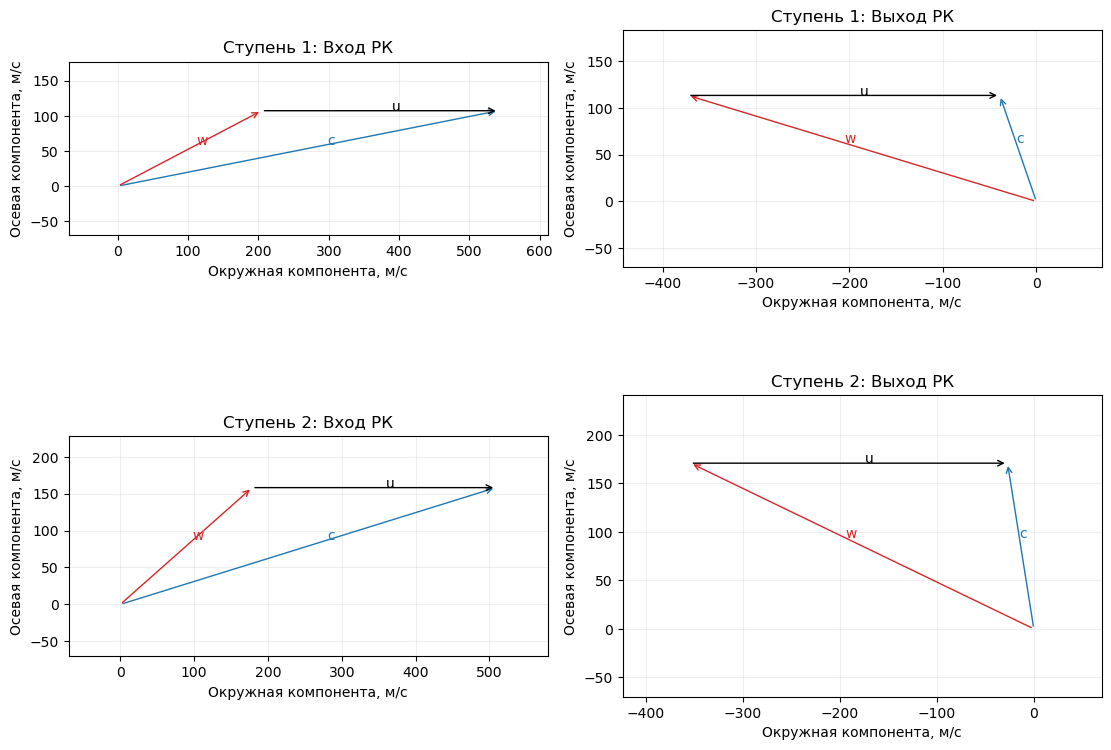

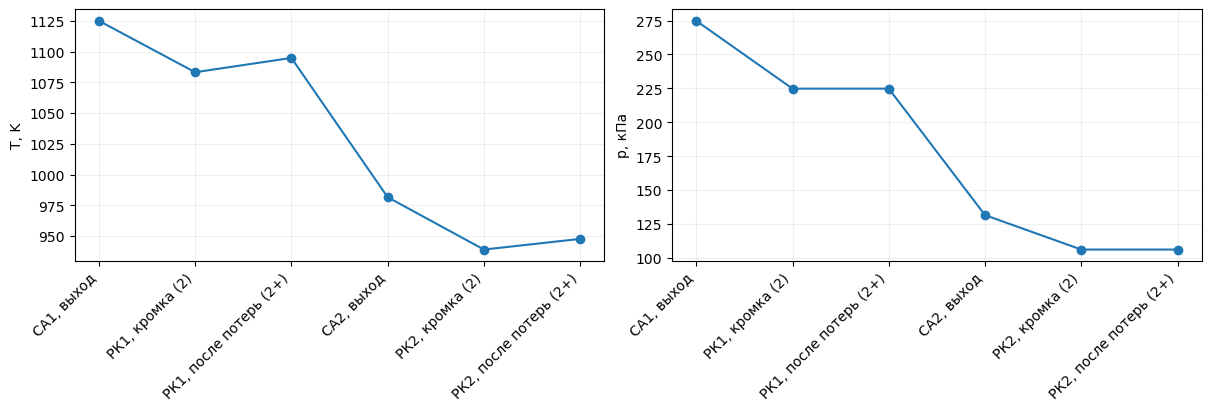

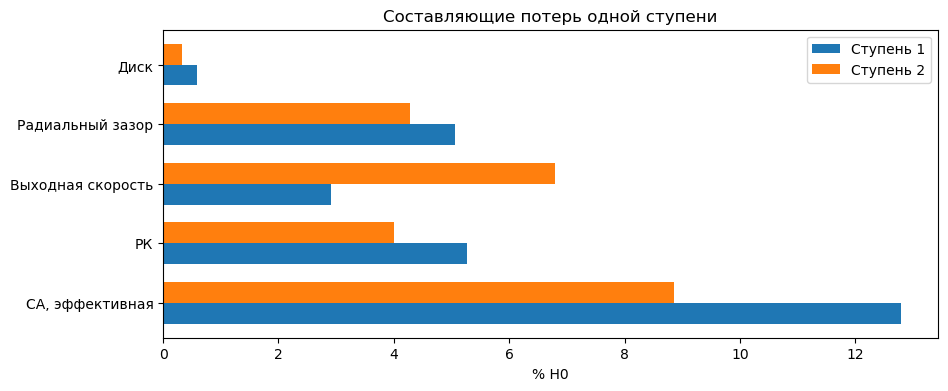

In [30]:
fig,axs=plt.subplots(2,2,figsize=(11,8),layout='constrained')
for i,s in enumerate(P0['stages']):
    pairs=[(np.array([s['c1u'],s['c1a']]),s['u1'],'Вход РК'),
           (np.array([-s['c2u'],s['c2a']]),s['u2'],'Выход РК')]
    for j,(cv,uv,label) in enumerate(pairs):
        ax=axs[i,j];wv=cv-np.array([uv,0.])
        for start,vec,col,text in [(np.zeros(2),cv,'tab:blue','c'),(np.zeros(2),wv,'tab:red','w'),(wv,np.array([uv,0.]),'black','u')]:
            end=start+vec;ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'->','color':col})
            ax.text(*(start+.55*vec),text,color=col)
        pts=np.array([[0,0],cv,wv]);pad=70
        ax.set_xlim(pts[:,0].min()-pad,pts[:,0].max()+pad);ax.set_ylim(-pad,pts[:,1].max()+pad)
        ax.set(title=f'Ступень {i+1}: {label}',xlabel='Окружная компонента, м/с',ylabel='Осевая компонента, м/с')
        ax.set_aspect('equal');ax.grid(alpha=.2)
        assert np.linalg.norm(cv-wv-np.array([uv,0.]))<1e-9
plt.show()
fig,axs=plt.subplots(1,2,figsize=(12,4),layout='constrained')
selected=stations_df.loc[[idx for idx in stations_df.index if 'выход' in idx or 'кромка' in idx or '(2+)' in idx]]
for ax,col in zip(axs,['T, K','p, кПа']):
    ax.plot(np.arange(len(selected)),selected[col],marker='o');ax.set_xticks(np.arange(len(selected)),selected.index,rotation=45,ha='right')
    ax.set_ylabel(col);ax.grid(alpha=.2)
plt.show()
loss_keys=['hc_eff','hl','hv','hgap','hdisc'];labels=['СА, эффективная','РК','Выходная скорость','Радиальный зазор','Диск']
fig,ax=plt.subplots(figsize=(10,4))
y=np.arange(len(loss_keys))
for i,s in enumerate(P0['stages']):ax.barh(y+(i-.5)*.35,[100*s[k]/s['H0'] for k in loss_keys],height=.35,label=f'Ступень {i+1}')
ax.set(yticks=y,yticklabels=labels,xlabel='% H0',title='Составляющие потерь одной ступени');ax.legend();plt.show()

## 13. Радиальные графики выбранного и альтернативного законов

Критерий корневой реактивности в итоговой таблице относится к `RADIAL_LAW`. Сравнение двух законов не используется для подмены неудачного результата более удобным. Нужны дальнейшее профилирование и согласование радиальных расходов.

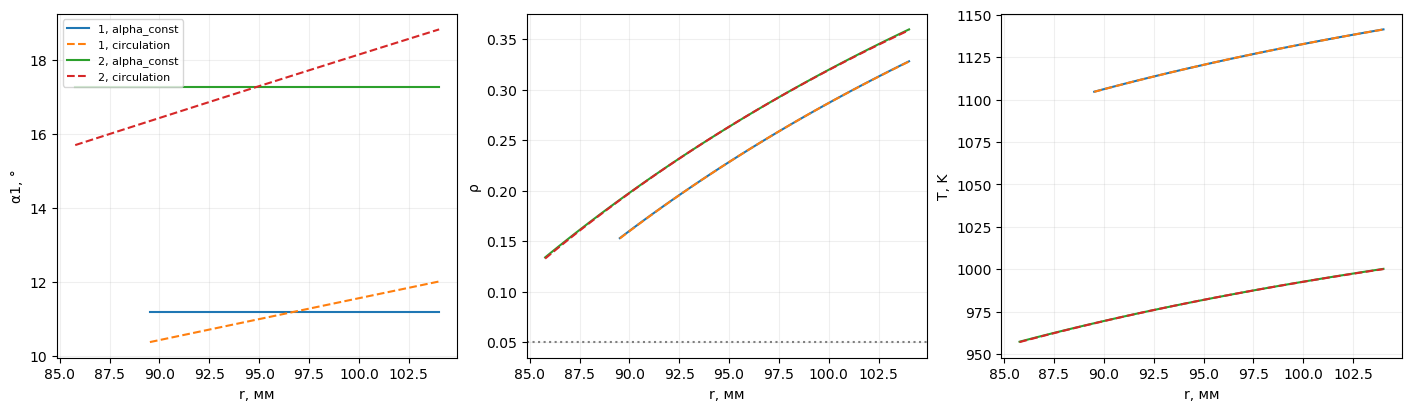

,Ступень,Закон,ρ корень,ρ периферия,"T корень, K","T периферия, K"
0,1,alpha_const,0.152883,0.327974,1104.653988,1141.418625
1,1,circulation,0.152590,0.327767,1104.592281,1141.375237
2,2,alpha_const,0.133846,0.359554,957.238236,1000.200633
3,2,circulation,0.132663,0.358791,957.012143,1000.055968


In [31]:
radial_rows=[]
fig,axs=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for i,s in enumerate(P0['stages'],1):
    for law in ['alpha_const','circulation']:
        df=radial_profile(s,law,cfg=C);style='-' if law==RADIAL_LAW else '--'
        label=f'{i}, {law}'
        for ax,col in zip(axs,['alpha_deg','rho','T_K']):ax.plot(df.r_m*1000,df[col],style,label=label)
        radial_rows.append({'Ступень':i,'Закон':law,'ρ корень':df.rho.iloc[0],'ρ периферия':df.rho.iloc[-1],
                            'T корень, K':df.T_K.iloc[0],'T периферия, K':df.T_K.iloc[-1]})
for ax,lab in zip(axs,['α1, °','ρ','T, K']):ax.set(xlabel='r, мм',ylabel=lab);ax.grid(alpha=.2)
axs[1].axhline(.05,color='grey',ls=':');axs[0].legend(fontsize=8);plt.show()
radial_df=pd.DataFrame(radial_rows);display(radial_df.round(6))

## 14. Чувствительность к зазору, потерям и параметрам перехода

Это **повторное предварительное проектирование** при фиксированных n, Dк, углах α1, κ и доле перепада. Высоты, расход и площади пересчитываются; таблица не является характеристикой неизменных изготовленных решёток. Для каждого сценария расход снова решается из мощности. Коэффициенты после сценария не требуется восстанавливать: используются отдельные неизменяемые конфигурации.

In [32]:
scenario_configs=[('База, δmin=0,5 мм',C),('δmin=0,2 мм, не обоснован',replace(C,delta_min=.0002)),
    ('δmin=0,7 мм',replace(C,delta_min=.0007)),('φ=0,96',replace(C,phi=(.96,.96))),
    ('ψ=0,95',replace(C,psi=(.95,.95))),
    ('μ=0,70',replace(C,mu=.7)),('σmix=0,98',replace(C,sigma_mix=.98))]
sensitivity_rows=[]
for name,cfg in scenario_configs:
    try:
        rr=evaluate(GEOMETRY,cfg);dd=design_checks(rr);bal=balances(rr)
        sensitivity_rows.append({'Сценарий':name,'G, кг/с':rr['G'],'Топливо, кг/ч':rr['m_fuel']*3600,
            'ce, кг/(кВт·ч)':rr['m_fuel']*3600/(rr['power_W']/1000),'T* выход, K':rr['stages'][-1]['Tstar'],
            'Балансы выполнены':bool(bal.passed.all()),'Нарушенные ориентиры':'; '.join(dd.loc[~dd['Выполнено'],'Условие'])})
    except (ValueError,ArithmeticError,RuntimeError) as exc:sensitivity_rows.append({'Сценарий':name,'Ошибка':str(exc)})
sensitivity_df=pd.DataFrame(sensitivity_rows);display(sensitivity_df.round(6))

,Сценарий,"G, кг/с","Топливо, кг/ч","ce, кг/(кВт·ч)","T* выход, K",Балансы выполнены,Нарушенные ориентиры
0,"База, δmin=0,5 мм",0.792317,60.331012,0.548464,960.556107,True,
1,"δmin=0,2 мм, не обоснован",0.732583,55.782608,0.507115,950.741938,True,СА1 ≥ 14 мм
2,"δmin=0,7 мм",0.832352,63.379492,0.576177,966.336968,True,α2 второй ступени
3,"φ=0,96",0.714192,54.382213,0.494384,947.385575,True,СА1 ≥ 14 мм; α2 первой ступени; Разброс прирос...
4,"ψ=0,95",0.774555,58.978569,0.536169,957.797880,True,"α2 первой ступени; Разброс приростов высот, мм"
5,"μ=0,70",0.798990,60.839133,0.553083,961.560341,True,"Разброс приростов высот, мм"
6,"σmix=0,98",0.806362,61.400464,0.558186,962.650205,True,"Разброс приростов высот, мм"


## 15. Независимые численные проверки и граничные случаи

Прямой полином ниже отдельно переписан с с. 57; интегралы проверяются квадратурой, а не повторным вызовом того же первообразного. Проверяются граница 750 К, энергия каждой ступени, неизменность состава и расхода в неохлаждаемом переходе, недостаточный корпус, разрыв допустимой области и распознавание запертого сопла. Тесты не утверждают пригодность реального профиля.

In [33]:
def cp_book_direct(T,a):
    inv=0. if np.isinf(a) else 1/a
    if T<750:
        z=(.0174*inv+.2407)+(.0093*inv+.0193)*(.0025*T-.875)+(.002-.001056/(a-.2))*(.000025*T*T-.0275*T+6.5625)
    else:
        z=(.0267*inv+.26)+(.0133*inv+.032)*(.001176*T-.88235)-(.00374+.0094/(a*a+10))*(.0000055556*T*T-.013056*T+6.67)
    return 4187*z
validation_rows=[]
for al in [np.inf,P0['stages'][0]['alpha'],P0['stages'][1]['alpha']]:
    for T in [288.,493.,699.9,700.1,749.99,750.,900.,1250.]:
        err=cp_true(T,al)-cp_book_direct(T,al)
        assert abs(err)<1e-8
    for lo,hi in [(288.,650.),(650.,900.),(750.,1250.)]:
        pts=[750.] if lo<750<hi else None
        qh=quad(lambda T:cp_book_direct(T,al),lo,hi,points=pts,epsabs=1e-6)[0]
        qs=quad(lambda T:cp_book_direct(T,al)/T,lo,hi,points=pts,epsabs=1e-8)[0]
        eh=integral(lo,hi,al)-qh;es=ds(lo,hi,al)-qs
        assert abs(eh)<1e-5 and abs(es)<1e-8
        validation_rows.append({'α':al,'Интервал, K':f'{lo:g}…{hi:g}','Δh, Дж/кг':eh,'Δs, Дж/(кг·К)':es})
    assert abs(h(750+1e-7,al)-h(750-1e-7,al))<.001
assert P0['stages'][0]['G']==P0['stages'][1]['G']
assert P0['stages'][0]['alpha']==P0['stages'][1]['alpha']
for name,call in [
    ('Недостаточный Dк',lambda:annulus(.01,.035)),
    ('Нельзя строить скобку через недопустимую область',lambda:root_on_valid_intervals(
        lambda x: -1 if x<=1 else (1 if x>=2 else (_ for _ in ()).throw(Bad('разрыв'))),[0,.5,1,1.5,2,2.5,3])),
    ('Запертое сопло',lambda:nozzle(P0['stages'][-1],P0['G'],GEOMETRY[1],replace(C,pa=55000.)))]:
    try:call()
    except ValueError as exc:
        if name=='Запертое сопло':assert 'Запирание' in str(exc)
        print(name+': ожидаемый отказ — '+str(exc))
    else:raise AssertionError(name+': недопустимое состояние было принято')
validation_df=pd.DataFrame(validation_rows);display(validation_df)
assert balances(P0).passed.all()
print('Проверки свойств, балансов и граничных случаев выполнены.')

Недостаточный Dк: ожидаемый отказ — Площадь не помещается в корпус
Нельзя строить скобку через недопустимую область: ожидаемый отказ — Корень не найден на непрерывных допустимых интервалах
Запертое сопло: ожидаемый отказ — Запирание сопла: расчёт критического горла не реализован


,α,"Интервал, K","Δh, Дж/кг","Δs, Дж/(кг·К)"
0,inf,288…650,-5.820766e-11,-1.023182e-12
1,inf,650…900,5.820766e-11,1.477929e-12
2,inf,750…1250,1.164153e-10,4.547474e-13
3,3.211745,288…650,-5.820766e-11,-1.136868e-13
4,3.211745,650…900,5.820766e-11,1.136868e-13
5,3.211745,750…1250,1.164153e-10,1.136868e-13
6,3.211745,288…650,-5.820766e-11,-1.136868e-13
7,3.211745,650…900,5.820766e-11,1.136868e-13
8,3.211745,750…1250,1.164153e-10,1.136868e-13


Проверки свойств, балансов и граничных случаев выполнены.


### 15.1. Изменение мощности и проверка фиксированной площади

Мощность 100/120 кВт меняет найденный расход. Обратная проверка площади решает одновременно G и противодавление; исходная конфигурация и базовый результат не меняются. Обе задачи остаются проектными при пересчитываемых высотах.

In [34]:
stress_rows=[]
for target in [100000.,120000.]:
    rr=evaluate(GEOMETRY,replace(C,target_W=target))
    assert balances(rr).passed.all()
    stress_rows.append({'Режим':f'{target/1000:g} кВт','G, кг/с':rr['G'],'N, кВт':rr['power_W']/1000,
                       'p2, кПа':rr['p_back']/1000,'Aсопла, см²':rr['nozzle']['A']*1e4})
fixed_area_result=evaluate(GEOMETRY,C,exit_area=P0['nozzle']['A'])
assert balances(fixed_area_result).passed.all()
assert abs(fixed_area_result['p_back']-P0['p_back'])<.02
assert abs(fixed_area_result['G']-P0['G'])<1e-7
stress_rows.append({'Режим':'FIXED_AREA: обратное восстановление','G, кг/с':fixed_area_result['G'],
    'N, кВт':fixed_area_result['power_W']/1000,'p2, кПа':fixed_area_result['p_back']/1000,
    'Aсопла, см²':fixed_area_result['nozzle']['A']*1e4})
stress_df=pd.DataFrame(stress_rows);display(stress_df.round(6))

,Режим,"G, кг/с","N, кВт","p2, кПа","Aсопла, см²"
0,100 кВт,0.729565,100.0,106.365,92.373440
1,120 кВт,0.855383,120.0,106.365,107.598240
2,FIXED_AREA: обратное восстановление,0.792317,110.0,106.365,100.003509


## 16. Реестр источников, формул и единиц

«Обобщение» обозначает интегральную реализацию с переменной теплоёмкостью, а не буквальное воспроизведение формулы книги. «Выбор» означает исходное допущение. Статус уравнения нельзя переносить на экспериментальную достоверность коэффициента.

| Группа | Реализация | Источник | Статус / единицы |
|---|---|---|---|
| Истинная cp_i | `cp_coeff`, `cp_true` | 2014, прил. 6, с. 57 | Прямой полином; Дж/(кг·К) |
| h, температурный интеграл энтропии | `integral`, `h`, `ds` | 2014, с. 12–13, 19; прил. 6 | Аналитическое интегрирование; Дж/кг и Дж/(кг·К) |
| Изоэнтропа и полное давление | `isentropic_T`, `pressure_isentropic` | 2006, пп. 79, 93, 127, 140 | Обобщение для переменной cp; К, Па |
| Политропное сжатие, работа ЦБК | `upstream` | 2014, с. 9, 12–13 | Обобщение; политропный КПД 0,85 — нижняя граница интервала ЦБК |
| Входное давление | `upstream.p_in` | 2014, с. 6, 10 | σвх=0,98; Па |
| Давление КС / турбины | `p_k`, `p_g` | 2014, с. 7, 12, 16 | σг=0,96; Па |
| Баланс КС, α | `upstream`, `two_stage` | 2014, с. 19–23 | Обобщение; f кг/кг воздуха КС; состав смеси обновляется |
| Qн, l0 | `Config.Q_LHV`, `l0` | 2014, табл. 2, с. 21 | Табличный керосин; 43·10⁶ Дж/кг и 14,61 кг/кг |
| Tref и температура топлива | `Config.Tref` | 2014, с. 20 | 288 К, явно принято Tтопл=Tref |
| Массовые отборы | `Config.g_leak`, `two_stage` | 2014, с. 22–23 | Невозвратная утечка 0,75%; охлаждающие отборы и возврат исключены |
| H0, Hc | `stage`, `stage_at_diameters` | 2006, пп. 70–78, 140 | Обобщение; Дж/кг |
| c1, T1, p1 | `stage_at_diameters` | 2006, пп. 74–83 | Обобщение; φ каждого СА уточняется по потерям |
| u, w1, β1 | там же | 2006, пп. 84–88 | Кинематика, м/с и градусы |
| Hl, w2, T2 | там же | 2006, пп. 86, 90–94 | Обобщение; ψ каждого РК уточняется по потерям |
| c2a=κc1a | там же | 2006, пп. 95–96 | κ выбран, площадь из неразрывности |
| β2, c2u, α2, c2 | там же | 2006, пп. 97–100 | Книжный знак c2u, градусы и м/с |
| Lu и ηu | там же | 2006, пп. 101–102 | Прямая кинематика; Дж/кг |
| hc, hc_eff, hl, hv | там же | 2006, пп. 103–111 | hc_eff — интегральное обобщение; Дж/кг |
| Радиальный зазор, hgap | там же | 2006, с. 41, 63, пп. 113–115 | Необандаженная модель; δmin=0,5 мм — предварительный выбор |
| Трение и вентиляция | `Ndisc`, `hdisc` | 2006, с. 44–45, пп. 119–121 | Ndisc в Вт после ×1000; ε=1, плотность — оценка |
| Lt, мощностной и полный КПД | `Lt`, `eta_t`, `eta_star` | 2006, пп. 116–129 | Дж/кг; размерность КПД — 1 |
| Сечения 2 и 2+ | `T2`, `Tpost`, `A2`, `A_post` | 2006, пп. 94–96, 125–127 | Разделённые состояния; обе площади замкнуты по массе |
| Межступенчатое p* | `two_stage` | 2006, пп. 130–140 | Обобщение п.132; μ и σmix — выбор; отдельный п.134 повторно не добавляется к п.140 |
| Адиабатический межступенчатый переход | `two_stage` | 2014, с. 20, 23; 2006, с. 44 | Без подмешивания воздуха; импульс и реальные потери перехода не решены |
| Расход из мощности | `solve_flow` | 2014, с. 22–25 | Корневое решение, кг/с; не независимая проверка мощности |
| Выпуск, скорость, тяга | `nozzle` | 2014, с. 7, 24 | φс=0,95, σвых=0,99 внутри интервалов; осевой полностью расширенный поток |
| Критическое состояние | `nozzle` | Идеальный газ: h0=h+a²/2, ds=R ln(p/p0) | Обобщение с переменной cp, не дословная формула указанных страниц |
| ce | `summary_table` | 2014, с. 42–43 | кг/(кВт·ч), деление на фактические кВт |
| Сечение кольца Dк=const | `annulus`, `stage` | 2006, с. 61–63 | Геометрия, м и м²; втулка меняется |
| Реактивность | `Config.rho_stage1/2`, `stage` | 2006, с. 58 | В v9 две реактивности подобраны по ограничениям; интерполяция ориентиров доступна при None |
| Оценка напряжения | `sigma_MPa` | 2006, с. 55–57, формула (63) | МПа; Kn не расчёт материала |
| Радиальный закон | `radial_profile` | 2006, с. 66–76 | Идеализированное обобщение с s=const и переменной T |
| b_ax, зазор СА/РК | `meridional_channel`, `drawing_schedule` | 2006, с.61–62 | Разные bax по высоте; свободный δax=0,23bax охватывающего венца, не часть профиля |
| Профили, хорда, шаг, Z | `preliminary_profile`, `profile_cascades` | 2006, раздел 8, с.78–84 | Отдельные поверхности и круговые кромки, измеренные хорды; Z=9/11/12/13 |
| Межступенчатый осевой зазор | `meridional_channel` | Выбор проекта, не формула учебника | Вычисляется по актуальному каналу; включает участок 2+ и переход |
| Требования роста / углов / давления | `design_checks` | Проектные предпочтения | Не нормы из книги |
| Механический КПД, редуктор | `two_stage` | 2014, с. 7, 22–25 | 0,99 и 0,98; множители применены к нужным мощностям |

Единицы: температуры — К; давление — Па; диаметры и высоты в ядре — м; расходы — кг/с; работа/потери — Дж/кг; мощности в ядре — Вт. См², мм, кВт и кг/ч используются только при выводе.

### 16.1. Диагностика u/c0 и предварительная оценка числа ступеней

2006, с. 58–59 и пп. 45–54 на с. 87. Ориентир (u/c0)опт=0,55…0,60 относится к предварительной оценке при реактивности 0,25…0,45. Здесь принят y0=0,575. Формула числа ступеней использует общий условный адиабатный перепад, среднюю скорость и среднюю выходную скорость. Для диагностики общего перепада условно оставлен состав перед первой ступенью: изменение массы и состава между ступенями не учитывается этой предварительной формулой. Поэтому её результат выводится отдельно от выполненных балансов и не является командой изменить заданное число ступеней.

In [35]:
y0_chosen=.575
uc0_rows=[]
for i,st in enumerate(P0['stages'],1):
    umean=.5*(st['u1']+st['u2']);ratio=umean/math.sqrt(2*st['H0'])
    uc0_rows.append({'Ступень':i,'ρ':st['rho'],'u/c0':ratio,'Выбранный ориентир y0':y0_chosen})
display(pd.DataFrame(uc0_rows).round(6))
first,last=P0['stages']
Tiso_overall=isentropic_T(C.Tg,first['p0'],last['p2'],first['alpha'],C)
H0_overall=integral(Tiso_overall,C.Tg,first['alpha'])
u_avg=np.mean([st[key] for st in P0['stages'] for key in ['u1','u2']])
c2_avg_sq=np.mean([st['c2']**2 for st in P0['stages']])
denominator=u_avg**2/y0_chosen**2-C.mu**2*c2_avg_sq
if denominator>0:
    z_estimate=(2*H0_overall-C.mu**2*c2_avg_sq)/denominator
    print(f'Условная оценка числа ступеней по п.54: z={z_estimate:.3f}; округление вверх {math.ceil(z_estimate)}.')
    print('Заданная схема: 2 ступени. Оценка не учитывает межступенчатое смешение; требуется отдельное проектное обоснование.')
else:
    z_estimate=None
    print('Предварительная формула числа ступеней неприменима: неположительный знаменатель.')

,Ступень,ρ,u/c0,Выбранный ориентир y0
0,1,0.250000,0.476845,0.575
1,2,0.261974,0.495191,0.575


Условная оценка числа ступеней по п.54: z=2.815; округление вверх 3.
Заданная схема: 2 ступени. Оценка не учитывает межступенчатое смешение; требуется отдельное проектное обоснование.


## 17. Что исправление модели не подтверждает

| Вопрос | Статус |
|---|---|
| Материал, температура металла, ресурс и допустимые напряжения | §10, §32.6: пользовательский ресурс 2000 ч, литой IN-738C по INCO 497 и верхняя тепловая оценка; аттестованные свойства поставки и общий ресурс не подтверждены |
| Горячий зазор и деформации корпуса/ротора | Не рассчитаны; 0,5 мм — предварительный выбор |
| Охлаждение дисков | Исключено из схемы; невозвратная утечка 0,75% не используется для охлаждения и не возвращается в газовый тракт |
| Охлаждение пера | Исключено по требованию пользователя; тепловая пригодность неохлаждаемого узла требует подтверждения |
| ЦБК | Только термодинамический расчёт цикла; геометрия, карта и помпаж не входят в задание на турбину |
| Число ступеней по пп. 45–54, с. 87 книги 2006 | Предварительная оценка выведена отдельно; две ступени заданы схемой, окончательный выбор не обоснован |
| Профили и горла | В разделах 25–27 построены и проверены предварительные контуры; критерии сохраняются; φ/ψ согласованы в приближённой модели потерь, экспериментально не подтверждены |
| Радиальное равновесие | В разделе 23 замкнуты интегральные расходы и линии тока в осесимметричной модели; вязкое 3D-поле не рассчитано |
| Переходы и меридиональный канал | В разделе 24 построена ломаная проточная часть турбины и сплайн выходного сопла с проверкой площади и углов; потери канала не рассчитаны |
| Запертое сопло | Распознаётся и отклоняется, критическое горло не проектируется |
| Полётный режим и винт | Не рассчитываются, основной режим стендовый |

110 кВт — **мощность после редуктора**. Эквивалентная мощность ТВД из с. 23–24 пособия 2014 года дополнительно включает тягу сопла через тяговый коэффициент винта; она не отождествляется с Nвала. Значение тяги без винтовой модели не подтверждает эффективность самолётной установки.

## 18. Историческое сравнение и итог

Следующие старые числа зафиксированы из v7 до исправлений. Они не пересчитываются и не используются как входные параметры новой ветки. Разница включает одновременно истинную cp, единый интегральный расчёт ступеней, новый состав смеси, температуру отсчёта, табличную Q и зазор 0,5 мм. Приписывать всё изменение одному фактору нельзя.

In [36]:
historical={'N, кВт':110.,'G воздуха, кг/с':.6226974569443171,'Топливо, кг/ч':45.449546614794585,
            'ce, кг/(кВт·ч)':.4131776964981326,'T* выход, K':912.3166839190284,
            'p* выход, кПа':114.6277529681636,'A сопла, см²':69.09592751111312}
new={'N, кВт':P0['power_W']/1000,'G воздуха, кг/с':P0['G'],'Топливо, кг/ч':P0['m_fuel']*3600,
     'ce, кг/(кВт·ч)':P0['m_fuel']*3600/(P0['power_W']/1000),'T* выход, K':P0['stages'][-1]['Tstar'],
     'p* выход, кПа':P0['stages'][-1]['pstar']/1000,'A сопла, см²':P0['nozzle']['A']*1e4}
comparison_df=pd.DataFrame({'v7: историческая P0':historical,'v9: исправленный расчёт':new})
comparison_df['Изменение']=comparison_df.iloc[:,1]-comparison_df.iloc[:,0]
display(comparison_df.round(6))
print('Балансы:',bool(balance_df.passed.all()))
print('Не выполнены ориентиры:',violations)
print('Конструкция не подтверждена: нужны перечисленные выше исходные данные и расчёты.')

,v7: историческая P0,v9: исправленный расчёт,Изменение
"N, кВт",110.000000,110.000000,-0.000000
"G воздуха, кг/с",0.622697,0.792317,0.169619
"Топливо, кг/ч",45.449547,60.331012,14.881466
"ce, кг/(кВт·ч)",0.413178,0.548464,0.135286
"T* выход, K",912.316684,960.556107,48.239423
"p* выход, кПа",114.627753,112.329880,-2.297873
"A сопла, см²",69.095928,100.003509,30.907582


Балансы: True
Не выполнены ориентиры: []
Конструкция не подтверждена: нужны перечисленные выше исходные данные и расчёты.


## 19. Повторный подбор компоновки — только по явному запуску

Оптимизатор не исправляет исходные коэффициенты потерь. На каждом кандидате расход решается заново по мощности. Подбор не запускается при обычном Run All. Даже при сходимости алгоритма возвращаются фактические невыполненные условия; реализация материала, карты ЦБК и профилей не оценивается.

Результат сохраняется отдельно и **не подменяет** GEOMETRY или P0. Возможен длительный расчёт.

In [37]:
def search_geometry(cfg=C,iterations=30,seed=1):
    """Не запускается автоматически. При каждом кандидате G решается из мощности.
    Ограничения остаются диагностическими; успешный DE не подтверждает конструкцию.
    """
    bounds=[(55000,95000),(.12,.17),(11,20),(11,20),(.8,1.4),(.8,1.4),(.41,.59)]
    def objective(x):
        try:
            r=solve_flow(x,cfg);a,b=r['stages'];hh=np.array([a['l_c'],a['l_l'],b['l_c'],b['l_l']]);di=np.diff(hh)
            roots=[radial_profile(s,points=3,cfg=cfg).iloc[0]['rho'] for s in (a,b)]
            penalties=[max(0,.014-a['l_c'])/.003,max(0,np.ptp(di)-.00025)/.00025,
                       *[max(0,-d)/.001 for d in di],*[max(0,.05-v)/.05 for v in roots],
                       max(0,70-a['a2'])/10,max(0,a['a2']-90)/10,
                       max(0,80-b['a2'])/10,max(0,b['a2']-90)/10]
            for s in (a,b):
                penalties.extend([max(0,s['sigma_MPa']-cfg.sigma_project_MPa)/50,max(0,s['M_c1']-1)/.1,
                    max(0,s['M_w2']-1)/.1,max(0,.7-s['eta_t'])/.1,max(0,max(s['u1'],s['u2'])-400)/50,
                    max(0,1.8-s['p0']/s['pstar'])/.2,max(0,s['p0']/s['pstar']-2.4)/.2])
            return sum(p*p for p in penalties)+.001*r['G']
        except (ValueError,ArithmeticError,RuntimeError):return 1e8
    solver=differential_evolution(objective,bounds,maxiter=iterations,popsize=5,seed=seed,polish=False)
    r=evaluate(solver.x,cfg)
    return dict(solver_converged=bool(solver.success),message=str(solver.message),
                geometry=solver.x,objective=float(solver.fun),result=r,checks=design_checks(r))

In [38]:
RUN_OPTIMIZATION=False
if RUN_OPTIMIZATION:
    search_result=search_geometry(C,iterations=30,seed=1)
    print('Сходимость:',search_result['solver_converged'],search_result['message'])
    print('Новая геометрия:',search_result['geometry'])
    display(search_result['checks'])
else:
    print('Повторная оптимизация не запускалась. Прежняя компоновка проверена без скрытого подбора.')

Повторная оптимизация не запускалась. Прежняя компоновка проверена без скрытого подбора.


## 21. Начальный протокол и итог уточнения потерь

Сначала был выполнен подбор по средним диаметрам; расширенный расчёт обнаружил у корня СА сверхзвуковые скорости. Такой вариант не был принят. Затем реактивности стали самостоятельными переменными, что соответствует их выбору по условиям у корня (2006, с.58), а не жёсткой интерполяции ориентиров.

Подбор выполнялся SLSQP по `[n,Dк,α11,α12,κ1,κ2,q,G,ρ1,ρ2]`. К прежним условиям добавлены запасы: корневое Mc1≤0,98 при интегральном замыкании расхода, σKn≤195 МПа, α2≥71°/81°, разброс приростов≤0,20 мм, средняя u≤395 м/с. Коэффициенты φ,ψ,μ,σmix, зазор и πк не оптимизировались.

Ниже сохранён исторический начальный протокол. После него коэффициенты и компоновка уточнены совместно; актуальный результат — COUPLED, а не числа старого протокола. При Run All пересчитываются потери и геометрия; SLSQP вызывается только при выходе новой точки за прежние ограничения. Глобальный оптимум не заявляется.

In [39]:
OPTIMIZATION_REPORT = {'success': True, 'message': 'Optimization terminated successfully', 'x': [52499.59656828121, 0.15679092232791533, 11.2, 16.104264337072202, 1.0234148689188718, 1.1180875699263502, 0.5146756629238036, 0.6340264803849457, 0.34330667996504133, 0.3949588098208516], 'min_constraint': -2.909388285843306e-11, 'power_residual_W': 6.488699000328779e-08, 'radial_screen': [{'scale': 1.0122490309396843, 'M_root': 0.9799999999999083, 'rho_root': 0.1837636484433876}, {'scale': 1.0185588033381643, 'M_root': 0.9799999956841314, 'rho_root': 0.15230196869028684}], 'nfev': 653, 'nit': 49, 'objective': 0.6399088609052662, 'initial_x': [55000.0, 0.14723492339962943, 11.200000000000005, 16.99136098230924, 1.0100977864886231, 1.1134816482283398, 0.5096732444042822, 0.6363425067977115, 0.4, 0.45], 'bounds': [[50000, 95000], [0.12, 0.17], [11.2, 19.8], [11.2, 19.8], [0.8, 1.65], [0.8, 1.65], [0.4, 0.6], [0.4, 0.9], [0.25, 0.55], [0.25, 0.55]], 'scales': [70000.0, 0.14, 15.0, 18.0, 1.0, 1.0, 0.5, 0.65, 0.4, 0.4], 'maxiter': 220, 'ftol': 1e-10, 'elapsed_seconds': 17.346927165985107, 'iteration_trace': ['step 0 Nres -717.99 min -2.76656 rad [np.float64(0.97), np.float64(0.9644)]', 'step 1 Nres -36.09 min -0.35219 rad [np.float64(0.9802), np.float64(0.9805)]', 'step 1 Nres 1.41 min -2.17804 rad [np.float64(0.98), np.float64(0.98)]', 'step 1 Nres -0.17 min -0.57308 rad [np.float64(0.98), np.float64(0.98)]', 'step 1 Nres -0.04 min -0.25459 rad [np.float64(0.98), np.float64(0.98)]', 'step 2 Nres 0.25 min -0.00594 rad [np.float64(0.98), np.float64(0.98)]', 'step 2 Nres 0.72 min -0.51998 rad [np.float64(0.98), np.float64(0.98)]', 'step 2 Nres 1.2 min -0.92702 rad [np.float64(0.98), np.float64(0.98)]', 'step 3 Nres 0.97 min -0.91982 rad [np.float64(0.98), np.float64(0.98)]', 'step 3 Nres 0.78 min -0.92128 rad [np.float64(0.98), np.float64(0.98)]', 'step 3 Nres 0.63 min -0.91886 rad [np.float64(0.98), np.float64(0.98)]', 'step 4 Nres 0.63 min -0.92888 rad [np.float64(0.98), np.float64(0.98)]', 'step 4 Nres 0.61 min -0.91991 rad [np.float64(0.98), np.float64(0.98)]', 'step 4 Nres 0.6 min -0.91921 rad [np.float64(0.98), np.float64(0.98)]', 'step 5 Nres 0.58 min -0.91883 rad [np.float64(0.98), np.float64(0.98)]', 'step 5 Nres 0.57 min -0.91996 rad [np.float64(0.98), np.float64(0.98)]', 'step 5 Nres 0.57 min -0.92124 rad [np.float64(0.98), np.float64(0.98)]', 'step 6 Nres 0.52 min -0.88257 rad [np.float64(0.98), np.float64(0.98)]', 'step 6 Nres 0.47 min -0.83273 rad [np.float64(0.98), np.float64(0.98)]', 'step 6 Nres 0.75 min -1.06022 rad [np.float64(0.98), np.float64(0.98)]', 'step 7 Nres 0.57 min -0.92476 rad [np.float64(0.98), np.float64(0.98)]', 'step 7 Nres 0.53 min -0.89391 rad [np.float64(0.98), np.float64(0.98)]', 'step 8 Nres 1.15 min -1.31421 rad [np.float64(0.98), np.float64(0.98)]', 'step 8 Nres 0.56 min -0.91779 rad [np.float64(0.98), np.float64(0.98)]', 'step 8 Nres 0.48 min -0.84838 rad [np.float64(0.98), np.float64(0.98)]', 'step 9 Nres 0.17 min -0.50454 rad [np.float64(0.98), np.float64(0.98)]', 'step 9 Nres 5.57 min -2.88539 rad [np.float64(0.98), np.float64(0.9801)]', 'step 10 Nres 0.26 min -0.62344 rad [np.float64(0.98), np.float64(0.98)]', 'step 10 Nres 0.4 min -0.77322 rad [np.float64(0.98), np.float64(0.98)]', 'step 10 Nres 0.71 min -1.02938 rad [np.float64(0.98), np.float64(0.98)]', 'step 11 Nres 9.34 min -3.74761 rad [np.float64(0.9775), np.float64(0.9802)]', 'step 11 Nres 263.9 min -20.04155 rad [np.float64(0.9671), np.float64(0.9843)]', 'step 12 Nres 0.0 min -0.0 rad [np.float64(0.98), np.float64(0.98)]', 'step 12 Nres 0.0 min -0.0 rad [np.float64(0.98), np.float64(0.98)]', 'step 12 Nres 0.0 min -0.0 rad [np.float64(0.98), np.float64(0.98)]', 'step 13 Nres 0.0 min -0.0 rad [np.float64(0.98), np.float64(0.98)]', 'step 13 Nres 0.0 min -0.0 rad [np.float64(0.98), np.float64(0.98)]', 'step 13 Nres 0.0 min -0.00394 rad [np.float64(0.98), np.float64(0.98)]', 'step 14 Nres 0.0 min -0.04207 rad [np.float64(0.98), np.float64(0.98)]', 'step 14 Nres 0.0 min -0.00379 rad [np.float64(0.98), np.float64(0.98)]', 'step 14 Nres -0.0 min -0.0 rad [np.float64(0.98), np.float64(0.98)]', 'step 14 Nres 0.0 min -0.0 rad [np.float64(0.98), np.float64(0.98)]', 'step 15 Nres 0.0 min -0.00054 rad [np.float64(0.98), np.float64(0.98)]', 'step 15 Nres 0.0 min -0.00476 rad [np.float64(0.98), np.float64(0.98)]', 'step 16 Nres 0.0 min -0.02541 rad [np.float64(0.98), np.float64(0.98)]', 'step 16 Nres 0.01 min -0.12857 rad [np.float64(0.98), np.float64(0.98)]', 'step 16 Nres 0.28 min -0.64305 rad [np.float64(0.98), np.float64(0.98)]', 'step 17 Nres 970.31 min -42.42102 rad [np.float64(0.9798), np.float64(0.9892)]', 'step 17 Nres 0.07 min -0.31453 rad [np.float64(0.98), np.float64(0.98)]']}
report_summary={k:OPTIMIZATION_REPORT[k] for k in ['success','message','nfev','nit','min_constraint','power_residual_W','elapsed_seconds']}
print('Исторический протокол начального SLSQP, до уточнения потерь и нового пера:')
display(pd.DataFrame([report_summary]).T)
print('Искомые параметры:',OPTIMIZATION_REPORT['x'])
print('Основной найденный расход:',P0['G'])
print('Расход начальной точки SLSQP (не итог согласования):',OPTIMIZATION_REPORT['x'][7])
assert COUPLED['coefficient_error']<=LOSS_MODEL['coefficient_tolerance']
assert COUPLED['profile_review']['Принят по геометрии'].all()
assert balances(P0).passed.all()
assert design_checks(P0)['Выполнено'].all()
print('Итоговая точка заново согласована по потерям; старый протокол не подменяет текущий расчёт.')

Исторический протокол начального SLSQP, до уточнения потерь и нового пера:


,0
success,True
message,Optimization terminated successfully
nfev,653
nit,49
min_constraint,-0.0
power_residual_W,0.0
elapsed_seconds,17.346927


Искомые параметры: [52499.59656828121, 0.15679092232791533, 11.2, 16.104264337072202, 1.0234148689188718, 1.1180875699263502, 0.5146756629238036, 0.6340264803849457, 0.34330667996504133, 0.3949588098208516]
Основной найденный расход: 0.7923167086965595
Расход начальной точки SLSQP (не итог согласования): 0.6340264803849457
Итоговая точка заново согласована по потерям; старый протокол не подменяет текущий расчёт.


## 22. Проверка числа ступеней и цикл

### 22.1. Число ступеней

Книга 2006, с.87, п.54:

`z = [c0² − (μc2)ср²] / [uср²/y0² − (μc2)ср²]`.

Ранее округление при единственном y0=0,575 давало три ступени. Это не единственное возможное y0: на с.58 для реактивности 0,25…0,45 указан ориентир 0,55…0,60. Здесь выведена чувствительность, а также y0, при котором формула даёт ровно две ступени. Состав общего условного перепада принят по входу первой ступени; модель числа ступеней не описывает межступенчатое смешение.

Сравнение 1/2/3 ступеней выполняется при одинаковых n,Dк и выбранных реактивностях, с перепроектированием высот. Это не сравнение трёх независимо оптимизированных двигателей. Во всех вариантах охлаждающего отбора и возврата нет; состав газа и расход через венцы постоянны. Числа Маха, напряжения и углы выводятся вместе с экономичностью.

In [40]:
count_sensitivity_df=pd.DataFrame([stage_count_estimate(P0,y0,mu) for y0 in [.55,.575,.60] for mu in [.8,.9,1.]])
display(count_sensitivity_df.round(6))
a,b=P0['stages'];c0=stage_count_estimate(P0)['c0_overall'];umean=stage_count_estimate(P0)['u_mean']
K=C.mu**2*np.mean([st['c2']**2 for st in P0['stages']])
y_for_two=umean*math.sqrt(2/(c0*c0+K))
print(f'y0 для z=2 при текущих uср,c2ср: {y_for_two:.6f}')
print('Ориентир книги 0,55…0,60; окончательный выбор учитывает также длину, массу и реальные потери.')
count_variants_df=compare_stage_counts(GEOMETRY,C)
display(count_variants_df.round(6))

,y0,mu,z_continuous,z_ceil,u_mean,c0_overall
0,0.550,0.8,2.546607,3,331.976272,951.765643
1,0.550,0.9,2.563428,3,331.976272,951.765643
2,0.550,1.0,2.582666,3,331.976272,951.765643
3,0.575,0.8,2.793900,3,331.976272,951.765643
4,0.575,0.9,2.815328,3,331.976272,951.765643
5,0.575,1.0,2.839890,3,331.976272,951.765643
6,0.600,0.8,3.054188,4,331.976272,951.765643
7,0.600,0.9,3.081040,4,331.976272,951.765643
8,0.600,1.0,3.111895,4,331.976272,951.765643


y0 для z=2 при текущих uср,c2ср: 0.488463
Ориентир книги 0,55…0,60; окончательный выбор учитывает также длину, массу и реальные потери.


,z,G_kg_s,N_kW,ce_kg_kWh,eta_t_min,M_c1_max,M_w2_max,sigma_max_MPa,alpha2_all_deg,stage_energy_max_J_kg,status
0,1,1.123115,110.0,0.777452,0.677004,1.201214,0.997173,142.128793,29.06,0.0,"сравнение при одинаковых n,Dк; перепроектирова..."
1,2,0.792317,110.0,0.548464,0.733780,0.872294,0.657042,89.626314,71.00; 81.00,0.0,"сравнение при одинаковых n,Dк; перепроектирова..."
2,3,0.768461,110.0,0.531950,0.727178,0.718903,0.508764,106.367961,118.12; 114.42; 109.14,0.0,"сравнение при одинаковых n,Dк; перепроектирова..."


### 22.2. Варианты πк и эквивалентная мощность ТВД

2014, с.8–13,23–25,42–43. Рассматриваются πк=3…8 при тех же n,Dк, углах и реактивностях; расход и высоты пересчитываются. В таблице сохранены неудачные варианты. πк=5 сохранено. Это влияние параметров компрессора на цикл, а не проектирование ЦБК.

Для стенда используется βвинта=15 Н/кВт из с.24: `Nэкв = Nвала + Rс/β`. Удельный расход по Nэкв выводится отдельно. Для полёта эта формула не используется: нужны скорость и КПД винта.

,pi_k,G_kg_s,Tk_K,fuel_kg_h,N_shaft_kW,thrust_N,beta_N_per_kW,N_equivalent_kW,ce_shaft_kg_kWh,ce_equiv_kg_kWh,eta_shaft,balances_ok,design_violations,status
0,3.0,0.930756,416.344399,77.480758,110.0,188.131413,15.0,122.542094,0.704371,0.632279,0.118859,True,α2 первой ступени; α2 второй ступени; Полные с...,рассчитано; высоты перепроектированы
1,4.0,0.821684,458.016236,65.237066,110.0,172.371567,15.0,121.491438,0.593064,0.536968,0.141167,True,"Разброс приростов высот, мм",рассчитано; высоты перепроектированы
2,5.0,0.792317,492.968868,60.331012,110.0,172.186960,15.0,121.479131,0.548464,0.496637,0.152646,True,,рассчитано; высоты перепроектированы
3,6.0,0.794702,523.321324,58.257702,110.0,178.842014,15.0,121.922801,0.529615,0.477825,0.158079,True,СА1 ≥ 14 мм; α2 первой ступени; α2 второй ступ...,рассчитано; высоты перепроектированы
4,7.0,0.813954,550.290995,57.606021,110.0,189.349453,15.0,122.623297,0.523691,0.469780,0.159867,True,СА1 ≥ 14 мм; α2 первой ступени; α2 второй ступ...,рассчитано; высоты перепроектированы
5,8.0,0.844189,574.649725,57.803756,110.0,202.524497,15.0,123.501633,0.525489,0.468040,0.159320,True,СА1 ≥ 14 мм; α2 первой ступени; α2 второй ступ...,рассчитано; высоты перепроектированы


,0
N_shaft_kW,110.000000
thrust_N,172.186960
beta_N_per_kW,15.000000
N_equivalent_kW,121.479131
ce_shaft_kg_kWh,0.548464
ce_equiv_kg_kWh,0.496637
eta_shaft,0.152646


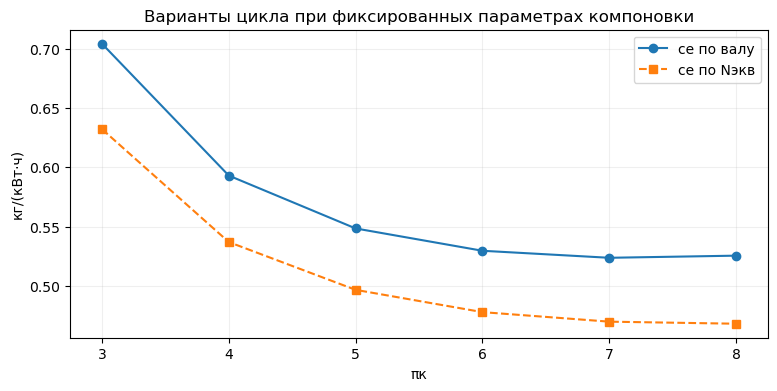

In [41]:
cycle_variants_df=cycle_variants(GEOMETRY,C)
display(cycle_variants_df.round(6))
equivalent=propeller_equivalent(P0)
display(pd.DataFrame([equivalent]).T)
fig,ax=plt.subplots(figsize=(9,4))
valid=cycle_variants_df.dropna(subset=['ce_shaft_kg_kWh'])
ax.plot(valid.pi_k,valid.ce_shaft_kg_kWh,'o-',label='ce по валу')
ax.plot(valid.pi_k,valid.ce_equiv_kg_kWh,'s--',label='ce по Nэкв')
ax.set(xlabel='πк',ylabel='кг/(кВт·ч)',title='Варианты цикла при фиксированных параметрах компоновки');ax.grid(alpha=.2);ax.legend();plt.show()

## 23. Радиальное уточнение с замыканием расхода

Внутри фиксированного кольца СА скорость выбранного закона нормируется по интегралу `G=∫2πrρca dr`. Сохраняются полная энтальпия и полное давление за СА среднелинейной модели. Изменение скорости на среднем радиусе относительно исходной модели показывается явно.

Линии тока между СА и РК сопоставляются по накопленному расходу. На выходе РК одновременно выполняются:

- работа Эйлера вдоль каждой массовой линии;
- постоянная полная энтальпия за РК до добавочных потерь;
- радиальное равновесие `dh/dr=cu²/r`;
- заданное среднее статическое давление и интегральный расход.

Это осесимметричное предварительное уточнение. Оно не доказывает постоянство эмпирического ψ по высоте: требуемый ψ(r) рассчитывается и сравнивается с исходным. Вязкость, вторичные течения, зазор и неоднородное смешение по радиусу не решены. Отдельная радиальная ветка не подменяет автоматически энергетический цикл.

,Ступень,"ΔG СА, кг/с","ΔG РК, кг/с","max ΔLu, Дж/кг",Отн. ошибка радиального равновесия,"Нормировка скорости СА, %",max Mc1,max Mw2,ψ требуемый min,ψ требуемый max,Δмасштаба сетка/Гаусс
0,1,6.661338e-16,-6.661338e-16,0.000019,0.000016,0.570506,0.926866,0.640683,0.913592,0.929862,0.000001
1,2,1.972866e-13,-1.776357e-15,0.000039,0.000052,1.090554,0.980011,0.693194,0.938543,0.951824,0.000002


,Ступень,mass_fraction,in_r,in_T,in_p,in_ca,in_cu,in_c,in_w,in_beta,...,out_p,out_ca,out_cu,out_c,out_w,out_beta,out_alpha,out_M_c,out_M_w,out_psi_required
0,1,0.00,0.089520,1102.972315,252887.579639,116.180311,586.753446,598.145025,298.652091,22.893259,...,224755.770076,112.894482,41.031604,120.119760,364.418213,18.046801,70.026278,0.187727,0.569526,0.913592
1,1,0.25,0.093305,1114.348685,263999.343578,111.642444,563.835542,574.782180,263.822594,25.035081,...,224810.621015,113.214583,38.200422,119.485630,376.250301,17.511810,71.354779,0.186731,0.588001,0.918300
2,1,0.50,0.096971,1124.136823,273870.705569,107.578118,543.309195,553.857322,232.175535,27.603527,...,224854.090141,113.479735,35.759919,118.980770,387.779092,17.016089,72.509234,0.185938,0.606005,0.922541
3,1,0.75,0.100537,1132.663169,282709.213837,103.902961,524.748299,534.936073,203.324294,30.731869,...,224889.181125,113.703167,33.627911,118.571701,399.017786,16.556322,73.524326,0.185296,0.623557,0.926378
4,1,1.00,0.104020,1140.166156,290675.237126,100.553640,507.832992,517.692363,177.057404,34.604993,...,224917.952627,113.893868,31.745373,118.235282,409.982308,16.129059,74.425375,0.184767,0.640683,0.929862
5,2,0.00,0.085777,954.046890,117193.799903,175.323391,564.012602,590.633987,318.094980,33.447097,...,106336.123760,170.193233,29.208766,172.681465,363.275473,27.936736,80.261700,0.288650,0.607242,0.938543
6,2,0.25,0.090621,968.210236,124465.686374,166.756728,536.453780,561.774389,276.851371,37.037409,...,106354.367245,170.622879,24.781193,172.413103,376.531931,26.945536,81.736170,0.288195,0.629388,0.942432
7,2,0.50,0.095250,979.853640,130709.974510,159.351702,512.631927,536.828145,241.197892,41.350922,...,106366.065826,170.935810,21.162321,172.240814,389.534143,26.028698,82.942537,0.287904,0.651114,0.945909
8,2,0.75,0.099705,989.628758,136143.645646,152.844992,491.699942,514.908171,210.419809,46.584297,...,106373.748944,171.169392,18.136745,172.127577,402.262531,25.183370,83.951629,0.287712,0.672384,0.949023
9,2,1.00,0.104020,997.973363,140923.763054,147.053263,473.068043,495.396847,184.224617,52.961229,...,106378.874692,171.346695,15.562728,172.051993,414.714779,24.403972,84.810295,0.287584,0.693194,0.951824


Числа Маха у втулки, в среднем массовом и периферийном сечениях:


,Ступень,Сечение,"r входа РК, мм","r выхода РК, мм",Mc1 = c1/a1,Mw1 = w1/a1,Mc2 = c2/a2,Mw2 = w2/a2
0,1,Втулка,89.520297,87.748650,0.926866,0.462782,0.187727,0.569526
1,1,Среднее (50% расхода),96.970616,96.247379,0.850566,0.356555,0.185938,0.606005
2,1,Периферия,104.019758,104.019758,0.789723,0.270095,0.184767,0.640683
3,2,Втулка,85.777156,83.805587,0.980011,0.527800,0.288650,0.607242
4,2,Среднее (50% расхода),95.249637,94.472020,0.879609,0.395210,0.287904,0.651114
5,2,Периферия,104.019758,104.019758,0.804746,0.299263,0.287584,0.693194


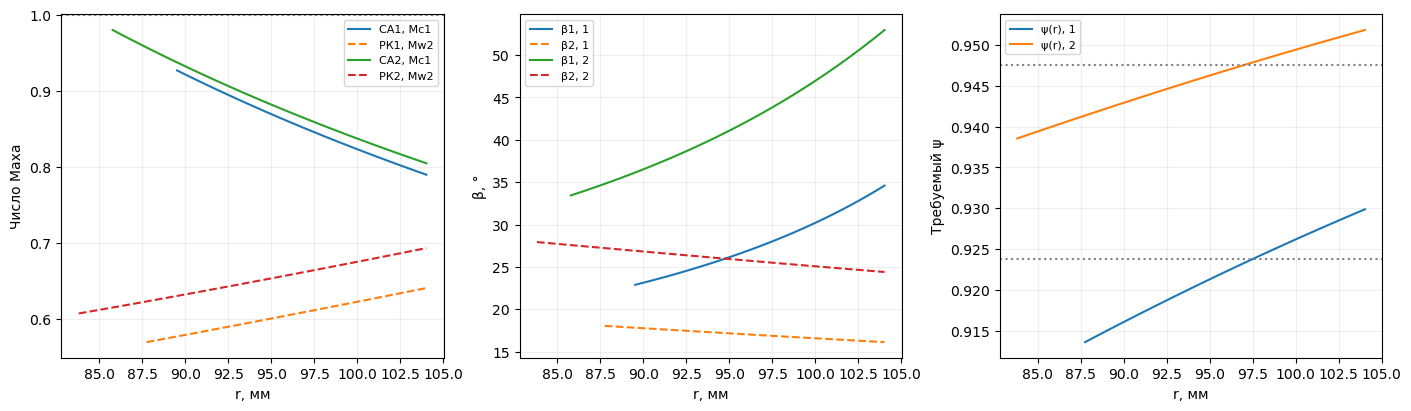

In [42]:
RADIAL_RESULTS=[radial_stage(st,GEOMETRY,C,RADIAL_LAW,points=101) for st in P0['stages']]
radial_checks=[];radial_sections=[]
for i,(st,rd) in enumerate(zip(P0['stages'],RADIAL_RESULTS),1):
    quick=stator_radial_screen(st,C)
    radial_checks.append({'Ступень':i,'ΔG СА, кг/с':rd['mass_in_residual'],'ΔG РК, кг/с':rd['mass_out_residual'],
        'max ΔLu, Дж/кг':rd['euler_max_residual'],'Отн. ошибка радиального равновесия':rd['radial_eq_relative'],
        'Нормировка скорости СА, %':rd['inlet_mean_velocity_change_pct'],
        'max Mc1':rd['inlet']['M_c'].max(),'max Mw2':rd['outlet']['M_w'].max(),
        'ψ требуемый min':rd['psi_required_min'],'ψ требуемый max':rd['psi_required_max'],
        'Δмасштаба сетка/Гаусс':rd['scale']-quick['scale']})
    tab=rd['sections'].copy();tab.insert(0,'Ступень',i);radial_sections.append(tab)
radial_checks_df=pd.DataFrame(radial_checks);radial_sections_df=pd.concat(radial_sections,ignore_index=True)
display(radial_checks_df);display(radial_sections_df)
# Явная трёхсеченная ведомость: pandas не скрывает нужные столбцы многоточием.
mach_section_rows=[]
for stage_number,rd in enumerate(RADIAL_RESULTS,1):
    for j,label in ((0,'Втулка'),(2,'Среднее (50% расхода)'),(4,'Периферия')):
        section=rd['sections'].iloc[j]
        mach_section_rows.append({'Ступень':stage_number,'Сечение':label,
            'r входа РК, мм':section['in_r']*1000,'r выхода РК, мм':section['out_r']*1000,
            'Mc1 = c1/a1':section['in_M_c'],'Mw1 = w1/a1':section['in_M_w'],
            'Mc2 = c2/a2':section['out_M_c'],'Mw2 = w2/a2':section['out_M_w']})
MACH_SECTIONS=pd.DataFrame(mach_section_rows)
print('Числа Маха у втулки, в среднем массовом и периферийном сечениях:')
with pd.option_context('display.max_columns',None,'display.width',180):
    display(MACH_SECTIONS.round(6))

assert radial_checks_df['max Mc1'].max()<1
assert radial_checks_df['max Mw2'].max()<1
assert radial_checks_df['ΔG СА, кг/с'].abs().max()<1e-8
assert radial_checks_df['ΔG РК, кг/с'].abs().max()<1e-8
assert radial_checks_df['max ΔLu, Дж/кг'].max()<.002
assert radial_checks_df['Отн. ошибка радиального равновесия'].max()<.005
assert radial_checks_df['Δмасштаба сетка/Гаусс'].abs().max()<1e-4
fig,axs=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for i,rd in enumerate(RADIAL_RESULTS,1):
    axs[0].plot(rd['inlet'].r*1000,rd['inlet']['M_c'],label=f'СА{i}, Mc1')
    axs[0].plot(rd['outlet'].r*1000,rd['outlet']['M_w'],'--',label=f'РК{i}, Mw2')
    axs[1].plot(rd['inlet'].r*1000,rd['inlet'].beta,label=f'β1, {i}')
    axs[1].plot(rd['outlet'].r*1000,rd['outlet'].beta,'--',label=f'β2, {i}')
    axs[2].plot(rd['outlet'].r*1000,rd['outlet'].psi_required,label=f'ψ(r), {i}')
axs[0].axhline(1,color='grey',ls=':');
for st in P0['stages']:axs[2].axhline(st['psi'],color='grey',ls=':')
for ax,lab in zip(axs,['Число Маха','β, °','Требуемый ψ']):ax.set(xlabel='r, мм',ylabel=lab);ax.grid(alpha=.2);ax.legend(fontsize=8)
plt.show()

## 24. Непрерывный меридиональный канал и входные сечения

Предварительный контур сохраняет Dк=const. Узлы — входы/выходы СА и РК, сечения 2+ и срез сопла. Площади определяются по актуальным состояниям, втулка — по кольцевой геометрии. Свободные осевые зазоры и осевые ширины профилей хранятся отдельно.

Ширины сечений меняются по высоте; ширина охватывающего венца не меньше максимальной ширины сечения и длины, требуемой ограничением угла стенки. Выходные кромки выровнены в одной плоскости, входные расположены по `x_le_m`, `x_te_m`; это квазитрёхмерная полосочная модель, не решение 3D-течения у пространственных кромок.

В свободном зазоре СА→РК принято неизменное кольцо и состояние выхода СА. Вход СА1 задан ca0=0,75ca1; вход СА2 перенесён через μ без добавления воздуха. Импульс и распределённые потери переходного канала не рассчитаны. До входа в сопло узлы соединены отрезками — проточная часть показана ломаной. Между последним сечением 2+ и срезом сопла построен кубический сплайн с нулевыми концевыми наклонами. Ограничение угла стенки ≤15° само по себе не доказывает отсутствие отрыва.

,station,x,rhub,rtip,A,G,T,p,ca,source,continuity_residual
0,Вход СА1,0.000000,0.091684,0.10402,0.007584,0.803133,1247.371496,472244.364067,80.385870,"Выбрана ca0=0,75·ca1",0.000000e+00
1,Выход СА1,0.023456,0.089520,0.10402,0.008816,0.803133,1125.072647,274829.753734,107.181160,Выходная кромка венца; ширина НЕ содержит зазор,1.110223e-16
2,Вход РК1,0.028851,0.089520,0.10402,0.008816,0.803133,1125.072647,274829.753734,107.181160,Отдельная входная кромка РК после свободного о...,1.110223e-16
3,Кромка РК1,0.050803,0.087749,0.10402,0.009803,0.803133,1083.253996,224850.579802,113.440061,Выходная кромка венца; ширина НЕ содержит зазор,-1.110223e-16
4,"После потерь РК1, 2+",0.056803,0.087558,0.10402,0.009908,0.803133,1094.876283,224850.579802,113.440061,Сечение смешения потерь вне ширины РК,0.000000e+00
5,Вход СА2,0.070803,0.085409,0.10402,0.011075,0.803133,1096.014062,223730.609027,102.096055,Адиабатический переход без охлаждающего воздух...,0.000000e+00
6,Выход СА2,0.095026,0.085777,0.10402,0.010877,0.803133,981.669017,131705.715428,158.164446,Выходная кромка венца; ширина НЕ содержит зазор,0.000000e+00
7,Вход РК2,0.100597,0.085777,0.10402,0.010877,0.803133,981.669017,131705.715428,158.164446,Отдельная входная кромка РК после свободного о...,0.000000e+00
8,Кромка РК2,0.114398,0.083806,0.10402,0.011928,0.803133,939.125093,106365.000000,170.859411,Выходная кромка венца; ширина НЕ содержит зазор,-1.110223e-16
9,"После потерь РК2, 2+",0.120398,0.083596,0.10402,0.012038,0.803133,947.795227,106365.000000,170.859411,Сечение смешения потерь вне ширины РК,0.000000e+00


,"x входа, мм","x выхода, мм","b_ax, мм","зазор после, мм","хорда среднего сечения, мм",Z
Венец,,,,,,
СА1,0.0000,23.4562,23.4562,5.3949,None,None
РК1,28.8511,50.8028,21.9517,20.0000,None,None
СА2,70.8028,95.0256,24.2228,5.5712,None,None
РК2,100.5968,114.3975,13.8007,NaN,None,None


,upstream,downstream,"x начало, мм","x конец, мм","δa, мм"
0,СА1,РК1,23.456184,28.851106,5.394922
1,РК1,СА2,50.802800,70.802800,20.000000
2,СА2,РК2,95.025594,100.596837,5.571243


Максимальный угол внутренней стенки, °: 12.821518805457123
Длина предварительного канала, мм: 145.39750332473


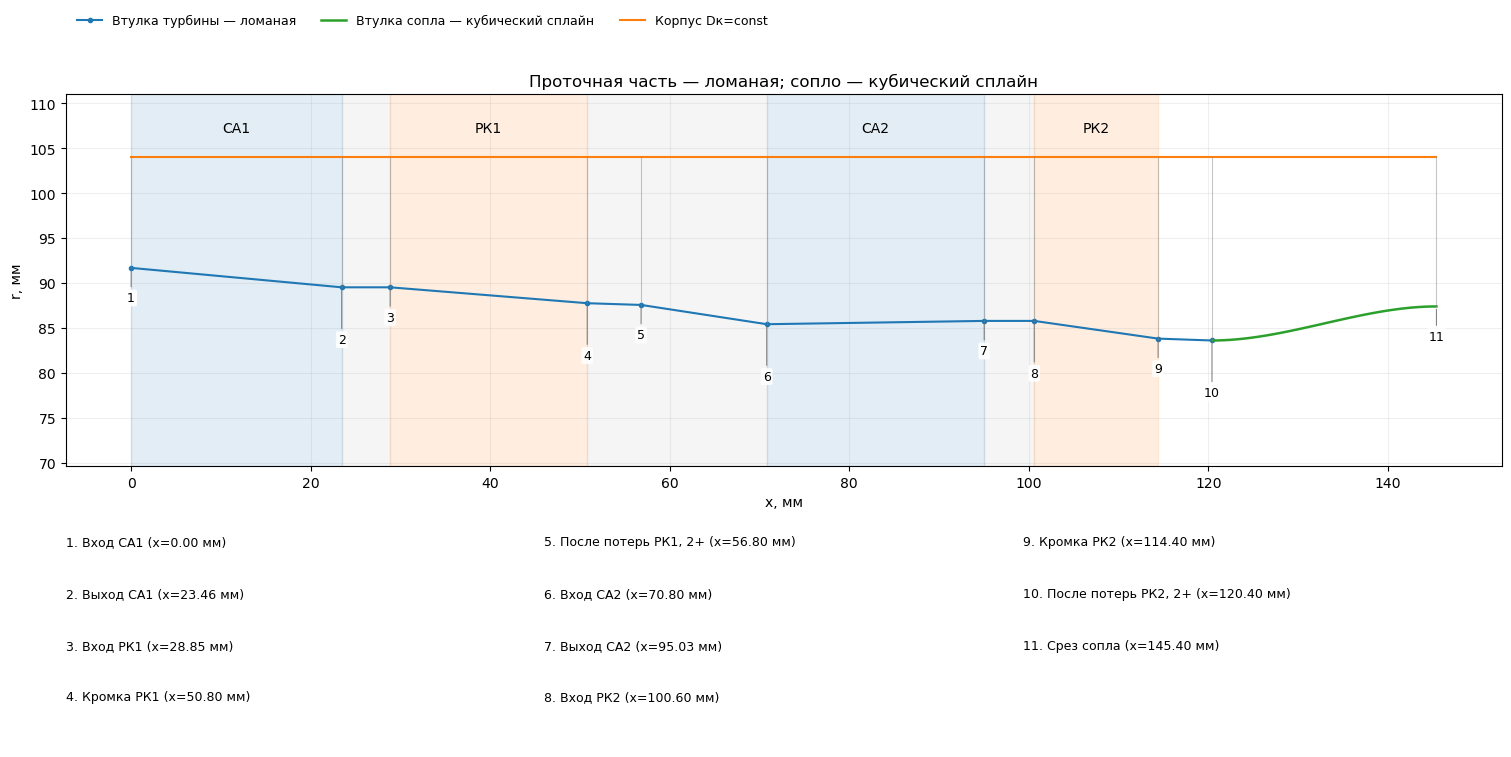

In [43]:
CHANNEL=meridional_channel(P0,RADIAL_RESULTS,row_widths={name:d['bax_m'] for name,d in PROFILE_ROW_DESIGN.items()})
channel_stations_df=CHANNEL['stations'];channel_contour_df=CHANNEL['contour']
display(channel_stations_df)
drawing_df=drawing_schedule(CHANNEL)
display(drawing_df.round(4))
gap_df=CHANNEL['gaps'].copy()
for col in ['x_start','x_end','delta_ax']:gap_df[col]*=1000
display(gap_df.rename(columns={'x_start':'x начало, мм','x_end':'x конец, мм','delta_ax':'δa, мм'}))
print('Максимальный угол внутренней стенки, °:',CHANNEL['max_angle_deg'])
print('Длина предварительного канала, мм:',channel_stations_df.x.iloc[-1]*1000)
assert channel_stations_df.continuity_residual.abs().max()<1e-8
assert CHANNEL['max_angle_deg']<=15.+1e-8
assert np.all(channel_contour_df.rhub>0)
# Подписи сечений вынесены в отдельную ведомость под рисунком.
fig=plt.figure(figsize=(15,7.5),layout='constrained')
grid=fig.add_gridspec(2,1,height_ratios=[3.2,1.6])
ax=fig.add_subplot(grid[0]);notes=fig.add_subplot(grid[1]);notes.axis('off')
body=channel_stations_df.iloc[:-1]
nozzle=channel_contour_df.loc[channel_contour_df.kind=='Сопло: кубический сплайн']
ax.plot(body.x*1000,body.rhub*1000,'o-',markersize=3,label='Втулка турбины — ломаная')
ax.plot(nozzle.x*1000,nozzle.rhub*1000,color='tab:green',lw=1.8,label='Втулка сопла — кубический сплайн')
ax.plot(channel_stations_df.x*1000,channel_stations_df.rtip*1000,color='tab:orange',label='Корпус Dк=const')
for _,blade in CHANNEL['blade_rows'].iterrows():
    ax.axvspan(blade.x_le*1000,blade.x_te*1000,alpha=.13,color='tab:blue' if blade.kind=='СА' else 'tab:orange')
    ax.text((blade.x_le+blade.x_te)*500,blade.rtip*1000+2.5,blade['name'],ha='center',va='bottom',fontsize=10)
for _,gap in CHANNEL['gaps'].iterrows():
    ax.axvspan(gap.x_start*1000,gap.x_end*1000,color='grey',alpha=.08)
for number,(_,row) in enumerate(channel_stations_df.iterrows(),1):
    ax.plot([row.x*1000]*2,[row.rhub*1000,row.rtip*1000],color='grey',alpha=.45,lw=.8)
    # Чередующиеся строки и короткие выноски разделяют близкие сечения.
    ax.annotate(str(number),(row.x*1000,row.rhub*1000),xytext=(0,-17 if number%2 else -33),
                textcoords='offset points',ha='center',va='top',fontsize=9,
                arrowprops=dict(arrowstyle='-',color='0.45',lw=.7),
                bbox=dict(boxstyle='round,pad=.15',fc='white',ec='none',alpha=.9))
    column=(number-1)//4;line=(number-1)%4
    notes.text(column/3,.94-line*.23,f'{number}. {row.station} (x={row.x*1000:.2f} мм)',
               transform=notes.transAxes,ha='left',va='top',fontsize=9)
ax.set(xlabel='x, мм',ylabel='r, мм',title='Проточная часть — ломаная; сопло — кубический сплайн',
       ylim=(channel_stations_df.rhub.min()*1000-14,channel_stations_df.rtip.max()*1000+7))
ax.set_aspect('equal',adjustable='box');ax.grid(alpha=.2)
ax.legend(loc='lower left',bbox_to_anchor=(0,1.15),ncol=3,fontsize=9,frameon=False)
plt.show()


## 25. Раздел 8 учебника: построение профилей по пяти сечениям

Реализация с.78–84, рис.28–30 книги 2006 года. Пять сечений каждого из четырёх венцов берутся по массовым линиям радиального расчёта. В СА1 вход осевой; в СА2 угол переносится отдельно для каждой линии из РК1 с выбранной моделью перехода (перенос углового момента с μ, без подмешивания охлаждающего воздуха). Это не решение вязкого переходного течения.

1. **Углы потока → углы лопатки.** Использованы δ и ограничения применимости с.78. Внутри прямо приведённых интервалов интерполируются середины книжных диапазонов; вне них δ=0,5° для СА и 1° для РК — явно отмеченное проектное допущение, не универсальная корреляция.
2. **Касательные EM и MA, точка M.** Начальная установка оценивается по γ=70−0,127(β1−β2)−0,0041(β1−β2)². Положение M затем может смещаться при согласовании решётки, как на с.83; итоговые хорда и γ измеряются из построенной геометрии.
3. **Входная окружность и выходной клин.** На входе r1=0,035bax. На выходе выбран прямой срез s2=0,5 мм, перпендикулярный среднему направлению выхода; боковые поверхности сходятся клином γ2=2…5°. Круглая заглушка r2=s2/2 удалена: на с.80 учебника задана толщина s2=0,5…1,6 мм, а не обязательный радиус выходной окружности. Нулевая толщина по условной острой схеме не подставляется в расчёт. Хорда измеряется от входной точки до середины выходного среза. Угол входного клина γ1=10…45°, его деление на стороны — как на с.81.
4. **Спинка и корытце.** Основная часть каждой поверхности — кубическая Bezier-кривая в треугольнике касательных. Входная окружность соединяется с ней квинтическим участком Hermite: совпадают положение, направление касательной и кривизна κ (G2). Выбирается наиболее короткое допустимое сопряжение; производная dκ/ds на переходе к телу не задаётся как дополнительное ограничение, чтобы без необходимости не менять толщину всего профиля. Положение точек и производные не проецируются и не сглаживаются после построения. Проверяются отсутствие паразитных перегибов и вписанность входной окружности: поверхности не заходят внутрь её диска. У корытца сохраняется один естественный переход от выпуклой кромки к вогнутому телу. На углах выходного среза оставлены острые разделительные кромки; круглого замыкания нет. Это численная реализация требования плавной кривизны на с.82, а не формула учебника; длина сопряжения и проверяемый предел |κ|r1≤1,2 — проектные численные ограничения.
5. **Шаг и Z.** Выведены книжная оценка t/b (с.82), фактический шаг и целые взаимно простые соседние Z. Обычный ориентир 0,70…0,85; уменьшение до 0,55…0,65 допускается книгой для корневых решёток. Утолщение кромок не скрывается уменьшением s2.
6. **Проверка канала.** Расстояния считаются до отрезков контуров, не только до вершин. Отдельно измеряются выходное горло и глобальный минимальный зазор. Строятся действительно вписанные окружности до выходного горла; a′=a·l/lвх и местное расширение проверяются без произвольного удаления начала канала. Угол выхода β2р=(lгор/l2)·arcsin(aгор/t), множитель высот находится **вне arcsin**, как на с.84.

`PROFILE_ROW_DESIGN` хранит выбранные ширины, Z и параметры каждого сечения. Контрольные допуски — проектный выбор: ошибка горлового угла ≤2°, s2/a ≤1,2 книжного ориентира, местное расширение ≤1,02, отклонение cmax/b от ориентира ≤0,015. Эти допуски не названы нормами учебника. Изменение формы не подтверждает принятые φ/ψ или прочность.

**Отрисовка:** только СА и РК последней ступени, по три отдельных сечения: корневое, среднее (50% расхода), периферийное. Расчёт и проверки сохраняют все пять массовых сечений. Оси повёрнуты как на рис.28, масштаб равный по обеим координатам. Средние решётки и приведённые каналы показаны отдельно.

**Основное перо:** реальные площади обоих РК убывают по пяти радиусам; целевое Aкор/Aпериф=1,3. Это выбранная достижимая конусность при сохранённых ограничениях горла, кромки, толщины и шага; книжные 3,5 не объявляются выполненными. Подбираются формы, реальные ширины и общий абсолютный масштаб площадей, а не отдельный декоративный кандидат. Абсолютная площадь корня не задана в ТЗ: если выбранный масштаб несовместим с периферийным сечением, весь пятисеченчатый закон площади изменяется совместно при сохранённой конусности. История таких изменений записана в `PROFILE_ROW_DESIGN[имя]["area_scale_adjustments"]`; критерии приёмки и точность согласования площади не ослабляются. Каждый итоговый контур проверяется по прежним геометрическим критериям.

Локальная окружная ось построения СА направлена против вращения, РК — по вращению. Отдельные картинки профилей не являются общей физической развёрткой без соответствующего отражения.


**Числа лопаток:** для каждого СА допускается только нечётное Z, для каждого РК — только чётное. Числа строго возрастают по тракту: **ZСА1 < ZРК1 < ZСА2 < ZРК2**. Поэтому все четыре Z различны; соседние венцы остаются взаимно простыми. При изменении Z повторно согласуются действительные профили и потери.


**Выбор Z в v15:** числа не назначаются навсегда в реестре. Начальные размеры через высоту и книжное Z, соседние чётные/нечётные комбинации, реальные проверки и причины отказов приведены в §10. Сохранённый реестр служит только численным начальным приближением формы. Для более компактного венца необходимо одновременно выдержать размер горла, неизменную кромку 0,5 мм, относительный шаг, диффузорность и ресурс. Приближённая оценка Z по корневой кромке — диагностический ориентир, не доказанный точный предел.


Численный подбор не использует закрытое горло как плоский штрафной старт: при необходимости сначала строится небольшой набор действительных книжных контуров для начального приближения. Поиск ведётся на более грубом разрешении; **каждый принимаемый результат заново строится и проверяется на полном разрешении 161**, включая площадь, горло и диффузорность. При расхождении точности площади поиск повышает разрешение. Геометрические допуски финальной проверки не ослабляются. Начальные формы сопоставляются по близости углов треугольника скоростей, а не по одинаковому номеру сечения другого режима.

Горло выходного канала измеряется до острой кромки корытца соседней лопатки; минимальный зазор и вписанные окружности дополнительно проверяются по двум замкнутым материальным контурам. Модель потерь по s2/горлу остаётся приближённой: отдельная экспериментальная поправка на базовое давление за плоским срезом не назначалась.


,Венец,Сечение,"r, мм","βвх металл, °","βвых поток, °","βвых металл, °","δ, °","γ, °","γ1, °","γ2, °",...,s2/a ориентир,"s2 по относительному ориентиру, мм",Местное расширение a′/min(a′выше),Пересечения,Самопересечение профиля,"Re·μ, кг/(м·с)","Площадь сечения, мм²",Принят по геометрии,Отставание: основание,Статус
0,СА1,0,89.520297,90.000000,11.200000,10.700000,0.500000,24.438639,26.381134,3.0,...,0.055,0.476771,1.000000,False,False,24.526902,206.793994,True,проектный выбор вне приведённых на с.78 интерв...,Геометрические условия выполнены; потери и про...
1,СА1,1,93.304631,90.000000,11.200000,10.700000,0.500000,24.597216,26.394066,3.0,...,0.055,0.496778,1.000000,False,False,25.397937,222.880989,True,проектный выбор вне приведённых на с.78 интерв...,Геометрические условия выполнены; потери и про...
2,СА1,2,96.970616,90.000000,11.200000,10.700000,0.500000,24.631636,26.446064,3.0,...,0.055,0.516299,1.000000,False,False,26.146457,240.505045,True,проектный выбор вне приведённых на с.78 интерв...,Геометрические условия выполнены; потери и про...
3,СА1,3,100.537439,90.000000,11.200000,10.700000,0.500000,23.352897,26.717148,3.0,...,0.055,0.535413,1.000000,False,False,26.817131,256.625817,True,проектный выбор вне приведённых на с.78 интерв...,Геометрические условия выполнены; потери и про...
4,СА1,4,104.019758,90.000000,11.200000,10.700000,0.500000,22.787602,26.551455,3.0,...,0.055,0.553856,1.000000,False,False,27.426213,270.796214,True,проектный выбор вне приведённых на с.78 интерв...,Геометрические условия выполнены; потери и про...
5,РК1,0,87.748650,22.893259,18.046801,17.046801,1.000000,34.161671,23.819864,3.0,...,0.070,0.610787,1.007872,False,False,10.082297,52.553888,True,проектный выбор вне приведённых на с.78 интерв...,Геометрические условия выполнены; потери и про...
6,РК1,1,92.101898,25.035081,17.511810,16.511810,1.000000,36.923843,24.512564,3.0,...,0.070,0.623579,1.016366,False,False,9.818859,49.016194,True,проектный выбор вне приведённых на с.78 интерв...,Геометрические условия выполнены; потери и про...
7,РК1,2,96.247379,27.603527,17.016089,16.016089,1.000000,31.324490,32.552784,3.0,...,0.070,0.636436,1.000000,False,False,10.213027,45.857390,True,проектный выбор вне приведённых на с.78 интерв...,Геометрические условия выполнены; потери и про...
8,РК1,3,100.212665,30.731869,16.556322,15.556322,1.000000,29.606186,36.185870,3.0,...,0.070,0.644983,1.000000,False,False,11.074579,42.986085,True,проектный выбор вне приведённых на с.78 интерв...,Геометрические условия выполнены; потери и про...
9,РК1,4,104.019758,34.604993,16.129059,15.129059,1.000000,31.128594,35.780778,3.0,...,0.070,0.652170,1.000000,False,False,11.512035,40.463493,True,проектный выбор вне приведённых на с.78 интерв...,Геометрические условия выполнены; потери и про...


Построено профилей: 20 из 20; геометрические условия выполнены: 20


,"x входа, мм","x выхода, мм","b_ax, мм","зазор после, мм","хорда среднего сечения, мм",Z
Венец,,,,,,
СА1,0.00000,23.45618,23.45618,5.39492,55.68976,13
РК1,28.85111,50.80280,21.95169,20.00000,36.46918,20
СА2,70.80280,95.02559,24.22279,5.57124,34.16388,21
РК2,100.59684,114.39750,13.80067,NaN,18.22139,40


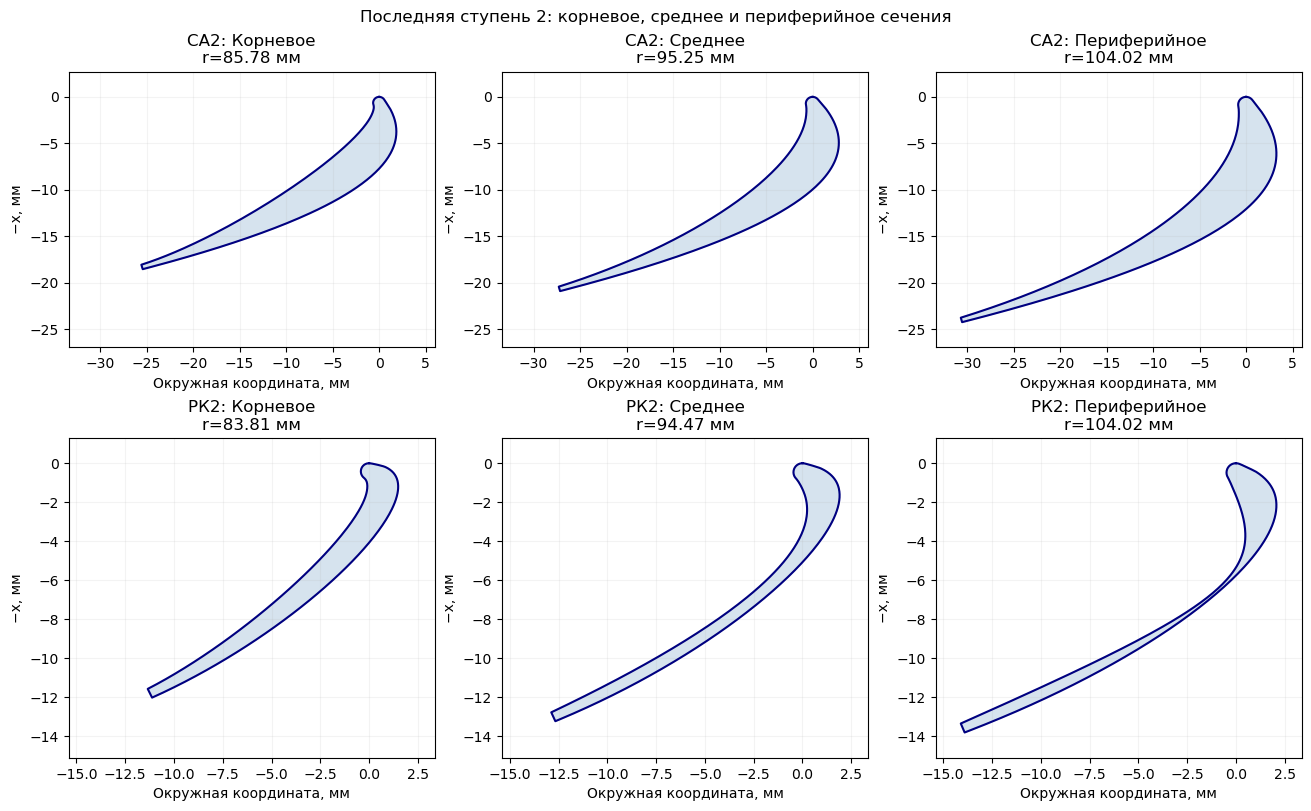

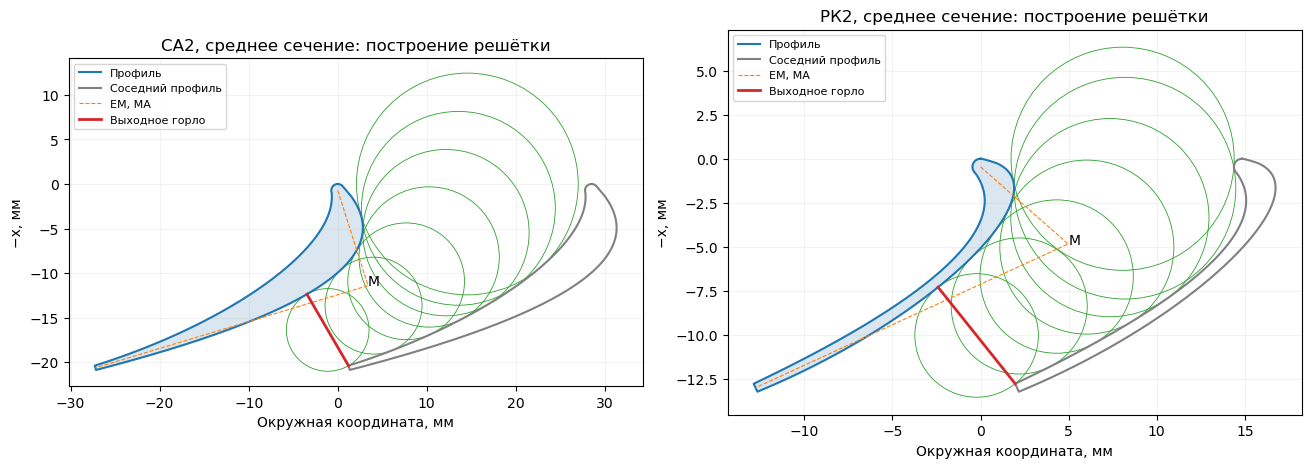

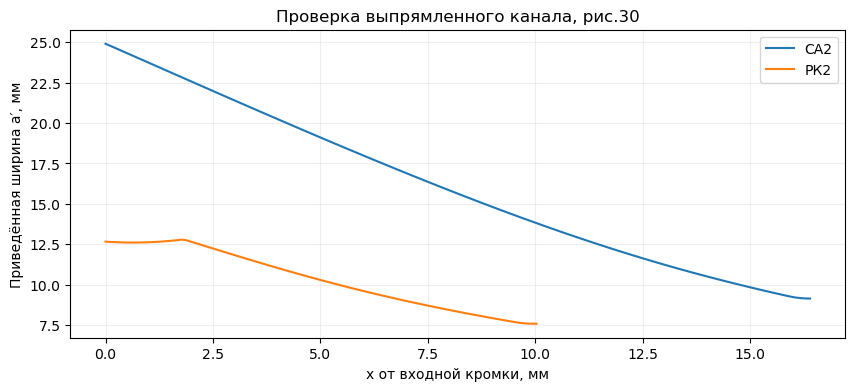

Координаты доступны в profile_coordinates; экспорт не выполняется автоматически.


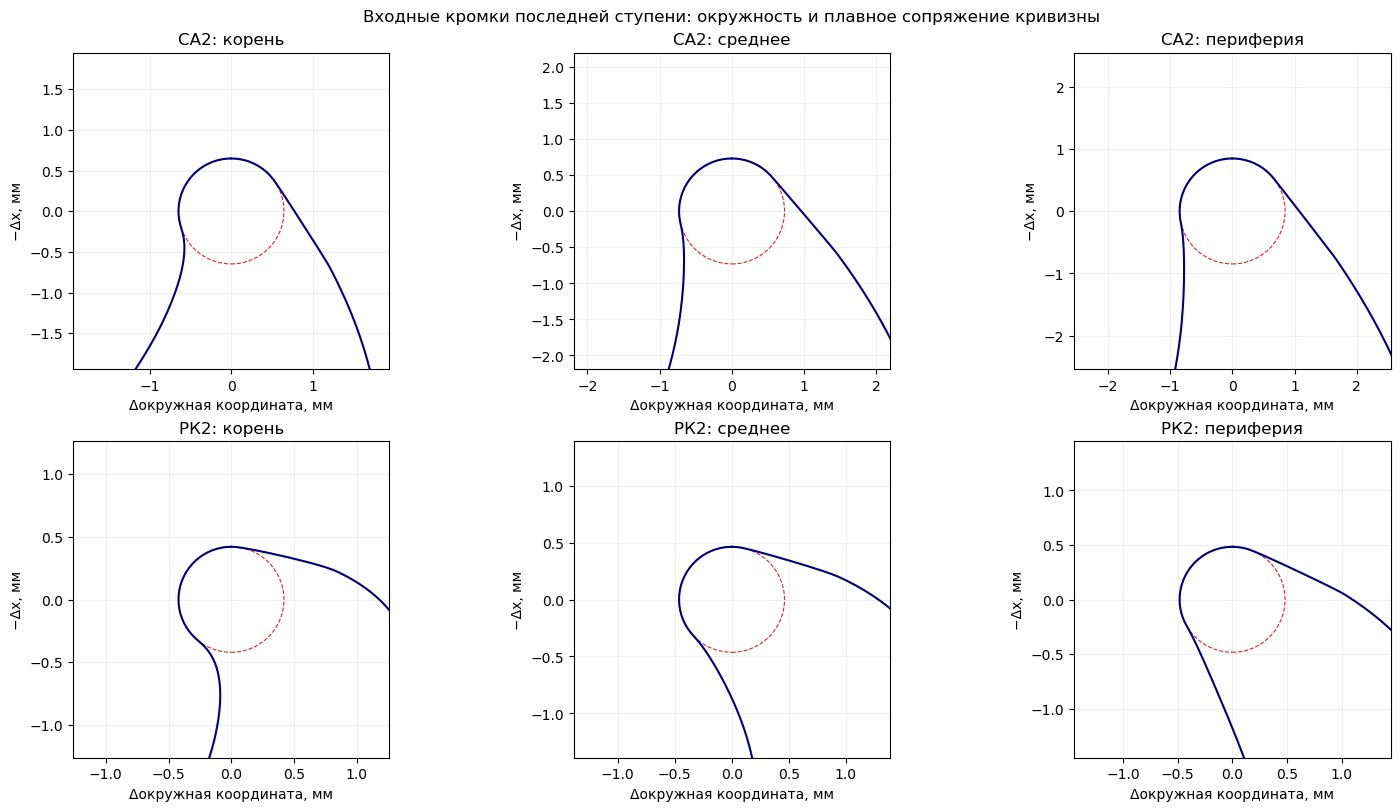

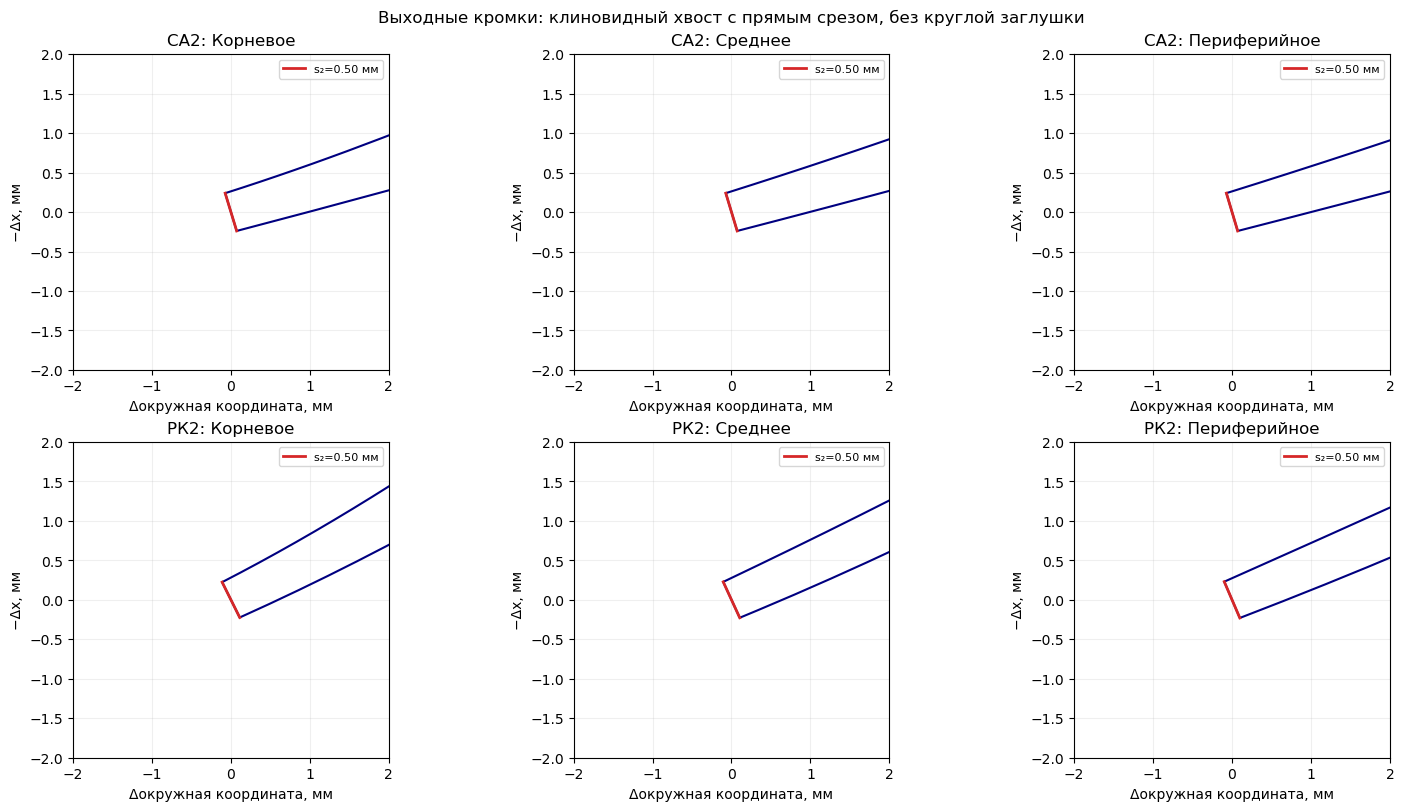

In [44]:
profile_review_df,PROFILES=profile_cascades(P0,RADIAL_RESULTS,CHANNEL,te=BOOK_DEFAULTS['trailing_edge_m'])
display(profile_review_df.round(6))
print('Построено профилей:',len(PROFILES),'из 20; геометрические условия выполнены:',
      int(profile_review_df['Принят по геометрии'].sum()))
drawing_df=drawing_schedule(CHANNEL,PROFILES);display(drawing_df.round(5))
LAST_STAGE=len(P0['stages'])
PLOT_ROWS=[f'СА{LAST_STAGE}',f'РК{LAST_STAGE}']
PLOT_SECTIONS=[(0,'Корневое'),(2,'Среднее'),(4,'Периферийное')]
# Только представление сокращено до трёх сечений; расчётные данные не удаляются.
fig,axs=plt.subplots(2,3,figsize=(13,8),layout='constrained')
profile_plot_bounds={}
for name in PLOT_ROWS:
    all_points=np.vstack([PROFILES[(name,j)]['polygon'] for j,_ in PLOT_SECTIONS])*1000
    pad=.08*max(np.ptp(all_points[:,0]),np.ptp(all_points[:,1]))
    profile_plot_bounds[name]=(all_points[:,1].min()-pad,all_points[:,1].max()+pad,-all_points[:,0].max()-pad,-all_points[:,0].min()+pad)
for row_index,name in enumerate(PLOT_ROWS):
    for column,(j,label) in enumerate(PLOT_SECTIONS):
        ax=axs[row_index,column];pr=PROFILES[(name,j)];poly=pr['polygon']
        # Поворот осей, без деформации масштаба: как на рис.28, поток сверху вниз.
        ax.fill(poly[:,1]*1000,-poly[:,0]*1000,color='steelblue',alpha=.22)
        ax.plot(poly[:,1]*1000,-poly[:,0]*1000,color='navy',lw=1.5)
        ax.set(title=f'{name}: {label}\nr={pr["radius"]*1000:.2f} мм',
               xlabel='Окружная координата, мм',ylabel='−x, мм')
        ax.set_aspect('equal');ax.grid(alpha=.15)
        xmin,xmax,ymin,ymax=profile_plot_bounds[name];ax.set_xlim(xmin,xmax);ax.set_ylim(ymin,ymax)
fig.suptitle(f'Последняя ступень {LAST_STAGE}: корневое, среднее и периферийное сечения')
plt.show()
fig,axs=plt.subplots(1,2,figsize=(13,7),layout='constrained')
for ax,name in zip(axs,PLOT_ROWS):
    pr=PROFILES[(name,2)];poly=pr['polygon']
    ax.fill(poly[:,1]*1000,-poly[:,0]*1000,color='steelblue',alpha=.2)
    ax.plot(poly[:,1]*1000,-poly[:,0]*1000,label='Профиль')
    ax.plot((poly[:,1]+pr['pitch'])*1000,-poly[:,0]*1000,color='grey',label='Соседний профиль')
    c0=pr['leading_circle_center'];c1=pr['trailing_edge_midpoint'];M=pr['M']
    construction=np.vstack([c0,M,c1])
    ax.plot(construction[:,1]*1000,-construction[:,0]*1000,'--',lw=.8,label='EM, MA')
    ax.annotate('M',(M[1]*1000,-M[0]*1000))
    for center,width in zip(pr['inscribed_circle_centers'][::16],pr['local_width'][::16]):
        ax.add_patch(plt.Circle((center[1]*1000,-center[0]*1000),width*500,fill=False,color='tab:green',lw=.6))
    contacts=pr['throat_contacts']*1000
    ax.plot(contacts[:,1],-contacts[:,0],color='tab:red',lw=2,label='Выходное горло')
    ax.set(title=f'{name}, среднее сечение: построение решётки',xlabel='Окружная координата, мм',ylabel='−x, мм')
    ax.set_aspect('equal');ax.grid(alpha=.15);ax.legend(fontsize=8)
plt.show()
fig,ax=plt.subplots(figsize=(10,4))
for name in PLOT_ROWS:
    pr=PROFILES[(name,2)]
    ax.plot(pr['local_channel_x']*1000,pr['reduced_width']*1000,label=name)
ax.set(xlabel='x от входной кромки, мм',ylabel='Приведённая ширина a′, мм',title='Проверка выпрямленного канала, рис.30')
ax.grid(alpha=.2);ax.legend();plt.show()
profile_coordinates={f'{name}_{j}':pd.DataFrame(pr['polygon']*1000,columns=['x_mm','y_mm']) for (name,j),pr in PROFILES.items()}
print('Координаты доступны в profile_coordinates; экспорт не выполняется автоматически.')
# Регрессия: правильная чётность и взаимная простота не разрешают спад Z.
_invalid_order={name:{'Z':z} for name,z in zip(('СА1','РК1','СА2','РК2'),(13,16,15,26))}
try:
    validate_cascade_counts(_invalid_order)
except Bad:
    pass
else:
    raise AssertionError('Принят спад Z между РК1 и СА2')
# Увеличение именно построенных кромок; точки контура не изменяются при отрисовке.
fig,axes=plt.subplots(2,3,figsize=(15,8),layout='constrained')
for row,name in enumerate(PLOT_ROWS):
    for col,(j,section_name) in enumerate(PLOT_SECTIONS):
        ax=axes[row,col];pr=PROFILES[(name,j)];center=pr['leading_circle_center'];radius=pr['rLE']*1000
        for side in ('suction','pressure'):
            curve=(pr[side]-center)*1000
            ax.plot(curve[:,1],-curve[:,0],color='navy')
        ax.add_patch(plt.Circle((0,0),radius,fill=False,color='tab:red',ls='--',lw=.8))
        ax.set(xlim=(-3*radius,3*radius),ylim=(-3*radius,3*radius),
               title=f'{name}: {("корень","среднее","периферия")[col]}',
               xlabel='Δокружная координата, мм',ylabel='−Δx, мм')
        ax.set_aspect('equal');ax.grid(alpha=.2)
fig.suptitle('Входные кромки последней ступени: окружность и плавное сопряжение кривизны')
plt.show()
fig,axes=plt.subplots(2,3,figsize=(15,8),layout='constrained')
for row,name in enumerate(PLOT_ROWS):
    for col,(j,label) in enumerate(PLOT_SECTIONS):
        ax=axes[row,col];pr=PROFILES[(name,j)];middle=pr['trailing_edge_midpoint']
        curve=(pr['polygon']-middle)*1000;edge=(pr['trailing_edge']-middle)*1000
        ax.plot(curve[:,1],-curve[:,0],color='navy')
        ax.plot(edge[:,1],-edge[:,0],color='tab:red',lw=2,label=f's₂={pr["te"]*1000:.2f} мм')
        limit=4*pr['te']*1000
        ax.set(xlim=(-limit,limit),ylim=(-limit,limit),title=f'{name}: {label}',
               xlabel='Δокружная координата, мм',ylabel='−Δx, мм')
        ax.set_aspect('equal');ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.suptitle('Выходные кромки: клиновидный хвост с прямым срезом, без круглой заглушки')
plt.show()

## 26. Уточнение потерь решёток и коэффициентов скорости

Схема РПЗ, п.4.5–4.6, и Михальцев–Моляков, ч.2, 2008, с.8–14:
$$\zeta_\mathrm{пр}=\zeta_\mathrm{тр}+\zeta_\mathrm{кр},\qquad
\zeta_\mathrm{кр}=0.2\,s_2/a,\qquad
\zeta_\mathrm{к}=2\zeta_\mathrm{пр}\,t\sin\beta_2/l,\qquad
\phi,\psi=\sqrt{1-\zeta_\mathrm{пр}-\zeta_\mathrm{к}}.$$
Для СА вместо β₂ используется α₁. Горло a измеряется по реальным контурам. Зазор и трение диска здесь **не прибавляются повторно**: они учтены в ядре ступени.

Графики рис.1 не охватывают часть наших малых углов, поэтому трение не экстраполируется из чужого варианта. Принято отдельное **приближённое турбулентное замыкание** для гладких поверхностей: Cf=0,074/Re⁰·², ζтр=Cf·Lсмоч/a; Lсмоч — сумма длин спинки и корытца. Вязкость — приближение Сазерленда для воздуха, явно используемое также для нашего газа. Модель не учитывает распределение скоростей по поверхности, переход ламинарного слоя, шероховатость и градиент давления; это не точная корреляция потерь турбинной решётки.

Пять местных коэффициентов потерь усредняются по массовой координате с весом V². Полученные φ и ψ отдельно для двух ступеней возвращаются в энергетический расчёт до сходимости. Ниже показаны история, составляющие и итоговая невязка; экспериментальная калибровка остаётся необходимой.

`SELECTION_LOSSES` содержит коэффициенты каждого геометрически измеренного кандидата, для которого модель потерь применима. Эти скрининговые коэффициенты вычисляются на общем поле своего раунда; только итоговый `COUPLED` является полностью пересогласованной точкой. Меньшая ширина не принимается ценой нарушенного ресурсного gate.


,Итерация,"G, кг/с",φ1,φ2,ψ1,ψ2,max |Δкоэф|,Принятые сечения,min n дл,Aкор/Aкон РК1,Aкор/Aкон РК2
0,1,0.792054,0.906066,0.930295,0.918208,0.946010,0.009160,20,1.244828,1.299927,1.301092
1,2,0.794678,0.906063,0.932236,0.923246,0.946558,0.002619,20,1.268679,1.299830,1.300769
2,3,0.793424,0.906305,0.933461,0.924687,0.947086,0.001241,20,1.271504,1.299828,1.300175
3,4,0.792454,0.906282,0.934144,0.925222,0.947413,0.000988,20,1.271389,1.299792,1.300139
4,5,0.792172,0.906185,0.934452,0.924678,0.947492,0.000795,20,1.271653,1.300784,1.299472
5,6,0.792015,0.906123,0.934551,0.924241,0.947499,0.000487,20,1.270355,1.299871,1.300310
6,7,0.792194,0.906085,0.934552,0.923973,0.947488,0.000191,20,1.270502,1.300155,1.300072
7,8,0.792282,0.906088,0.934557,0.923868,0.947484,0.000079,20,1.270569,1.299348,1.300954
8,9,0.792335,0.906097,0.934566,0.923825,0.947487,0.000023,20,1.270704,1.298912,1.300622
9,10,0.792317,0.906105,0.934577,0.923812,0.947495,0.000010,20,1.270729,1.298798,1.300569


,Венец,ζ трения,ζ кромочные,ζ концевые,ζ сумма,Коэффициент в ступени,Коэффициент по потерям,Невязка коэффициента
0,СА1,0.068482,0.011042,0.099440,0.178965,0.906105,0.906110,0.000005
1,РК1,0.059758,0.010497,0.076333,0.146589,0.923812,0.923802,-0.000010
2,СА2,0.054894,0.011036,0.060620,0.126549,0.934577,0.934586,0.000008
3,РК2,0.047764,0.014424,0.040054,0.102242,0.947495,0.947501,0.000006


,Венец,Сечение,Доля расхода,"r, мм",Re,"μ, Па·с",Cf,"Смоченная длина, мм",ζ трения,ζ кромочные,ζ профильные,ζ концевые,ζ сумма,Коэффициент локальный
0,СА1,0,0.00,89.520297,557252.980143,0.000044,0.005248,110.742547,0.067753,0.011657,0.079410,0.092053,0.171463,0.910240
1,СА1,1,0.25,93.304631,573556.631398,0.000044,0.005218,115.679998,0.067518,0.011185,0.078704,0.095091,0.173795,0.908958
2,СА1,2,0.50,96.970616,587422.633097,0.000044,0.005193,120.153677,0.066797,0.010705,0.077502,0.097319,0.174821,0.908394
3,СА1,3,0.75,100.537439,599814.381968,0.000045,0.005172,124.162845,0.070061,0.010911,0.080972,0.105415,0.186387,0.902005
4,СА1,4,1.00,104.019758,611058.572467,0.000045,0.005152,128.506670,0.072319,0.010922,0.083241,0.112123,0.195364,0.897015
5,РК1,0,0.00,87.748650,231530.636552,0.000044,0.006256,96.089577,0.069778,0.011607,0.081385,0.085432,0.166818,0.912788
6,РК1,1,0.25,92.101898,225473.227849,0.000044,0.006289,92.698243,0.061007,0.010464,0.071471,0.076487,0.147959,0.923061
7,РК1,2,0.50,96.247379,234518.174870,0.000044,0.006240,86.017930,0.054503,0.010154,0.064656,0.070323,0.134979,0.930065
8,РК1,3,0.75,100.212665,254296.058377,0.000044,0.006140,92.160245,0.059703,0.010551,0.070254,0.077470,0.147725,0.923188
9,РК1,4,1.00,104.019758,264336.195189,0.000044,0.006093,95.438858,0.059248,0.010189,0.069437,0.077483,0.146920,0.923623


Потери и коэффициенты скорости итерационно согласованы в явно принятой приближённой модели; это не экспериментальное подтверждение.


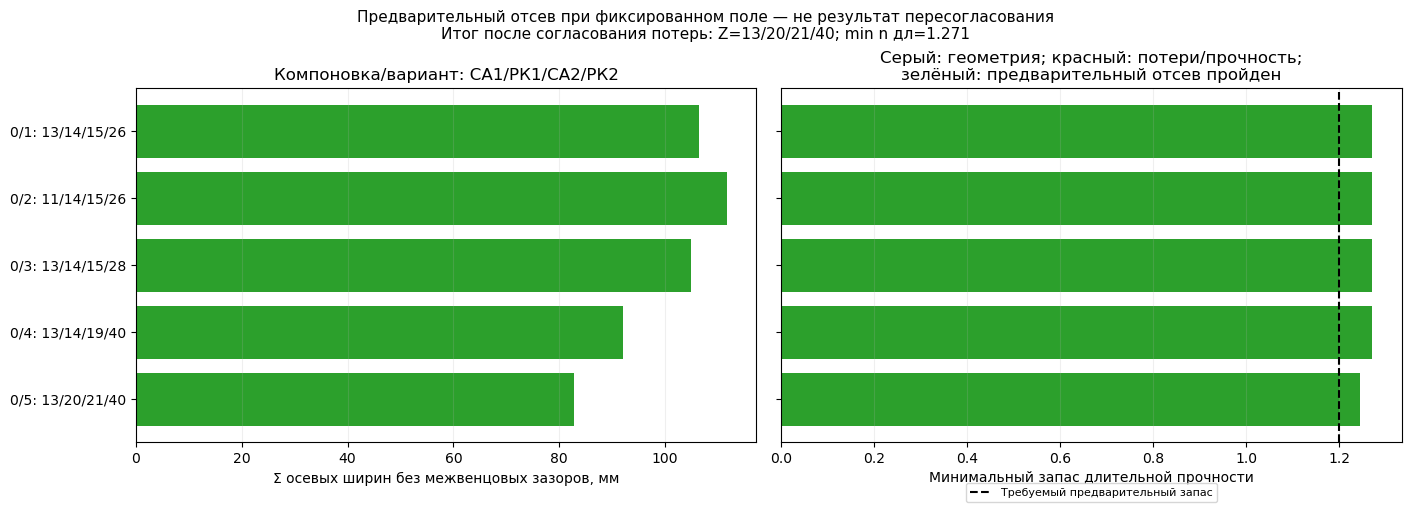

In [45]:
display(COUPLED['history'].round(7))
loss_sections_df,loss_rows_df=cascade_loss_review(P0,RADIAL_RESULTS,CHANNEL,PROFILES)
display(loss_rows_df.round(7))
display(loss_sections_df.round(7))
assert loss_rows_df['Невязка коэффициента'].abs().max()<=LOSS_MODEL['coefficient_tolerance']
assert profile_review_df['Принят по геометрии'].all()
print('Потери и коэффициенты скорости итерационно согласованы в явно принятой приближённой модели; это не экспериментальное подтверждение.')
# Сводка компактности: красный не означает «число лопаток невозможно»,
# а указывает, что построенный кандидат не прошёл указанный gate.
plot_selection=SELECTION_REPORT.copy()
labels=[f"{row['Компоновка']}/{row['Вариант']}: {row['СА1']}/{row['РК1']}/{row['СА2']}/{row['РК2']}" for _,row in plot_selection.iterrows()]
colours=['tab:green' if row['Все gates'] else '0.6' if not row['Геометрия'] else 'tab:red' for _,row in plot_selection.iterrows()]
fig,axs=plt.subplots(1,2,figsize=(14,max(5,.32*len(labels))),layout='constrained',sharey=True)
y=np.arange(len(labels))
axs[0].barh(y,plot_selection['Σ ширин венцов, мм'],color=colours)
axs[0].set(yticks=y,yticklabels=labels,xlabel='Σ осевых ширин без межвенцовых зазоров, мм',title='Компоновка/вариант: СА1/РК1/СА2/РК2')
axs[0].invert_yaxis()
margins=plot_selection['min n дл'].to_numpy(dtype=float)
finite=np.isfinite(margins)
axs[1].barh(y[finite],margins[finite],color=np.asarray(colours)[finite])
for index in np.flatnonzero(~finite):
    axs[1].text(0.,index,'∞' if np.isposinf(margins[index]) else 'н/д',va='center',fontsize=8)
axs[1].axvline(STRENGTH_REQUIREMENTS['required_margin'],color='black',ls='--',label='Требуемый предварительный запас')
axs[1].set(xlabel='Минимальный запас длительной прочности',title='Серый: геометрия; красный: потери/прочность;\nзелёный: предварительный отсев пройден')
axs[1].legend(fontsize=8,loc='upper center',bbox_to_anchor=(.5,-.10))
selected_label='/'.join(str(COUPLED['selected_counts'][name]) for name in ('СА1','РК1','СА2','РК2'))
fig.suptitle('Предварительный отсев при фиксированном поле — не результат пересогласования\n'
             f"Итог после согласования потерь: Z={selected_label}; min n дл={COUPLED['strength']['min_margin']:.3f}",fontsize=11)
for ax in axs:ax.grid(axis='x',alpha=.2)
plt.show()

## 27. Предварительная прочность по пяти сечениям трапециями

По пяти реальным профилям обоих РК составными трапециями вычисляется $N(r_j)=\int_{r_j}^{R_п}\rho\omega^2rF(r)dr$ и $\sigma_N=N/F$ в каждом сечении. Принята плотность 7900 кг/м³. Это предварительная оценка растяжения, не подмена уточнения.

Основными являются уже согласованные суженные профили: отдельная несогласованная ветка `TAPERED_PROFILES` удалена. В §32 сохранено **уточнение квадратичной площади через корневое, среднее массовое и периферийное сечения**, приведено численное сравнение двух методов и выполнен предварительный Ларсон—Миллер. Количество рисуемых сечений остаётся равным трём.

In [46]:
mechanical_raw_df=mechanical_screening(P0,PROFILES,density_kg_m3=MATERIAL_INPUTS['density_kg_m3'],sigma_allow_MPa=None)
display(mechanical_raw_df.round(6))
MECHANICAL_TRAPEZOID5=mechanical_trapezoid_sections(P0,PROFILES,density_kg_m3=MATERIAL_INPUTS['density_kg_m3'])
mechanical_five_table=MECHANICAL_TRAPEZOID5.copy()
mechanical_five_table['r']=mechanical_five_table['r']*1e3
mechanical_five_table['F']=mechanical_five_table['F']*1e6
mechanical_five_table['sigma_tension']=mechanical_five_table['sigma_tension']/1e6
display(mechanical_five_table.rename(columns={'rotor':'РК','section':'Сечение','r':'r, мм','F':'F, мм²','N':'N, Н','sigma_tension':'σN трапеции, МПа'}).round(6))
print('Предварительная оценка — пять сечений трапециями. Уточнение квадратичной F(r) по трём сечениям и Ларсон—Миллер приведены в §32.')

,РК,"ρ материала [выбрано], кг/м³","A корня, мм²",A корня/A конца,"σ растяжение профиля, МПа","σ по Kn, МПа","Книжный предварительный ориентир, МПа",В пределах книжного ориентира,"n max по ориентиру и этому перу, об/мин","Допуск материала, МПа",Статус
0,1,8110.0,52.553888,1.298798,134.402126,73.657941,200.0,True,40550.408995,None,Предварительное растяжение; ресурсный gate по ...
1,2,8110.0,18.581654,1.300569,163.248258,89.626314,200.0,True,36793.748024,None,Предварительное растяжение; ресурсный gate по ...


,РК,Сечение,"r, мм","F, мм²","N, Н","σN трапеции, МПа"
0,1,0,87.748650,52.553888,7063.354222,134.402126
1,1,1,92.101898,49.016194,5111.221232,104.276175
2,1,2,96.247379,45.857390,3292.565505,71.800108
3,1,3,100.212665,42.986085,1593.243707,37.064174
4,1,4,104.019758,40.463493,-0.000000,-0.000000
5,2,0,83.805587,18.581654,3033.422652,163.248258
6,2,1,89.304197,17.292016,2195.432511,126.962209
7,2,2,94.472020,16.178147,1415.184142,87.475047
8,2,3,99.363597,15.183304,685.196523,45.128287
9,2,4,104.019758,14.287326,-0.000000,-0.000000


Предварительная оценка — пять сечений трапециями. Уточнение квадратичной F(r) по трём сечениям и Ларсон—Миллер приведены в §32.


## 28. Горячий зазор и недостающие конструктивные данные

Потребный холодный зазор выражен через заданный минимальный горячий зазор, расширение корпуса и пера, рост диска, центробежные деформации и эксцентриситет. Температура газа не подставляется вместо температуры металла.

Материал и ресурс назначены в §10. Для подтверждённого рабочего расчёта нужны аттестованные свойства материала, температуры корпуса/диска/пера, сборочные допуски, технология кромок и геометрия диска/замков. Охлаждение исключено из принятой схемы. Эти конструктивные и тепловые данные не следуют из баланса цикла. Функция `required_cold_gap` готова к подстановке данных; при отсутствии значений выдаёт понятную ошибку.

Предел 0,5 мм в газодинамике — принятый нижний книжный ориентир для малой турбины (2006, с.63). Это **рабочий** ориентир, а не рассчитанный холодный размер. На с.12 описан отдельный случай сотовой вставки с зазором после приработки 0,2 мм и меньше; он не переносится автоматически на текущую схему.

In [47]:
material_input_rows=[]
material_origins={'material':'INCO 497, p.2–3: IN-738C, вакуумное литьё',
    'required_life_h':f"Требование пользователя: {STRENGTH_REQUIREMENTS['life_hours']:g} часов",
    'density_kg_m3':'INCO 497, p.3: 8,11 г/см³',
    'manufacturing_method':STRENGTH_REQUIREMENTS['heat_treatment'],
    'sigma_allow_MPa':'Не единый скаляр: вычисляется по Tмет и ресурсу для каждого РК'}
for k,v in MATERIAL_INPUTS.items():
    material_input_rows.append({'Параметр':k,'Значение':v,
        'Статус':material_origins.get(k,'Тепловой/конструктивный параметр не подтверждён' if v is None else 'Предварительный книжный геометрический ориентир')})
display(pd.DataFrame(material_input_rows))
try:
    required_cold_gap(C.delta_min,GEOMETRY[1]/2,GEOMETRY[1]/2,None,None,None,None,None,None,None)
except ValueError as exc:
    print('Холодный сборочный зазор не подменяется рабочим ориентиром:',str(exc))
else:raise AssertionError('Без температур металла не должен выдаваться рабочий зазор')


,Параметр,Значение,Статус
0,material,"IN-738C, вакуумное литьё","INCO 497, p.2–3: IN-738C, вакуумное литьё"
1,required_life_h,2000.0,Требование пользователя: 2000 часов
2,sigma_allow_MPa,None,Не единый скаляр: вычисляется по Tмет и ресурс...
3,sigma_screening_MPa,200.0,Предварительный книжный геометрический ориентир
4,density_kg_m3,8110.0,"INCO 497, p.3: 8,11 г/см³"
5,root_tip_area_ratio,1.3,Предварительный книжный геометрический ориентир
6,T_blade_metal_K,None,Тепловой/конструктивный параметр не подтверждён
7,T_disk_metal_K,None,Тепловой/конструктивный параметр не подтверждён
8,T_casing_metal_K,None,Тепловой/конструктивный параметр не подтверждён
9,alpha_blade_1_K,None,Тепловой/конструктивный параметр не подтверждён


Холодный сборочный зазор не подменяется рабочим ориентиром: Нужны температуры металла, коэффициенты расширения, рост диска и допуски


## 29. Воспроизводимость подбора и итоговый статус

Основной расчёт воспроизводит `coupled_turbine_design`: заново вычисляет потери, коэффициенты и реальные профили. Сохранённая геометрия используется как начальное приближение. При нарушении ограничений обновлённым потоком выполняется `refine_radial_design`, и его результат явно становится новой компоновкой. История согласования доступна в COUPLED["history"], протоколы дополнительных подборов — COUPLED["refinements"].

Все «зелёные» статусы относятся только к явно перечисленным уравнениям и ограничениям. Для признания конструкции пригодной требуются одновременно принятые профили, подтверждённые потери и расчёт материала/ресурса. Наличие 20 массивов координат этого не обеспечивает.

In [48]:
RUN_V9_REFINEMENT=False
if RUN_V9_REFINEMENT:
    v9_repeated_search=refine_radial_design(OPTIMIZATION_REPORT['initial_x'],C,maxiter=220,verbose=True)
    print(v9_repeated_search)
else:
    print('Отдельный ручной SLSQP не запускался; потребные уточнения внутри согласованного расчёта записаны в COUPLED["refinements"].')
final_status_df=pd.DataFrame([
    {'Область':'Балансы и геометрические тождества meanline','Статус':'выполнены' if balances(P0).passed.all() else 'нарушены'},
    {'Область':'Среднелинейные проектные ориентиры','Статус':'выполнены' if design_checks(P0)['Выполнено'].all() else 'есть нарушения'},
    {'Область':'Расходы и Euler в радиальных сечениях','Статус':'замкнуты в осесимметричной модели'},
    {'Область':'Дозвуковость по радиусу','Статус':'выполнена для выбранной точки'},
    {'Область':'Число ступеней','Статус':'2 заданы схемой; предварительная оценка зависит от y0, показано сравнение'},
    {'Область':'Предварительный меридиональный контур','Статус':'построен, площади и углы проверены; потери переходов не подтверждены'},
    {'Область':'Профили по разделу 8','Статус':f"Геометрические условия: {int(profile_review_df['Принят по геометрии'].sum())}/20; потери и технология отдельно"},
    {'Область':'Коэффициенты потерь по реальным решёткам','Статус':'Итерационно согласованы в приближённой модели; экспериментально не подтверждены'},
    {'Область':'Прочность, горячий зазор и ресурс','Статус':f"Оба РК: предварительный gate {STRENGTH_REQUIREMENTS['life_hours']:g} ч {'выполнен' if COUPLED['strength']['passed'] else 'НЕ выполнен'}; min nдл={COUPLED['strength']['min_margin']:.3f}; горячий зазор и общий ресурс не подтверждены"},
    {'Область':'ЦБК','Статус':'учтён только в цикле; подробное проектирование вне задания'}])
display(final_status_df)
assert balances(P0).passed.all()
assert design_checks(P0)['Выполнено'].all()
print('План продолжен; результаты и незакрытые ограничения сохранены вместе. Рабочие чертежи не выданы.')

Отдельный ручной SLSQP не запускался; потребные уточнения внутри согласованного расчёта записаны в COUPLED["refinements"].


,Область,Статус
0,Балансы и геометрические тождества meanline,выполнены
1,Среднелинейные проектные ориентиры,выполнены
2,Расходы и Euler в радиальных сечениях,замкнуты в осесимметричной модели
3,Дозвуковость по радиусу,выполнена для выбранной точки
4,Число ступеней,2 заданы схемой; предварительная оценка зависи...
5,Предварительный меридиональный контур,"построен, площади и углы проверены; потери пер..."
6,Профили по разделу 8,Геометрические условия: 20/20; потери и технол...
7,Коэффициенты потерь по реальным решёткам,Итерационно согласованы в приближённой модели;...
8,"Прочность, горячий зазор и ресурс",Оба РК: предварительный gate 2000 ч выполнен; ...
9,ЦБК,учтён только в цикле; подробное проектирование...


План продолжен; результаты и незакрытые ограничения сохранены вместе. Рабочие чертежи не выданы.


## 30. Проверка новых методов и сходимости дискретизации

Аналитические массивы свойств дополнительно сверены со скалярными функциями, в том числе через границу 750 К. Радиальная сетка сгущена со 101 до 201 точки. Минимальное расстояние в черновых решётках проверено на удвоенной сетке контура. Это численная верификация; она не превращает отвергнутые профили в пригодные.

In [49]:
numeric_validation=[]
for aa in [np.inf,P0['stages'][0]['alpha'],P0['stages'][1]['alpha']]:
    tt=np.array([288.,500.,749.99,750.,900.,1250.])
    hv=_thermo_array(tt,aa,C);sv=_thermo_array(tt,aa,C,True)
    errh=np.max(np.abs(hv-np.array([h(T,aa,C) for T in tt])))
    errs=np.max(np.abs(sv-np.array([ds(C.Tref,T,aa) for T in tt])))
    errt=np.max(np.abs(_inverse_h_array(hv,aa,C)-tt))
    assert errh<1e-6 and errs<1e-9 and errt<1e-7
    numeric_validation.append({'Проверка':'Массивы свойств','α':aa,'Δh max':errh,'Δs max':errs,'ΔT max':errt})
radial_convergence=[]
for i,(st,coarse) in enumerate(zip(P0['stages'],RADIAL_RESULTS),1):
    fine=radial_stage(st,GEOMETRY,C,RADIAL_LAW,points=201)
    dm=abs(fine['inlet']['M_c'].max()-coarse['inlet']['M_c'].max())
    dpsi=max(abs(fine['psi_required_min']-coarse['psi_required_min']),abs(fine['psi_required_max']-coarse['psi_required_max']))
    assert dm<1e-4 and dpsi<1e-4
    assert fine['euler_max_residual']<.002
    radial_convergence.append({'Ступень':i,'Δmax Mc1, 101/201':dm,'Δψ, 101/201':dpsi,
        'ΔG сетка 201, кг/с':fine['mass_out_residual'],'max ΔLu сетка 201, Дж/кг':fine['euler_max_residual']})
profile_convergence=[]
for name in ['СА1','РК1','СА2','РК2']:
    old=PROFILES[(name,2)];kind=old['kind']
    dense=preliminary_profile(old['beta_in_metal'],old['beta_out_flow'],old['bax'],kind,
                              BOOK_DEFAULTS['trailing_edge_m'],old['deviation'],points=321,**old['shape_parameters'])
    check=channel_geometry(dense,old['pitch'],old['height_in'],old['height_out'])
    dev=abs(check['throat_m']-old['throat_m'])/check['throat_m']
    assert dev<.02
    profile_convergence.append({'Венец':name,'Относительная разность горла, 161/321':dev,
        'Самопересечение, 321':check['self_intersection'],'Пересечение соседних стенок, 321':check['intersections']})
display(pd.DataFrame(numeric_validation));display(pd.DataFrame(radial_convergence));display(pd.DataFrame(profile_convergence))
display(profile_review_df.loc[~profile_review_df['Принят по геометрии'],['Венец','Сечение','Статус']])
profile_geometry_validation=[]
for (name,j),pr in PROFILES.items():
    blade=CHANNEL['blade_rows'].set_index('name').loc[name]
    global_x=pr['x_le_m']+pr['polygon'][:,0]
    assert abs(global_x.min()-pr['x_le_m'])<1e-10 and abs(global_x.max()-pr['x_te_m'])<1e-10
    assert global_x.min()>=blade.x_le-1e-10 and global_x.max()<=blade.x_te+1e-10
    # Радиусы измеряются по координатам дуг, а не подставляются как исходные размеры.
    _,rle,erle=_book_circle_measure(pr['leading_edge_arc'])
    assert abs(rle/pr['bax']-.035)<1e-8 and erle<1e-10
    edge=pr['trailing_edge'];middle=.5*(edge[0]+edge[1])
    outlet=np.array([math.sin(math.radians(pr['beta_out_metal'])),-math.cos(math.radians(pr['beta_out_metal']))])
    # A real finite cut, with no material/rounded cap protruding downstream.
    assert abs(np.linalg.norm(edge[1]-edge[0])-.0005)<1e-10
    assert abs(np.dot(edge[1]-edge[0],outlet))<1e-10
    assert np.max((pr['polygon']-middle)@outlet)<1e-10
    assert 2.-1e-8<=pr['trailing_wedge_deg']<=5.+1e-8
    # Входная окружность и обе поверхности соединены по κ, а не только по касательной.
    for side,sign in (('suction',1),('pressure',-1)):
        segments=pr[side+'_segments'];ends=[_book_curve_end_geometry(c) for c in segments]
        assert abs(ends[0][0]['curvature']+sign/rle)*rle<1e-8
        assert abs(ends[0][-1]['curvature']-ends[1][0]['curvature'])*rle<1e-8
        assert np.linalg.norm(ends[0][-1]['tangent']-ends[1][0]['tangent'])<1e-8
        curvature=[]
        for controls in segments:
            degree=len(controls)-1;t=np.linspace(0,1,401)
            first=_book_bezier(degree*np.diff(controls,axis=0),t)
            second=_book_bezier(degree*(degree-1)*np.diff(controls,n=2,axis=0),t)
            curvature.extend((_book_cross(first,second)/np.linalg.norm(first,axis=1)**3*rle).tolist())
        signs=np.sign(np.asarray(curvature)[np.abs(curvature)>1e-6])
        # У корытца один естественный переход от выпуклой кромки к вогнутому телу.
        assert np.count_nonzero(np.diff(signs))==(0 if side=='suction' else 1)
    angles=np.linspace(0,2*np.pi,180,endpoint=False)
    inner_radius=rle-4*pr['discretization_error_m']
    assert all(_book_inside(pr['leading_circle_center']+inner_radius*np.array([np.cos(a),np.sin(a)]),pr['polygon']) for a in angles)
    assert pr['tangent_error']<1e-8
    # Две точки горла действительно являются контактами вписанного круга.
    cc=pr['throat_center'];rr=pr['throat_m']/2
    assert np.max(np.abs(np.linalg.norm(pr['throat_contacts']-cc,axis=1)-rr))<1e-10
    corrected=pr['throat_height_ratio']*math.degrees(math.asin(pr['throat_m']/pr['pitch']))
    assert abs(corrected-pr['beta_out_flow'])<=2.
    assert pr['circle_equidistance_residual_m']<1e-9
    profile_geometry_validation.append({'Венец':name,'Сечение':j,'Ошибка масштаба':pr['scale_relative_error'],
        'Ошибка касательных':pr['tangent_error'],'Скачок κ вход G2':pr['leading_curvature_jump_relative'],
        'Скачок dκ/ds на переходе (диагностика)':pr['leading_curvature_slope_jump_relative'],
        'Выходной клин γ2, °':pr['trailing_wedge_deg']})
for i in (1,2):
    sa=CHANNEL['blade_rows'].set_index('name').loc[f'СА{i}']
    rk=CHANNEL['blade_rows'].set_index('name').loc[f'РК{i}']
    # Свободный зазор между физическими контурами, не часть их осевой ширины.
    clearance=rk.x_le-sa.x_te
    assert .20<=clearance/sa.bax<=.25
display(pd.DataFrame(profile_geometry_validation))
print('Численная сходимость проверена; пригодность по потерям и прочности не следует из сходимости геометрии.')

,Проверка,α,Δh max,Δs max,ΔT max
0,Массивы свойств,inf,5.820766e-11,0.0,1.136868e-13
1,Массивы свойств,3.211745,1.164153e-10,0.0,1.136868e-13
2,Массивы свойств,3.211745,1.164153e-10,0.0,1.136868e-13


,Ступень,"Δmax Mc1, 101/201","Δψ, 101/201","ΔG сетка 201, кг/с","max ΔLu сетка 201, Дж/кг"
0,1,9.216228e-07,3.442483e-07,-8.881784e-16,0.000019
1,2,1.960578e-06,4.185595e-07,-4.440892e-16,0.000038


,Венец,"Относительная разность горла, 161/321","Самопересечение, 321","Пересечение соседних стенок, 321"
0,СА1,0.000046,False,False
1,РК1,0.000025,False,False
2,СА2,0.000000,False,False
3,РК2,0.000006,False,False


,Венец,Сечение,Статус


,Венец,Сечение,Ошибка масштаба,Ошибка касательных,Скачок κ вход G2,Скачок dκ/ds на переходе (диагностика),"Выходной клин γ2, °"
0,СА1,0,1.301043e-15,1.417710e-15,3.224666e-14,40.953175,3.0
1,СА1,1,1.301043e-15,5.828671e-16,1.561792e-14,19.803855,3.0
2,СА1,2,1.301043e-15,4.996004e-16,2.239994e-14,19.912846,3.0
3,СА1,3,1.301043e-15,5.134781e-16,2.760714e-14,19.597570,3.0
4,СА1,4,1.301043e-15,1.942890e-16,6.139266e-15,18.452168,3.0
5,РК1,0,2.385245e-15,1.493652e-15,1.687624e-13,18.289648,3.0
6,РК1,1,2.818926e-15,1.276756e-15,8.734665e-15,18.608124,3.0
7,РК1,2,4.336809e-15,2.001483e-16,3.953584e-15,24.915694,3.0
8,РК1,3,4.770490e-15,3.140185e-16,4.513391e-15,19.477593,3.0
9,РК1,4,2.602085e-15,4.440892e-16,1.650819e-14,19.966804,3.0


Численная сходимость проверена; пригодность по потерям и прочности не следует из сходимости геометрии.


## 31. Применение книжных конструктивных ориентиров и открытые данные

### 31.1. Два разных коэффициента Kn

На с.48 пособия 2014 (с.55–56 книги 2006) дан общий предварительный Kn≈6,8·10⁻⁶. На с.49 (2006, с.57) приведена специальная формула для оптимально меняющегося сечения при заданном отношении площадей. Это разные уровни идеализации.

При вводе плотности в **кг/м³** результат специальной формулы переводится из Па в МПа множителем 10⁻⁶. Специальный коэффициент не подставляется автоматически вместо общего: одно совпадение Aкор/Aкон=3,5 не доказывает оптимальный закон напряжений по высоте.

### 31.2. Проверка построенного пера по выбранному ориентиру

Для тех же пяти сечений сопоставлены книжные плотности и выбранные 8110 кг/м³ литого IN-738C. Порог 200 МПа относится только к предварительному сравнению растяжения. Оценка максимальной частоты при неизменной геометрии использует σ∝n²; это не согласованный новый режим двигателя, поскольку газодинамика на другой частоте не пересчитывается.

Основное перо имеет согласованное сужение около 1,3, а не оптимальный книжный закон с отношением 3,5. Отрицательный результат проверки не устраняется выбором 300 МПа. Предварительный материал и ресурс сценария Ларсона—Миллера явно отделены от подтверждённых свойств конструкции.

In [50]:
def textbook_kn_optimal(density_kg_m3,area_ratio):
    if density_kg_m3<=0 or area_ratio<=1:raise ValueError('Нужны ρ>0 и Aкор/Aкон>1')
    return 2*math.pi*density_kg_m3/(3600*(1+math.log(area_ratio)))*1e-6
kn_optimal=textbook_kn_optimal(BOOK_DEFAULTS['density_kg_m3'],BOOK_DEFAULTS['root_tip_area_ratio'])
kn_book_df=pd.DataFrame([
    {'Модель':'Общий предварительный Kn','Kn, МПа/[(об/мин)²·м²]':C.Kn,'Применение':'Основная оценка; 2006 с.56 / 2014 с.48'},
    {'Модель':'Оптимальное распределение сечения','Kn, МПа/[(об/мин)²·м²]':kn_optimal,
     'Применение':'Только при условиях закона напряжений; 2006 с.57 / 2014 с.49'}])
display(kn_book_df)
book_mechanical_rows=[]
for label,profiles in [('Основное согласованное перо',PROFILES)]:
    for density in [7800.,7900.,MATERIAL_INPUTS['density_kg_m3']]:
        table=mechanical_screening(P0,profiles,density_kg_m3=density,sigma_allow_MPa=None,
                                   screening_limit_MPa=BOOK_DEFAULTS['sigma_screening_MPa'])
        table.insert(0,'Геометрия',label);book_mechanical_rows.extend(table.to_dict('records'))
book_mechanical_df=pd.DataFrame(book_mechanical_rows)
display(book_mechanical_df)
nominal_blades=book_mechanical_df[(book_mechanical_df['Геометрия']=='Основное согласованное перо')&
                              (book_mechanical_df['ρ материала [выбрано], кг/м³']==MATERIAL_INPUTS['density_kg_m3'])]
for _,row in nominal_blades.iterrows():
    print(f"РК{int(row['РК'])}: σраст={row['σ растяжение профиля, МПа']:.2f} МПа; "
          f"книжный ориентир {BOOK_DEFAULTS['sigma_screening_MPa']:.0f} МПа; "
          f"сравнение {'выполнено' if row['В пределах книжного ориентира'] else 'НЕ выполнено'}.")
print('Это не положительное заключение о прочности: [σ](Tмет, ресурс, материал) не задано.')

,Модель,"Kn, МПа/[(об/мин)²·м²]",Применение
0,Общий предварительный Kn,0.000007,Основная оценка; 2006 с.56 / 2014 с.48
1,Оптимальное распределение сечения,0.000006,Только при условиях закона напряжений; 2006 с....


,Геометрия,РК,"ρ материала [выбрано], кг/м³","A корня, мм²",A корня/A конца,"σ растяжение профиля, МПа","σ по Kn, МПа","Книжный предварительный ориентир, МПа",В пределах книжного ориентира,"n max по ориентиру и этому перу, об/мин","Допуск материала, МПа",Статус
0,Основное согласованное перо,1,7800.0,52.553888,1.298798,129.264683,73.657941,200.0,True,41348.367222,None,Предварительное растяжение; ресурсный gate по ...
1,Основное согласованное перо,2,7800.0,18.581654,1.300569,157.008189,89.626314,200.0,True,37517.782002,None,Предварительное растяжение; ресурсный gate по ...
2,Основное согласованное перо,1,7900.0,52.553888,1.298798,130.921923,73.657941,200.0,True,41085.835252,None,Предварительное растяжение; ресурсный gate по ...
3,Основное согласованное перо,2,7900.0,18.581654,1.300569,159.021114,89.626314,200.0,True,37279.571454,None,Предварительное растяжение; ресурсный gate по ...
4,Основное согласованное перо,1,8110.0,52.553888,1.298798,134.402126,73.657941,200.0,True,40550.408995,None,Предварительное растяжение; ресурсный gate по ...
5,Основное согласованное перо,2,8110.0,18.581654,1.300569,163.248258,89.626314,200.0,True,36793.748024,None,Предварительное растяжение; ресурсный gate по ...


РК1: σраст=134.40 МПа; книжный ориентир 200 МПа; сравнение выполнено.
РК2: σраст=163.25 МПа; книжный ориентир 200 МПа; сравнение выполнено.
Это не положительное заключение о прочности: [σ](Tмет, ресурс, материал) не задано.


### 31.3. Рабочий зазор и технология вставки

Книга 2006, с.12, описывает **сотовую вставку**, полученную высокотемпературной пайкой гофрированных жаростойких лент толщиной 0,1…0,2 мм. После приработки рабочий зазор может составлять 0,2 мм и меньше. Это сведения о вставке корпуса, а не технология изготовления рабочей лопатки.

На с.63 указан другой предварительный ориентир — 0,5…0,7 мм для малых турбин. Для основной расчётной схемы сохранены 0,5 мм. Вариант с сотовой вставкой требует согласования корпуса, бандажа/уплотнения, потерь и прочности; приведённые в книге проценты прироста КПД не прибавляются к расчётному КПД автоматически.

Холодный сборочный зазор по-прежнему не вычисляется из одного книжного рабочего значения: нужны температуры металла, деформации ротора/корпуса и допуски. Нельзя считать 0,2 мм исходным холодным зазором гладкого корпуса.

In [51]:
clearance_options_df=pd.DataFrame([
    {'Схема':'Основная предварительная малая турбина','Рабочий ориентир, мм':BOOK_DEFAULTS['working_gap_m']*1000,
     'Источник':'2006, с.63 / PDF 64','Условие':'Сохранён в основной газодинамике; холодный размер не определён'},
    {'Схема':'Альтернатива: сотовая вставка','Рабочий ориентир, мм':BOOK_DEFAULTS['honeycomb_runin_gap_m']*1000,
     'Источник':'2006, с.12 / PDF 13','Условие':'После приработки; нужна соответствующая конструкция и модель потерь'},
    {'Схема':'Холодный сборочный размер','Рабочий ориентир, мм':None,
     'Источник':'2006, с.12–13 / PDF 13–14','Условие':'Нужны температуры металла, деформации и сборочные допуски'}])
display(clearance_options_df)
book_missing_df=book_selection_df.loc[book_selection_df['Параметр'].isin([
    'Температуры металла и α линейного расширения'])]
display(book_missing_df)
assert MATERIAL_INPUTS['sigma_allow_MPa'] is None
assert MATERIAL_INPUTS['material']==STRENGTH_REQUIREMENTS['material']
assert MATERIAL_INPUTS['sigma_screening_MPa']==C.sigma_project_MPa==Config().sigma_project_MPa==200.
assert MATERIAL_INPUTS['density_kg_m3']==8110.
assert MATERIAL_INPUTS['root_tip_area_ratio']>1
for rotor in (1,2):
    assert np.all(np.diff([PROFILES[(f'РК{rotor}',j)]['area'] for j in range(5)])<0)
assert BOOK_DEFAULTS['working_gap_m']==C.delta_min==.0005
assert BOOK_DEFAULTS['trailing_edge_m']==.0005
assert balances(P0).passed.all()
assert design_checks(P0)['Выполнено'].all()
for _,row in book_mechanical_df.iterrows():
    sigma=row['σ растяжение профиля, МПа'];nlim=row['n max по ориентиру и этому перу, об/мин']
    assert abs(sigma*(nlim/GEOMETRY[0])**2-BOOK_DEFAULTS['sigma_screening_MPa'])<1e-8
print('Книжные исходные значения связаны с расчётом и проверены. Неизвестные свойства материала не выдуманы.')

assert MATERIAL_INPUTS['required_life_h']==STRENGTH_REQUIREMENTS['life_hours']==2000.


,Схема,"Рабочий ориентир, мм",Источник,Условие
0,Основная предварительная малая турбина,0.5,"2006, с.63 / PDF 64",Сохранён в основной газодинамике; холодный раз...
1,Альтернатива: сотовая вставка,0.2,"2006, с.12 / PDF 13",После приработки; нужна соответствующая констр...
2,Холодный сборочный размер,NaN,"2006, с.12–13 / PDF 13–14","Нужны температуры металла, деформации и сбороч..."


,Параметр,В книге,Принято,Ед.,Источник,Применимость
16,Температуры металла и α линейного расширения,не заданы для нашего узла,NaN,"К, 1/К","2006, с.12–13 / PDF 13–14",Не заменяются температурой газа или плотностью


Книжные исходные значения связаны с расчётом и проверены. Неизвестные свойства материала не выдуманы.


## 32. Прочность лопатки РК последней ступени по «ДЗ 1 — УКР»

**Источник методики:** приложенные `ДЗ 1 - УКР/ДЗ 1/УКРФ ДЗ1 Сладков.docx`, `УКРФ ДЗ New.xmcd` и чертежи `лопатки итог.png`, `Фрагмент эпюры.png`. Числа чужого варианта не используются. Расчёт автономный: при Run All эти файлы не читаются.

**Объект:** только последнее РК, его фактическое число лопаток и три построенных профиля: корень, среднее массовое сечение (50% расхода), периферия. Среднее массовое сечение не подменяется арифметической серединой высоты. ЦБК остаётся только в расчёте цикла.

### 32.1. Геометрия и расчётная схема

Координаты: $\xi$ — осевая по потоку, $\eta$ — окружная **по вращению**, $r$ — радиус. Все расчёты в СИ, размеры чертежей в мм и напряжения в МПа. Для номинального расчёта центры масс сечений установлены на одной радиальной оси, как в исходной схеме ДЗ. Это явная гипотеза сборки пера, не утверждение о положении центров исходных 2D-рисунков.

По контуру каждого сечения вычисляются площадь $F$, центр площади, $I_\xi=\int\eta^2dF$, $I_\eta=\int\xi^2dF$, $I_{\xi\eta}=\int\xi\eta dF$. Формулы Грина дают интегралы непосредственно по координатам, без ручного измерения рисунка. Отдельно воспроизведена шеститочечная схема Чебышёва из ДЗ и показано её отличие. Для площади, статического и второго моментов используются **разные** наборы узлов и коэффициентов; $a_1,a_2$ — полуразмеры описанного прямоугольника.

Центральные оси не обязательно главные: главные $u,v$ найдены диагонализацией полной матрицы, $I_u\le I_v$. Угол $\varphi$ отсчитывается от $+\xi$ к $+u$. Это исправляет предположение Word о том, что достаточно провести ось параллельно хорде.

По трём фактическим радиусам принят квадратичный $F(r)$, как при аппроксимации распределений в Word; проверяется его положительность во всём пролёте. В Mathcad для распределений использован сплайн — это не та же самая аппроксимация. Ранее в §27 приведён отдельный пятисеченчатый трапецеидальный скрининг; его число не обязано точно совпадать с текущим трёхсеченчатым интегралом.

### 32.2. Растяжение, газовый изгиб и центробежное кручение

При $K_\omega=\rho_\mathrm{мат}\omega^2$ и $R_п$ — радиусе периферии:

$$N(r)=K_\omega\int_r^{R_п}sF(s)\,ds,\qquad \sigma_N(r)=N(r)/F(r),\qquad T_\omega(r)=K_\omega\int_r^{R_п}I_{\xi\eta}(s)\,ds.$$

В Word крутящий момент ошибочно подписан как изгибающий; в Mathcad это $M_{\zeta\omega}$. Здесь он явно обозначен $T_\omega$. Плотность 7900 кг/м³ остаётся предварительным исходным значением, не выбором сплава.

Основные газовые нагрузки берутся из **существующего радиального расчёта последней ступени**, а не из чужого варианта. Входные состояния отображаются на выходные радиусы по массовым линиям тока. При $g'(r)=dG/dr$ и $Z$ лопатках используется полосочная аппроксимация ДЗ:

$$q_x=\frac{2\pi r(p_1-p_2)-g'(c_{2a}-c_{1a})}{Z},\qquad
q_y=\frac{g'}{Z}\left(\frac{r_1}{r}c_{1u}+c_{2u}\right).$$

Здесь книжное $c_{2u}>0$ направлено **против вращения**: физический выходной вихрь равен $-c_{2u}$. Поэтому окружная сила **на лопатку** содержит сумму, не разность модулей. Множитель $r_1/r$ переносит входной момент количества движения на эквивалентный выходной цилиндр; интегральный момент проверяется по работе Euler. В отличие от ДЗ, входная и выходная высоты у нас различаются, поэтому используется согласованный массовый поток, а не два несогласованных произведения $\rho c_a$.

Осевая составляющая давления по выходным кольцевым полоскам — приближение ДЗ: она не заменяет интегрирование давления по реальной трёхмерной поверхности и стенкам расширяющегося канала. Сравнительная таблица отдельно показывает исходную свободновихревую модель ДЗ с постоянными осевыми скоростями и нашими meanline-данными; она не перезаписывает газодинамическую модель турбины.

$$M_\xi=-\int_r^{R_п}(s-r)q_y(s)ds,\quad M_\eta=\int_r^{R_п}(s-r)q_x(s)ds,$$
$$\begin{bmatrix}M_u\\M_v\end{bmatrix}=\begin{bmatrix}\cos\varphi&\sin\varphi\\-\sin\varphi&\cos\varphi\end{bmatrix}\begin{bmatrix}M_\xi\\M_\eta\end{bmatrix},\qquad
\sigma_\mathrm{изг}(u,v)=\frac{M_uv}{I_u}-\frac{M_vu}{I_v},\qquad\sigma_\Sigma=\sigma_N+\sigma_\mathrm{изг}.$$

Нейтральная линия **изгиба** проходит через центр; линия $\sigma_\Sigma=0$ обычно смещена и может не пересекать профиль. При нулевом изгибе угол нейтральной линии не определяется. Напряжения показаны в контрольных точках A/B/C и дополнительно найдены их экстремумы по всему контуру каждого из трёх сечений. Это номинальные нормальные напряжения, **не эквивалентные по Мизесу**. Для произвольного профиля нельзя считать касательные напряжения как $Tr/(I_u+I_v)$: нужна модель Сен-Венана; в ДЗ рассчитан только центробежный крутящий момент. Газовый крутящий момент также требует положения центра приложения нагрузки.

### 32.3. Разгружающие выносы и законы площади

**Исправление приложения:** в XML Mathcad формулы выносов записаны произведениями двух интегралов. Они не обеспечивают компенсации изгиба и дают неопределённость $0\cdot\infty$ на свободном конце. Использованы следующие выведенные из равновесия вложенные интегралы при $x(R_к)=y(R_к)=0$:

$$\Phi(t)=\int_t^{R_п}sF(s)ds,\quad
x(r)=\frac1{K_\omega}\int_{R_к}^{r}\frac{\int_t^{R_п}q_x(s)ds}{\Phi(t)}dt,\quad
y(r)=\frac r{K_\omega}\int_{R_к}^{r}\frac{\int_t^{R_п}s q_y(s)ds}{t^2\Phi(t)}dt.$$

На периферии используются конечные аналитические пределы отношений. Проверка — независимое обратное интегрирование центробежных изгибающих моментов с найденными выносами и остатка $M_q+M_\omega$. Выносы показаны как **конструктивный сценарий**, но не применены автоматически к текущему перу и его номинальным напряжениям.

Как в разделе 3 ДЗ, сравниваются постоянная, линейная, экспоненциальная и почти равнопрочная площади. Для всех $\sigma_N=K_\omega\int_r^{R_п}sF(s)ds/F(r)$; максимум ищется по высоте, а не принудительно в корне. Коэффициент $\beta=\max\sigma_N/\sigma_\mathrm{const}$ относится только к центробежному растяжению.

При $0<\chi=F_п/F_к<1$ почти равнопрочный закон имеет
$$R_3^2=\frac{R_к^2-R_п^2\ln\chi}{1-\ln\chi},\quad \sigma_3=\frac{K_\omega}{2}(R_п^2-R_3^2),$$
$$F(r)=F_п\exp\left[\frac{K_\omega\max(R_3^2-r^2,0)}{2\sigma_3}\right].$$

У основного пера площадь убывает к периферии. Сравнительные законы используют фактическое отношение площадей этой же лопатки, около 1,3. Почти равнопрочный закон — сравнение по одному растяжению, не автоматическая замена реальной геометрии и не доказательство запаса с изгибом и кручением.

In [52]:
UKR_STRENGTH=COUPLED['strength']['rotor_results'][len(P0['stages'])]


In [53]:
print(f"Последний РК: {UKR_STRENGTH['rotor']}; Z={UKR_STRENGTH['Z']}; n={GEOMETRY[0]:.3f} об/мин; ρмат={UKR_STRENGTH['density']:g} кг/м³ (предварительно)")
print('Точные геометрические характеристики по координатам профилей:')
display(UKR_STRENGTH['geometry_table'].round(5))
print('Шесть измеряемых хорд Чебышёва и сравнение с точным контуром:')
display(UKR_STRENGTH['ordinates_table'].round(5))
display(UKR_STRENGTH['chebyshev_table'].round(5))
print('Коэффициенты F(r) = a0 + a1 r + a2 r², r в метрах, F в м²:',UKR_STRENGTH['area_coefficients'])
print('Номинальные нагрузки и нормальные напряжения по схеме ДЗ:')
display(UKR_STRENGTH['section_table'].round(5))
print('A — входная кромка; B — выходная; C — контрольная точка максимального прогиба контура. Экстремумы ищутся по всему контуру, а не только A/B/C.')
display(UKR_STRENGTH['points_table'].round(5))
ukr_laws_df=pd.DataFrame([{'Закон':law['name'],'Fк/Fп':law['F'][0]/law['F'][-1],
    'σN max, МПа':law['sigma'].max()/1e6,'r max, мм':law['r'][np.argmax(law['sigma'])]*1e3,
    'β = σmax/σconst':law['beta']} for law in UKR_STRENGTH['area_laws']])
display(ukr_laws_df.round(6))
print(f"Фактическое Aкор/Aпериф={1/UKR_STRENGTH['area_law_info']['chi']:.4f}. Сравнительные законы используют эту же конусность, а не другую лопатку.")
ukr_five=MECHANICAL_TRAPEZOID5.loc[MECHANICAL_TRAPEZOID5.rotor==UKR_STRENGTH['rotor']]
ukr_methods=[]
for j,sec in zip((0,2,4),UKR_STRENGTH['sections']):
    preliminary=ukr_five.loc[ukr_five.section==j].iloc[0]
    ukr_methods.append({'Сечение':sec['name'],'σN пять сечений, трапеции, МПа':preliminary.sigma_tension/1e6,
        'σN три сечения, квадрат. F(r), МПа':sec['sigma_tension']/1e6,
        'Отличие уточнения, %':100*(sec['sigma_tension']/preliminary.sigma_tension-1) if preliminary.sigma_tension>0 else 0.})
display(pd.DataFrame(ukr_methods).round(6))
ukr_free_vortex=ukr_rotor_strength(P0,PROFILES,RADIAL_RESULTS,C,MATERIAL_INPUTS,load_model='homework')
ukr_load_comparison=pd.concat([
    UKR_STRENGTH['section_table'][['Сечение','Mξ, Н·м','Mη, Н·м','σΣ max, МПа']].assign(Модель='Основная: радиальный поток турбины'),
    ukr_free_vortex['section_table'][['Сечение','Mξ, Н·м','Mη, Н·м','σΣ max, МПа']].assign(Модель='Сравнение: свободный вихрь ДЗ')],ignore_index=True)
display(ukr_load_comparison.round(6))
print('Свободный вихрь — сравнительная нагрузочная модель; он не заменяет газодинамику P0/RADIAL_RESULTS и не гарантирует её расход.')
ukr_offsets=UKR_STRENGTH['offsets']
display(ukr_offsets.iloc[[0,len(ukr_offsets)//2,-1]].rename(columns={'r':'r, м','x':'x, м','y':'y, м',
    'Mxi_residual':'Mξ остаток, Н·м','Meta_residual':'Mη остаток, Н·м'}).round(8))
print('Выносы — теоретическая разгрузка принятого пера. Они не применяются автоматически: требуется перестроить 3D-лопатку и повторно согласовать аэродинамику.')


# Аналитические случаи защищают от ошибок единиц, обхода, осей и свободного конца.
def ukr_strength_checks(actual):
    rectangle=np.array([[-.01,-.002],[.01,-.002],[.01,.002],[-.01,.002],[-.01,-.002]])
    F=.02*.004;Ix=.02*.004**3/12;Iy=.004*.02**3/12
    theta=.41;rotation=np.array([[math.cos(theta),-math.sin(theta)],[math.sin(theta),math.cos(theta)]])
    original=ukr_section_properties(rectangle)
    transformed=ukr_section_properties(rectangle[::-1]@rotation.T+np.array([.17,-.08]))
    np.testing.assert_allclose([original['F'],original['Ixi'],original['Ieta'],original['Ixy']], [F,Ix,Iy,0],rtol=1e-11,atol=1e-20)
    np.testing.assert_allclose([transformed['F'],transformed['Iu'],transformed['Iv']],[F,Ix,Iy],rtol=1e-10)
    cheb=ukr_chebyshev(rectangle)
    np.testing.assert_allclose([cheb['F'],cheb['Ixi'],cheb['Ieta']],[F,Ix,Iy],rtol=1e-10)
    rr=np.linspace(.05,.08,401);density=7900.;omega=5500.;area=np.full_like(rr,F)
    expected=density*omega**2*(rr[-1]**2-rr**2)/2
    np.testing.assert_allclose(density*omega**2*ukr_tail(rr,rr*area)/area,expected,rtol=1e-9,atol=1e-4)
    q=np.full_like(rr,1234.)
    np.testing.assert_allclose(ukr_tail(rr,rr*q)-rr*ukr_tail(rr,q),q*(rr[-1]-rr)**2/2,rtol=1e-8,atol=1e-11)
    # Пятисеченная трапеция точно интегрирует r·F при постоянном F.
    radii5=np.linspace(.05,.08,5)
    synthetic={(f'РК1',j):dict(radius=float(radius),area=F) for j,radius in enumerate(radii5)}
    five=mechanical_trapezoid_sections(dict(geometry=[omega*60/(2*math.pi)],stages=[{}]),synthetic,density)
    np.testing.assert_allclose(five.sigma_tension,density*omega**2*(radii5[-1]**2-radii5**2)/2,rtol=1e-12,atol=1e-6)
    # Проверка знаков и преобразования моментов на независимо интегрируемом прямоугольнике.
    M=np.array([-7.,11.]);basis=transformed['principal_axes'];Mu,Mv=basis.T@M
    gradient=basis@np.array([-Mv/transformed['Iv'],Mu/transformed['Iu']])
    gx,gw=np.polynomial.legendre.leggauss(4)
    xx,yy=np.meshgrid(gx*.01,gx*.002);weights=np.outer(gw,gw).ravel()*.01*.002
    p=np.column_stack([xx.ravel(),yy.ravel()])@rotation.T;stress=p@gradient
    np.testing.assert_allclose([np.sum(p[:,1]*stress*weights),-np.sum(p[:,0]*stress*weights)],M,rtol=1e-10)
    for sec in actual['sections']:
        Q=np.array([[sec['Ixy'],sec['Ixi']],[-sec['Ieta'],-sec['Ixy']]])
        fixed_gradient=np.linalg.solve(Q,[sec['Mxi'],sec['Meta']])
        np.testing.assert_allclose(sec['sigma_bending'],sec['centered']@fixed_gradient,rtol=1e-10,atol=1e-5)
    span=actual['span'];end=span.iloc[-1]
    np.testing.assert_allclose(end[['N','Mxi','Meta','Tomega','sigma_tension']],0,atol=1e-12)
    assert np.all(np.isfinite(span.to_numpy())) and np.all(span.F>0) and np.all(span.N>=-1e-7)
    offsets=actual['offsets']
    residual=max(offsets.Mxi_residual.abs().max(),offsets.Meta_residual.abs().max())
    moment_scale=max(span.Mxi.abs().max(),span.Meta.abs().max())
    assert residual/moment_scale<2e-5,('Выносы не компенсируют газовый изгиб',residual/moment_scale)
    np.testing.assert_allclose(offsets.iloc[0][['x','y']],0,atol=1e-14)
    # Сравнительный закон с фактической конусностью почти равнопрочен до R3.
    law=next(law for law in actual['area_laws'] if 'Почти равнопрочный: текущая χ' in law['name'])
    mask=law['r']<=actual['area_law_info']['transition']
    plateau=law['sigma'][mask]
    assert np.ptp(plateau)/np.mean(plateau)<1e-5
    # Проверка сохранения мощности для эквивалентной нагрузки радиальной модели.
    torque=actual['Z']*np.trapezoid(span.r*span.qy,span.r)
    stage=P0['stages'][-1];target=stage['G']*stage['Lu']/actual['omega']
    assert abs(torque/target-1)<1e-3,('Момент нагрузки не согласован с Euler',torque,target)
    print(f'Аналитические проверки выполнены. Остаток разгрузки: {residual:.3e} Н·м ({residual/moment_scale:.3e} от максимального момента).')
    print(f'Момент всех лопаток РК{actual["rotor"]}: {torque:.6f} Н·м; по Euler: {target:.6f} Н·м; отклонение {100*(torque/target-1):.5f} %.')
    return dict(offset_residual_Nm=residual,torque_Nm=torque,torque_reference_Nm=target)

UKR_CHECKS=ukr_strength_checks(UKR_STRENGTH)
ukr_coarse=ukr_rotor_strength(P0,PROFILES,RADIAL_RESULTS,C,MATERIAL_INPUTS,nodes=401)
ukr_grid_comparison=[]
for fine,coarse in zip(UKR_STRENGTH['sections'],ukr_coarse['sections']):
    relative=abs(fine['sigma_total'].max()-coarse['sigma_total'].max())/max(abs(fine['sigma_total'].max()),1.)
    assert relative<1e-4,('Не сошлась сетка сил',fine['name'],relative)
    ukr_grid_comparison.append({'Сечение':fine['name'],'σΣ max 401, МПа':coarse['sigma_total'].max()/1e6,
        'σΣ max 801, МПа':fine['sigma_total'].max()/1e6,'Разность, %':100*relative})
display(pd.DataFrame(ukr_grid_comparison).round(8))
print('401/801 — число узлов интегрирования по высоте, НЕ число рисуемых сечений: сечений строго три.')


Последний РК: 2; Z=40; n=33241.706 об/мин; ρмат=8110 кг/м³ (предварительно)
Точные геометрические характеристики по координатам профилей:


,Сечение,"r, мм","F, мм²","ξц, мм","ηц, мм","Iξ, мм⁴","Iη, мм⁴","Iξη, мм⁴","Iu, мм⁴","Iv, мм⁴","φ, °"
0,Корневое,83.80559,18.58165,5.72719,-3.17097,217.32436,196.16358,-199.24746,7.21579,406.27215,-46.51983
1,Среднее,94.47202,16.17815,6.19776,-3.15954,305.55837,257.53861,-266.96785,13.50315,549.59383,-47.56955
2,Периферийное,104.01976,14.28733,6.41358,-3.50893,385.55350,297.11437,-321.67879,16.63004,666.03782,-48.91355


Шесть измеряемых хорд Чебышёва и сравнение с точным контуром:


,Сечение,Узел,"ξ, мм","f(ξ), мм"
0,Корневое,1,11.21056,1.22152
1,Корневое,2,8.54519,1.56982
2,Корневое,3,7.60867,1.65418
3,Корневое,4,4.40565,1.74801
4,Корневое,5,3.46913,1.71758
5,Корневое,6,0.80376,1.63630
6,Среднее,1,12.33807,1.32060
7,Среднее,2,9.40462,1.16555
8,Среднее,3,8.37392,1.05274
9,Среднее,4,4.84875,0.99917


,Сечение,"F Чебышёв, мм²","ΔF, %","Δξц, мм","Δηц, мм","Iξ Чебышёв, мм⁴","Iη Чебышёв, мм⁴"
0,Корневое,19.11760,2.88428,0.01009,-0.15582,235.11837,203.64165
1,Среднее,16.84438,4.11813,0.06064,-0.37882,364.87137,269.76185
2,Периферийное,14.82572,3.76832,0.09137,-0.57319,522.76282,310.37216


Коэффициенты F(r) = a0 + a1 r + a2 r², r в метрах, F в м²: [ 4.81565692e-05 -4.66061588e-04  1.35029781e-03]
Номинальные нагрузки и нормальные напряжения по схеме ДЗ:


... (8 outputs left out)

,"r, м","x, м","y, м","Mξ остаток, Н·м","Mη остаток, Н·м"
0,0.083806,0.000000,0.000000,0.0,-0.0
401,0.093938,0.000026,0.000042,0.0,-0.0
801,0.104020,0.000060,0.000086,0.0,0.0


Выносы — теоретическая разгрузка принятого пера. Они не применяются автоматически: требуется перестроить 3D-лопатку и повторно согласовать аэродинамику.
Аналитические проверки выполнены. Остаток разгрузки: 2.945e-09 Н·м (2.679e-08 от максимального момента).
Момент всех лопаток РК2: 40.821045 Н·м; по Euler: 40.821043 Н·м; отклонение 0.00001 %.


,Сечение,"σΣ max 401, МПа","σΣ max 801, МПа","Разность, %"
0,Корневое,202.265585,202.265588,1.190000e-06
1,Среднее,93.613490,93.613490,3.300000e-07
2,Периферийное,0.000000,0.000000,0.000000e+00


401/801 — число узлов интегрирования по высоте, НЕ число рисуемых сечений: сечений строго три.


### 32.4. Расчётные чертежи по образцу приложения

Три сечения последнего РК с центром O, центральными и главными осями и размерными дугами. На эпюрах: постоянное растяжение, линейный изгиб и их сумма; штриховка и значения МПа, как в приложенном образце. Координата развёртки $s$ направлена вдоль градиента изгибных напряжений. Каждая эпюра имеет свою шкалу напряжений, профиль сохраняет одинаковый масштаб по обеим координатам. Это **расчётные чертежи**, не комплект рабочих чертежей с замком, допусками и технологией.

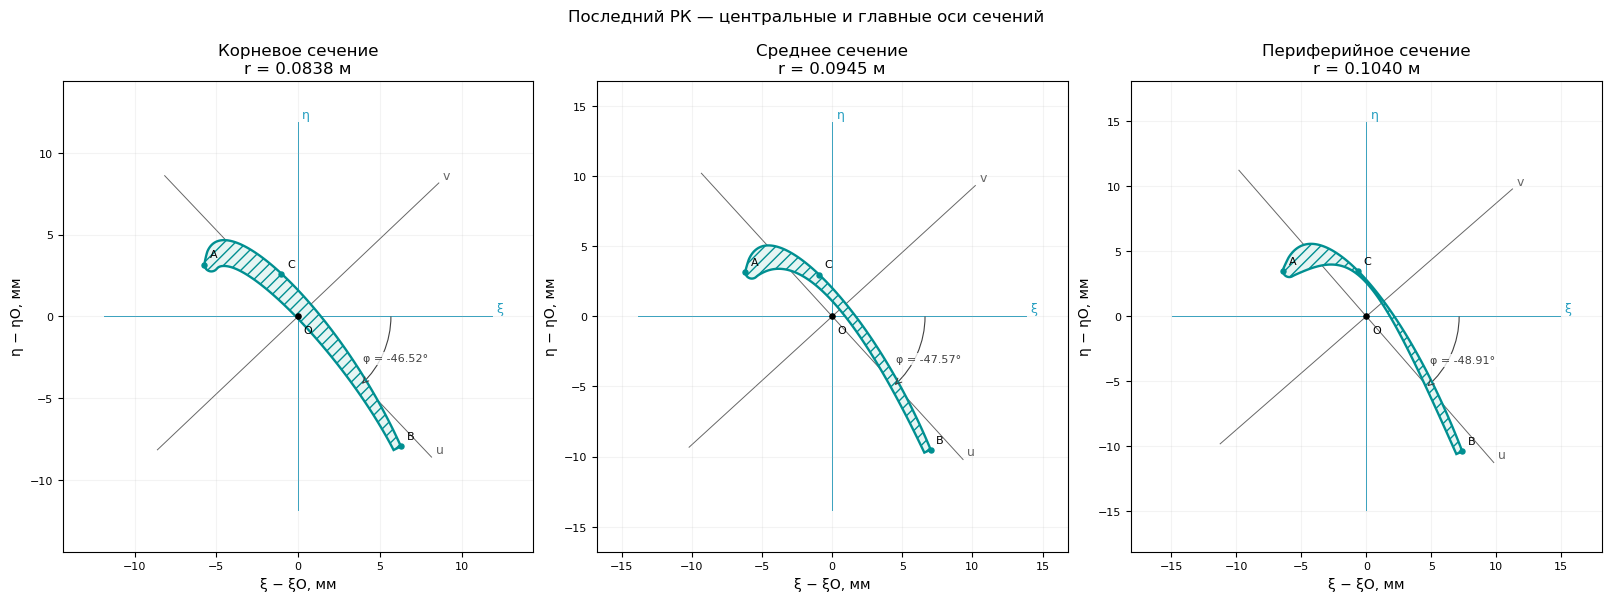

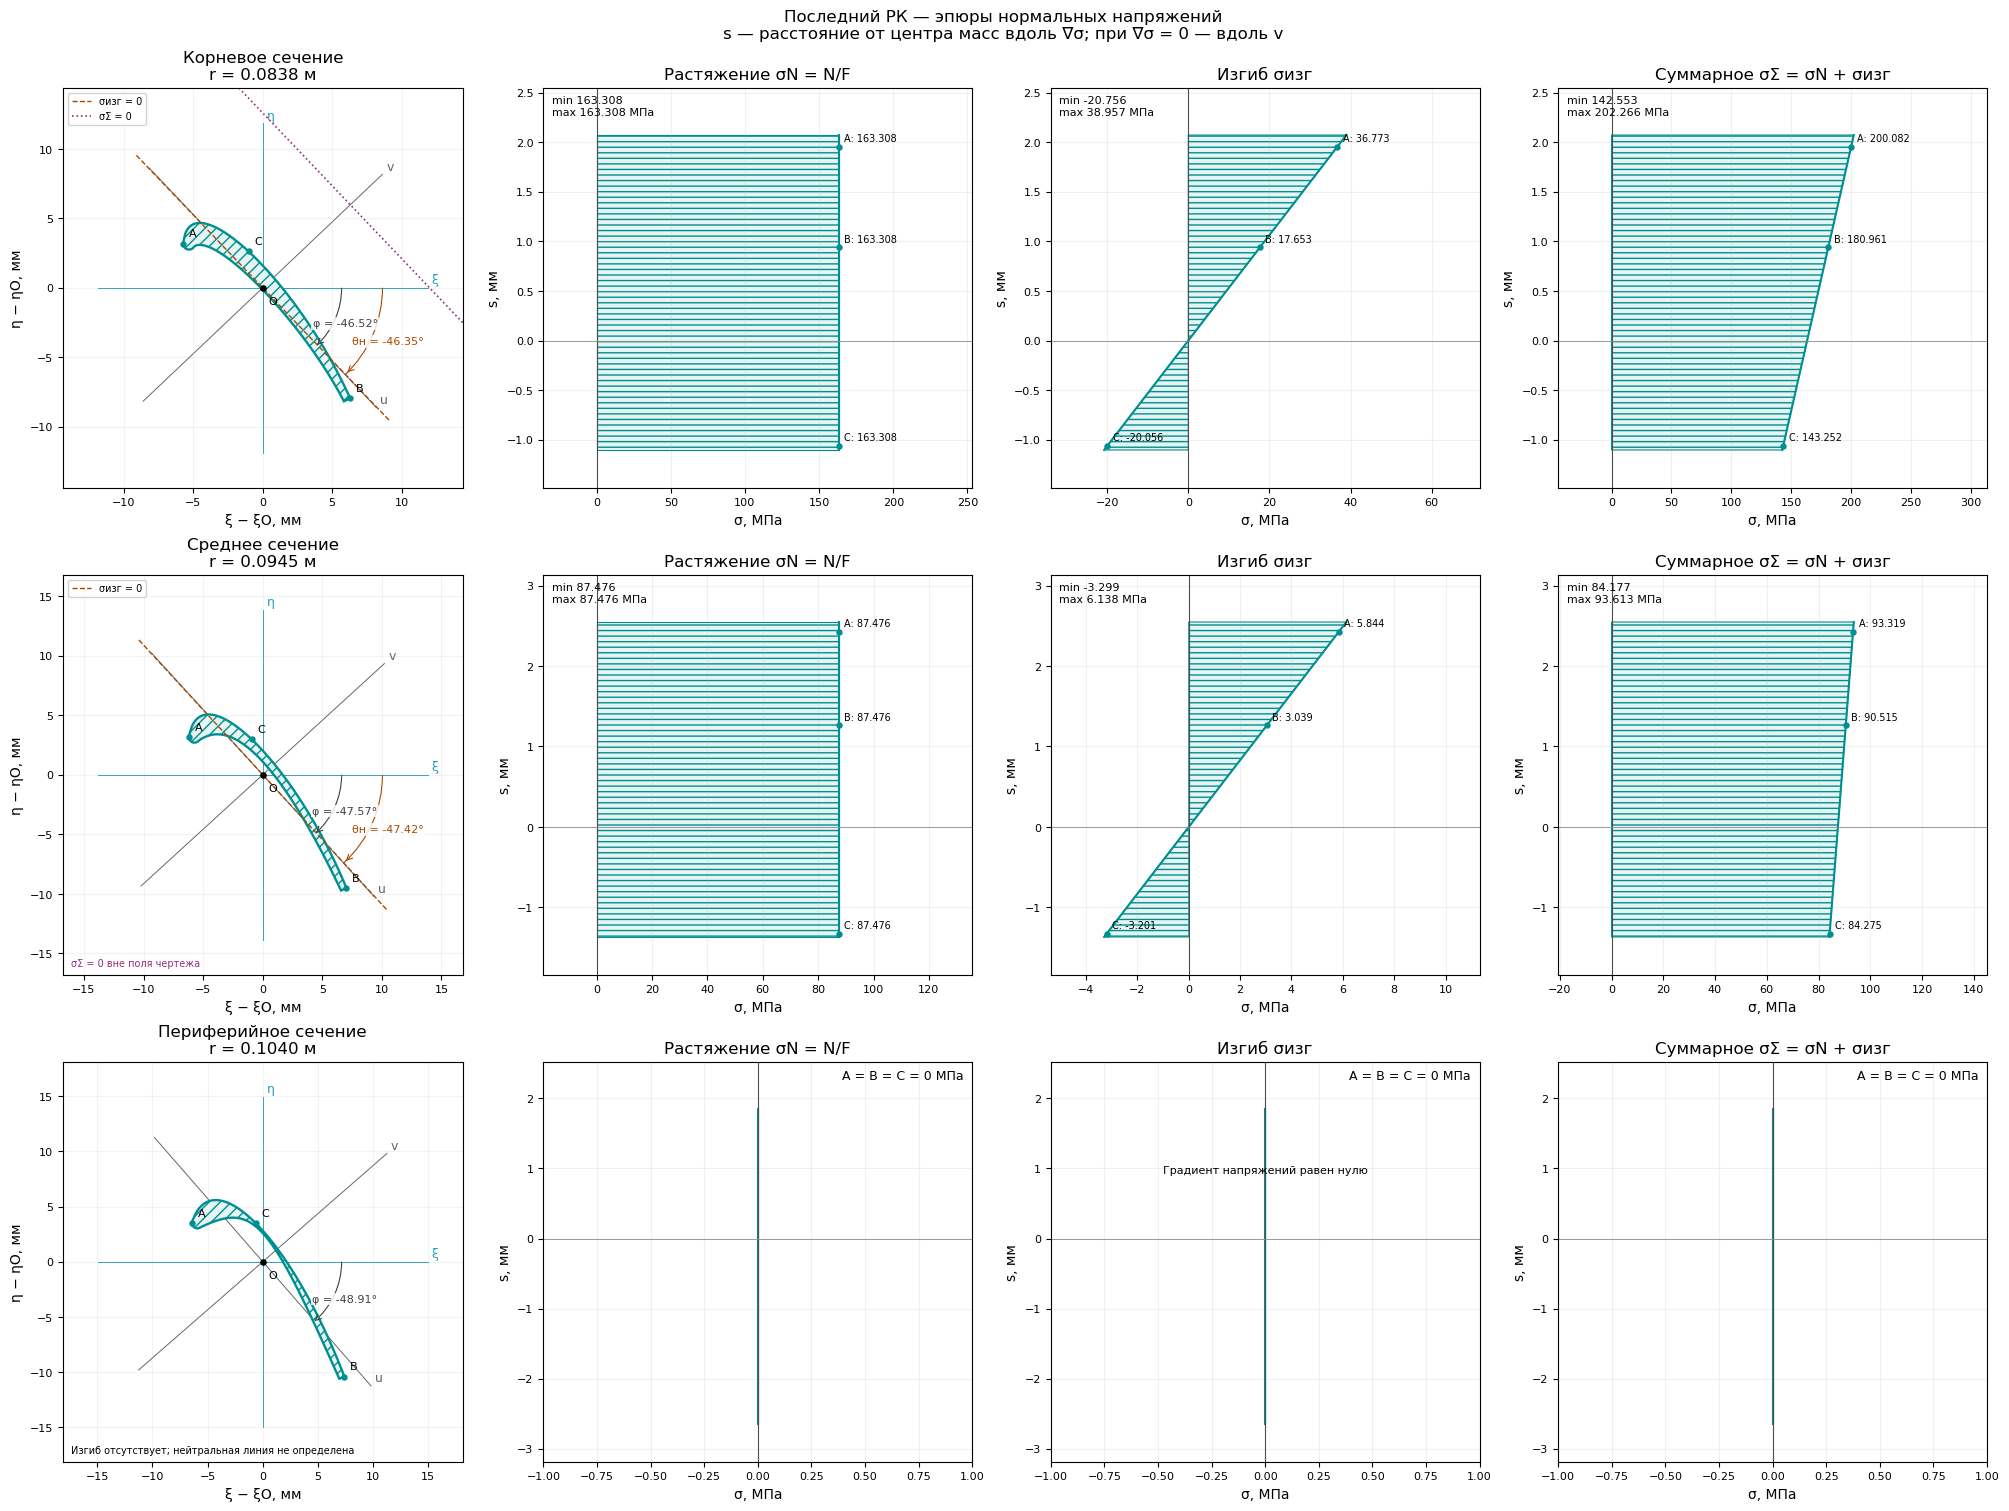

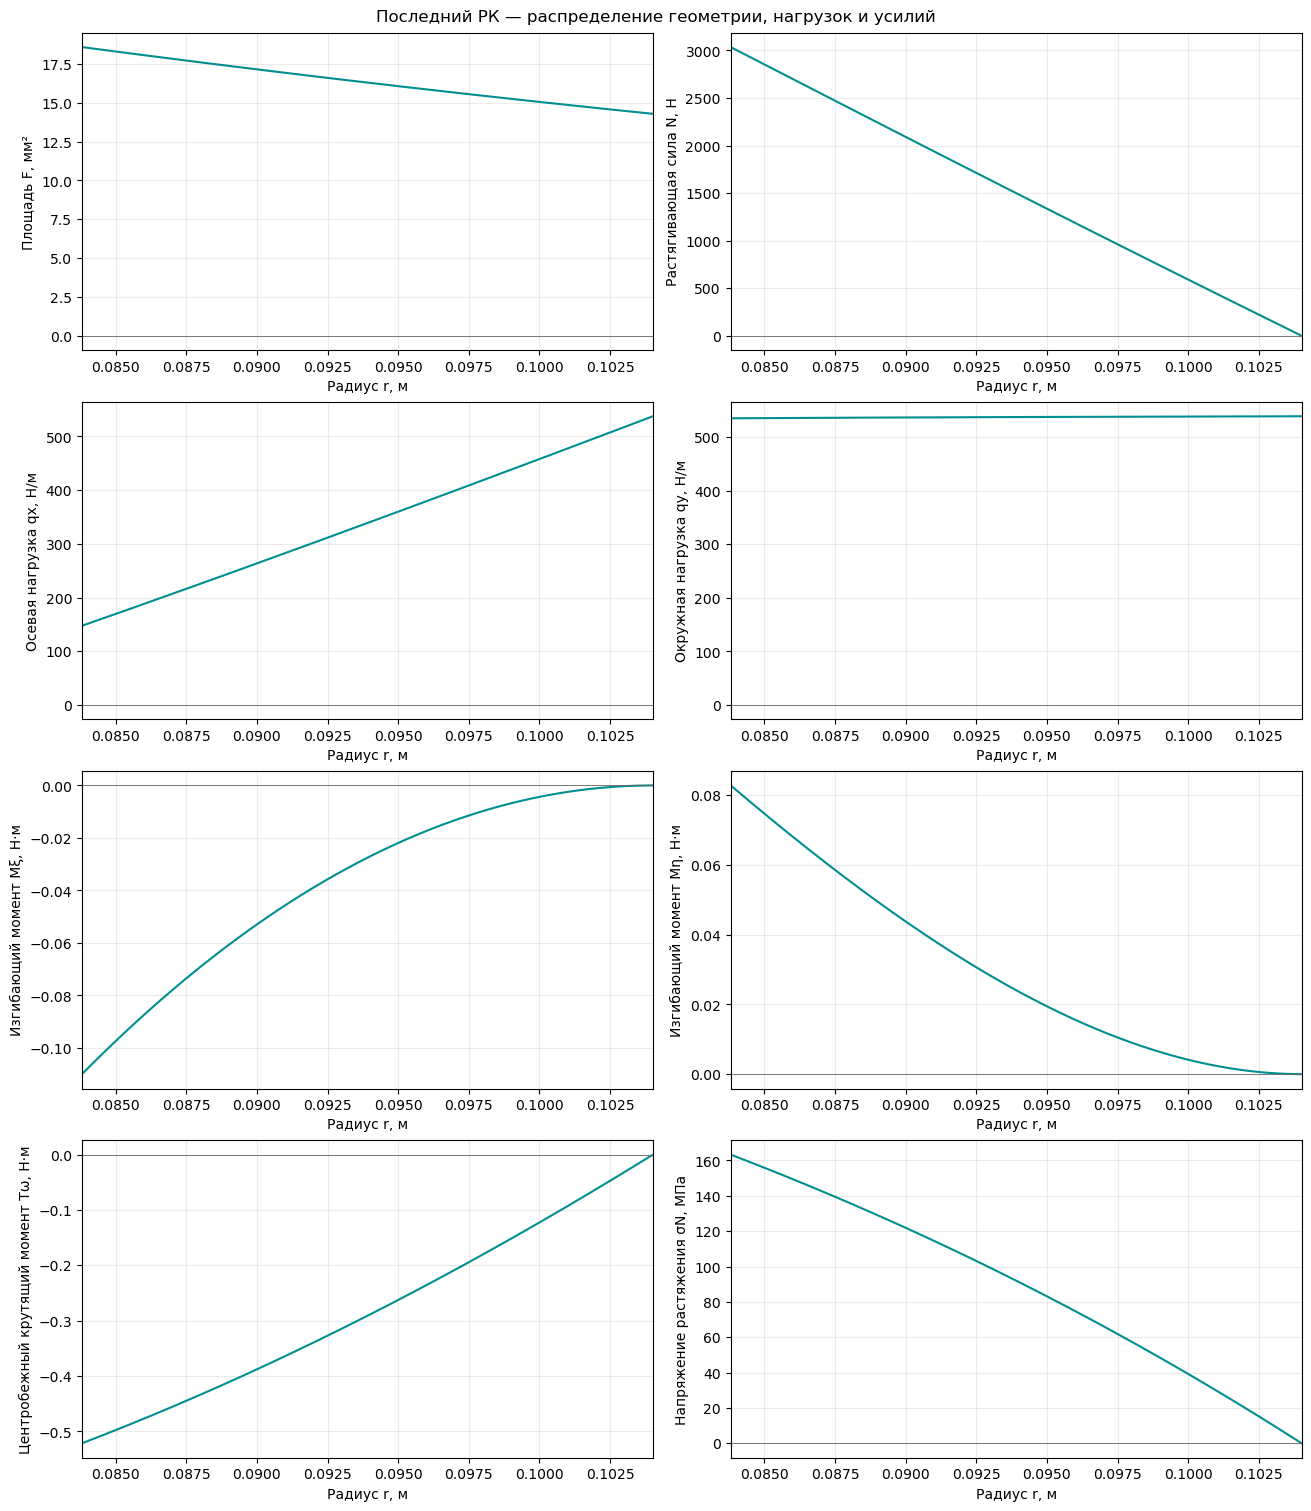

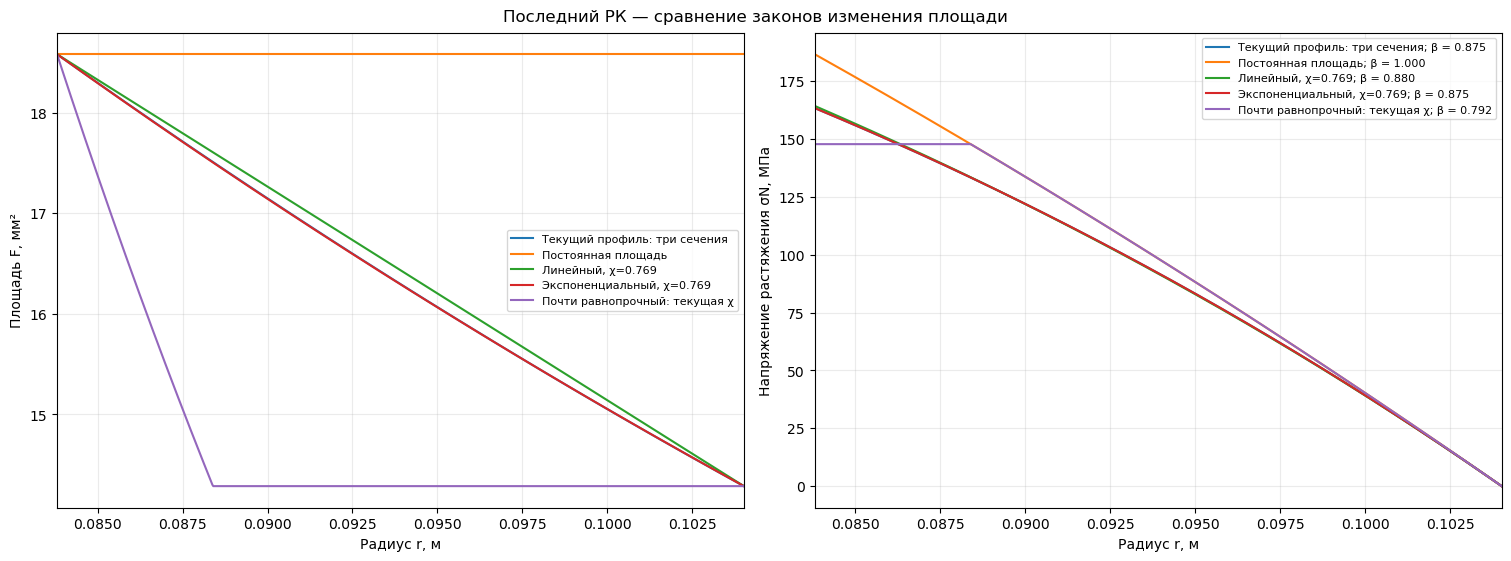

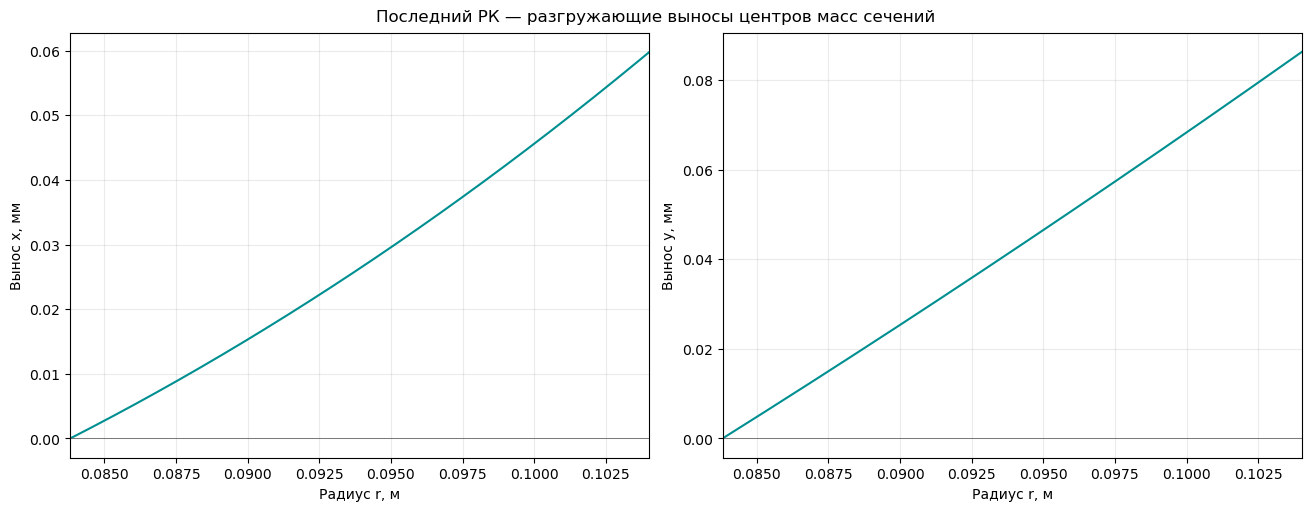

In [54]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Arc, Polygon


# Входные данные только в СИ: м, м², Н, Н/м, Н·м, Па.
# Преобразования в мм, мм² и МПа выполняются исключительно при отрисовке.
_UKR_TEAL = '#008f91'
_UKR_BLUE = '#259fc1'


def _ukr_angle_arc(ax, angle, radius, label, color='0.25'):
    """Размерная дуга от положительного направления ξ к заданному углу."""
    angle = (float(angle) + np.pi) % (2 * np.pi) - np.pi
    if abs(angle) < 1e-10:
        ax.annotate(label, (radius, 0), xytext=(4, 6),
                    textcoords='offset points', fontsize=8, color=color)
        return
    degrees = np.degrees(angle)
    ax.add_patch(Arc((0, 0), 2 * radius, 2 * radius,
                     theta1=min(0, degrees), theta2=max(0, degrees), color=color, lw=.8))
    end = radius * np.array([np.cos(angle), np.sin(angle)])
    before = radius * np.array([np.cos(angle * .94), np.sin(angle * .94)])
    ax.annotate('', end, before, arrowprops=dict(arrowstyle='->', color=color, lw=.8))
    mid = 1.14 * radius * np.array([np.cos(angle / 2), np.sin(angle / 2)])
    ax.text(*mid, label, fontsize=8, color=color, ha='center', va='center',
            bbox=dict(facecolor='white', edgecolor='none', alpha=.8, pad=1))


def _ukr_section(ax, section, neutral=False):
    p = np.asarray(section['centered'], dtype=float) * 1e3
    axes = np.asarray(section['principal_axes'], dtype=float)
    length = max(float(np.max(np.linalg.norm(p, axis=1))), np.finfo(float).eps)
    ax.add_patch(Polygon(p, closed=True, facecolor='#e6f5f3', edgecolor=_UKR_TEAL,
                         lw=1.7, hatch='///', zorder=2))
    for direction, label, color in [(np.array([1., 0.]), 'ξ', _UKR_BLUE),
                                     (np.array([0., 1.]), 'η', _UKR_BLUE),
                                     (axes[:, 0], 'u', '0.4'),
                                     (axes[:, 1], 'v', '0.4')]:
        ax.plot(*np.array([-1.17 * length * direction, 1.17 * length * direction]).T,
                color=color, lw=.7, zorder=1)
        end = 1.17 * length * direction
        ax.annotate(label, end, xytext=(3, 3), textcoords='offset points',
                    color=color, fontsize=9)
    ax.scatter([0], [0], c='black', s=14, zorder=4)
    ax.annotate('O', (0, 0), xytext=(4, -12), textcoords='offset points', fontsize=8)
    for label, index in section['points'].items():
        point = p[int(index)]
        ax.scatter(*point, s=13, color=_UKR_TEAL, zorder=4)
        ax.annotate(label, point, xytext=(4, 5), textcoords='offset points', fontsize=8)
    angle = float(section['principal_angle_rad'])
    _ukr_angle_arc(ax, angle, .56 * length, f'φ = {np.degrees(angle):.2f}°')
    if neutral:
        gradient = np.asarray(section['stress_gradient'], dtype=float)
        norm = float(np.linalg.norm(gradient))
        if norm > 0:
            normal = gradient / norm
            tangent = np.array([-normal[1], normal[0]])
            ends = np.array([-1.3 * length * tangent, 1.3 * length * tangent])
            ax.plot(*ends.T, '--', color='#a44a00', lw=1, label='σизг = 0')
            shift = -float(section['sigma_tension']) / norm * 1e3 * normal
            # Нулевая линия суммарных напряжений может лежать вне сечения.
            if np.linalg.norm(shift) <= 1.3 * length:
                ax.plot(*(ends + shift).T, ':', color='#942c7d', lw=1.2,
                        label='σΣ = 0')
            else:
                ax.text(.02, .02, 'σΣ = 0 вне поля чертежа', transform=ax.transAxes,
                        fontsize=7, color='#942c7d')
            beta = section.get('neutral_angle_rad')
            if beta is not None:
                _ukr_angle_arc(ax, beta, .85 * length,
                               f'θн = {np.degrees(beta):.2f}°', '#a44a00')
            ax.legend(loc='upper left', fontsize=7, framealpha=.85)
        else:
            ax.text(.02, .02, 'Изгиб отсутствует; нейтральная линия не определена',
                    transform=ax.transAxes, fontsize=7, wrap=True)
    ax.set(xlim=(-1.42 * length, 1.42 * length), ylim=(-1.42 * length, 1.42 * length),
           xlabel='ξ − ξO, мм', ylabel='η − ηO, мм',
           title=f"{section['name']} сечение\nr = {section['r']:.4f} м")
    ax.set_aspect('equal', adjustable='box')
    ax.tick_params(labelsize=8)
    ax.grid(alpha=.15)


def plot_ukr_sections(result):
    """Три сечения последнего РК; масштаб профиля по обеим координатам одинаков."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), constrained_layout=True)
    for ax, section in zip(axes, result['sections']):
        _ukr_section(ax, section)
    fig.suptitle('Последний РК — центральные и главные оси сечений', y=1.06)
    return [fig]


def _ukr_epure(ax, distance, stress, title, point_distances, point_values):
    # Расстояния на ординате — мм, напряжения на абсциссе — МПа.
    y = np.asarray(distance, dtype=float) * 1e3
    x = np.asarray(stress, dtype=float) * 1e-6
    ax.fill_betweenx(y, 0, x, facecolor='#e6f5f3', edgecolor=_UKR_TEAL,
                     hatch='---', linewidth=.8)
    ax.plot(x, y, color=_UKR_TEAL, lw=1.5)
    ax.axvline(0, color='0.3', lw=.8)
    ax.axhline(0, color='0.55', lw=.6)
    for label, distance_value in (point_distances.items() if np.any(x) else ()):
        value = float(point_values[label]) * 1e-6
        ordinate = float(distance_value) * 1e3
        ax.scatter([value], [ordinate], s=13, color=_UKR_TEAL, zorder=4)
        ax.annotate(f'{label}: {value:.3f}', (value, ordinate), xytext=(4, 4),
                    textcoords='offset points', fontsize=7)
    low, high = float(np.min(x)), float(np.max(x))
    width = max(abs(low), abs(high), high - low)
    if width == 0:
        ax.set_xlim(-1, 1)
        ax.text(.98, .98, 'A = B = C = 0 МПа', transform=ax.transAxes,
                ha='right', va='top', fontsize=9)
    else:
        ax.set_xlim(min(0., low) - .22 * width, max(0., high) + .55 * width)
        ax.text(.02, .98, f'min {low:.3f}\nmax {high:.3f} МПа',
                transform=ax.transAxes, va='top', fontsize=8)
    height = float(np.ptp(y))
    ax.set_ylim(float(np.min(y)) - .12 * height, float(np.max(y)) + .15 * height)
    ax.set(title=title, xlabel='σ, МПа', ylabel='s, мм')
    ax.tick_params(labelsize=8)
    ax.grid(alpha=.18)


def plot_ukr_stress_epures(result):
    """Эпюры по направлению градиента: растяжение, изгиб и их сумма."""
    fig, axes = plt.subplots(3, 4, figsize=(20, 15), constrained_layout=True)
    for row, section in zip(axes, result['sections']):
        _ukr_section(row[0], section, neutral=True)
        p = np.asarray(section['centered'], dtype=float)
        gradient = np.asarray(section['stress_gradient'], dtype=float)
        norm = float(np.linalg.norm(gradient))
        # При нулевом изгибе используем v только как координату развертки;
        # никакой фиктивный наклон эпюры или нейтральной линии не вводится.
        direction = gradient / norm if norm > 0 else np.asarray(section['principal_axes'])[:, 1]
        distance = p @ direction
        ends = np.array([np.min(distance), np.max(distance)])
        tension = float(section['sigma_tension'])
        indices = section['points']
        point_distances = {key: distance[int(index)] for key, index in indices.items()}
        bending_vertices = np.asarray(section['sigma_bending']).reshape(-1)
        total_vertices = np.asarray(section['sigma_total']).reshape(-1)
        for ax, stress, title, values in [
            (row[1], np.full(2, tension), 'Растяжение σN = N/F',
             {key: tension for key in indices}),
            (row[2], norm * ends, 'Изгиб σизг',
             {key: bending_vertices[int(index)] for key, index in indices.items()}),
            (row[3], tension + norm * ends, 'Суммарное σΣ = σN + σизг',
             {key: total_vertices[int(index)] for key, index in indices.items()})]:
            _ukr_epure(ax, ends, stress, title, point_distances, values)
        if norm == 0:
            row[2].text(.5, .72, 'Градиент напряжений равен нулю',
                        transform=row[2].transAxes, ha='center', fontsize=8)
    fig.suptitle('Последний РК — эпюры нормальных напряжений\n'
                 's — расстояние от центра масс вдоль ∇σ; при ∇σ = 0 — вдоль v')
    return [fig]


def plot_ukr_distributions(result):
    """Радиальные распределения и сравнение законов площадей последнего РК."""
    span = result['span']
    fig, axes = plt.subplots(4, 2, figsize=(13, 15), constrained_layout=True)
    specs = [('F', 1e6, 'Площадь F, мм²'), ('N', 1., 'Растягивающая сила N, Н'),
             ('qx', 1., 'Осевая нагрузка qx, Н/м'), ('qy', 1., 'Окружная нагрузка qy, Н/м'),
             ('Mxi', 1., 'Изгибающий момент Mξ, Н·м'),
             ('Meta', 1., 'Изгибающий момент Mη, Н·м'),
             ('Tomega', 1., 'Центробежный крутящий момент Tω, Н·м'),
             ('sigma_tension', 1e-6, 'Напряжение растяжения σN, МПа')]
    for ax, (key, scale, label) in zip(axes.flat, specs):
        ax.plot(span['r'], np.asarray(span[key]) * scale, color=_UKR_TEAL)
        ax.set(xlabel='Радиус r, м', ylabel=label,
               xlim=(float(span['r'].iloc[0]), float(span['r'].iloc[-1])))
        ax.axhline(0, color='0.4', lw=.6)
        ax.grid(alpha=.25)
    fig.suptitle('Последний РК — распределение геометрии, нагрузок и усилий')
    laws_fig, laws_axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)
    unavailable = []
    for law in result['area_laws']:
        name = law['name']
        if any(law.get(key) is None for key in ('r', 'F', 'sigma')):
            unavailable.append(f"{name}: {law.get('diagnostic') or law.get('reason') or 'закон неприменим'}")
            continue
        beta = law.get('beta')
        label = name if beta is None else f'{name}; β = {beta:.3f}'
        laws_axes[0].plot(law['r'], np.asarray(law['F']) * 1e6, label=name)
        laws_axes[1].plot(law['r'], np.asarray(law['sigma']) * 1e-6, label=label)
    for ax, ylabel in zip(laws_axes, ['Площадь F, мм²', 'Напряжение растяжения σN, МПа']):
        ax.set(xlabel='Радиус r, м', ylabel=ylabel)
        ax.margins(x=0)
        ax.grid(alpha=.25)
        ax.legend(fontsize=8)
    laws_fig.suptitle('Последний РК — сравнение законов изменения площади')
    if unavailable:
        laws_fig.supxlabel('\n'.join(unavailable), fontsize=9, color='#a44a00')
    return [fig, laws_fig]


def plot_ukr_offsets(result):
    """Выносы центров масс; недопустимые решения не подменяются нулями."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
    offsets = result.get('offsets')
    for ax, key in zip(axes, ['x', 'y']):
        if offsets is None:
            ax.text(.5, .5, 'Выносы вне области допустимости', transform=ax.transAxes,
                    ha='center', va='center')
        else:
            ax.plot(offsets['r'], np.asarray(offsets[key], dtype=float) * 1e3,
                    color=_UKR_TEAL)
            ax.margins(x=0)
        ax.set(xlabel='Радиус r, м', ylabel=f'Вынос {key}, мм')
        ax.axhline(0, color='0.4', lw=.6)
        ax.grid(alpha=.25)
    fig.suptitle('Последний РК — разгружающие выносы центров масс сечений')
    return [fig]


def plot_ukr_strength(result):
    """Вернуть все рисунки без plt.show() и без чтения внешних файлов."""
    figures = []
    for draw in (plot_ukr_sections, plot_ukr_stress_epures,
                 plot_ukr_distributions, plot_ukr_offsets):
        figures.extend(draw(result))
    return figures

UKR_FIGURES=plot_ukr_strength(UKR_STRENGTH)
plt.show()

### 32.5. Что теперь рассчитано и чего ещё не хватает

Добавлены геометрические характеристики, главные оси, растяжение, газовый изгиб, центробежный крутящий момент, контрольные точки и эпюры трёх сечений; рассчитаны разгружающие выносы и сравнительные законы площади. Ниже — численный итог для фактического пера, не для теоретического суженного кандидата.

**Остаётся необходимо:** марка сплава, температура металла, ресурс и температурно-временные допускаемые напряжения; геометрия замка и концентрации; термонапряжения/ползучесть; вибрационная усталость и резонансы; задача кручения для касательных напряжений. Подтверждённая 3D-геометрия и поле давления нужны для уточнения полосочных нагрузок и реализации выносов. Значение 200 МПа — только прежний проектный ориентир, не предел прочности сплава.

In [55]:
ukr_table=UKR_STRENGTH['section_table']
ukr_peak=ukr_table.loc[ukr_table['σΣ max, МПа'].idxmax()]
print(f"РК{UKR_STRENGTH['rotor']}: наибольшее σΣ среди трёх рассчитанных сечений — {ukr_peak['σΣ max, МПа']:.3f} МПа ({ukr_peak['Сечение'].lower()} сечение).")
print(f"Максимум чистого центробежного растяжения по высоте: {UKR_STRENGTH['span'].sigma_tension.max()/1e6:.3f} МПа.")
print(f"Сравнение с предварительным ориентиром {MATERIAL_INPUTS['sigma_screening_MPa']:g} МПа: " + ('выше ориентира' if ukr_peak['σΣ max, МПа']>MATERIAL_INPUTS['sigma_screening_MPa'] else 'не выше ориентира; это не доказательство прочности'))
print('Общий подтверждённый запас НЕ выдан. Предварительный температурно-ресурсный сценарий Ларсона—Миллера — в §32.6 ниже.')
final_status_df.loc[final_status_df['Область']=='Прочность, горячий зазор и ресурс','Статус']='РК последней ступени: номинальное растяжение/изгиб, Tω и чертежи в §32; допуск материала, горячий зазор и ресурс НЕ подтверждены'
display(final_status_df.loc[final_status_df['Область'].isin(['Профили по разделу 8','Прочность, горячий зазор и ресурс','ЦБК'])])


РК2: наибольшее σΣ среди трёх рассчитанных сечений — 202.266 МПа (корневое сечение).
Максимум чистого центробежного растяжения по высоте: 163.308 МПа.
Сравнение с предварительным ориентиром 200 МПа: выше ориентира
Общий подтверждённый запас НЕ выдан. Предварительный температурно-ресурсный сценарий Ларсона—Миллера — в §32.6 ниже.


,Область,Статус
6,Профили по разделу 8,Геометрические условия: 20/20; потери и технол...
8,"Прочность, горячий зазор и ресурс",РК последней ступени: номинальное растяжение/и...
9,ЦБК,учтён только в цикле; подробное проектирование...


### 32.6. Длительная прочность по Ларсону—Миллеру

**Проектный ресурс 2000 ч задан пользователем.** Материал итогового варианта — литой IN-738C по таблице IX бюллетеня INCO 497. Проверены оба РК; здесь подробно показано последнее. Температурная граница рассчитывается из неохлаждаемого газового потока. Старый ХН70ВМТЮ и его оцифрованная кривая сохранены только для явно подписанного сравнения исходной конструкции.

$$P=T_\mathrm{мет}\left(C+\log_{10}\tau_\mathrm{ч}\right),\qquad
n_\mathrm{дл}=\frac{\sigma_\mathrm{дл}(P)}{\max\sigma_\Sigma},\qquad
\log_{10}\tau_\mathrm{разр}=\frac{P(\sigma_\Sigma)}{T_\mathrm{мет}}-C.$$

Температура — в **K**, время — в **часах**, ось графика — $P/1000$, интерполяция линейная по $\log\sigma$, экстраполяция запрещена. На периферии без растягивающей нагрузки не выдаётся фиктивный бесконечный ресурс.

Для численной оценки без теплового расчёта принято **неохлаждаемое перо и единая консервативная температура металла, равная максимальной относительной температуре торможения по обеим сторонам и всей высоте** (коэффициент восстановления 1). Относительная температура находится из $h(T^*_\mathrm{отн})=h(T)+w^2/2$. Это явно выбранная верхняя тепловая оценка, не рассчитанное температурное поле металла. `LM_INPUTS['Tmetal_input']` позволяет назначить другую постоянную температуру либо три/пять температур по высоте.

Запас относится к **номинальным нормальным напряжениям** уточнённого трёхсеченчатого расчёта. Кручение, концентрации в замке, термонапряжения и усталость не включены; полученное число не объявляется общим подтверждённым запасом конструкции.
Для требования **2000 ч** прямые испытательные значения в использованной таблице IX не представлены: исходные точки относятся к 100 и 1000 ч. Расчёт на 2000 ч — предварительная временная оценка по принятой мастер-кривой Ларсона—Миллера, не аттестация материала на этот срок. Выход за диапазон P не экстраполируется и не считается выполнением требования.


Предварительная проверка заданного ресурса (не сертификация конструкции): IN-738C, вакуумное литьё; τ=2000 ч; C_LM=20.
max inv_h(h(T)+w²/2) по обоим полным радиальным состояниям; recovery=1, без охлаждения; верхняя тепловая оценка, не расчёт Tмет
Источник: INCO bulletin 497, p.8 Table IX, IN-738C (не LC): 100/1000 h; logσ(P), C=20 — принятое LM-замыкание
n дл — НЕ общий запас: кручение, термические напряжения, вибрация/усталость, ползучая деформация и концентрации не учтены. Вывод «материал годен» не делается.


,Сечение,"r, м","Tмет, K","P, K",P/1000,"σmax норм, МПа","σдл, МПа",n дл,"t разруш, ч",Статус
0,Корневое,0.083806,1012.310886,23587.886316,23.587886,202.265588,489.696237,2.421056,1.675542e+06,Оценка только длительной прочности по нормальн...
1,Среднее,0.094472,1012.310886,23587.886316,23.587886,93.613490,489.696237,5.231043,1.545706e+08,Оценка только длительной прочности по нормальн...
2,Периферийное,0.104020,1012.310886,23587.886316,23.587886,0.000000,489.696237,NaN,NaN,Нет растягивающего σ>0: конечное время разруше...


,Сценарий,Сечение,"r, м","Tмет, K","P, K",P/1000,"σmax норм, МПа","σдл, МПа",n дл,"t разруш, ч",Статус
0,ΔT=-25 K; ресурс ×1,Корневое,0.083806,987.310886,23005.360566,23.005361,202.265588,551.081150,2.724542,7.730100e+06,Оценка только длительной прочности по нормальн...
1,ΔT=-25 K; ресурс ×1,Среднее,0.094472,987.310886,23005.360566,23.005361,93.613490,551.081150,5.886771,7.996730e+08,Оценка только длительной прочности по нормальн...
2,ΔT=-25 K; ресурс ×1,Периферийное,0.104020,987.310886,23005.360566,23.005361,0.000000,551.081150,NaN,NaN,Нет растягивающего σ>0: конечное время разруше...
3,ΔT=+25 K; ресурс ×1,Корневое,0.083806,1037.310886,24170.412066,24.170412,202.265588,426.831488,2.110253,3.909603e+05,Оценка только длительной прочности по нормальн...
4,ΔT=+25 K; ресурс ×1,Среднее,0.094472,1037.310886,24170.412066,24.170412,93.613490,426.831488,4.559508,3.234052e+07,Оценка только длительной прочности по нормальн...
5,ΔT=+25 K; ресурс ×1,Периферийное,0.104020,1037.310886,24170.412066,24.170412,0.000000,426.831488,NaN,NaN,Нет растягивающего σ>0: конечное время разруше...
6,ΔT=+0 K; ресурс ×0.5,Корневое,0.083806,1012.310886,23283.150374,23.283150,202.265588,520.750224,2.574586,1.675542e+06,Оценка только длительной прочности по нормальн...
7,ΔT=+0 K; ресурс ×0.5,Среднее,0.094472,1012.310886,23283.150374,23.283150,93.613490,520.750224,5.562769,1.545706e+08,Оценка только длительной прочности по нормальн...
8,ΔT=+0 K; ресурс ×0.5,Периферийное,0.104020,1012.310886,23283.150374,23.283150,0.000000,520.750224,NaN,NaN,Нет растягивающего σ>0: конечное время разруше...
9,ΔT=+0 K; ресурс ×2,Корневое,0.083806,1012.310886,23892.622258,23.892622,202.265588,460.494098,2.276680,1.675542e+06,Оценка только длительной прочности по нормальн...


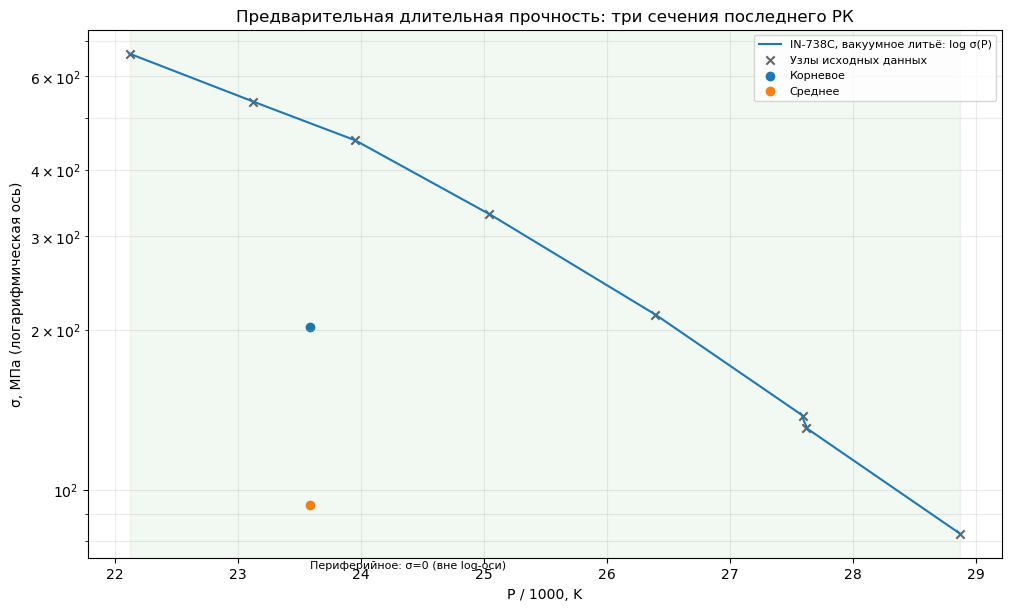

Последний РК: минимальный предварительный запас 2.421; требуется 1.2.
Сценарий длительной прочности имеет nдл ≥ 1.2; это не подтверждение общего ресурса конструкции.


,Область,Статус
7,Коэффициенты потерь по реальным решёткам,Итерационно согласованы в приближённой модели:...
8,"Прочность, горячий зазор и ресурс",Оба РК: трапеции 5 и квадрат. F(r) 3 + изгиб; ...


In [56]:
"""Температуры в K; напряжения UKR в Pa, кривая и отчёт Ларсона–Миллера в MPa."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _lm_temperatures(sections, profiles5, radial, stage, cfg, supplied, rotor):
    radii = np.array([s['r'] for s in sections], dtype=float)
    if supplied is None:
        bound=candidate_temperature_bound(radial,stage,cfg)
        T=np.full(len(sections),bound['upper_K'])
        origin=bound['origin']
    elif np.isscalar(supplied):
        T = np.full(len(sections), float(supplied))
        origin = 'Явно заданная постоянная температура металла'
    else:
        if isinstance(supplied, dict):
            rr = np.asarray(supplied['r'], dtype=float)
            tt = np.asarray(supplied['T'], dtype=float)
        else:
            tt = np.asarray(supplied, dtype=float)
            if tt.shape == (3,):
                rr = radii
            elif tt.shape == (5,):
                rr = np.array([profiles5[(f'РК{rotor}', j)]['radius'] for j in range(5)])
            else:
                raise ValueError('Tmetal_input: K, три/пять температур либо dict(r=..., T=...)')
        if rr.shape != tt.shape or rr.ndim != 1 or len(rr) not in (3, 5) or np.any(np.diff(rr) <= 0):
            raise ValueError('Профиль температуры: три/пять возрастающих радиусов и соответствующие T')
        if radii.min() < rr[0] or radii.max() > rr[-1]:
            raise ValueError('Профиль температуры не покрывает расчётные сечения; экстраполяция запрещена')
        T = np.interp(radii, rr, tt)
        origin = 'Явно заданный радиальный профиль температуры металла; линейная интерполяция'
    if not np.all(np.isfinite(T)) or np.any(T <= 0):
        raise ValueError('Температура металла должна быть конечной и положительной, K')
    return T, origin


def larson_miller_strength(UKR_STRENGTH, PROFILES5, radial, stage, cfg,
                          inputs=None, display_tables=True):
    """radial — последний dict(inlet=df,outlet=df); stage — последняя ступень.

    inputs может переопределить life_hours, C_LM, Tmetal_input, material и curve_points.
    Для другого материала обязательны его собственные curve_points (P/1000, MPa).
    """
    scenario = dict(LM_INPUTS)
    if inputs is not None:
        if inputs.get('material',scenario['material']) != scenario['material'] and 'curve_points' not in inputs:
            raise ValueError('Другому материалу нужна собственная кривая длительной прочности')
        if 'curve_points' in inputs and 'curve_source' not in inputs:
            scenario.pop('curve_source',None)
        scenario.update(inputs)
    if 'curve_points' not in scenario:
        raise ValueError('Материалу нужна собственная кривая длительной прочности')
    points = np.asarray(scenario['curve_points'], dtype=float)
    if (points.ndim != 2 or points.shape[1] != 2 or len(points) < 2 or
            not np.all(np.isfinite(points)) or np.any(points[:, 1] <= 0) or
            np.any(np.diff(points[:, 0]) <= 0) or np.any(np.diff(points[:, 1]) >= 0)):
        raise ValueError('Кривая требует возрастающий P/1000 и строго убывающие положительные σ, MPa')
    life, C = float(scenario['life_hours']), float(scenario['C_LM'])
    if not np.isfinite(life) or life <= 0 or not np.isfinite(C):
        raise ValueError('Ресурс должен быть положительным конечным числом часов; C — конечным')
    sections = UKR_STRENGTH['sections']
    T, origin = _lm_temperatures(sections, PROFILES5, radial, stage, cfg,
                               scenario['Tmetal_input'], UKR_STRENGTH['rotor'])
    def evaluate(temperatures, hours):
        rows = []
        for sec, temp in zip(sections, temperatures):
            stresses = np.asarray(sec['sigma_total'], dtype=float)
            if not np.all(np.isfinite(stresses)):
                raise ValueError('Неконечные нормальные напряжения')
            sigma = max(0., float(np.max(stresses))) / 1e6
            P = temp * (C + np.log10(hours))
            allowed = float(lm_sigma(P, points))
            inverse_P = float(lm_parameter(sigma, points)) if sigma > 0 else np.nan
            loglife = inverse_P / temp - C if np.isfinite(inverse_P) else np.nan
            rupture = 10.**loglife if np.isfinite(loglife) and loglife < 308 else np.nan
            status = ('Нет растягивающего σ>0: конечное время разрушения по этой модели не определяется'
                      if sigma == 0 else 'Оценка только длительной прочности по нормальным напряжениям')
            if not np.isfinite(allowed):
                status += '; P вне графика — σдл и запас неприменимы'
            if sigma > 0 and not np.isfinite(inverse_P):
                status += '; σ вне графика — время разрушения неприменимо'
            rows.append({'Сечение': sec['name'], 'r, м': sec['r'], 'Tмет, K': temp,
                         'P, K': P, 'P/1000': P/1000, 'σmax норм, МПа': sigma,
                         'σдл, МПа': allowed, 'n дл': allowed/sigma if sigma > 0 else np.nan,
                         't разруш, ч': rupture, 'Статус': status})
        return pd.DataFrame(rows)
    table = evaluate(T, life)
    sensitivity = []
    for delta_T, factor in ((-25., 1.), (25., 1.), (0., .5), (0., 2.)):
        if np.any(T + delta_T <= 0):
            continue
        data = evaluate(T + delta_T, life*factor)
        data.insert(0, 'Сценарий', f'ΔT={delta_T:+g} K; ресурс ×{factor:g}')
        sensitivity.append(data)
    sensitivity = pd.concat(sensitivity, ignore_index=True) if sensitivity else pd.DataFrame()
    print(f"Предварительная проверка заданного ресурса (не сертификация конструкции): {scenario['material']}; τ={life:g} ч; C_LM={C:g}.")
    print(origin)
    print('Источник:', scenario.get('curve_source', 'Пользовательская кривая: источник должен быть документирован'))
    print('n дл — НЕ общий запас: кручение, термические напряжения, вибрация/усталость, ползучая деформация и концентрации не учтены. Вывод «материал годен» не делается.')
    if display_tables:
        print(table.to_string(index=False))
        print('\nЧувствительность (без экстраполяции):\n' + sensitivity.to_string(index=False))
    fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
    pp = np.linspace(points[0, 0], points[-1, 0], 300)
    ax.semilogy(pp, lm_sigma(pp*1000, points), label=f"{scenario['material']}: log σ(P)")
    ax.scatter(points[:, 0], points[:, 1], marker='x', color='0.4', label='Узлы исходных данных')
    for _, row in table.iterrows():
        if row['σmax норм, МПа'] > 0:
            ax.scatter(row['P/1000'], row['σmax норм, МПа'], label=row['Сечение'])
        else:
            ax.annotate(row['Сечение'] + ': σ=0 (вне log-оси)',
                        (row['P/1000'], points[-1, 1]), xytext=(0, -25), textcoords='offset points', fontsize=8)
    ax.axvspan(points[0, 0], points[-1, 0], alpha=.05, color='green')
    ax.set(xlabel='P / 1000, K', ylabel='σ, МПа (логарифмическая ось)',
           title='Предварительная длительная прочность: три сечения последнего РК')
    ax.grid(True, which='both', alpha=.25)
    ax.legend(fontsize=8)
    return dict(inputs=scenario, source=scenario.get('curve_source'),
                curve_points=points.copy(), temperature_origin=origin, table=table,
                sensitivity=sensitivity, figure=fig)

LM_RESULT=larson_miller_strength(UKR_STRENGTH,PROFILES,RADIAL_RESULTS[-1],P0['stages'][-1],C,inputs=LM_INPUTS,display_tables=False)
display(LM_RESULT['table'].round(6))
display(LM_RESULT['sensitivity'].round(6))
plt.show()
lm_factors=LM_RESULT['table']['n дл'].dropna()
lm_required=float(LM_RESULT['inputs']['required_margin'])
if not np.isfinite(LM_RESULT['table']['σдл, МПа']).all():
    print('Проверка неполная: для части сечений P вне исходной кривой; сценарий не принят.')
elif len(lm_factors):
    lm_min=float(lm_factors.min())
    print(f'Последний РК: минимальный предварительный запас {lm_min:.3f}; требуется {lm_required:g}.')
    print('Сценарий длительной прочности '+(f'НЕ проходит: nдл < {lm_required:g}.' if lm_min<lm_required else f'имеет nдл ≥ {lm_required:g}; это не подтверждение общего ресурса конструкции.'))
else:
    print('Конечный минимальный запас не определён; см. посеченные статусы.')
final_status_df.loc[final_status_df['Область']=='Коэффициенты потерь по реальным решёткам','Статус']='Итерационно согласованы в приближённой модели: трение Cf(Re), кромочные и концевые; экспериментально не подтверждены'
final_status_df.loc[final_status_df['Область']=='Прочность, горячий зазор и ресурс','Статус']=f"Оба РК: трапеции 5 и квадрат. F(r) 3 + изгиб; предварительный gate {STRENGTH_REQUIREMENTS['life_hours']:g} ч {'выполнен' if COUPLED['strength']['passed'] else 'НЕ выполнен'}, min nдл={COUPLED['strength']['min_margin']:.3f}; горячий зазор и общий ресурс не подтверждены"
display(final_status_df.loc[final_status_df['Область'].isin(['Коэффициенты потерь по реальным решёткам','Прочность, горячий зазор и ресурс'])])
# Аналитическая log-линейная кривая проверяет логарифмическую шкалу и множитель 1000.
lm_test_curve=np.array([[20.,1000.],[25.,100.]])
np.testing.assert_allclose(lm_sigma(22500.,lm_test_curve),math.sqrt(1000.*100.),rtol=1e-12)
np.testing.assert_allclose(lm_parameter(math.sqrt(1000.*100.),lm_test_curve),22500.,rtol=1e-12)
assert np.isnan(lm_sigma(19000.,lm_test_curve)) and np.isnan(lm_parameter(50.,lm_test_curve))

# Нулевая нагрузка на свободном конце не делает неизвестный допуск допустимым.
zero_stress=[dict(sigma_normal_max_MPa=0.)]
known_tip=_candidate_lm_rows(1,zero_stress,dict(upper_K=1000.),STRENGTH_REQUIREMENTS,np.array([[20.,1000.],[25.,100.]]))[0]
unknown_tip=_candidate_lm_rows(1,zero_stress,dict(upper_K=1000.),STRENGTH_REQUIREMENTS,np.array([[26.,1000.],[27.,100.]]))[0]
assert known_tip['passed'] and math.isinf(known_tip['margin'])
assert not unknown_tip['passed'] and np.isnan(unknown_tip['margin'])

# Смена материала не может молча наследовать данные другого сплава.
try:
    larson_miller_strength(UKR_STRENGTH,PROFILES,RADIAL_RESULTS[-1],P0['stages'][-1],C,
                          inputs={'material':LM_INPUTS['material']+' (другой состав)'},display_tables=False)
except ValueError:
    pass
else:
    raise AssertionError('Другой материал принят без собственной кривой длительной прочности')
